In [1]:
!pip install -q torch torchvision scipy networkx scikit-learn matplotlib seaborn matplotlib-venn gseapy lifelines pandas numpy requests statsmodels tabulate

In [2]:
!pip install lifelines

In [3]:
import os, io, csv, gzip, time, warnings
import requests
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import torch
import torch.nn as nn
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, roc_curve
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0); np.random.seed(0)

/Users/soumyasriperepu/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [4]:
# Set this to whatever folder name/path inside your Drive you want everything
# saved under -- it will be created if it doesn't already exist.
DRIVE_PROJECT_FOLDER = "BRCA_GLRP_project"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = os.path.join("/content/drive/My Drive", DRIVE_PROJECT_FOLDER)
    IN_COLAB = True
except ImportError:
    # Not running in Colab (e.g. local Jupyter) -- fall back to a local folder.
    PROJECT_ROOT = "."
    IN_COLAB = False

os.makedirs(PROJECT_ROOT, exist_ok=True)
print(f"{'Google Drive mounted --' if IN_COLAB else 'Not in Colab --'} "
      f"saving everything under: {os.path.abspath(PROJECT_ROOT)}")

Not in Colab -- saving everything under: /Users/soumyasriperepu/researchAgent/version 14


In [5]:
# DATA_DIR/FIG_DIR/OUT_DIR live inside PROJECT_ROOT -- your mounted Google
# Drive folder if the "Mount Google Drive" cell above was run, or the plain
# local "." folder otherwise. Nothing else in the notebook needs to change:
# every existing plt.savefig(f"{FIG_DIR}/...") and .to_csv(f"{OUT_DIR}/...")
# call below writes into your Drive folder automatically.
PROJECT_ROOT = globals().get("PROJECT_ROOT", ".")
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
FIG_DIR = os.path.join(PROJECT_ROOT, "figures")
OUT_DIR = os.path.join(PROJECT_ROOT, "output")
for d in (DATA_DIR, FIG_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

def download(url, dest, timeout=180):
    if os.path.exists(dest):
        return dest
    r = requests.get(url, timeout=timeout)
    r.raise_for_status()
    with open(dest, "wb") as f:
        f.write(r.content)
    return dest

HUB_GENES = ["MMP9", "ITGB3", "BMP2", "CCL2", "PROM1"]  # Paper 1's 5 reported hub genes
print("Setup complete. Data/figures/output will be saved under:", os.path.abspath(PROJECT_ROOT))

Setup complete. Data/figures/output will be saved under: /Users/soumyasriperepu/researchAgent/version 14


In [6]:
def parse_series_matrix(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="latin-1") as f:
        lines = f.read().splitlines()
    meta, table_start, table_end = {}, None, None
    for i, line in enumerate(lines):
        if line.startswith("!series_matrix_table_begin"):
            table_start = i + 1
        elif line.startswith("!series_matrix_table_end"):
            table_end = i
        elif line.startswith("!"):
            parts = next(csv.reader([line], delimiter="\t"))
            meta.setdefault(parts[0].lstrip("!"), []).append(parts[1:])
    geo_acc = meta["Sample_geo_accession"][0]
    n_samples = len(geo_acc)
    records = {s: {} for s in geo_acc}
    for row in meta.get("Sample_characteristics_ch1", []):
        for j, cell in enumerate(row):
            if j >= n_samples:
                continue
            if ":" in cell:
                field, val = cell.split(":", 1)
                field, val = field.strip(), val.strip()
            else:
                field, val = "characteristic", cell.strip()
            records[geo_acc[j]].setdefault(field, val)
    clinical = pd.DataFrame.from_dict(records, orient="index").reindex(geo_acc)
    if "Sample_source_name_ch1" in meta:
        clinical.insert(0, "source_name", meta["Sample_source_name_ch1"][0])
    if "Sample_title" in meta:
        clinical.insert(0, "title", meta["Sample_title"][0])
    table_text = "\n".join(lines[table_start:table_end])
    expr = pd.read_csv(io.StringIO(table_text), sep="\t", index_col=0)
    expr.columns = [c.strip('"') for c in expr.columns]
    expr.index = [str(i).strip('"') for i in expr.index]
    return expr, clinical


In [7]:
GEO_FILES = {
    "GSE175692": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE175nnn/GSE175692/matrix/GSE175692_series_matrix.txt.gz",
    "GSE14020-GPL96":  "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14020/matrix/GSE14020-GPL96_series_matrix.txt.gz",
    "GSE14020-GPL570": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14020/matrix/GSE14020-GPL570_series_matrix.txt.gz",
    "GSE124647": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE124nnn/GSE124647/matrix/GSE124647_series_matrix.txt.gz",
    "GSE11121":  "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE11nnn/GSE11121/matrix/GSE11121_series_matrix.txt.gz",
}
geo_data = {}
for name, url in GEO_FILES.items():
    path = download(url, f"{DATA_DIR}/{name}.txt.gz")
    expr, clin = parse_series_matrix(path)
    geo_data[name] = (expr, clin)
    print(f"{name}: expression {expr.shape}, clinical {clin.shape}")

expr175, clin175 = geo_data["GSE175692"]
expr175 = expr175.astype(float)


GSE175692: expression (771, 184), clinical (184, 30)
GSE14020-GPL96: expression (22283, 36), clinical (36, 3)


GSE14020-GPL570: expression (54675, 29), clinical (29, 3)


GSE124647: expression (22283, 140), clinical (140, 18)


GSE11121: expression (22283, 200), clinical (200, 9)


In [8]:
print("GSE175692 expression matrix (genes x patients), first 8 genes x 6 patients:")
display(expr175.iloc[:8, :6])

print("\\nGSE175692 clinical annotations, first 6 patients:")
display(clin175[["organ", "ose", "os (months) since dxmet", "hr", "her2"]].head(6))

GSE175692 expression matrix (genes x patients), first 8 genes x 6 patients:


,GSM5344040,GSM5344041,GSM5344042,GSM5344043,GSM5344044,GSM5344045
ABCA8,-6.931207,-4.394252,-5.883736,-5.507928,-5.036740,-6.650649
ABCF1,-2.024316,-1.876404,-2.848112,-1.823927,-2.320533,-2.209214
ACTR3B,-3.293777,-2.531755,-3.347683,-2.122550,-3.522166,-4.980798
ACVR1B,-3.332947,-2.153244,-3.161270,-2.087658,-2.756632,-3.540225
ACVR1C,-7.779203,-6.268721,-5.620701,-9.519155,-5.036740,-6.940156
ACVRL1,-4.428706,-2.809289,-4.746232,-4.519155,-4.674170,-2.779164
ADAM12,-3.414631,-4.268721,-4.505224,-4.686265,-5.259132,-0.378762
ADCY9,-1.425175,-2.496131,-3.076381,-2.045449,-2.229385,-3.110081


\nGSE175692 clinical annotations, first 6 patients:


,organ,ose,os (months) since dxmet,hr,her2
GSM5344040,Bone,0,18.61,POS,NEG
GSM5344041,Lung,1,14.14,POS,NEG
GSM5344042,Lymph node,0,14.40,POS,NEG
GSM5344043,Bone,1,28.60,POS,NEG
GSM5344044,Bone,0,91.99,POS,NEG
GSM5344045,Bone,0,65.00,POS,NEG


In [9]:
for name in ["GSE14020-GPL96", "GSE124647", "GSE11121"]:
    expr_v, clin_v = geo_data[name]
    print(f"\n{name}: expression {expr_v.shape}, clinical {clin_v.shape}")
    display(clin_v.head(3))



GSE14020-GPL96: expression (22283, 36), clinical (36, 3)


,title,source_name,characteristic
GSM352133,B22-Met (U133A): Lung metastasis,Lung,Breast cancer
GSM352134,B34-Met (U133A): Lung metastasis,Lung,Breast cancer
GSM352135,B35-Met (U133A): Lung metastasis,Lung,Breast cancer



GSE124647: expression (22283, 140), clinical (140, 18)


,title,source_name,tissue,pfs months,pfs.event,oas months,os event,pr status,number of event,prior endocrine sensitivity,visceral disease,protocol treatment,site biopsied,stage iv at initial diagnosis,protocol number,esr1 maf,esr1 mutation,set er_pr rnaseq
GSM3538497,metastasis_1,"breast cancer, metastatic sample, hormone rece...","Breast cancer, metastatic sample",0.66,1,6.05,1,0,2,0,1,H,Soft Tissue,0,ER 72,NA,NA,NA
GSM3538498,metastasis_2,"breast cancer, metastatic sample, hormone rece...","Breast cancer, metastatic sample",5.49,1,19.78,1,1,0,NA,1,H,Lymph node,1,ER 75,0,WT,0.91
GSM3538499,metastasis_3,"breast cancer, metastatic sample, hormone rece...","Breast cancer, metastatic sample",1.35,1,19.68,1,0,1,0,1,C,Liver,0,ER 82,16.54,c.1613A>AG,1.573



GSE11121: expression (22283, 200), clinical (200, 9)


,title,source_name,storage,node,grade,size_in_cm,t.dmfs,e.dmfs,clinic
GSM282373,BC6001_r: Mainz_N0_untreated_frozen _001,primary breast cancer tissue,fresh frozen,0,2,1.8,92,1,Mainz
GSM282374,BC6002_r: Mainz_N0_untreated_frozen _002,primary breast cancer tissue,fresh frozen,0,3,2.5,71,0,Mainz
GSM282375,BC6003_r: Mainz_N0_untreated_frozen _003,primary breast cancer tissue,fresh frozen,0,3,1.5,58,1,Mainz


In [10]:
STRING_LINKS_URL = "https://stringdb-downloads.org/download/protein.links.v12.0/9606.protein.links.v12.0.txt.gz"
STRING_INFO_URL = "https://stringdb-downloads.org/download/protein.info.v12.0/9606.protein.info.v12.0.txt.gz"
links_path = download(STRING_LINKS_URL, f"{DATA_DIR}/string_links.txt.gz")
info_path = download(STRING_INFO_URL, f"{DATA_DIR}/string_info.txt.gz")

info = pd.read_csv(info_path, sep="\t", compression="gzip")
ensp2sym = dict(zip(info["#string_protein_id"], info["preferred_name"]))
links = pd.read_csv(links_path, sep=" ", compression="gzip")
links_hc = links[links["combined_score"] >= 400].copy()
links_hc["sym1"] = links_hc["protein1"].map(ensp2sym)
links_hc["sym2"] = links_hc["protein2"].map(ensp2sym)
links_hc = links_hc.dropna(subset=["sym1", "sym2"])

array_genes = set(expr175.index)
edges_restricted = links_hc[links_hc["sym1"].isin(array_genes) & links_hc["sym2"].isin(array_genes)]
G_full = nx.from_pandas_edgelist(edges_restricted, "sym1", "sym2")
G_full.add_nodes_from(array_genes)
main_cc = max(nx.connected_components(G_full), key=len)
G_main = G_full.subgraph(main_cc).copy()
gene_list = sorted(G_main.nodes())
A = nx.to_scipy_sparse_array(G_main, nodelist=gene_list, format="csr")

print(f"STRING edges at medium confidence (>=400): {len(links_hc)}")
print(f"PPI graph restricted to the 771-gene panel: {G_full.number_of_nodes()} nodes total")
print(f"Main connected component (used throughout this notebook): {G_main.number_of_nodes()} nodes, {G_main.number_of_edges()} edges")
print(f"Paper 1's 5 hub genes present in this graph: {[g for g in HUB_GENES if g in gene_list]}")

pd.DataFrame({"gene": gene_list}).to_csv(f"{DATA_DIR}/gene_list.txt", index=False, header=False)
sp.save_npz(f"{DATA_DIR}/ppi_adjacency.npz", A)

STRING edges at medium confidence (>=400): 1858944
PPI graph restricted to the 771-gene panel: 771 nodes total
Main connected component (used throughout this notebook): 737 nodes, 19902 edges
Paper 1's 5 hub genes present in this graph: ['MMP9', 'ITGB3', 'BMP2', 'CCL2', 'PROM1']


In [11]:
bone_mask = clin175["organ"] == "Bone"
bone_samples, other_samples = clin175.index[bone_mask], clin175.index[~bone_mask]
print(f"Bone metastasis: {bone_mask.sum()} patients | Other-organ metastasis: {(~bone_mask).sum()} patients")

deg_rows = []
for gene in expr175.index:
    a = pd.to_numeric(expr175.loc[gene, bone_samples], errors="coerce").dropna()
    b = pd.to_numeric(expr175.loc[gene, other_samples], errors="coerce").dropna()
    logfc = a.mean() - b.mean()
    _, p = stats.ttest_ind(a, b, equal_var=False, nan_policy="omit")
    deg_rows.append((gene, logfc, p))

deg = pd.DataFrame(deg_rows, columns=["gene", "logFC", "pvalue"]).dropna(subset=["pvalue"])
deg["FDR"] = multipletests(deg["pvalue"], method="fdr_bh")[1]

# Primary inferential criterion: BH-FDR < 0.05 plus the pre-specified effect-size threshold.
DEG_FDR_CUTOFF = 0.05
DEG_LOGFC_CUTOFF = 1.0
deg_sig = deg[(deg["FDR"] < DEG_FDR_CUTOFF) & (deg["logFC"].abs() > DEG_LOGFC_CUTOFF)].copy()
print(
    f"Significant DEGs (FDR<{DEG_FDR_CUTOFF}, |logFC|>{DEG_LOGFC_CUTOFF}): "
    f"{len(deg_sig)} (up: {(deg_sig.logFC>0).sum()}, down: {(deg_sig.logFC<0).sum()})"
)

top_up = deg_sig.sort_values("logFC", ascending=False).head(10)
top_down = deg_sig.sort_values("logFC").head(10)
top20 = pd.concat([top_up, top_down])
deg_sig.to_csv(f"{OUT_DIR}/DEGs_GSE175692.csv", index=False)

print("\nTop up-regulated and down-regulated FDR-significant DEGs:")
display(
    pd.concat([top_up.assign(direction="UP"), top_down.assign(direction="DOWN")])
      [["gene", "logFC", "pvalue", "FDR", "direction"]]
      .reset_index(drop=True)
)


Bone metastasis: 33 patients | Other-organ metastasis: 151 patients


Significant DEGs (FDR<0.05, |logFC|>1.0): 68 (up: 55, down: 13)

Top up-regulated and down-regulated FDR-significant DEGs:


,gene,logFC,pvalue,FDR,direction
0,IBSP,5.239913,1.629313e-11,1.256200e-08,UP
1,HBB,4.830262,1.265687e-07,8.871315e-06,UP
2,CHAD,4.106619,2.098043e-09,4.043979e-07,UP
3,WIF1,4.057325,1.124965e-09,2.891161e-07,UP
4,MMP9,3.609914,3.976255e-10,1.532846e-07,UP
5,VIT,2.426797,5.005242e-08,4.266265e-06,UP
6,EYA1,2.403626,4.358442e-09,5.600597e-07,UP
7,ITGB3,2.100035,3.434211e-09,5.295553e-07,UP
8,CEACAM6,1.952421,1.481136e-03,1.392629e-02,UP
9,CEACAM5,1.909538,1.208860e-03,1.226357e-02,UP


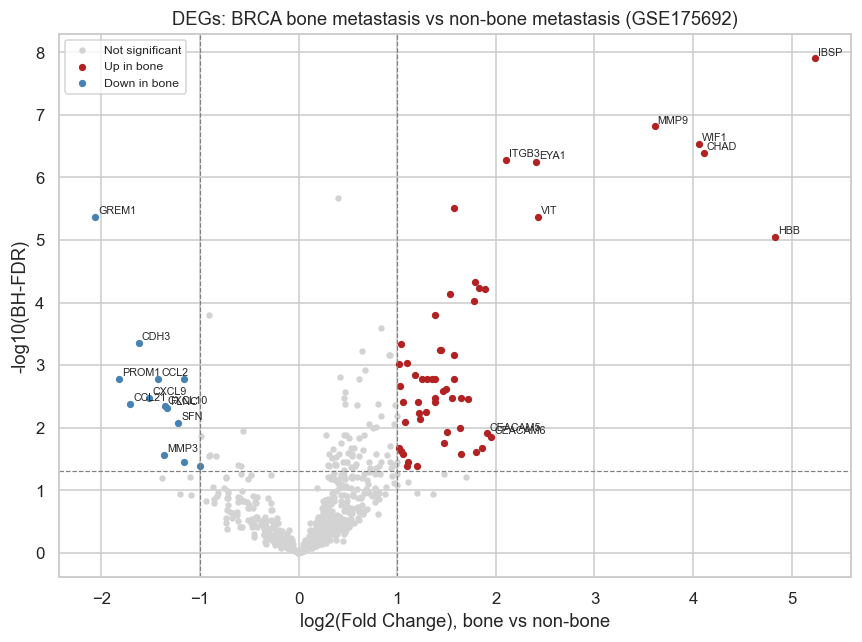

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
deg["neglogFDR"] = -np.log10(deg["FDR"].clip(lower=np.finfo(float).tiny))
not_sig = deg[~deg["gene"].isin(deg_sig["gene"])]
ax.scatter(not_sig["logFC"], not_sig["neglogFDR"], s=10, color="lightgrey", label="Not significant")
ax.scatter(
    deg_sig.loc[deg_sig.logFC > 0, "logFC"],
    -np.log10(deg_sig.loc[deg_sig.logFC > 0, "FDR"].clip(lower=np.finfo(float).tiny)),
    s=14, color="firebrick", label="Up in bone"
)
ax.scatter(
    deg_sig.loc[deg_sig.logFC < 0, "logFC"],
    -np.log10(deg_sig.loc[deg_sig.logFC < 0, "FDR"].clip(lower=np.finfo(float).tiny)),
    s=14, color="steelblue", label="Down in bone"
)
for _, row in top20.iterrows():
    ax.annotate(
        row["gene"],
        (row["logFC"], -np.log10(max(row["FDR"], np.finfo(float).tiny))),
        fontsize=7, xytext=(2, 2), textcoords="offset points"
    )
ax.axvline(DEG_LOGFC_CUTOFF, ls="--", color="grey", lw=0.8)
ax.axvline(-DEG_LOGFC_CUTOFF, ls="--", color="grey", lw=0.8)
ax.axhline(-np.log10(DEG_FDR_CUTOFF), ls="--", color="grey", lw=0.8)
ax.set_xlabel("log2(Fold Change), bone vs non-bone")
ax.set_ylabel("-log10(BH-FDR)")
ax.set_title("DEGs: BRCA bone metastasis vs non-bone metastasis (GSE175692)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_volcano_plot.png"); plt.show()


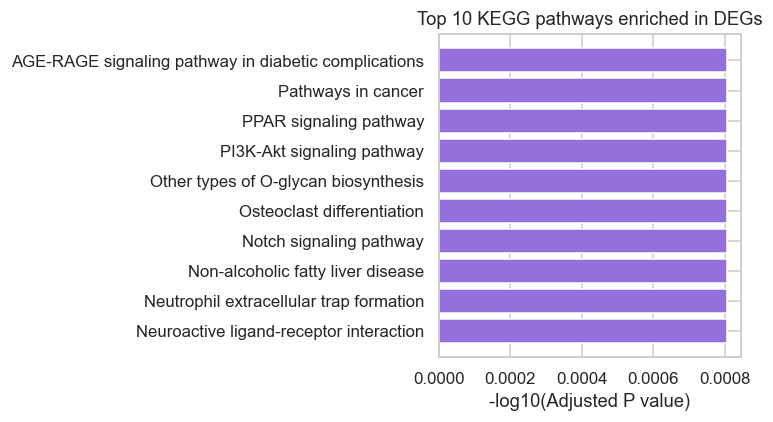

,Term,Overlap,Adjusted P-value,Genes
0,AGE-RAGE signaling pathway in diabetic complic...,1/43,0.998147,CCL2
1,Pathways in cancer,8/173,0.998147,FGF7;FZD8;FGFR3;WNT2;ESR1;WNT5B;BMP2;MMP9
2,PPAR signaling pathway,2/4,0.998147,LPL;CD36
3,PI3K-Akt signaling pathway,7/111,0.998147,CHAD;FGF7;FGFR3;SPP1;IBSP;ITGB3;COMP
4,Other types of O-glycan biosynthesis,1/2,0.998147,LFNG
5,Osteoclast differentiation,1/25,0.998147,ITGB3
6,Notch signaling pathway,1/23,0.998147,LFNG
7,Non-alcoholic fatty liver disease,1/23,0.998147,LEPR
8,Neutrophil extracellular trap formation,1/23,0.998147,ITGB3
9,Neuroactive ligand-receptor interaction,1/17,0.998147,LEPR


In [13]:
import gseapy as gp

_ENRICHR_LIBRARY_CACHE = {}

def enrichr_retry(gene_list_, gene_sets, retries=6, base_delay=8, background=None):
    """
    background: optional list of genes to use as the enrichment universe instead of
    Enrichr's default genome-wide background. Use this whenever gene_list_ is drawn
    from a restricted panel (e.g. the 737-gene STRING panel) rather than an unbiased
    genome-wide selection -- the panel itself is not a random genome sample (it's a
    curated, cancer-relevant NanoString panel), so the default background overstates
    how "enriched" any pathway looks. Enrichr's REMOTE API (gp.enrichr) doesn't support
    a custom background at all, so this switches to gseapy's LOCAL hypergeometric
    enrichment (gp.enrich) against a locally-downloaded copy of the same named
    library when background is given; falls back to the original remote behavior
    (with a printed warning, not a silent switch) if the local library download fails.
    """
    for attempt in range(retries):
        try:
            if background is not None:
                try:
                    merged_lib = {}
                    for gs in gene_sets:
                        if gs not in _ENRICHR_LIBRARY_CACHE:
                            _ENRICHR_LIBRARY_CACHE[gs] = gp.get_library(name=gs, organism="Human")
                        merged_lib.update(_ENRICHR_LIBRARY_CACHE[gs])
                    return gp.enrich(gene_list=gene_list_, gene_sets=merged_lib,
                                      background=background, outdir=None).results
                except Exception as bg_e:
                    print(f"Background-restricted enrichment failed ({bg_e}); falling back to "
                          "Enrichr's default genome-wide background for this call -- treat this "
                          "result as exploratory, not background-corrected.")
            return gp.enrichr(gene_list=gene_list_, gene_sets=gene_sets, outdir=None).results
        except Exception as e:
            if attempt == retries - 1:
                raise
            print(f"Enrichr request failed ({e}); retrying in {base_delay*(attempt+1)}s...")
            time.sleep(base_delay * (attempt + 1))

deg_gene_list = deg_sig["gene"].tolist()
kegg_res = enrichr_retry(deg_gene_list, ["KEGG_2021_Human"], background=gene_list).sort_values("Adjusted P-value").head(10)

fig, ax = plt.subplots(figsize=(7, 4))
plot_df = kegg_res.iloc[::-1]
ax.barh(plot_df["Term"], -np.log10(plot_df["Adjusted P-value"]), color="mediumpurple")
ax.set_xlabel("-log10(Adjusted P value)"); ax.set_title("Top 10 KEGG pathways enriched in DEGs")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_kegg_enrichment.png"); plt.show()
display(kegg_res[["Term", "Overlap", "Adjusted P-value", "Genes"]].reset_index(drop=True))

DEG-restricted PPI network: 68 nodes, 152 edges
\nTop 10 hub genes by degree centrality:


,gene,degree
0,MMP9,19
1,ESR1,19
2,SPP1,16
3,CCL2,15
4,BMP2,15
5,MMP3,12
6,CD36,11
7,FGF7,11
8,PROM1,10
9,COMP,10


\nData-driven hub-gene shortlist (top-10-by-degree ∩ top-20-by-|logFC|): ['CCL2', 'MMP3', 'MMP9', 'PROM1']
Paper 1's reported 5 hub genes: ['MMP9', 'ITGB3', 'BMP2', 'CCL2', 'PROM1']


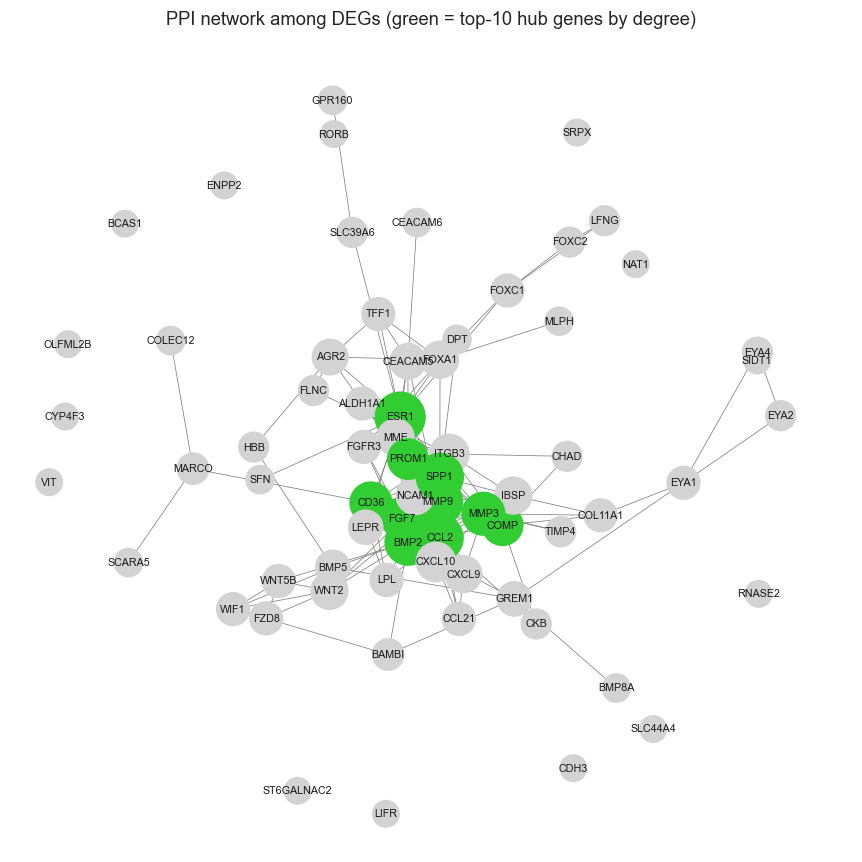

In [14]:
string_url = "https://string-db.org/api/tsv/network"
params = {"identifiers": "%0d".join(deg_gene_list), "species": 9606, "required_score": 400}
r = requests.get(string_url, params=params, timeout=60)
ppi_edges = pd.read_csv(io.StringIO(r.text), sep="\t")

G_deg = nx.Graph()
G_deg.add_nodes_from(deg_gene_list)
for _, row in ppi_edges.iterrows():
    G_deg.add_edge(row["preferredName_A"], row["preferredName_B"])
print(f"DEG-restricted PPI network: {G_deg.number_of_nodes()} nodes, {G_deg.number_of_edges()} edges")

degree_rank = pd.Series(dict(G_deg.degree())).sort_values(ascending=False)
top10_hub = degree_rank.head(10)
print("\\nTop 10 hub genes by degree centrality:")
display(top10_hub.rename("degree").reset_index().rename(columns={"index": "gene"}))

top20_deg_genes = set(top20["gene"])
data_driven_hub = set(top10_hub.index) & top20_deg_genes
print(f"\\nData-driven hub-gene shortlist (top-10-by-degree ∩ top-20-by-|logFC|): {sorted(data_driven_hub)}")
print(f"Paper 1's reported 5 hub genes: {HUB_GENES}")

fig, ax = plt.subplots(figsize=(8, 8))
pos = nx.spring_layout(G_deg, seed=42, k=0.4)
node_colors = ["limegreen" if n in top10_hub.index else "lightgrey" for n in G_deg.nodes()]
node_sizes = [300 + 40 * G_deg.degree(n) for n in G_deg.nodes()]
nx.draw_networkx(G_deg, pos, ax=ax, node_color=node_colors, node_size=node_sizes, font_size=7, edge_color="grey", width=0.5, with_labels=True)
ax.set_title("PPI network among DEGs (green = top-10 hub genes by degree)")
ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_ppi_network.png"); plt.show()

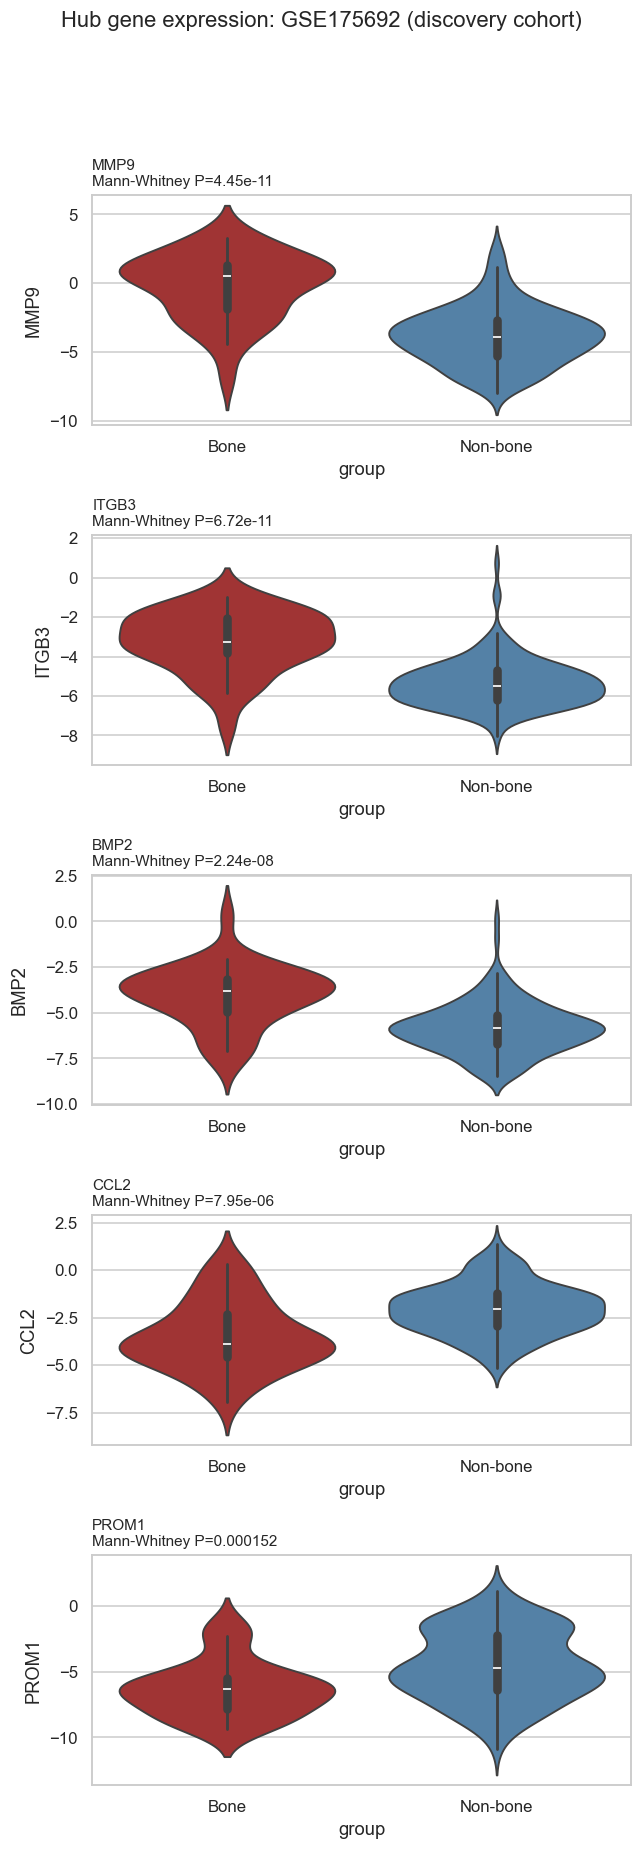

,gene,mean_Bone,mean_Non-bone,pvalue
0,MMP9,-0.221390,-3.831304,4.454949e-11
1,ITGB3,-3.253035,-5.353070,6.720600e-11
2,BMP2,-4.066635,-5.859650,2.240720e-08
3,CCL2,-3.481032,-2.061264,7.946145e-06
4,PROM1,-6.336088,-4.517967,1.516590e-04


In [15]:
def violin_compare(df, genes, group_col, group_labels, title, fname):
    fig, axes = plt.subplots(len(genes), 1, figsize=(6, 3.2 * len(genes)))
    stats_rows = []
    for ax, gene in zip(axes, genes):
        sub = df[[gene, group_col]].dropna()
        sns.violinplot(data=sub, x=group_col, y=gene, ax=ax, order=group_labels, palette=["firebrick", "steelblue"], inner="box")
        a = sub.loc[sub[group_col] == group_labels[0], gene]
        b = sub.loc[sub[group_col] == group_labels[1], gene]
        stat, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        ax.set_title(f"{gene}\nMann-Whitney P={p:.3g}", fontsize=10, loc="left")
        stats_rows.append((gene, a.mean(), b.mean(), p))
    fig.suptitle(title, y=1.0 + 0.01 * len(genes))
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fname}"); plt.show()
    return pd.DataFrame(stats_rows, columns=["gene", f"mean_{group_labels[0]}", f"mean_{group_labels[1]}", "pvalue"])

df175 = expr175.loc[HUB_GENES].T.join(bone_mask.map({True: "Bone", False: "Non-bone"}).rename("group"))
val_175 = violin_compare(df175, HUB_GENES, "group", ["Bone", "Non-bone"], "Hub gene expression: GSE175692 (discovery cohort)", "04_hubgenes_GSE175692.png")
display(val_175)

GSE14020 combined cohort: {'Non-bone': 47, 'Bone': 18}


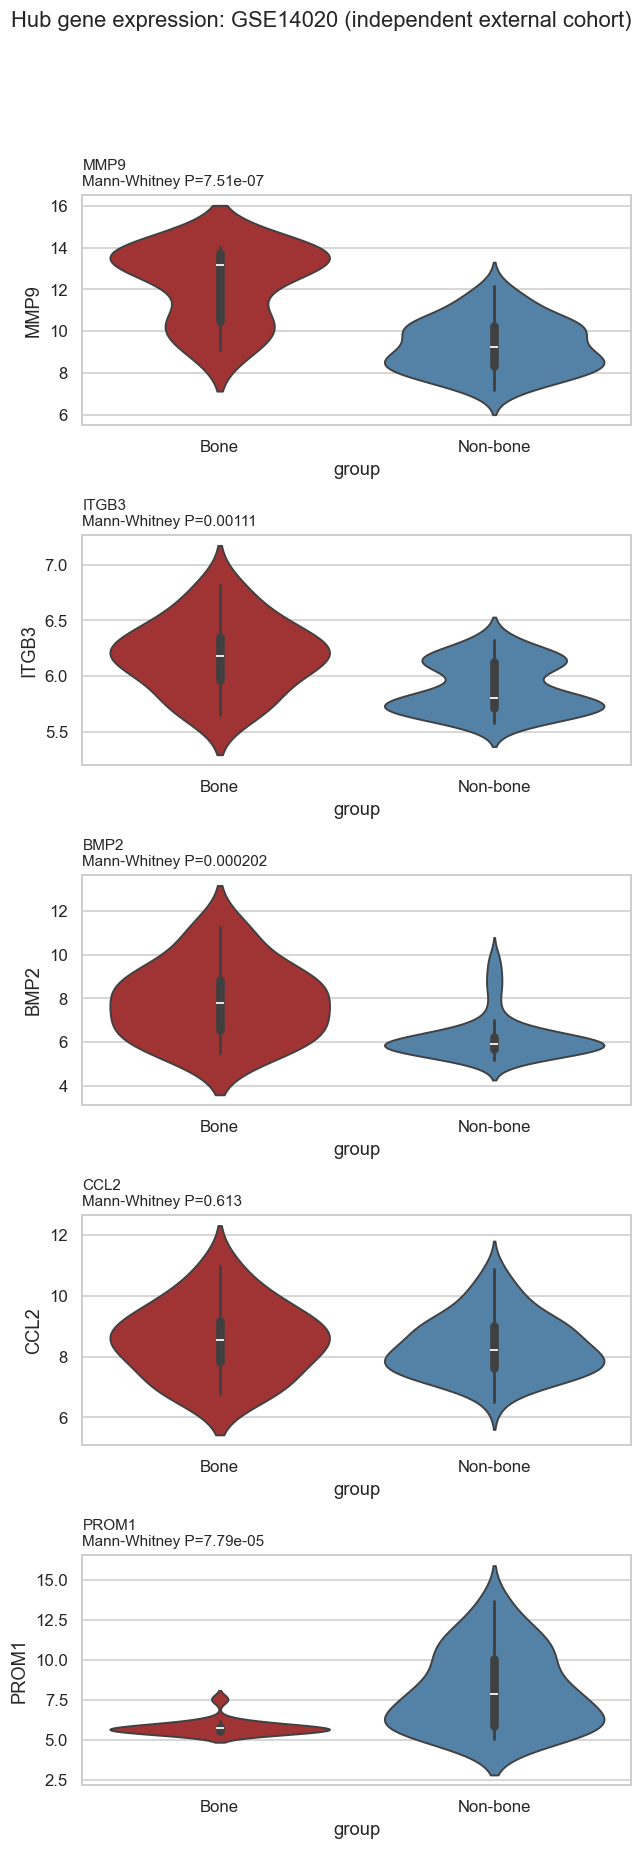

,gene,mean_Bone,mean_Non-bone,pvalue
0,MMP9,12.295444,9.313949,7.507843e-07
1,ITGB3,6.190133,5.899766,1.106892e-03
2,BMP2,7.875267,6.229424,2.021569e-04
3,CCL2,8.537530,8.366409,6.130185e-01
4,PROM1,5.793743,8.117060,7.786908e-05


In [16]:
GPL_ANNOT_URLS = {
    "GPL96": "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL96/annot/GPL96.annot.gz",
    "GPL570": "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz",
}
def load_probe_map(gpl, genes):
    path = download(GPL_ANNOT_URLS[gpl], f"{DATA_DIR}/{gpl}.annot.gz")
    with gzip.open(path, "rt", encoding="latin-1") as f:
        lines = f.read().splitlines()
    start = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_begin")) + 1
    end = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_end"))
    df = pd.read_csv(io.StringIO("\n".join(lines[start:end])), sep="\t", low_memory=False)
    return {g: df.loc[df["Gene symbol"] == g, "ID"].tolist() for g in genes}

def probes_to_gene_level(expr, probe_map):
    out = {}
    for gene, probes in probe_map.items():
        probes = [p for p in probes if p in expr.index]
        if probes:
            out[gene] = expr.loc[probes].astype(float).mean(axis=0)
    return pd.DataFrame(out)

gpl96_map = load_probe_map("GPL96", HUB_GENES)
gpl570_map = load_probe_map("GPL570", HUB_GENES)

expr96, clin96 = geo_data["GSE14020-GPL96"]
expr570, clin570 = geo_data["GSE14020-GPL570"]
g96 = probes_to_gene_level(expr96, gpl96_map)
g570 = probes_to_gene_level(expr570, gpl570_map)
gse14020_expr = pd.concat([g96, g570], axis=0)
gse14020_clin = pd.concat([clin96[["source_name"]], clin570[["source_name"]]], axis=0)
gse14020_clin["group"] = np.where(gse14020_clin["source_name"] == "Bone", "Bone", "Non-bone")
print("GSE14020 combined cohort:", gse14020_clin["group"].value_counts().to_dict())

df14020 = gse14020_expr.join(gse14020_clin["group"])
val_14020 = violin_compare(df14020, HUB_GENES, "group", ["Bone", "Non-bone"], "Hub gene expression: GSE14020 (independent external cohort)", "05_hubgenes_GSE14020.png")
display(val_14020)

In [17]:
# ============================================================
# 6a. GSE14020 platform / normalization audit  [R7]
# ============================================================
import statsmodels.formula.api as smf
from scipy.stats import fisher_exact, mannwhitneyu

# 1) Value scale per platform (as deposited in the series matrix)
for plat_name, e in [("GPL96", expr96), ("GPL570", expr570)]:
    v = e.astype(float).values
    looks_log = np.nanmax(v) < 30
    print(f"{plat_name}: min={np.nanmin(v):.2f}, median={np.nanmedian(v):.2f}, max={np.nanmax(v):.2f} "
          f"-> {'consistent with log2 scale' if looks_log else 'NOT log2 scale (raw intensity)'}")

# 2) Probes used per hub gene, per platform
probe_rows = []
for gene in HUB_GENES:
    probe_rows.append({"gene": gene,
                       "GPL96_probes": ", ".join([p for p in gpl96_map.get(gene, []) if p in expr96.index]),
                       "GPL570_probes": ", ".join([p for p in gpl570_map.get(gene, []) if p in expr570.index])})
probe_table = pd.DataFrame(probe_rows)
probe_table.to_csv(f"{OUT_DIR}/GSE14020_probe_to_gene_mapping.csv", index=False)
print("\nProbe-to-gene mapping used (exact 'Gene symbol' match, probes averaged per sample):")
display(probe_table)

# 3) Platform x site composition (the confounding question)
platform_series = pd.Series(["GPL96"] * len(g96) + ["GPL570"] * len(g570),
                            index=list(g96.index) + list(g570.index), name="platform")
audit14020 = df14020.join(platform_series)
comp = pd.crosstab(audit14020["platform"], audit14020["group"])
print("\nPlatform x site composition:")
display(comp)
if comp.shape == (2, 2):
    _, p_comp = fisher_exact(comp.values)
    print(f"Fisher exact test, platform vs site: P={p_comp:.3g} "
          f"({'site composition differs by platform -- platform is a plausible confounder' if p_comp < 0.05 else 'no significant difference in site composition by platform'})")
print("\nNon-bone site labels by platform (source_name):")
display(pd.crosstab(gse14020_clin["source_name"], platform_series.reindex(gse14020_clin.index)))

# 4) Site comparison three ways
rows = []
for gene in HUB_GENES:
    if gene not in audit14020.columns:
        continue
    d = audit14020[[gene, "group", "platform"]].dropna()
    # (a) within each platform separately
    for plat_name in ["GPL96", "GPL570"]:
        dp = d[d["platform"] == plat_name]
        b, nb = dp.loc[dp.group == "Bone", gene], dp.loc[dp.group == "Non-bone", gene]
        p_within = mannwhitneyu(b, nb).pvalue if len(b) >= 3 and len(nb) >= 3 else np.nan
        rows.append({"gene": gene, "analysis": f"within {plat_name}", "n_bone": len(b), "n_nonbone": len(nb),
                     "effect": b.mean() - nb.mean() if len(b) and len(nb) else np.nan, "pvalue": p_within})
    # (b) per-platform z-score, then pooled Mann-Whitney
    dz = d.copy()
    dz["z"] = dz.groupby("platform")[gene].transform(lambda s: (s - s.mean()) / s.std(ddof=1))
    b, nb = dz.loc[dz.group == "Bone", "z"], dz.loc[dz.group == "Non-bone", "z"]
    rows.append({"gene": gene, "analysis": "pooled, per-platform z-scored", "n_bone": len(b), "n_nonbone": len(nb),
                 "effect": b.mean() - nb.mean(), "pvalue": mannwhitneyu(b, nb).pvalue})
    # (c) linear model with platform as covariate
    dl = d.rename(columns={gene: "expr"})
    dl["bone"] = (dl["group"] == "Bone").astype(int)
    fit = smf.ols("expr ~ bone + C(platform)", data=dl).fit()
    rows.append({"gene": gene, "analysis": "OLS expr ~ site + platform", "n_bone": int(dl.bone.sum()),
                 "n_nonbone": int((1 - dl.bone).sum()), "effect": fit.params["bone"], "pvalue": fit.pvalues["bone"]})

gse14020_platform_audit = pd.DataFrame(rows)
gse14020_platform_audit.to_csv(f"{OUT_DIR}/GSE14020_platform_adjusted_site_comparison.csv", index=False)
print("\nSite comparison within platform, after per-platform z-scoring, and platform-adjusted (compare with the pooled table above):")
display(gse14020_platform_audit)
print("\nReport the pooled result only together with this table. A gene whose bone/non-bone difference "
      "disappears within platform or after platform adjustment should not be described as replicated in GSE14020.")


GPL96: min=3.93, median=7.14, max=14.79 -> consistent with log2 scale
GPL570: min=3.39, median=6.95, max=15.12 -> consistent with log2 scale

Probe-to-gene mapping used (exact 'Gene symbol' match, probes averaged per sample):


,gene,GPL96_probes,GPL570_probes
0,MMP9,203936_s_at,203936_s_at
1,ITGB3,"204625_s_at, 204626_s_at, 204627_s_at, 204628_...","204625_s_at, 204626_s_at, 204627_s_at, 204628_..."
2,BMP2,"205289_at, 205290_s_at","205289_at, 205290_s_at"
3,CCL2,216598_s_at,216598_s_at
4,PROM1,204304_s_at,204304_s_at



Platform x site composition:


group,Bone,Non-bone
platform,,
GPL570,10,19
GPL96,8,28


Fisher exact test, platform vs site: P=0.403 (no significant difference in site composition by platform)

Non-bone site labels by platform (source_name):


platform,GPL570,GPL96
source_name,,
Bone,10,8
Brain,15,7
Liver,0,5
Lung,4,16



Site comparison within platform, after per-platform z-scoring, and platform-adjusted (compare with the pooled table above):


,gene,analysis,n_bone,n_nonbone,effect,pvalue
0,MMP9,within GPL96,8,28,2.634532,3.268304e-04
1,MMP9,within GPL570,10,19,3.134477,3.159886e-04
2,MMP9,"pooled, per-platform z-scored",18,47,1.485650,7.507843e-07
3,MMP9,OLS expr ~ site + platform,18,47,2.890953,4.165677e-10
4,ITGB3,within GPL96,8,28,0.189016,2.137788e-02
5,ITGB3,within GPL570,10,19,0.257499,5.318553e-04
6,ITGB3,"pooled, per-platform z-scored",18,47,1.354357,4.449529e-05
7,ITGB3,OLS expr ~ site + platform,18,47,0.224141,3.131905e-08
8,BMP2,within GPL96,8,28,0.806626,4.863006e-02
9,BMP2,within GPL570,10,19,2.174696,1.428258e-03



Report the pooled result only together with this table. A gene whose bone/non-bone difference disappears within platform or after platform adjustment should not be described as replicated in GSE14020.


In [18]:
surv175 = clin175[["ose", "os (months) since dxmet"]].copy()
surv175.columns = ["event", "time_months"]
surv175["event"] = pd.to_numeric(surv175["event"], errors="coerce")
surv175["time_months"] = pd.to_numeric(surv175["time_months"], errors="coerce")
surv_df = surv175.join(expr175.loc[HUB_GENES].T).dropna()
print(f"Samples with complete survival + expression data: {len(surv_df)}")

cox_rows = []
for gene in HUB_GENES:
    cph = CoxPHFitter()
    cph.fit(surv_df[["time_months", "event", gene]], duration_col="time_months", event_col="event")
    s = cph.summary.loc[gene]
    cox_rows.append((gene, s["exp(coef)"], s["exp(coef) lower 95%"], s["exp(coef) upper 95%"], s["p"], cph.params_[gene]))
cox_uni = pd.DataFrame(cox_rows, columns=["gene", "HR", "CI_lower", "CI_upper", "pvalue", "coef"])

# Multiple-testing correction across the 5 candidate genes (Benjamini-Hochberg FDR) --
# five univariate tests on the same cohort were previously reported with no correction.
try:
    from statsmodels.stats.multitest import multipletests
    cox_uni["FDR_BH"] = multipletests(cox_uni["pvalue"], method="fdr_bh")[1]
except ImportError:
    pv = cox_uni["pvalue"].to_numpy()
    n = len(pv)
    order = np.argsort(pv)
    ranked = pv[order] * n / (np.arange(n) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.clip(ranked, 0, 1)
    cox_uni["FDR_BH"] = out

cox_uni.to_csv(f"{OUT_DIR}/univariate_cox_GSE175692.csv", index=False)
print("Univariate Cox regression, hub genes vs overall survival (raw P and BH-FDR across the 5 tests):")
display(cox_uni[["gene", "HR", "CI_lower", "CI_upper", "pvalue", "FDR_BH"]])
sig_genes_raw = cox_uni.loc[cox_uni.pvalue < 0.05, "gene"].tolist()
sig_genes_fdr = cox_uni.loc[cox_uni.FDR_BH < 0.05, "gene"].tolist()
print(f"\nNominally significant, raw P<0.05 (previously reported as \"significant\"): {sig_genes_raw}")
print(f"\nSignificant after BH-FDR correction across the 5 genes (FDR<0.05): {sig_genes_fdr}")

Samples with complete survival + expression data: 180
Univariate Cox regression, hub genes vs overall survival (raw P and BH-FDR across the 5 tests):


,gene,HR,CI_lower,CI_upper,pvalue,FDR_BH
0,MMP9,1.043130,0.967912,1.124194,0.268798,0.335997
1,ITGB3,0.957945,0.826559,1.110214,0.568104,0.568104
2,BMP2,0.922709,0.804105,1.058806,0.251819,0.335997
3,CCL2,1.200062,1.050700,1.370656,0.007161,0.017904
4,PROM1,1.115042,1.033203,1.203363,0.005113,0.017904



Nominally significant, raw P<0.05 (previously reported as "significant"): ['CCL2', 'PROM1']

Significant after BH-FDR correction across the 5 genes (FDR<0.05): ['CCL2', 'PROM1']


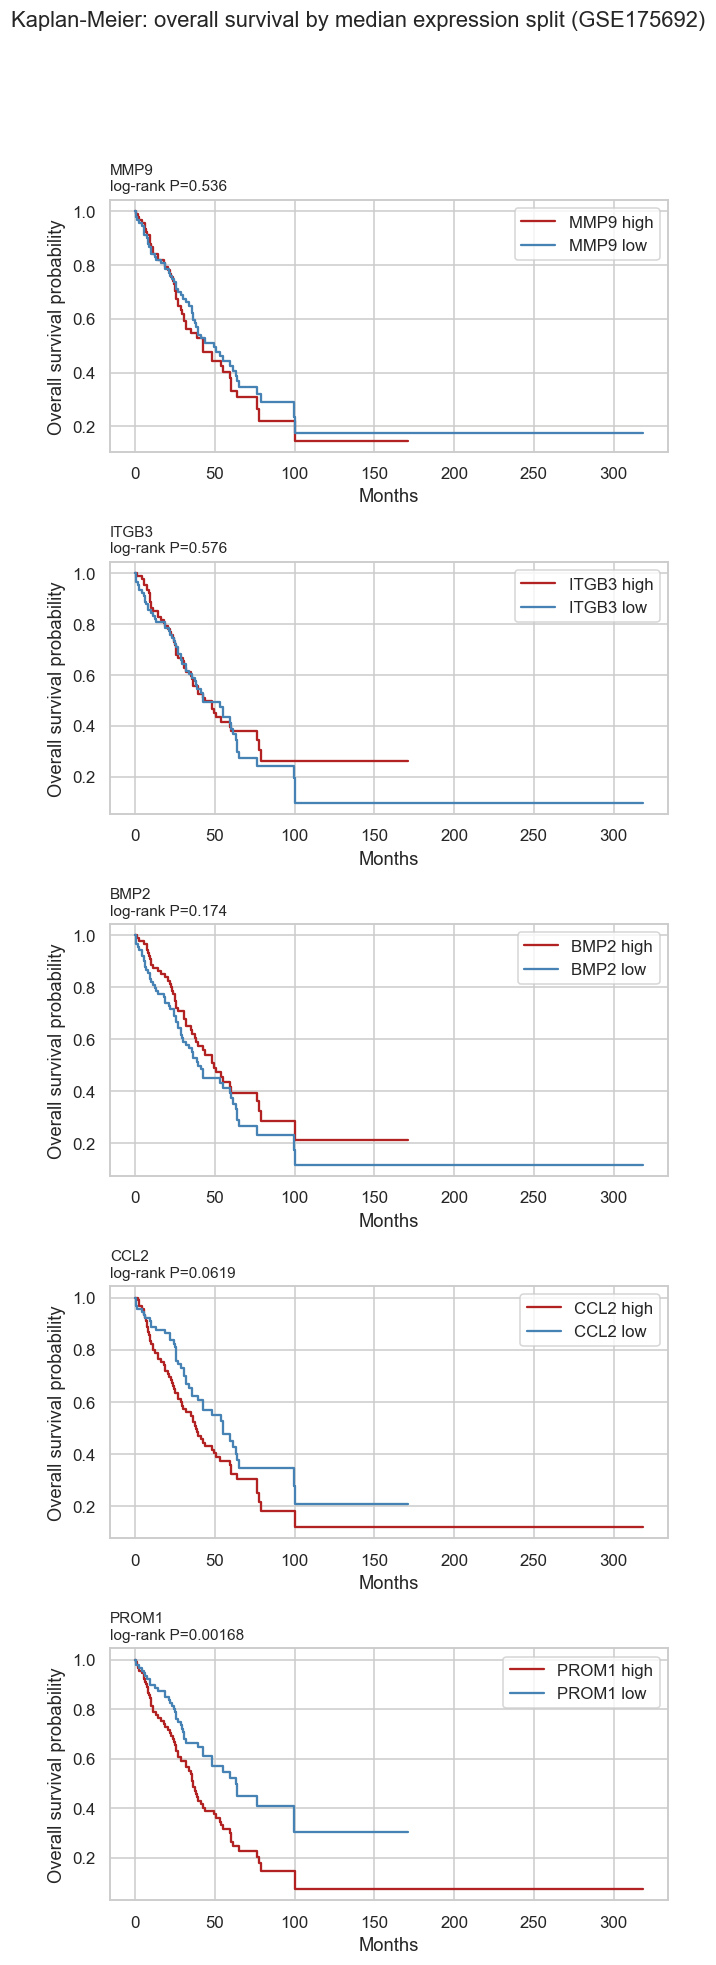

,gene,logrank_pvalue
0,MMP9,0.536061
1,ITGB3,0.576281
2,BMP2,0.174459
3,CCL2,0.061891
4,PROM1,0.001679


In [19]:
fig, axes = plt.subplots(len(HUB_GENES), 1, figsize=(6, 3.4 * len(HUB_GENES)))
km_rows = []
for ax, gene in zip(axes, HUB_GENES):
    median = surv_df[gene].median()
    high = surv_df[surv_df[gene] > median]; low = surv_df[surv_df[gene] <= median]
    kmf = KaplanMeierFitter()
    kmf.fit(high["time_months"], high["event"], label=f"{gene} high").plot_survival_function(ax=ax, ci_show=False, color="firebrick")
    kmf.fit(low["time_months"], low["event"], label=f"{gene} low").plot_survival_function(ax=ax, ci_show=False, color="steelblue")
    res = logrank_test(high["time_months"], low["time_months"], high["event"], low["event"])
    ax.set_title(f"{gene}\nlog-rank P={res.p_value:.3g}", fontsize=10, loc="left"); ax.set_xlabel("Months")
    ax.set_ylabel("Overall survival probability")
    km_rows.append((gene, res.p_value))
plt.suptitle("Kaplan-Meier: overall survival by median expression split (GSE175692)", y=1.0 + 0.01 * len(HUB_GENES))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/06_km_GSE175692.png"); plt.show()
display(pd.DataFrame(km_rows, columns=["gene", "logrank_pvalue"]))

Multivariate Cox regression (PROM1 + CCL2 together):


,coef,exp(coef),p
covariate,,,
PROM1,0.076807,1.079833,0.074150
CCL2,0.125542,1.133762,0.093252


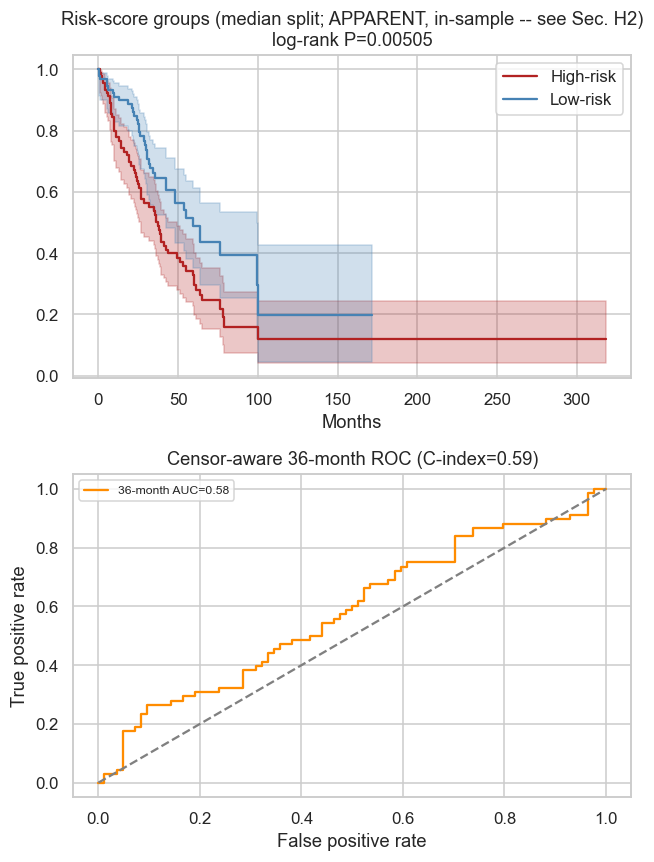

[APPARENT, in-sample; cross-validated values in Section H2] Risk score = 0.07681 x PROM1 + 0.12554 x CCL2  |  median-split log-rank P=0.005055  |  C-index=0.593  |  36-month AUC=0.580
Fixed-horizon ROC used 152 patients with known 36-month status: 68 cases, 84 controls; early-censored patients were excluded.


In [20]:
cph_multi = CoxPHFitter()
cph_multi.fit(surv_df[["time_months", "event", "PROM1", "CCL2"]], duration_col="time_months", event_col="event")
print("Multivariate Cox regression (PROM1 + CCL2 together):")
display(cph_multi.summary[["coef", "exp(coef)", "p"]])

coef_prom1, coef_ccl2 = cph_multi.params_["PROM1"], cph_multi.params_["CCL2"]
surv_df["risk_score"] = coef_prom1 * surv_df["PROM1"] + coef_ccl2 * surv_df["CCL2"]
median_rs = surv_df["risk_score"].median()
surv_df["risk_group"] = np.where(surv_df["risk_score"] > median_rs, "High-risk", "Low-risk")

def fixed_horizon_roc(df, horizon_months=36):
    """Censor-aware fixed-horizon ROC without adding a new dependency.

    Cases: observed death/event by the horizon.
    Controls: known event-free beyond the horizon (either censored after it or event after it).
    Patients censored before the horizon are excluded because their status at the horizon is unknown.
    """
    d = df[["time_months", "event", "risk_score"]].dropna().copy()
    cases = (d["event"] == 1) & (d["time_months"] <= horizon_months)
    controls = d["time_months"] > horizon_months
    keep = cases | controls
    d = d.loc[keep].copy()
    y_h = cases.loc[keep].astype(int).to_numpy()
    if len(np.unique(y_h)) < 2:
        return None
    fpr, tpr, thresholds = roc_curve(y_h, d["risk_score"].to_numpy())
    auc = roc_auc_score(y_h, d["risk_score"].to_numpy())
    return fpr, tpr, thresholds, auc, len(d), int(y_h.sum()), int((1-y_h).sum())

fig, axes = plt.subplots(2, 1, figsize=(6, 8))
kmf = KaplanMeierFitter()
high = surv_df[surv_df.risk_group == "High-risk"]
low = surv_df[surv_df.risk_group == "Low-risk"]
kmf.fit(high.time_months, high.event, label="High-risk").plot_survival_function(ax=axes[0], color="firebrick")
kmf.fit(low.time_months, low.event, label="Low-risk").plot_survival_function(ax=axes[0], color="steelblue")
res = logrank_test(high.time_months, low.time_months, high.event, low.event)
axes[0].set_title(f"Risk-score groups (median split; APPARENT, in-sample -- see Sec. H2)\nlog-rank P={res.p_value:.3g}")
axes[0].set_xlabel("Months")

HORIZON_MONTHS = 36
roc_h = fixed_horizon_roc(surv_df, HORIZON_MONTHS)
cindex_rs = concordance_index(surv_df["time_months"], -surv_df["risk_score"], surv_df["event"])
if roc_h is not None:
    fpr, tpr, _, auc_h, n_h, n_cases, n_controls = roc_h
    axes[1].plot(fpr, tpr, color="darkorange", label=f"{HORIZON_MONTHS}-month AUC={auc_h:.2f}")
    axes[1].plot([0, 1], [0, 1], "--", color="grey")
    axes[1].set_title(f"Censor-aware {HORIZON_MONTHS}-month ROC (C-index={cindex_rs:.2f})")
    axes[1].legend(fontsize=8)
else:
    auc_h = np.nan
    axes[1].text(0.5, 0.5, f"Not enough known statuses at {HORIZON_MONTHS} months for ROC", ha="center", va="center")
    axes[1].set_title(f"C-index={cindex_rs:.2f}")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/07_risk_score.png"); plt.show()

print(
    f"[APPARENT, in-sample; cross-validated values in Section H2] Risk score = {coef_prom1:.5f} x PROM1 + {coef_ccl2:.5f} x CCL2  |  "
    f"median-split log-rank P={res.p_value:.4g}  |  C-index={cindex_rs:.3f}  |  "
    f"{HORIZON_MONTHS}-month AUC={auc_h:.3f}"
)
if roc_h is not None:
    print(f"Fixed-horizon ROC used {n_h} patients with known {HORIZON_MONTHS}-month status: {n_cases} cases, {n_controls} controls; early-censored patients were excluded.")


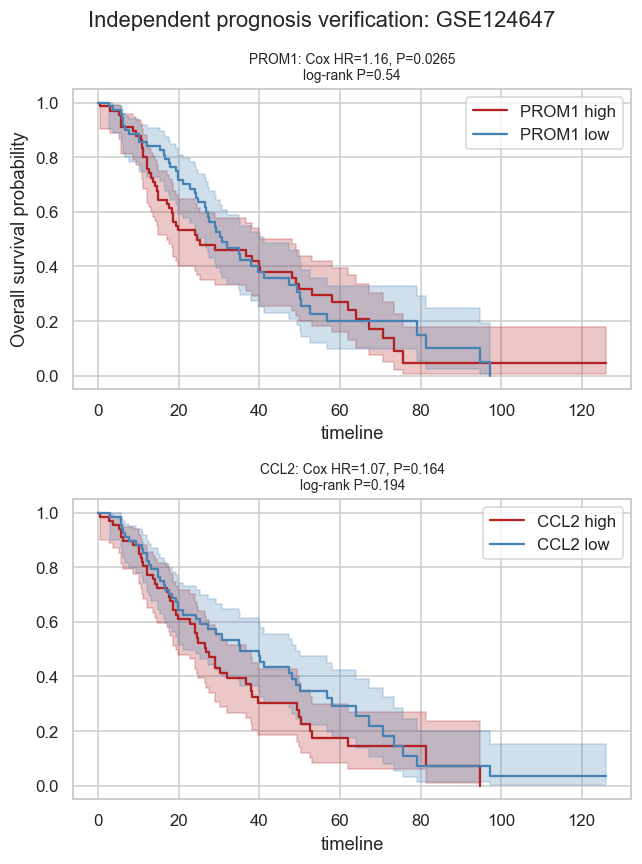

,gene,HR,cox_pvalue,logrank_pvalue
0,PROM1,1.161349,0.026541,0.539581
1,CCL2,1.073391,0.163800,0.194398


In [21]:
expr124, clin124 = geo_data["GSE124647"]
gse124_genes = probes_to_gene_level(expr124, gpl96_map)
surv124 = clin124[["os event", "oas months"]].copy()
surv124.columns = ["event", "time_months"]
surv124["event"] = pd.to_numeric(surv124["event"], errors="coerce")
surv124["time_months"] = pd.to_numeric(surv124["time_months"], errors="coerce")
df124 = surv124.join(gse124_genes[["PROM1", "CCL2"]]).dropna()

fig, axes = plt.subplots(2, 1, figsize=(6, 8))
verify_rows = []
for ax, gene in zip(axes, ["PROM1", "CCL2"]):
    cph = CoxPHFitter()
    cph.fit(df124[["time_months", "event", gene]], duration_col="time_months", event_col="event")
    s = cph.summary.loc[gene]
    median = df124[gene].median()
    high = df124[df124[gene] > median]; low = df124[df124[gene] <= median]
    kmf = KaplanMeierFitter()
    kmf.fit(high.time_months, high.event, label=f"{gene} high").plot_survival_function(ax=ax, color="firebrick")
    kmf.fit(low.time_months, low.event, label=f"{gene} low").plot_survival_function(ax=ax, color="steelblue")
    res = logrank_test(high.time_months, low.time_months, high.event, low.event)
    ax.set_title(f"{gene}: Cox HR={s['exp(coef)']:.2f}, P={s['p']:.3g}\nlog-rank P={res.p_value:.3g}", fontsize=9)
    verify_rows.append((gene, s["exp(coef)"], s["p"], res.p_value))
axes[0].set_ylabel("Overall survival probability")
# (one gene per row now, so each panel gets its own y-label automatically via sharey=False default)
plt.suptitle("Independent prognosis verification: GSE124647")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/08_verification_GSE124647.png"); plt.show()
display(pd.DataFrame(verify_rows, columns=["gene", "HR", "cox_pvalue", "logrank_pvalue"]))

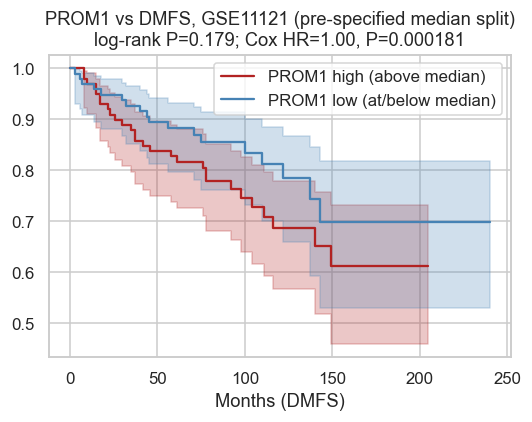

Median cutpoint=391.550; log-rank P=0.1794; continuous Cox HR=1.000, P=0.0001812


In [22]:
expr11121, clin11121 = geo_data["GSE11121"]
gse11121_genes = probes_to_gene_level(expr11121, gpl96_map)
surv11121 = clin11121[["e.dmfs", "t.dmfs"]].copy()
surv11121.columns = ["event", "time_months"]
surv11121["event"] = pd.to_numeric(surv11121["event"], errors="coerce")
surv11121["time_months"] = pd.to_numeric(surv11121["time_months"], errors="coerce")
df11121 = surv11121.join(gse11121_genes[["PROM1"]]).dropna()

# The independent-cohort check uses a pre-specified median split; we do NOT search
# many cutpoints and select the one with the smallest p-value.
prom1_cut = df11121["PROM1"].median()
high_med = df11121[df11121.PROM1 > prom1_cut]
low_med = df11121[df11121.PROM1 <= prom1_cut]
res11121 = logrank_test(high_med.time_months, low_med.time_months, high_med.event, low_med.event)

# Also report PROM1 continuously in a Cox model so the conclusion does not depend
# only on dichotomizing expression.
cph11121 = CoxPHFitter()
cph11121.fit(df11121[["time_months", "event", "PROM1"]], duration_col="time_months", event_col="event")
s11121 = cph11121.summary.loc["PROM1"]

fig, ax = plt.subplots(figsize=(5, 4))
kmf = KaplanMeierFitter()
kmf.fit(high_med.time_months, high_med.event, label="PROM1 high (above median)").plot_survival_function(ax=ax, color="firebrick")
kmf.fit(low_med.time_months, low_med.event, label="PROM1 low (at/below median)").plot_survival_function(ax=ax, color="steelblue")
ax.set_title(
    f"PROM1 vs DMFS, GSE11121 (pre-specified median split)\n"
    f"log-rank P={res11121.p_value:.3g}; Cox HR={s11121['exp(coef)']:.2f}, P={s11121['p']:.3g}"
)
ax.set_xlabel("Months (DMFS)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/09_dmfs_GSE11121.png"); plt.show()
print(f"Median cutpoint={prom1_cut:.3f}; log-rank P={res11121.p_value:.4g}; continuous Cox HR={s11121['exp(coef)']:.3f}, P={s11121['p']:.4g}")


In [23]:
# ============================================================
# 8a. External cohort scale check + log2 continuous Cox  [R7, R8]
# ============================================================
scale_rows = []
for cohort, dfx, genes in [("GSE124647", df124, ["PROM1", "CCL2"]), ("GSE11121", df11121, ["PROM1"])]:
    for gene in genes:
        v = dfx[gene].astype(float)
        is_log = v.max() < 30
        x = v if is_log else np.log2(v.clip(lower=0) + 1)
        d = dfx[["time_months", "event"]].assign(expr_log2=x)
        cph_s = CoxPHFitter().fit(d, duration_col="time_months", event_col="event")
        s = cph_s.summary.loc["expr_log2"]
        hi = dfx[v > v.median()]; lo = dfx[v <= v.median()]
        lr = logrank_test(hi.time_months, lo.time_months, hi.event, lo.event)
        scale_rows.append({
            "cohort": cohort, "gene": gene, "n": len(dfx), "events": int(dfx["event"].sum()),
            "deposited_scale": "log2" if is_log else "raw intensity (log2-transformed here)",
            "HR_per_log2_unit": s["exp(coef)"], "CI_lower": s["exp(coef) lower 95%"],
            "CI_upper": s["exp(coef) upper 95%"], "cox_p": s["p"], "median_split_logrank_p": lr.p_value,
        })
external_scale_check = pd.DataFrame(scale_rows)
external_scale_check.to_csv(f"{OUT_DIR}/external_cohorts_log2_scale_cox.csv", index=False)
display(external_scale_check)

for _, r in external_scale_check.iterrows():
    if r["median_split_logrank_p"] >= 0.05:
        print(f"{r['cohort']} / {r['gene']}: the tested median split did not reproduce significant separation "
              f"(log-rank P={r['median_split_logrank_p']:.3g}).")
    else:
        print(f"{r['cohort']} / {r['gene']}: the tested median split showed significant separation "
              f"(log-rank P={r['median_split_logrank_p']:.3g}).")


,cohort,gene,n,events,deposited_scale,HR_per_log2_unit,CI_lower,CI_upper,cox_p,median_split_logrank_p
0,GSE124647,PROM1,140,97,log2,1.161349,1.017567,1.325448,0.026541,0.539581
1,GSE124647,CCL2,140,97,log2,1.073391,0.971545,1.185914,0.163800,0.194398
2,GSE11121,PROM1,200,46,raw intensity (log2-transformed here),1.181076,1.004239,1.389052,0.044317,0.179355


GSE124647 / PROM1: the tested median split did not reproduce significant separation (log-rank P=0.54).
GSE124647 / CCL2: the tested median split did not reproduce significant separation (log-rank P=0.194).
GSE11121 / PROM1: the tested median split did not reproduce significant separation (log-rank P=0.179).


In [24]:
def normalized_laplacian(adj):
    deg = np.asarray(adj.sum(axis=1)).flatten()
    deg_inv_sqrt = np.power(deg, -0.5, where=deg > 0)
    deg_inv_sqrt[deg == 0] = 0
    D_inv_sqrt = sp.diags(deg_inv_sqrt)
    n = adj.shape[0]
    L = sp.eye(n) - D_inv_sqrt @ adj @ D_inv_sqrt
    return (L - sp.eye(n)).tocsr()  # rescaled to [-1,1] using lambda_max=2

def scipy_to_torch_sparse(mat):
    mat = mat.tocoo()
    idx = torch.tensor(np.vstack([mat.row, mat.col]), dtype=torch.long)
    val = torch.tensor(mat.data, dtype=torch.float32)
    return torch.sparse_coo_tensor(idx, val, mat.shape).coalesce()

def cheb_filter(L_hat, x, K):
    B, N, Fin = x.shape
    def apply_L(t):
        flat = t.permute(1, 0, 2).reshape(N, B * Fin)
        out = torch.sparse.mm(L_hat, flat)
        return out.reshape(N, B, Fin).permute(1, 0, 2)
    xs = [x]
    if K > 1:
        xs.append(apply_L(xs[-1]))
    for k in range(2, K):
        xs.append(2 * apply_L(xs[-1]) - xs[-2])
    return torch.stack(xs, dim=0)

class ChebConv(nn.Module):
    def __init__(self, Fin, Fout, K):
        super().__init__()
        self.Fin, self.Fout, self.K = Fin, Fout, K
        self.theta = nn.Parameter(torch.empty(K, Fin, Fout))
        nn.init.xavier_uniform_(self.theta.view(K * Fin, Fout))
        self.bias = nn.Parameter(torch.zeros(Fout))
    def forward(self, L_hat, x, theta=None):
        theta = self.theta if theta is None else theta
        xbar = cheb_filter(L_hat, x, self.K)
        y = torch.einsum("kbnf,kfo->bno", xbar, theta)
        return y + self.bias

def relevance_step(a, forward_fn, params_pos, R_out, eps=1e-9):
    a = a.detach().clone().requires_grad_(True)
    z = forward_fn(a, *params_pos) + eps
    s = (R_out / z).detach()
    (z * s).sum().backward()
    return (a * a.grad).detach()

def fc_fwd(a, w_pos):
    return a @ w_pos.t()

def youden_threshold(y_true, probs):
    fpr, tpr, thr = roc_curve(y_true, probs)
    return thr[np.argmax(tpr - fpr)]

L_hat = scipy_to_torch_sparse(normalized_laplacian(A))
N = A.shape[0]
print("Core Graph-CNN + GLRP implementation ready.")

Core Graph-CNN + GLRP implementation ready.


In [25]:
n_missing = expr175.loc[gene_list].isna().sum().sum()
genes_with_missing = expr175.loc[gene_list].isna().sum(axis=1)
genes_with_missing = genes_with_missing[genes_with_missing > 0]
print(f"Missing values in the {len(gene_list)}-gene modeling panel: {n_missing}")
print(f"Affected genes: {genes_with_missing.to_dict()}")

expr175_imputed = expr175.loc[gene_list].apply(lambda row: row.fillna(row.mean()), axis=1)
Xall = expr175_imputed.T  # patients x genes, in graph-node order

# Make the expression/clinical alignment explicit rather than assuming the two
# objects happen to have the same row order.
missing_clinical_ids = Xall.index.difference(clin175.index)
if len(missing_clinical_ids):
    raise ValueError(f"Clinical metadata missing for expression samples: {missing_clinical_ids.tolist()[:10]}")
clin175_model = clin175.reindex(Xall.index).copy()
assert Xall.index.equals(clin175_model.index), "Expression and clinical sample order are not aligned"

Xall_v = Xall.values.astype(np.float32)
Xall_v = Xall_v - np.nanmin(Xall_v)  # shift non-negative, matching Paper 2's preprocessing choice
if not np.isfinite(Xall_v).all():
    raise ValueError("Non-finite values remain in the modeling matrix after imputation")
print(f"Modeling signal ready: {Xall_v.shape[0]} patients x {Xall_v.shape[1]} genes, range [{Xall_v.min():.2f}, {Xall_v.max():.2f}]")
print("Clinical labels explicitly reindexed to the same patient order as Xall.")


Missing values in the 737-gene modeling panel: 215
Affected genes: {'CDK4': 43, 'CETN2': 43, 'ERCC1': 43, 'NEIL2': 43, 'PMS2': 43}
Modeling signal ready: 184 patients x 737 genes, range [0.00, 22.92]
Clinical labels explicitly reindexed to the same patient order as Xall.


In [26]:
print("Paper 2's input signal -- data samples (first 5 patients x first 6 genes):")
display(pd.DataFrame(Xall_v, index=Xall.index, columns=gene_list).iloc[:5, :6])


Paper 2's input signal -- data samples (first 5 patients x first 6 genes):


,ABCA8,ABCF1,ACTR3B,ACVR1B,ACVR1C,ACVRL1
GSM5344040,6.185767,11.092658,9.823197,9.784027,5.337770,8.688268
GSM5344041,8.722722,11.240570,10.585218,10.963730,6.848253,10.307684
GSM5344042,7.233238,10.268862,9.769291,9.955704,7.496273,8.370742
GSM5344043,7.609046,11.293047,10.994423,11.029316,3.597818,8.597818
GSM5344044,8.080235,10.796441,9.594808,10.360342,8.080235,8.442804


In [27]:
y_task1 = (clin175_model["organ"] == "Bone").astype(int).to_numpy()
print(f"Task 1 (bone vs non-bone): {y_task1.sum()} bone, {(1-y_task1).sum()} non-bone")

ev = pd.to_numeric(clin175_model["ose"], errors="coerce")
t_years = pd.to_numeric(clin175_model["os (months) since dxmet"], errors="coerce") / 12.0
died_within_3y = (ev == 1) & (t_years <= 3)
# FIXED (per external review): "alive at 3 years" is a landmark-analysis label -- it should
# be true for anyone with >3 years of follow-up regardless of eventual event status, because
# a patient who died at year 5 was still verifiably alive at year 3. The previous definition
# required (ev == 0) -- i.e. still censored/event-free -- which wrongly EXCLUDED patients who
# lived past 3 years and then later died from the "alive at 3y" bucket entirely (neither case
# nor control), shrinking the usable cohort to 116 patients. Also changed the boundary from
# >= 3 to > 3 to match the exact landmark definition requested.
alive_after_3y = (t_years > 3)
task2_mask = (died_within_3y | alive_after_3y).to_numpy()
y_task2_full = np.where(died_within_3y.to_numpy(), 1, 0)
print(f"Task 2 (death within 3y vs alive>=3y): {died_within_3y.sum()} died-within-3y, {alive_after_3y.sum()} alive->=3y, "
      f"{(~task2_mask).sum()} excluded (ambiguous follow-up)")

TASKS = {
    "bone_metastasis": {"X": Xall_v, "y": y_task1, "label": "bone-site vs. non-bone-site metastatic biopsy classification (Paper 1's task)"},
    "survival_outcome": {"X": Xall_v[task2_mask], "y": y_task2_full[task2_mask], "label": "post-metastatic-diagnosis mortality within 36 months vs. alive >=36 months"},
}
print("\nTasks ready:", {k: v["X"].shape for k, v in TASKS.items()})


Task 1 (bone vs non-bone): 33 bone, 151 non-bone
Task 2 (death within 3y vs alive>=3y): 68 died-within-3y, 84 alive->=3y, 32 excluded (ambiguous follow-up)

Tasks ready: {'bone_metastasis': (184, 737), 'survival_outcome': (152, 737)}


In [28]:
import re
from sklearn.model_selection import StratifiedGroupKFold

print("Raw clin175 'title' / 'source_name' values (first 15), for manual inspection regardless")
print("of whether the automatic parser below succeeds:")
display(clin175[["title", "source_name"]].head(15) if "title" in clin175.columns else clin175[["source_name"]].head(15))

def _extract_patient_id(row):
    # Conservative, best-effort: try a few common GEO title conventions for an
    # embedded patient/case identifier. Returns None (not a guess) if nothing
    # matches, rather than fabricating an id.
    for field in ["title", "source_name"]:
        if field not in row.index or pd.isna(row[field]):
            continue
        s = str(row[field])
        m = re.search(r"(patient|pt|case|subject)[_\s\-]?0*(\d+)", s, re.IGNORECASE)
        if m:
            return f"P{m.group(2)}"
        # Fallback: a leading alphanumeric block before the first separator is
        # sometimes the case ID even with no explicit "Patient"/"Case" label
        # (e.g. "B22-Met: Lung metastasis" -> "B22").
        m2 = re.match(r"^([A-Za-z]{0,4}\d+)", s.strip())
        if m2:
            return m2.group(1)
    return None

clin175_grp = clin175.copy()
clin175_grp["patient_id_guess"] = clin175_grp.apply(_extract_patient_id, axis=1)
n_recovered = clin175_grp["patient_id_guess"].notna().sum()
print(f"\nPatient IDs recovered from title/source_name text pattern: {n_recovered}/{len(clin175_grp)}")

PATIENT_GROUPS_AVAILABLE = False
PATIENT_ID_SERIES = None

if n_recovered == len(clin175_grp):
    n_unique = clin175_grp["patient_id_guess"].nunique()
    dup_counts = clin175_grp["patient_id_guess"].value_counts()
    n_repeat_patients = int((dup_counts > 1).sum())
    n_repeat_samples = int(dup_counts[dup_counts > 1].sum())
    matches_published = (n_unique == 176)
    print(f"Unique patients recovered: {n_unique} "
          f"({'MATCHES' if matches_published else 'DOES NOT MATCH'} the published 176-patient count "
          f"-- {'trust this mapping' if matches_published else 'treat this mapping with real caution, verify manually'})")
    print(f"Patients with >1 sample in this cohort: {n_repeat_patients} ({n_repeat_samples} samples total)")
    if matches_published and n_repeat_patients > 0:
        PATIENT_GROUPS_AVAILABLE = True
        PATIENT_ID_SERIES = clin175_grp["patient_id_guess"]
else:
    print(f"Could not recover a patient identifier for all {len(clin175_grp)} samples from "
          "title/source_name text.")
    print("CONFIRMED (not just a parser failure): GSE175692's public 'title' field is a meaningless "
          "sequential counter (e.g. 'TGTT_0001', 'TGTT_0002', ...) with no patient information, and "
          "'source_name' is the same constant string for every sample. No regex fix will recover "
          "patient identity from this data -- there is nothing encoded in it to recover. The source "
          "publication (Braso-Maristany et al. 2022) confirms some patients contributed samples from "
          "more than one metastatic site, so the leakage risk described above is real; a public "
          "GSM-to-patient crosswalk was not found in what's accessible from this notebook's data "
          "sources. Report this as a stated limitation (184 samples / 176 patients, per-sample "
          "StratifiedKFold, patient identity not recoverable from public GEO metadata) rather than "
          "continuing to chase a code-side fix, unless a supplementary patient-ID table from the "
          "original paper is separately obtained and merged in by hand.")

def make_cv_splitter(y, patient_ids=None, n_splits=5, random_state=0):
    """
    Returns (splitter, groups) -- StratifiedGroupKFold + the groups array if
    patient identity is known and this y actually contains repeat patients,
    otherwise plain StratifiedKFold + None, with a loud warning either way
    the fallback happens. Pass groups=groups to .split() either way --
    StratifiedKFold accepts and ignores a groups argument (API consistency),
    so this is a safe drop-in for every CV cell.
    """
    if patient_ids is not None:
        groups = np.asarray(patient_ids)
        if len(groups) == len(y) and pd.Series(groups).duplicated().any():
            return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state), groups
    print("  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- "
          "patient identity was unavailable, mismatched in length, or had no repeats for this call.")
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state), None

# Per-task patient-id arrays, aligned to each task's own X/y row order.
TASK_PATIENT_ID_ARRAYS = {}
if PATIENT_GROUPS_AVAILABLE:
    pid_by_gsm = PATIENT_ID_SERIES  # index-aligned with clin175 / Xall
    TASK_PATIENT_ID_ARRAYS["bone_metastasis"] = pid_by_gsm.reindex(Xall.index).to_numpy()
    TASK_PATIENT_ID_ARRAYS["survival_outcome"] = pid_by_gsm.reindex(Xall.index[task2_mask]).to_numpy()
else:
    TASK_PATIENT_ID_ARRAYS["bone_metastasis"] = None
    TASK_PATIENT_ID_ARRAYS["survival_outcome"] = None


Raw clin175 'title' / 'source_name' values (first 15), for manual inspection regardless
of whether the automatic parser below succeeds:


,title,source_name
GSM5344040,TGTT_0001,metastatic breast cancer
GSM5344041,TGTT_0002,metastatic breast cancer
GSM5344042,TGTT_0003,metastatic breast cancer
GSM5344043,TGTT_0004,metastatic breast cancer
GSM5344044,TGTT_0005,metastatic breast cancer
GSM5344045,TGTT_0006,metastatic breast cancer
GSM5344046,TGTT_0007,metastatic breast cancer
GSM5344047,TGTT_0008,metastatic breast cancer
GSM5344048,TGTT_0009,metastatic breast cancer
GSM5344049,TGTT_0010,metastatic breast cancer



Patient IDs recovered from title/source_name text pattern: 0/184
Could not recover a patient identifier for all 184 samples from title/source_name text.
CONFIRMED (not just a parser failure): GSE175692's public 'title' field is a meaningless sequential counter (e.g. 'TGTT_0001', 'TGTT_0002', ...) with no patient information, and 'source_name' is the same constant string for every sample. No regex fix will recover patient identity from this data -- there is nothing encoded in it to recover. The source publication (Braso-Maristany et al. 2022) confirms some patients contributed samples from more than one metastatic site, so the leakage risk described above is real; a public GSM-to-patient crosswalk was not found in what's accessible from this notebook's data sources. Report this as a stated limitation (184 samples / 176 patients, per-sample StratifiedKFold, patient identity not recoverable from public GEO metadata) rather than continuing to chase a code-side fix, unless a supplementary 

In [29]:
# ============================================================
# Sample-to-patient mapping via identical patient-level clinical profiles  [R2]
# ============================================================
USE_INFERRED_PATIENT_GROUPS = True   # set False to force sample-level CV regardless of the result below
PUBLISHED_N_PATIENTS = 176

profile_cols = ["age (years)", "ose", "os (months) since dxmet", "pre-post menopausal",
                "de novo metastasis vs relapsed", "hr", "her2"]
profile_cols = [c for c in profile_cols if c in clin175.columns]
print("Patient-level fields used for matching:", profile_cols)

prof = clin175[profile_cols].astype(str).apply(lambda s: s.str.strip().str.upper())
prof_key = prof.agg("|".join, axis=1)
n_unique_profiles = prof_key.nunique()
dup_groups = prof_key[prof_key.duplicated(keep=False)]
print(f"Unique patient-level profiles: {n_unique_profiles} of {len(prof_key)} samples "
      f"(published: {PUBLISHED_N_PATIENTS} patients)")

if len(dup_groups):
    dup_table = (clin175.loc[dup_groups.index, ["organ"] + profile_cols]
                 .assign(profile_group=dup_groups.map({k: f"G{i+1}" for i, k in enumerate(dup_groups.unique())}))
                 .sort_values("profile_group"))
    print("\nSamples sharing an identical patient-level profile (candidate same-patient samples):")
    display(dup_table)
    dup_table.to_csv(f"{OUT_DIR}/GSE175692_candidate_same_patient_samples.csv")
    n_sites_differ = dup_table.groupby("profile_group")["organ"].nunique().gt(1).sum()
    print(f"Groups whose samples come from different metastatic sites: {n_sites_differ} of "
          f"{dup_table['profile_group'].nunique()} (multi-site sampling of one patient is what the source paper describes)")
else:
    print("No two samples share an identical patient-level profile.")

mapping_matches_publication = (n_unique_profiles == PUBLISHED_N_PATIENTS)
PATIENT_ID_SOURCE = "none (sample-level CV)"
if USE_INFERRED_PATIENT_GROUPS and mapping_matches_publication:
    PATIENT_ID_SERIES = prof_key.map({k: f"PT{i+1:03d}" for i, k in enumerate(prof_key.unique())})
    PATIENT_GROUPS_AVAILABLE = True
    PATIENT_ID_SOURCE = "inferred from identical clinical profiles (pending author confirmation)"
    TASK_PATIENT_ID_ARRAYS["bone_metastasis"] = PATIENT_ID_SERIES.reindex(Xall.index).to_numpy()
    TASK_PATIENT_ID_ARRAYS["survival_outcome"] = PATIENT_ID_SERIES.reindex(Xall.index[task2_mask]).to_numpy()
    print(f"\nInferred grouping gives exactly {PUBLISHED_N_PATIENTS} patients -> patient-grouped CV ENABLED "
          "for every CV cell below (make_cv_splitter switches to StratifiedGroupKFold automatically).")
else:
    print(f"\nInferred grouping gives {n_unique_profiles} profiles, not {PUBLISHED_N_PATIENTS} -> not trusted. "
          "Sample-level CV is kept and the limitation statement in the markdown above applies.")

pd.DataFrame([{
    "checked_title_field": True, "checked_source_name_field": True, "checked_all_clinical_fields": True,
    "profile_fields_used": "; ".join(profile_cols), "n_samples": len(prof_key),
    "n_unique_profiles": n_unique_profiles, "published_n_patients": PUBLISHED_N_PATIENTS,
    "mapping_used": PATIENT_ID_SOURCE,
}]).to_csv(f"{OUT_DIR}/GSE175692_patient_mapping_audit.csv", index=False)
print(f"Mapping used downstream: {PATIENT_ID_SOURCE}")


Patient-level fields used for matching: ['age (years)', 'ose', 'os (months) since dxmet', 'pre-post menopausal', 'de novo metastasis vs relapsed', 'hr', 'her2']
Unique patient-level profiles: 178 of 184 samples (published: 176 patients)

Samples sharing an identical patient-level profile (candidate same-patient samples):


,organ,age (years),ose,os (months) since dxmet,pre-post menopausal,de novo metastasis vs relapsed,hr,her2,profile_group
GSM5344050,Skin,77,0,53.62,postmenopausal,de novo,POS,NEG,G1
GSM5344051,Skin,77,0,53.62,postmenopausal,de novo,POS,NEG,G1
GSM5344070,Brain,63,0,36.56,postmenopausal,relapsed,POS,NEG,G2
GSM5344071,Brain,63,0,36.56,postmenopausal,relapsed,POS,NEG,G2
GSM5344081,Skin,57,0,84.33,postmenopausal,relapsed,POS,NEG,G3
GSM5344082,Skin,57,0,84.33,postmenopausal,relapsed,POS,NEG,G3
GSM5344090,Bone,54,0,7.17,postmenopausal,relapsed,POS,NEG,G4
GSM5344091,Bone,54,0,7.17,postmenopausal,relapsed,POS,NEG,G4
GSM5344147,Lymph node,63,1,76.31,postmenopausal,relapsed,NEG,NEG,G5
GSM5344148,Bone,63,1,76.31,postmenopausal,relapsed,NEG,NEG,G5


Groups whose samples come from different metastatic sites: 1 of 6 (multi-site sampling of one patient is what the source paper describes)

Inferred grouping gives 178 profiles, not 176 -> not trusted. Sample-level CV is kept and the limitation statement in the markdown above applies.
Mapping used downstream: none (sample-level CV)


In [30]:
class GraphCNN(nn.Module):
    def __init__(self, N, K=7, F1=16, F2=8, n_classes=2):
        super().__init__()
        self.conv1 = ChebConv(1, F1, K)
        self.conv2 = ChebConv(F1, F2, K)
        self.fc1 = nn.Linear(N * F2, 64)
        self.drop = nn.Dropout(0.5)
        self.fc2 = nn.Linear(64, n_classes)
        self.N, self.F2 = N, F2
    def forward(self, L_hat, x):
        xb = x.unsqueeze(-1)
        h1 = torch.relu(self.conv1(L_hat, xb))
        h2 = torch.relu(self.conv2(L_hat, h1))
        flat = h2.reshape(h2.shape[0], -1)
        h = torch.relu(self.fc1(flat))
        h = self.drop(h)
        return self.fc2(h)

def train_one_fold(Xtr, ytr, Xva, yva, n_epochs=30, batch_size=16, lr=5e-4):
    model = GraphCNN(N)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(ytr)
    Xva_t = torch.tensor(Xva)
    best_auc, best_state = -1, None
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = lossf(model(L_hat, Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(L_hat, Xva_t), dim=1)[:, 1].numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_auc

print("Training utilities ready.")

Training utilities ready.


In [31]:
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    recall_score, balanced_accuracy_score, average_precision_score
)

# Positive class (label 1) means "bone metastasis" for Task 1 and "died within
# 3 years" for Task 2 -- report which one applies when reading sensitivity/specificity.
def fold_metrics(y_true, probs, preds):
    return {
        "AUC": roc_auc_score(y_true, probs),
        "AUPRC": average_precision_score(y_true, probs),
        "accuracy": accuracy_score(y_true, preds),
        "balanced_accuracy": balanced_accuracy_score(y_true, preds),
        "F1": f1_score(y_true, preds, zero_division=0),
        "sensitivity_pos_class": recall_score(y_true, preds, pos_label=1, zero_division=0),
        "specificity_neg_class": recall_score(y_true, preds, pos_label=0, zero_division=0),
    }

METRIC_COLS = ["AUC", "AUPRC", "accuracy", "balanced_accuracy", "F1",
               "sensitivity_pos_class", "specificity_neg_class"]

cv_results = {}
for task_name, task in TASKS.items():
    X_task, y_task = task["X"], task["y"]
    skf, _groups = make_cv_splitter(y_task, patient_ids=TASK_PATIENT_ID_ARRAYS[task_name], random_state=0)
    fold_results, rf_results = [], []
    for fold, (train_idx, test_idx) in enumerate(skf.split(X_task, y_task, groups=_groups)):
        Xtr_full, ytr_full = X_task[train_idx], y_task[train_idx]
        Xte_fold, yte_fold = X_task[test_idx], y_task[test_idx]
        Xtr, Xva, ytr, yva = train_test_split(
            Xtr_full, ytr_full, test_size=0.15, stratify=ytr_full, random_state=fold
        )

        # Graph-CNN: train on Xtr, tune threshold on Xva, evaluate once on held-out fold.
        model, val_auc = train_one_fold(Xtr, ytr, Xva, yva)
        model.eval()
        with torch.no_grad():
            va_probs = torch.softmax(model(L_hat, torch.tensor(Xva)), dim=1)[:, 1].numpy()
            probs = torch.softmax(model(L_hat, torch.tensor(Xte_fold)), dim=1)[:, 1].numpy()
        thr = youden_threshold(yva, va_probs)
        preds = (probs >= thr).astype(int)
        m = fold_metrics(yte_fold, probs, preds)
        m["fold"] = fold
        fold_results.append(m)

        # Random Forest: same inner training/validation samples, same threshold procedure.
        rf = RandomForestClassifier(n_estimators=300, random_state=fold, class_weight="balanced")
        rf.fit(Xtr, ytr)
        rf_va_probs = rf.predict_proba(Xva)[:, 1]
        rf_probs = rf.predict_proba(Xte_fold)[:, 1]
        rf_thr = youden_threshold(yva, rf_va_probs)
        rf_preds = (rf_probs >= rf_thr).astype(int)
        m_rf = fold_metrics(yte_fold, rf_probs, rf_preds)
        m_rf["fold"] = fold
        rf_results.append(m_rf)

    gcnn_df = pd.DataFrame(fold_results)
    rf_df = pd.DataFrame(rf_results)
    cv_results[task_name] = {"gcnn": gcnn_df, "rf": rf_df}
    print(f"\n=== {task['label']} ===")
    for label, df_ in [("Graph-CNN", gcnn_df), ("Random Forest", rf_df)]:
        line = ", ".join(f"{c} {df_[c].mean():.3f}+-{df_[c].std():.3f}" for c in METRIC_COLS)
        print(f"{label}: {line}")

cv_summary = pd.DataFrame({
    "Task": [TASKS[k]["label"] for k in cv_results for _ in [0, 1]],
    "Method": [m for k in cv_results for m in ["Graph-CNN", "Random Forest"]],
    **{col: [f"{cv_results[k][m][col].mean():.3f}+-{cv_results[k][m][col].std():.3f}"
             for k in cv_results for m in ["gcnn", "rf"]] for col in METRIC_COLS}
})
cv_summary.to_csv(f"{OUT_DIR}/cv_performance_both_tasks_expanded.csv", index=False)
print("\nCross-validated performance, both tasks (expanded metrics).")
print("NOTE ON METRIC DEFINITION: every value here is the MEAN OF PER-FOLD METRICS "
      "(AUC computed separately on each of the 5 folds, then averaged) -- NOT a pooled "
      "out-of-fold metric computed once on all folds' predictions merged together. The "
      "ablation table (Items 2-4, later in the notebook) uses POOLED out-of-fold metrics "
      "instead. These are different statistics that can differ meaningfully, especially "
      "with small per-fold minority-class counts -- do not treat numbers from the two "
      "tables as directly comparable without noting which one each came from.")
display(cv_summary)


  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.



=== bone-site vs. non-bone-site metastatic biopsy classification (Paper 1's task) ===
Graph-CNN: AUC 0.878+-0.147, AUPRC 0.736+-0.235, accuracy 0.897+-0.070, balanced_accuracy 0.807+-0.102, F1 0.703+-0.180, sensitivity_pos_class 0.667+-0.154, specificity_neg_class 0.947+-0.051
Random Forest: AUC 0.926+-0.053, AUPRC 0.834+-0.041, accuracy 0.908+-0.041, balanced_accuracy 0.841+-0.052, F1 0.747+-0.069, sensitivity_pos_class 0.733+-0.160, specificity_neg_class 0.948+-0.075
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.



=== post-metastatic-diagnosis mortality within 36 months vs. alive >=36 months ===
Graph-CNN: AUC 0.660+-0.117, AUPRC 0.626+-0.065, accuracy 0.613+-0.136, balanced_accuracy 0.616+-0.117, F1 0.611+-0.064, sensitivity_pos_class 0.662+-0.130, specificity_neg_class 0.570+-0.326
Random Forest: AUC 0.700+-0.094, AUPRC 0.676+-0.092, accuracy 0.625+-0.025, balanced_accuracy 0.613+-0.037, F1 0.516+-0.109, sensitivity_pos_class 0.485+-0.228, specificity_neg_class 0.740+-0.173

Cross-validated performance, both tasks (expanded metrics).
NOTE ON METRIC DEFINITION: every value here is the MEAN OF PER-FOLD METRICS (AUC computed separately on each of the 5 folds, then averaged) -- NOT a pooled out-of-fold metric computed once on all folds' predictions merged together. The ablation table (Items 2-4, later in the notebook) uses POOLED out-of-fold metrics instead. These are different statistics that can differ meaningfully, especially with small per-fold minority-class counts -- do not treat numbers fr

,Task,Method,AUC,AUPRC,accuracy,balanced_accuracy,F1,sensitivity_pos_class,specificity_neg_class
0,bone-site vs. non-bone-site metastatic biopsy ...,Graph-CNN,0.878+-0.147,0.736+-0.235,0.897+-0.070,0.807+-0.102,0.703+-0.180,0.667+-0.154,0.947+-0.051
1,bone-site vs. non-bone-site metastatic biopsy ...,Random Forest,0.926+-0.053,0.834+-0.041,0.908+-0.041,0.841+-0.052,0.747+-0.069,0.733+-0.160,0.948+-0.075
2,post-metastatic-diagnosis mortality within 36 ...,Graph-CNN,0.660+-0.117,0.626+-0.065,0.613+-0.136,0.616+-0.117,0.611+-0.064,0.662+-0.130,0.570+-0.326
3,post-metastatic-diagnosis mortality within 36 ...,Random Forest,0.700+-0.094,0.676+-0.092,0.625+-0.025,0.613+-0.037,0.516+-0.109,0.485+-0.228,0.740+-0.173


In [32]:
def train_one_fold_weighted(Xtr, ytr, Xva, yva, n_epochs=30, batch_size=16, lr=5e-4):
    # Class weights computed from the training fold only, mirroring how
    # class_weight="balanced" is derived for the Random Forest.
    counts = np.bincount(ytr, minlength=2).astype(np.float32)
    weights = torch.tensor(len(ytr) / (2.0 * np.maximum(counts, 1)), dtype=torch.float32)

    model = GraphCNN(N)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss(weight=weights)
    Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(ytr)
    Xva_t = torch.tensor(Xva)
    best_auc, best_state = -1, None
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = lossf(model(L_hat, Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(L_hat, Xva_t), dim=1)[:, 1].numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_auc

print("train_one_fold_weighted defined -- not wired into the Section 12 loop; swap it in manually if Igor wants it.")


train_one_fold_weighted defined -- not wired into the Section 12 loop; swap it in manually if Igor wants it.


In [33]:
def build_fold_matrix(gene_list, raw_expr, train_pids, apply_pids):
    """
    Fit per-gene mean-imputation and the global non-negative shift using ONLY
    train_pids, then apply that exact fit to apply_pids (train, validation, or
    held-out test patients). Mirrors Section 10's preprocessing, but strictly
    fold-scoped: no statistic is ever computed from a patient it is later applied to.
    """
    train_block = raw_expr.loc[gene_list, train_pids]
    gene_means = train_block.mean(axis=1)

    def _prep(pids):
        block = raw_expr.loc[gene_list, pids].copy()
        for gene in gene_list:
            block.loc[gene] = block.loc[gene].fillna(gene_means[gene])
        return block.T.values.astype(np.float32)

    Xtr_raw = _prep(train_pids)
    train_min = np.nanmin(Xtr_raw)
    return _prep(apply_pids) - train_min

TASK_PATIENT_IDS = {
    "bone_metastasis": Xall.index.tolist(),
    "survival_outcome": Xall.index[task2_mask].tolist(),
}
TASK_RAW_EXPR = expr175  # genes x all patients, BEFORE Section 10's imputation/shift

cv_results_strict = {}
for task_name, task in TASKS.items():
    y_task = task["y"]
    pids_task = np.array(TASK_PATIENT_IDS[task_name])
    skf, _groups = make_cv_splitter(y_task, patient_ids=TASK_PATIENT_ID_ARRAYS[task_name], random_state=0)
    fold_results, rf_results = [], []
    for fold, (train_idx, test_idx) in enumerate(skf.split(pids_task, y_task, groups=_groups)):
        pids_tr_full, ytr_full = pids_task[train_idx], y_task[train_idx]
        pids_te, yte_fold = pids_task[test_idx], y_task[test_idx]

        pids_tr, pids_va, ytr, yva = train_test_split(
            pids_tr_full, ytr_full, test_size=0.15, stratify=ytr_full, random_state=fold
        )

        # Imputation mean + non-negative shift fit on pids_tr ONLY.
        Xtr = build_fold_matrix(gene_list, TASK_RAW_EXPR, pids_tr, pids_tr)
        Xva = build_fold_matrix(gene_list, TASK_RAW_EXPR, pids_tr, pids_va)
        Xte_fold = build_fold_matrix(gene_list, TASK_RAW_EXPR, pids_tr, pids_te)

        model, val_auc = train_one_fold(Xtr, ytr, Xva, yva)
        model.eval()
        with torch.no_grad():
            va_probs = torch.softmax(model(L_hat, torch.tensor(Xva)), dim=1)[:, 1].numpy()
            probs = torch.softmax(model(L_hat, torch.tensor(Xte_fold)), dim=1)[:, 1].numpy()
        thr = youden_threshold(yva, va_probs)
        preds = (probs >= thr).astype(int)
        m = fold_metrics(yte_fold, probs, preds)
        m["fold"] = fold
        fold_results.append(m)

        rf = RandomForestClassifier(n_estimators=300, random_state=fold, class_weight="balanced")
        rf.fit(Xtr, ytr)
        rf_va_probs = rf.predict_proba(Xva)[:, 1]
        rf_probs = rf.predict_proba(Xte_fold)[:, 1]
        rf_thr = youden_threshold(yva, rf_va_probs)
        rf_preds = (rf_probs >= rf_thr).astype(int)
        m_rf = fold_metrics(yte_fold, rf_probs, rf_preds)
        m_rf["fold"] = fold
        rf_results.append(m_rf)

    gcnn_df = pd.DataFrame(fold_results)
    rf_df = pd.DataFrame(rf_results)
    cv_results_strict[task_name] = {"gcnn": gcnn_df, "rf": rf_df}
    print(f"\n=== {task['label']} (strict per-fold preprocessing) ===")
    for label, df_ in [("Graph-CNN", gcnn_df), ("Random Forest", rf_df)]:
        line = ", ".join(f"{c} {df_[c].mean():.3f}+-{df_[c].std():.3f}" for c in METRIC_COLS)
        print(f"{label}: {line}")

cv_summary_strict = pd.DataFrame({
    "Task": [TASKS[k]["label"] for k in cv_results_strict for _ in [0, 1]],
    "Method": [m for k in cv_results_strict for m in ["Graph-CNN", "Random Forest"]],
    **{col: [f"{cv_results_strict[k][m][col].mean():.3f}+-{cv_results_strict[k][m][col].std():.3f}"
             for k in cv_results_strict for m in ["gcnn", "rf"]] for col in METRIC_COLS}
})
cv_summary_strict.to_csv(f"{OUT_DIR}/cv_performance_both_tasks_STRICT_per_fold_preprocessing.csv", index=False)
print("\nCross-validated performance, strict per-fold preprocessing (compare against the default-pipeline table above):")
display(cv_summary_strict)

  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.



=== bone-site vs. non-bone-site metastatic biopsy classification (Paper 1's task) (strict per-fold preprocessing) ===
Graph-CNN: AUC 0.889+-0.102, AUPRC 0.743+-0.129, accuracy 0.886+-0.052, balanced_accuracy 0.723+-0.136, F1 0.548+-0.320, sensitivity_pos_class 0.467+-0.278, specificity_neg_class 0.980+-0.018
Random Forest: AUC 0.926+-0.053, AUPRC 0.834+-0.041, accuracy 0.908+-0.041, balanced_accuracy 0.841+-0.052, F1 0.747+-0.069, sensitivity_pos_class 0.733+-0.160, specificity_neg_class 0.948+-0.075
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.



=== post-metastatic-diagnosis mortality within 36 months vs. alive >=36 months (strict per-fold preprocessing) ===
Graph-CNN: AUC 0.681+-0.041, AUPRC 0.641+-0.051, accuracy 0.625+-0.067, balanced_accuracy 0.623+-0.064, F1 0.589+-0.062, sensitivity_pos_class 0.605+-0.123, specificity_neg_class 0.640+-0.155
Random Forest: AUC 0.699+-0.096, AUPRC 0.677+-0.089, accuracy 0.625+-0.025, balanced_accuracy 0.613+-0.037, F1 0.516+-0.109, sensitivity_pos_class 0.485+-0.228, specificity_neg_class 0.740+-0.173

Cross-validated performance, strict per-fold preprocessing (compare against the default-pipeline table above):


,Task,Method,AUC,AUPRC,accuracy,balanced_accuracy,F1,sensitivity_pos_class,specificity_neg_class
0,bone-site vs. non-bone-site metastatic biopsy ...,Graph-CNN,0.889+-0.102,0.743+-0.129,0.886+-0.052,0.723+-0.136,0.548+-0.320,0.467+-0.278,0.980+-0.018
1,bone-site vs. non-bone-site metastatic biopsy ...,Random Forest,0.926+-0.053,0.834+-0.041,0.908+-0.041,0.841+-0.052,0.747+-0.069,0.733+-0.160,0.948+-0.075
2,post-metastatic-diagnosis mortality within 36 ...,Graph-CNN,0.681+-0.041,0.641+-0.051,0.625+-0.067,0.623+-0.064,0.589+-0.062,0.605+-0.123,0.640+-0.155
3,post-metastatic-diagnosis mortality within 36 ...,Random Forest,0.699+-0.096,0.677+-0.089,0.625+-0.025,0.613+-0.037,0.516+-0.109,0.485+-0.228,0.740+-0.173


In [34]:
# ============================================================
# 12P-1. Primary evaluation engine  [R3, R4, R5]
# ============================================================
import json, pickle
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
                             f1_score, recall_score, precision_score, matthews_corrcoef, confusion_matrix)

N_REPEATS_PRIMARY = 5
N_FOLDS_PRIMARY = 5
N_EPOCHS_PRIMARY = 30
INNER_VAL_FRACTION = 0.15
RUN_K_SWEEP = True
PRIMARY_CKPT_TAG = "v4primary_foldinternal"
PRIMARY_DIR = os.path.join(OUT_DIR, "primary_evaluation")
os.makedirs(PRIMARY_DIR, exist_ok=True)

TASK_SAMPLE_IDS = {
    "bone_metastasis": np.array(Xall.index.tolist()),
    "survival_outcome": np.array(Xall.index[task2_mask].tolist()),
}

# ---------- fold-internal preprocessing ----------
def prep_fold(train_ids, apply_ids):
    """Fit gene-mean imputation + non-negative shift on train_ids only; apply to apply_ids.
    Values below the training minimum (only possible in val/test samples) are set to 0,
    so the GLRP z+ rule always receives non-negative inputs. Returns (matrix, n_clipped)."""
    X = build_fold_matrix(gene_list, expr175, list(train_ids), list(apply_ids))
    n_clipped = int((X < 0).sum())
    return np.maximum(X, 0).astype(np.float32), n_clipped

# ---------- shared partitions ----------
def make_partitions(ids, y, groups=None, n_repeats=N_REPEATS_PRIMARY):
    parts = []
    for repeat in range(n_repeats):
        skf, _groups = make_cv_splitter(y, patient_ids=groups, n_splits=N_FOLDS_PRIMARY, random_state=repeat)
        for fold, (tr_full, te) in enumerate(skf.split(ids, y, groups=_groups)):
            inner_seed = 100 * repeat + fold          # repeat 0 -> random_state=fold, as in the legacy cells
            if _groups is not None:
                sgk = StratifiedGroupKFold(n_splits=int(round(1 / INNER_VAL_FRACTION)), shuffle=True,
                                           random_state=inner_seed)
                tr_pos, va_pos = next(sgk.split(tr_full, y[tr_full], groups=_groups[tr_full]))
                tr, va = tr_full[tr_pos], tr_full[va_pos]
            else:
                tr, va = train_test_split(tr_full, test_size=INNER_VAL_FRACTION, stratify=y[tr_full],
                                          random_state=inner_seed)
            parts.append({"repeat": repeat, "fold": fold,
                          "train": ids[tr].tolist(), "val": ids[va].tolist(), "test": ids[te].tolist()})
    return parts

def load_or_build_partitions(task_name):
    path = os.path.join(PRIMARY_DIR, f"partitions_{task_name}.json")
    ids, y = TASK_SAMPLE_IDS[task_name], TASKS[task_name]["y"]
    if os.path.exists(path):
        with open(path) as f:
            saved = json.load(f)
        if saved.get("sample_ids") == ids.tolist() and saved.get("n_repeats") == N_REPEATS_PRIMARY \
                and saved.get("grouped") == bool(PATIENT_GROUPS_AVAILABLE):
            print(f"[{task_name}] reusing saved partitions: {path}")
            return saved["partitions"]
        print(f"[{task_name}] saved partitions do not match the current cohort/settings -- rebuilding.")
    parts = make_partitions(ids, y, groups=TASK_PATIENT_ID_ARRAYS.get(task_name))
    with open(path, "w") as f:
        json.dump({"sample_ids": ids.tolist(), "n_repeats": N_REPEATS_PRIMARY,
                   "grouped": bool(PATIENT_GROUPS_AVAILABLE), "partitions": parts}, f)
    print(f"[{task_name}] partitions saved: {path}")
    return parts

# ---------- graph operators (built once) ----------
G_shuffled_primary = G_main.copy()
nx.double_edge_swap(G_shuffled_primary, nswap=int(2.5 * G_shuffled_primary.number_of_edges()),
                    max_tries=int(50 * G_shuffled_primary.number_of_edges()), seed=0)
GRAPH_OPERATORS = {
    "real": L_hat,
    "shuffled": scipy_to_torch_sparse(normalized_laplacian(
        nx.to_scipy_sparse_array(G_shuffled_primary, nodelist=gene_list, format="csr"))),
    "identity": scipy_to_torch_sparse(normalized_laplacian(sp.identity(N, format="csr"))),
}

class PrimaryMLP(nn.Module):
    def __init__(self, n_features, hidden=64, n_classes=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features, hidden), nn.ReLU(), nn.Dropout(0.5), nn.Linear(hidden, n_classes))
    def forward(self, x):
        return self.net(x)

PRIMARY_MODELS = {   # name: (family, graph, K)
    "GCN_real_K7": ("gcn", "real", 7),
    "GCN_shuffled_K7": ("gcn", "shuffled", 7),
    "GCN_identity_K7": ("gcn", "identity", 7),
    "MLP_no_graph": ("mlp", None, None),
    "LogisticRegression": ("lr", None, None),
    "RandomForest": ("rf", None, None),
}
if RUN_K_SWEEP:
    PRIMARY_MODELS.update({f"GCN_real_K{k}": ("gcn", "real", k) for k in [3, 5, 9]})
MODEL_INDEX = {name: i for i, name in enumerate(PRIMARY_MODELS)}

def _fit_nn(make_model, forward, Xtr, ytr, Xva, yva, seed, n_epochs=N_EPOCHS_PRIMARY, batch_size=16, lr=5e-4):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t, Xva_t = torch.tensor(Xtr), torch.tensor(ytr), torch.tensor(Xva)
    best_auc, best_state, best_epoch = -1, None, -1
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = lossf(forward(model, Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(forward(model, Xva_t), dim=1)[:, 1].numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc, best_epoch = auc, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    return model, best_auc, best_epoch

def fit_predict(model_name, Xtr, ytr, Xva, yva, Xte, seed):
    """Returns (model, val_probs, test_probs, best_val_auc). Same contract for every model."""
    family, graph, K = PRIMARY_MODELS[model_name]
    if family == "gcn":
        L_op = GRAPH_OPERATORS[graph]
        fwd = lambda m, X: m(L_op, X)
        model, best_auc, _ = _fit_nn(lambda: GraphCNN(N, K=K), fwd, Xtr, ytr, Xva, yva, seed)
        with torch.no_grad():
            va = torch.softmax(fwd(model, torch.tensor(Xva)), 1)[:, 1].numpy()
            te = torch.softmax(fwd(model, torch.tensor(Xte)), 1)[:, 1].numpy()
        return model, va, te, best_auc
    if family == "mlp":
        fwd = lambda m, X: m(X)
        model, best_auc, _ = _fit_nn(lambda: PrimaryMLP(Xtr.shape[1]), fwd, Xtr, ytr, Xva, yva, seed)
        with torch.no_grad():
            va = torch.softmax(fwd(model, torch.tensor(Xva)), 1)[:, 1].numpy()
            te = torch.softmax(fwd(model, torch.tensor(Xte)), 1)[:, 1].numpy()
        return model, va, te, best_auc
    if family == "lr":
        model = LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced").fit(Xtr, ytr)
    else:
        model = RandomForestClassifier(n_estimators=300, random_state=seed, class_weight="balanced").fit(Xtr, ytr)
    va, te = model.predict_proba(Xva)[:, 1], model.predict_proba(Xte)[:, 1]
    return model, va, te, (roc_auc_score(yva, va) if len(set(yva)) > 1 else np.nan)

def _metrics(y_true, probs, preds):
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y_true, probs) if len(set(y_true)) > 1 else np.nan,
            "PR_AUC": average_precision_score(y_true, probs) if len(set(y_true)) > 1 else np.nan,
            "accuracy": accuracy_score(y_true, preds), "balanced_accuracy": balanced_accuracy_score(y_true, preds),
            "sensitivity": recall_score(y_true, preds, pos_label=1, zero_division=0),
            "specificity": recall_score(y_true, preds, pos_label=0, zero_division=0),
            "precision": precision_score(y_true, preds, pos_label=1, zero_division=0),
            "F1": f1_score(y_true, preds, zero_division=0), "MCC": matthews_corrcoef(y_true, preds),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

# ---------- [v14] checkpoint fingerprint ----------
# Every checkpoint stores a hash of everything that determines its contents. A checkpoint is reused only if
# the hash matches the current configuration; otherwise that repeat is retrained.
# Checkpoints written before v14 have no fingerprint: CKPT_LEGACY_POLICY = "retrain" retrains them,
# "accept" loads them and lists them in CKPT_UNVERIFIED for the 12P-9 audit.
import hashlib
CKPT_LEGACY_POLICY = "accept"
CKPT_UNVERIFIED, CKPT_STALE = [], []
_EXPR_HASH = hashlib.sha1(pd.util.hash_pandas_object(expr175.loc[gene_list], index=True).values.tobytes()).hexdigest()

def _graph_hash(graph_key):
    if graph_key is None:
        return None
    L = GRAPH_OPERATORS[graph_key].coalesce()
    return hashlib.sha1(L.indices().numpy().tobytes() + np.round(L.values().numpy(), 6).tobytes()).hexdigest()

def ckpt_fingerprint(model_name, rep_partitions, label_lookup):
    family, graph_key, K = PRIMARY_MODELS[model_name]
    ids = sorted({s for p in rep_partitions for k in ("train", "val", "test") for s in p[k]})
    payload = {"model": model_name, "family": family, "K": K, "graph": _graph_hash(graph_key),
               "epochs": N_EPOCHS_PRIMARY, "lr": 5e-4, "weight_decay": 5e-4, "batch": 16, "mlp_hidden": 64,
               "rf_trees": 300, "lr_C": 1.0, "seed_index": MODEL_INDEX[model_name], "prep": "prep_fold:mean-impute+shift+clip0",
               "threshold": "youden_inner_val", "genes": hashlib.sha1("|".join(gene_list).encode()).hexdigest(),
               "expr": _EXPR_HASH,
               "labels": [(s, int(label_lookup.loc[s])) for s in ids],
               "partitions": [(p["repeat"], p["fold"], sorted(p["train"]), sorted(p["val"]), sorted(p["test"]))
                              for p in rep_partitions]}
    return hashlib.sha1(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()

def _ckpt_env():
    import sklearn
    return {"torch": torch.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__,
            "threads": torch.get_num_threads()}

def run_cv(task_name, model_name, partitions, label_lookup, ckpt_prefix=None, verbose=True):
    """Runs one model over the given partitions. Returns (fold_df, oof_df).
    label_lookup: pd.Series sample_id -> label. Thresholds come from inner validation only."""
    fold_rows, oof_rows = [], []
    repeats = sorted(set(p["repeat"] for p in partitions))
    for repeat in repeats:
        ckpt = (os.path.join(PRIMARY_DIR, f"{ckpt_prefix}__{model_name}__rep{repeat}__{PRIMARY_CKPT_TAG}.pkl")
                if ckpt_prefix else None)
        fp = (ckpt_fingerprint(model_name, [p for p in partitions if p["repeat"] == repeat], label_lookup)
              if ckpt else None)
        if ckpt and os.path.exists(ckpt):
            with open(ckpt, "rb") as f:
                saved = pickle.load(f)
            fp_saved = saved.get("fingerprint")
            use = (fp_saved == fp) or (fp_saved is None and CKPT_LEGACY_POLICY == "accept")
            if use:
                if fp_saved is None:
                    CKPT_UNVERIFIED.append((ckpt_prefix, model_name, repeat))
                fold_rows += saved["fold_rows"]; oof_rows += saved["oof_rows"]
                if verbose:
                    print(f"  [{ckpt_prefix}|{model_name}] repeat {repeat} loaded from checkpoint "
                          f"({'verified' if fp_saved == fp else 'legacy, unverified'})")
                continue
            CKPT_STALE.append((ckpt_prefix, model_name, repeat))
            print(f"  [{ckpt_prefix}|{model_name}] repeat {repeat}: checkpoint does not match the current "
                  f"configuration -- retraining")
        rep_fold_rows, rep_oof_rows = [], []
        for p in [p for p in partitions if p["repeat"] == repeat]:
            t0 = time.time()
            tr, va, te = p["train"], p["val"], p["test"]
            # [R4] guard: threshold/checkpoint data must never overlap the evaluated test samples
            assert not (set(va) & set(te)) and not (set(tr) & set(te)), "validation/test leakage"
            Xtr, _ = prep_fold(tr, tr)
            Xva, clip_va = prep_fold(tr, va)
            Xte, clip_te = prep_fold(tr, te)
            ytr, yva, yte = (label_lookup.loc[tr].to_numpy(), label_lookup.loc[va].to_numpy(),
                             label_lookup.loc[te].to_numpy())
            seed = 10000 * repeat + 100 * p["fold"] + MODEL_INDEX[model_name]
            _, va_probs, te_probs, best_val_auc = fit_predict(model_name, Xtr, ytr, Xva, yva, Xte, seed)
            thr = youden_threshold(yva, va_probs)            # inner validation only
            preds = (te_probs >= thr).astype(int)
            m = _metrics(yte, te_probs, preds)
            m.update({"repeat": repeat, "fold": p["fold"], "n_train": len(tr), "n_val": len(va), "n_test": len(te),
                      "n_test_pos": int(yte.sum()), "threshold": thr, "threshold_source": "inner_validation",
                      "best_inner_val_AUC": best_val_auc, "n_clipped_val": clip_va, "n_clipped_test": clip_te,
                      "seed": seed})
            rep_fold_rows.append(m)
            rep_oof_rows += [{"sample_id": s, "repeat": repeat, "fold": p["fold"], "y_true": int(yt),
                              "prob": float(pr), "pred": int(pd_)} for s, yt, pr, pd_ in zip(te, yte, te_probs, preds)]
            if verbose:
                print(f"  [{ckpt_prefix}|{model_name}] rep {repeat} fold {p['fold']} "
                      f"AUC={m['AUC']:.3f} ({time.time() - t0:.0f}s)")
        if ckpt:
            with open(ckpt, "wb") as f:
                pickle.dump({"fold_rows": rep_fold_rows, "oof_rows": rep_oof_rows, "fingerprint": fp,
                             "env": _ckpt_env()}, f)
        fold_rows += rep_fold_rows; oof_rows += rep_oof_rows
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows)

def summarize_cv(fold_df, oof_df):
    """Fold-averaged AUC (mean over all folds) and pooled OOF AUC (per repeat, then summarized) -- kept separate."""
    out = {"fold_averaged_AUC_mean": fold_df["AUC"].mean(), "fold_averaged_AUC_sd": fold_df["AUC"].std(ddof=1),
           "n_folds": len(fold_df)}
    per_rep = []
    for r, d in oof_df.groupby("repeat"):
        per_rep.append(_metrics(d["y_true"].to_numpy(), d["prob"].to_numpy(), d["pred"].to_numpy()))
    per_rep = pd.DataFrame(per_rep)
    out["n_repeats"] = len(per_rep)
    for c in ["AUC", "PR_AUC", "balanced_accuracy", "sensitivity", "specificity", "precision", "F1", "MCC"]:
        name = "pooled_OOF_AUC" if c == "AUC" else f"pooled_OOF_{c}"
        out[f"{name}_mean"] = per_rep[c].mean()
        out[f"{name}_sd"] = per_rep[c].std(ddof=1) if len(per_rep) > 1 else 0.0
        if c == "AUC":
            out["pooled_OOF_AUC_min"], out["pooled_OOF_AUC_max"] = per_rep[c].min(), per_rep[c].max()
    return out

def cv_auc_fold_internal(sample_ids, y, groups=None, model_name="GCN_real_K7", n_repeats=1, tag="subset"):
    """For sensitivity analyses on cohort subsets (subtype, leave-one-site-out): same engine,
    same fold-internal preprocessing, same threshold rule; partitions built for the subset."""
    sample_ids = np.asarray(sample_ids); y = np.asarray(y)
    parts = make_partitions(sample_ids, y, groups=groups, n_repeats=n_repeats)
    fold_df, oof_df = run_cv(tag, model_name, parts, pd.Series(y, index=sample_ids), ckpt_prefix=None, verbose=False)
    return summarize_cv(fold_df, oof_df)

PRIMARY_PARTITIONS = {t: load_or_build_partitions(t) for t in TASKS}
PRIMARY_LABELS = {t: pd.Series(TASKS[t]["y"], index=TASK_SAMPLE_IDS[t]) for t in TASKS}
print(f"\nPrimary engine ready. Models: {list(PRIMARY_MODELS)}")
print(f"Patient grouping in partitions: {PATIENT_ID_SOURCE if 'PATIENT_ID_SOURCE' in globals() else 'none'}")


  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.
[bone_metastasis] partitions saved: ./output/primary_evaluation/partitions_bone_metastasis.json
  [make_cv_spl

In [35]:
# ============================================================
# 12P-2. Run the primary evaluation (checkpointed per task x model x repeat)
# ============================================================
_t_primary = time.time()
primary_fold_frames, primary_oof_frames = [], []
for task_name in TASKS:
    for model_name in PRIMARY_MODELS:
        fold_df, oof_df = run_cv(task_name, model_name, PRIMARY_PARTITIONS[task_name],
                                 PRIMARY_LABELS[task_name], ckpt_prefix=task_name, verbose=False)
        fold_df.insert(0, "model", model_name); fold_df.insert(0, "task", task_name)
        oof_df.insert(0, "model", model_name); oof_df.insert(0, "task", task_name)
        primary_fold_frames.append(fold_df); primary_oof_frames.append(oof_df)
        print(f"[{task_name}] {model_name}: done (fold-averaged AUC {fold_df['AUC'].mean():.3f}; "
              f"elapsed {(time.time() - _t_primary) / 60:.1f} min)")

PRIMARY_FOLD = pd.concat(primary_fold_frames, ignore_index=True)
PRIMARY_OOF = pd.concat(primary_oof_frames, ignore_index=True)
PRIMARY_FOLD.to_csv(f"{PRIMARY_DIR}/primary_per_fold_metrics.csv", index=False)
PRIMARY_OOF.to_csv(f"{PRIMARY_DIR}/primary_out_of_fold_predictions.csv", index=False)

summary_rows = []
for (task_name, model_name), d in PRIMARY_FOLD.groupby(["task", "model"], sort=False):
    s = summarize_cv(d, PRIMARY_OOF[(PRIMARY_OOF.task == task_name) & (PRIMARY_OOF.model == model_name)])
    summary_rows.append({"task": task_name, "model": model_name, **s})
primary_summary = pd.DataFrame(summary_rows)
primary_summary.to_csv(f"{OUT_DIR}/PRIMARY_performance_summary.csv", index=False)

show = primary_summary[["task", "model", "fold_averaged_AUC_mean", "fold_averaged_AUC_sd",
                        "pooled_OOF_AUC_mean", "pooled_OOF_AUC_sd", "pooled_OOF_AUC_min", "pooled_OOF_AUC_max",
                        "pooled_OOF_balanced_accuracy_mean", "pooled_OOF_F1_mean", "pooled_OOF_MCC_mean"]].round(3)
print("PRIMARY performance (5 x 5-fold, fold-internal preprocessing, shared partitions).")
print("fold_averaged_AUC = mean of 25 per-fold AUCs. pooled_OOF_AUC = one AUC per repeat on all out-of-fold "
      "predictions, summarized over 5 repeats. These are different statistics; report them in separate columns.")
display(show)


[bone_metastasis] GCN_real_K7: done (fold-averaged AUC 0.883; elapsed 2.1 min)


[bone_metastasis] GCN_shuffled_K7: done (fold-averaged AUC 0.873; elapsed 4.4 min)


[bone_metastasis] GCN_identity_K7: done (fold-averaged AUC 0.865; elapsed 4.9 min)


[bone_metastasis] MLP_no_graph: done (fold-averaged AUC 0.854; elapsed 5.0 min)


[bone_metastasis] LogisticRegression: done (fold-averaged AUC 0.905; elapsed 5.1 min)


...

[survival_outcome] GCN_real_K3: done (fold-averaged AUC 0.686; elapsed 15.8 min)


[survival_outcome] GCN_real_K5: done (fold-averaged AUC 0.664; elapsed 17.1 min)


[survival_outcome] GCN_real_K9: done (fold-averaged AUC 0.697; elapsed 19.4 min)


PRIMARY performance (5 x 5-fold, fold-internal preprocessing, shared partitions).
fold_averaged_AUC = mean of 25 per-fold AUCs. pooled_OOF_AUC = one AUC per repeat on all out-of-fold predictions, summarized over 5 repeats. These are different statistics; report them in separate columns.


,task,model,fold_averaged_AUC_mean,fold_averaged_AUC_sd,pooled_OOF_AUC_mean,pooled_OOF_AUC_sd,pooled_OOF_AUC_min,pooled_OOF_AUC_max,pooled_OOF_balanced_accuracy_mean,pooled_OOF_F1_mean,pooled_OOF_MCC_mean
0,bone_metastasis,GCN_real_K7,0.883,0.096,0.779,0.098,0.648,0.916,0.812,0.670,0.596
1,bone_metastasis,GCN_shuffled_K7,0.873,0.105,0.749,0.059,0.687,0.839,0.800,0.642,0.558
2,bone_metastasis,GCN_identity_K7,0.865,0.138,0.702,0.069,0.623,0.801,0.795,0.634,0.553
3,bone_metastasis,MLP_no_graph,0.854,0.099,0.737,0.062,0.640,0.799,0.765,0.608,0.522
4,bone_metastasis,LogisticRegression,0.905,0.082,0.903,0.004,0.897,0.907,0.806,0.723,0.682
5,bone_metastasis,RandomForest,0.927,0.053,0.926,0.006,0.920,0.935,0.809,0.708,0.655
6,bone_metastasis,GCN_real_K3,0.884,0.112,0.731,0.102,0.626,0.900,0.802,0.655,0.580
7,bone_metastasis,GCN_real_K5,0.881,0.108,0.765,0.083,0.655,0.850,0.795,0.664,0.598
8,bone_metastasis,GCN_real_K9,0.888,0.105,0.823,0.062,0.742,0.904,0.822,0.703,0.642
9,survival_outcome,GCN_real_K7,0.693,0.097,0.621,0.065,0.562,0.711,0.610,0.592,0.226


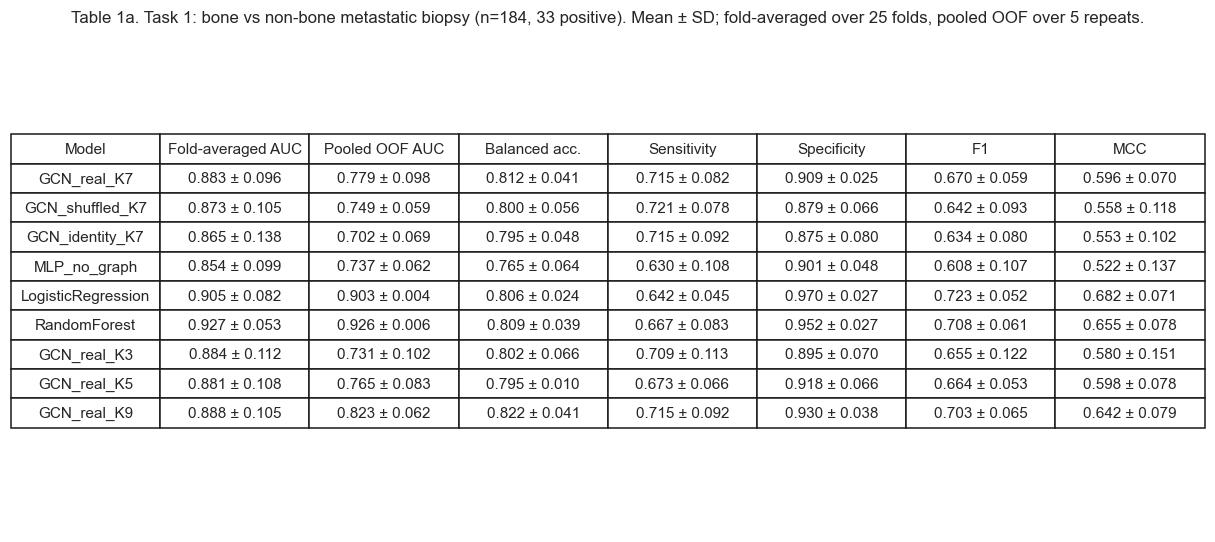

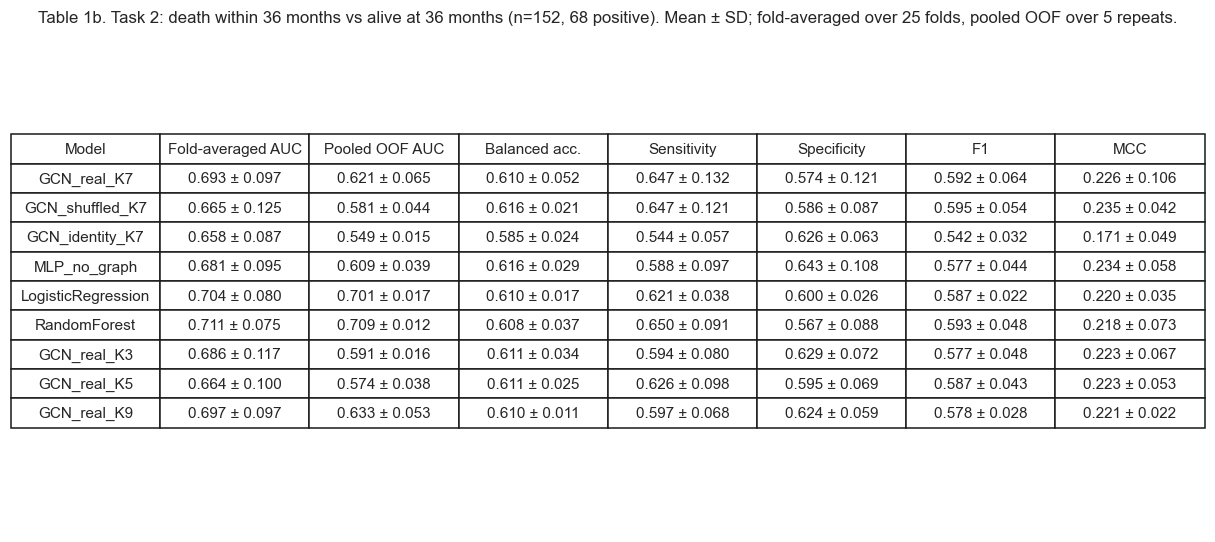

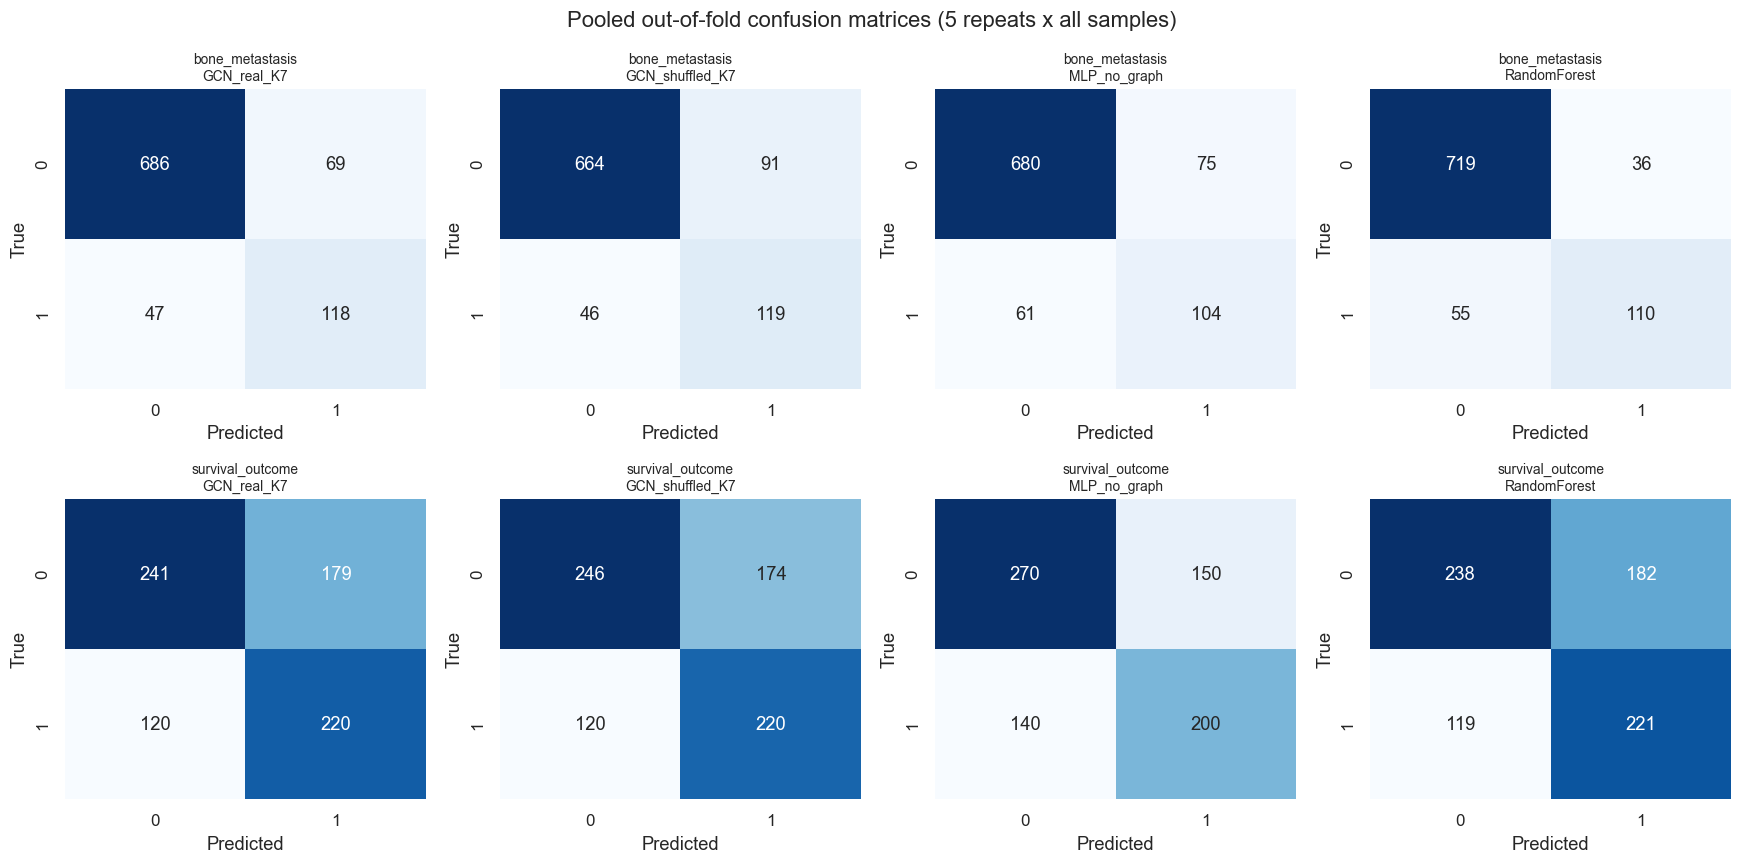

,task,comparison,mean_diff_pooled_OOF_AUC,min_diff,max_diff,repeats_real_better,n_repeats
0,bone_metastasis,GCN_real_K7 minus GCN_shuffled_K7,0.030,-0.039,0.086,4,5
1,bone_metastasis,GCN_real_K7 minus GCN_identity_K7,0.077,-0.059,0.187,3,5
2,bone_metastasis,GCN_real_K7 minus MLP_no_graph,0.042,-0.019,0.160,4,5
3,bone_metastasis,GCN_real_K7 minus LogisticRegression,-0.124,-0.259,0.018,1,5
4,bone_metastasis,GCN_real_K7 minus RandomForest,-0.147,-0.272,-0.009,0,5
5,survival_outcome,GCN_real_K7 minus GCN_shuffled_K7,0.040,-0.046,0.188,3,5
6,survival_outcome,GCN_real_K7 minus GCN_identity_K7,0.072,-0.010,0.172,4,5
7,survival_outcome,GCN_real_K7 minus MLP_no_graph,0.012,-0.097,0.150,2,5
8,survival_outcome,GCN_real_K7 minus LogisticRegression,-0.080,-0.147,0.017,1,5
9,survival_outcome,GCN_real_K7 minus RandomForest,-0.088,-0.141,0.008,1,5



Data-driven wording (paste only what the numbers support):
  [bone_metastasis] real STRING graph vs GCN_shuffled_K7: pooled OOF AUC difference +0.030 (range -0.039 to +0.086); not consistently higher across repeats.
  [bone_metastasis] real STRING graph vs GCN_identity_K7: pooled OOF AUC difference +0.077 (range -0.059 to +0.187); not consistently higher across repeats.
  [bone_metastasis] real STRING graph vs MLP_no_graph: pooled OOF AUC difference +0.042 (range -0.019 to +0.160); not consistently higher across repeats.
  [bone_metastasis] real STRING graph vs LogisticRegression: pooled OOF AUC difference -0.124 (range -0.259 to +0.018); not consistently higher across repeats.
  [bone_metastasis] real STRING graph vs RandomForest: pooled OOF AUC difference -0.147 (range -0.272 to -0.009); not consistently higher across repeats.
  [survival_outcome] real STRING graph vs GCN_shuffled_K7: pooled OOF AUC difference +0.040 (range -0.046 to +0.188); not consistently higher across repeats.


In [36]:
# ============================================================
# 12P-3. Readable Table 1 (split by task), confusion matrices, graph-ablation contrasts  [R5, R10]
# ============================================================
TASK_SHORT = {"bone_metastasis": "Task 1: bone vs non-bone metastatic biopsy",
              "survival_outcome": "Task 2: death within 36 months vs alive at 36 months"}
table_cols = {"model": "Model", "fold_averaged_AUC": "Fold-averaged AUC", "pooled_OOF_AUC": "Pooled OOF AUC",
              "pooled_OOF_balanced_accuracy": "Balanced acc.", "pooled_OOF_sensitivity": "Sensitivity",
              "pooled_OOF_specificity": "Specificity", "pooled_OOF_F1": "F1", "pooled_OOF_MCC": "MCC"}
for t_i, task_name in enumerate(TASKS):
    d = primary_summary[primary_summary.task == task_name]
    tbl = pd.DataFrame({"Model": d["model"]})
    for key, lab in list(table_cols.items())[1:]:
        tbl[lab] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(d[f"{key}_mean"], d[f"{key}_sd"])]
    n_samples = len(TASK_SAMPLE_IDS[task_name]); n_pos = int(TASKS[task_name]["y"].sum())
    tbl.to_csv(f"{OUT_DIR}/Table1{'ab'[t_i]}_{task_name}.csv", index=False)
    fig, ax = plt.subplots(figsize=(14, 0.5 * len(tbl) + 1.4)); ax.axis("off")
    tab = ax.table(cellText=tbl.values, colLabels=tbl.columns, loc="center", cellLoc="center")
    tab.auto_set_font_size(False); tab.set_fontsize(10); tab.scale(1, 1.6)
    ax.set_title(f"Table 1{'ab'[t_i]}. {TASK_SHORT[task_name]} (n={n_samples}, {n_pos} positive). "
                 f"Mean ± SD; fold-averaged over 25 folds, pooled OOF over 5 repeats.", fontsize=11)
    plt.savefig(f"{FIG_DIR}/Table1{'ab'[t_i]}_{task_name}.png", dpi=200, bbox_inches="tight"); plt.show()

# Pooled out-of-fold confusion matrices (all 5 repeats stacked)
cm_models = [m for m in ["GCN_real_K7", "GCN_shuffled_K7", "MLP_no_graph", "RandomForest"] if m in PRIMARY_MODELS]
fig, axes = plt.subplots(len(TASKS), len(cm_models), figsize=(4 * len(cm_models), 4 * len(TASKS)))
for i, task_name in enumerate(TASKS):
    for j, model_name in enumerate(cm_models):
        d = PRIMARY_OOF[(PRIMARY_OOF.task == task_name) & (PRIMARY_OOF.model == model_name)]
        cm = confusion_matrix(d.y_true, d.pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=axes[i, j])
        axes[i, j].set_title(f"{task_name}\n{model_name}", fontsize=9)
        axes[i, j].set_xlabel("Predicted"); axes[i, j].set_ylabel("True")
plt.suptitle("Pooled out-of-fold confusion matrices (5 repeats x all samples)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/primary_oof_confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

# Paired contrasts on identical partitions: does the STRING topology add anything?
contrast_rows = []
for task_name in TASKS:
    def per_rep_auc(model_name):
        d = PRIMARY_OOF[(PRIMARY_OOF.task == task_name) & (PRIMARY_OOF.model == model_name)]
        return d.groupby("repeat").apply(lambda g: roc_auc_score(g.y_true, g.prob))
    base = per_rep_auc("GCN_real_K7")
    for other in ["GCN_shuffled_K7", "GCN_identity_K7", "MLP_no_graph", "LogisticRegression", "RandomForest"]:
        diff = base - per_rep_auc(other)
        contrast_rows.append({"task": task_name, "comparison": f"GCN_real_K7 minus {other}",
                              "mean_diff_pooled_OOF_AUC": diff.mean(), "min_diff": diff.min(), "max_diff": diff.max(),
                              "repeats_real_better": int((diff > 0).sum()), "n_repeats": len(diff)})
graph_contrasts = pd.DataFrame(contrast_rows)
graph_contrasts.to_csv(f"{OUT_DIR}/PRIMARY_graph_ablation_paired_contrasts.csv", index=False)
display(graph_contrasts.round(3))
print("\nData-driven wording (paste only what the numbers support):")
for _, r in graph_contrasts.iterrows():
    consistent = r.repeats_real_better == r.n_repeats and r.min_diff > 0
    verdict = ("higher in every repeat" if consistent
               else "not consistently higher across repeats")
    print(f"  [{r.task}] real STRING graph vs {r.comparison.split('minus ')[1]}: pooled OOF AUC difference "
          f"{r.mean_diff_pooled_OOF_AUC:+.3f} (range {r.min_diff:+.3f} to {r.max_diff:+.3f}); {verdict}.")


In [37]:
# ============================================================
# 12P-4. Threshold-selection audit  [R4]
# ============================================================
# Every Youden threshold in this notebook, and the data it was computed on.
threshold_audit = pd.DataFrame([
    ("Section 12 legacy main CV (cv_results)",            "inner validation split of each training fold", "OK"),
    ("Section 12 strict per-fold variant",                 "inner validation split of each training fold", "OK"),
    ("Section 12P primary evaluation (all models)",        "inner validation split; asserted disjoint from test", "OK"),
    ("Section 13 GLRP explanation split",                  "15% validation split of the 80% training portion", "OK"),
    ("Workstream 1b CV-pooled GLRP",                       "inner validation split (primary partitions, repeat 0)", "OK"),
    ("Item 9 seed-stability retraining",                   "validation split of the explanation split", "OK"),
    ("Legacy ablation (Items 2-4)",                        "inner validation split of each training fold", "OK"),
    ("Legacy K sweep (Item 7)",                            "no threshold (AUC only)", "n/a"),
], columns=["analysis", "threshold computed on", "status"])
display(threshold_audit)

# Empirical check on the primary run: every recorded threshold came from inner validation
assert (PRIMARY_FOLD["threshold_source"] == "inner_validation").all()
print(f"All {len(PRIMARY_FOLD)} primary folds used inner-validation thresholds; held-out fold labels were never "
      "used for threshold or checkpoint selection. No threshold-dependent metric needs rerunning.")
threshold_audit.to_csv(f"{OUT_DIR}/threshold_selection_audit.csv", index=False)


,analysis,threshold computed on,status
0,Section 12 legacy main CV (cv_results),inner validation split of each training fold,OK
1,Section 12 strict per-fold variant,inner validation split of each training fold,OK
2,Section 12P primary evaluation (all models),inner validation split; asserted disjoint from...,OK
3,Section 13 GLRP explanation split,15% validation split of the 80% training portion,OK
4,Workstream 1b CV-pooled GLRP,"inner validation split (primary partitions, re...",OK
5,Item 9 seed-stability retraining,validation split of the explanation split,OK
6,Legacy ablation (Items 2-4),inner validation split of each training fold,OK
7,Legacy K sweep (Item 7),no threshold (AUC only),n/a


All 450 primary folds used inner-validation thresholds; held-out fold labels were never used for threshold or checkpoint selection. No threshold-dependent metric needs rerunning.


In [38]:
# ============================================================
# 12P-5. Chebyshev order K: model-selection evidence  [R5]   (v13)
# ============================================================
# Uses the GCN_real_K3/K5/K7/K9 runs already produced by 12P-2. No retraining.
# Three pieces of evidence:
#   (a) the K sweep on shared partitions, with paired fold-level tests against K=7
#       (Nadeau-Bengio corrected resampled t-test, Holm-adjusted across the 3 comparisons);
#   (b) NESTED K selection: inside every outer fold, K is chosen by inner-validation AUC only,
#       and that fold's test predictions come from the chosen K. This is the honest estimate
#       of "tune K, then predict", and shows how often K=7 is actually chosen;
#   (c) wording printed from the numbers. "Optimal" is never printed.
from itertools import combinations
from scipy import stats as sstats

def nadeau_bengio_ttest(diffs, n_train, n_test):
    """Corrected resampled t-test for repeated k-fold CV (Nadeau & Bengio 2003; Bouckaert & Frank 2004).
    diffs: paired per-fold differences over all repeats x folds. Returns (mean_diff, t, two-sided P)."""
    diffs = np.asarray(diffs, float)
    diffs = diffs[~np.isnan(diffs)]
    J = len(diffs)
    if J < 2:
        return np.nan, np.nan, np.nan
    var = diffs.var(ddof=1)
    if var == 0:
        return float(diffs.mean()), np.nan, np.nan
    t = diffs.mean() / np.sqrt((1.0 / J + n_test / n_train) * var)
    return float(diffs.mean()), float(t), float(2 * sstats.t.sf(abs(t), df=J - 1))

def nadeau_bengio_ci(diffs, n_train, n_test, level=0.95):
    """Confidence interval for the mean paired difference with the same variance correction
    (accounts for the overlap between training sets of repeated CV folds)."""
    diffs = np.asarray(diffs, float); diffs = diffs[~np.isnan(diffs)]
    J = len(diffs)
    if J < 2:
        return np.nan, np.nan
    se = np.sqrt((1.0 / J + n_test / n_train) * diffs.var(ddof=1))
    h = sstats.t.ppf(0.5 + level / 2, df=J - 1) * se
    return float(diffs.mean() - h), float(diffs.mean() + h)

def holm_adjust(pvals):
    """Holm step-down adjustment; NaNs are passed through."""
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.sum() == 0:
        return out
    pv = p[ok]
    order = np.argsort(pv)
    m = len(pv)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * pv[idx]))
        adj[idx] = running
    out[ok] = adj
    return out

K_VALUES_SWEEP = [3, 5, 7, 9]
K_MODELS = {k: f"GCN_real_K{k}" for k in K_VALUES_SWEEP}
_missing = [m for m in K_MODELS.values() if m not in set(PRIMARY_FOLD.model)]
assert not _missing, f"Run 12P-2 with RUN_K_SWEEP = True first; missing models: {_missing}"

k_sweep_rows, k_test_rows, k_selected_rows, k_freq_rows = [], [], [], []
for task_name in TASKS:
    pf = PRIMARY_FOLD[PRIMARY_FOLD.task == task_name]
    po = PRIMARY_OOF[PRIMARY_OOF.task == task_name]
    n_tr = float((pf["n_train"] + pf["n_val"]).mean())   # data the model saw (val used for checkpointing)
    n_te = float(pf["n_test"].mean())

    # (a1) sweep table
    for k, m in K_MODELS.items():
        s = primary_summary[(primary_summary.task == task_name) & (primary_summary.model == m)].iloc[0]
        k_sweep_rows.append({"task": task_name, "K": k,
                             "fold_averaged_AUC_mean": s["fold_averaged_AUC_mean"],
                             "fold_averaged_AUC_sd": s["fold_averaged_AUC_sd"],
                             "pooled_OOF_AUC_mean": s["pooled_OOF_AUC_mean"],
                             "pooled_OOF_AUC_sd": s["pooled_OOF_AUC_sd"],
                             "mean_best_inner_val_AUC": pf[pf.model == m]["best_inner_val_AUC"].mean()})

    # (a2) paired tests vs K=7 on identical folds
    base = pf[pf.model == K_MODELS[7]].set_index(["repeat", "fold"])["AUC"]
    tmp = []
    for k in [3, 5, 9]:
        oth = pf[pf.model == K_MODELS[k]].set_index(["repeat", "fold"])["AUC"].reindex(base.index)
        mean_d, t, p = nadeau_bengio_ttest((oth - base).values, n_tr, n_te)
        ci_lo, ci_hi = nadeau_bengio_ci((oth - base).values, n_tr, n_te)
        per_rep = (po[po.model == K_MODELS[k]].groupby("repeat").apply(lambda g: roc_auc_score(g.y_true, g.prob))
                   - po[po.model == K_MODELS[7]].groupby("repeat").apply(lambda g: roc_auc_score(g.y_true, g.prob)))
        tmp.append({"task": task_name, "comparison": f"K={k} minus K=7",
                    "mean_fold_AUC_diff": mean_d, "CI95_lower": ci_lo, "CI95_upper": ci_hi,
                    "corrected_t": t, "P_corrected": p,
                    "mean_pooled_OOF_AUC_diff": per_rep.mean(),
                    "repeats_K_better_than_K7": int((per_rep > 0).sum()), "n_repeats": len(per_rep)})
    padj = holm_adjust([r["P_corrected"] for r in tmp])
    for r, pa in zip(tmp, padj):
        r["P_Holm"] = pa
    k_test_rows += tmp

    # (b) nested selection: per outer fold, pick K with the highest inner-validation AUC.
    # Ties are broken toward the smaller K (the simpler filter). Test labels are never used.
    kf = pf[pf.model.isin(K_MODELS.values())].copy()
    kf["K"] = kf["model"].str.extract(r"K(\d+)$").astype(int)
    chosen = (kf.sort_values(["repeat", "fold", "best_inner_val_AUC", "K"], ascending=[True, True, False, True])
                .groupby(["repeat", "fold"]).head(1))
    sel_fold = chosen.drop(columns=["K"]).copy()
    sel_oof = pd.concat([po[(po.model == r.model) & (po.repeat == r.repeat) & (po.fold == r.fold)]
                         for r in chosen.itertuples()], ignore_index=True)
    s_sel = summarize_cv(sel_fold, sel_oof)
    k_selected_rows.append({"task": task_name, "model": "GCN_real, K selected per fold (nested)", **s_sel})
    freq = chosen["K"].value_counts().reindex(K_VALUES_SWEEP, fill_value=0)
    for k, n in freq.items():
        k_freq_rows.append({"task": task_name, "K": k, "times_selected": int(n), "n_outer_folds": len(chosen)})
    n_ties = int((kf.groupby(["repeat", "fold"])["best_inner_val_AUC"]
                  .apply(lambda s: (s == s.max()).sum() > 1)).sum())
    print(f"[{task_name}] {n_ties}/{len(chosen)} outer folds had a tie in inner-validation AUC across K "
          f"(small validation sets); ties went to the smaller K.")

k_sweep_table = pd.DataFrame(k_sweep_rows)
k_tests = pd.DataFrame(k_test_rows)
k_nested = pd.DataFrame(k_selected_rows)
k_freq = pd.DataFrame(k_freq_rows)
k_sweep_table.to_csv(f"{PRIMARY_DIR}/K_sweep_primary.csv", index=False)
k_tests.to_csv(f"{PRIMARY_DIR}/K_paired_tests_vs_K7.csv", index=False)
k_nested.to_csv(f"{PRIMARY_DIR}/K_nested_selection_performance.csv", index=False)
k_freq.to_csv(f"{PRIMARY_DIR}/K_nested_selection_frequency.csv", index=False)

print("\nK sweep on shared partitions (fold-internal preprocessing):")
display(k_sweep_table.round(3))
print("\nPaired fold-level tests against K=7 (corrected resampled t-test, Holm across 3 comparisons):")
display(k_tests.round(4))
print("\nNested K selection (K chosen inside each outer fold by inner-validation AUC):")
display(k_nested[["task", "model", "fold_averaged_AUC_mean", "fold_averaged_AUC_sd",
                  "pooled_OOF_AUC_mean", "pooled_OOF_AUC_sd"]].round(3))
display(k_freq.pivot(index="K", columns="task", values="times_selected"))

# (c) wording
print("\nManuscript wording (generated from the tables above):")
for task_name in TASKS:
    sw = k_sweep_table[k_sweep_table.task == task_name].set_index("K")
    kt = k_tests[k_tests.task == task_name]
    nest = k_nested[k_nested.task == task_name].iloc[0]
    fq = k_freq[k_freq.task == task_name].set_index("K")["times_selected"]
    n_outer = int(k_freq[k_freq.task == task_name]["n_outer_folds"].iloc[0])
    lo, hi = sw["pooled_OOF_AUC_mean"].min(), sw["pooled_OOF_AUC_mean"].max()
    better = kt[(kt.P_Holm < 0.05) & (kt.mean_fold_AUC_diff > 0)]
    worse = kt[(kt.P_Holm < 0.05) & (kt.mean_fold_AUC_diff < 0)]
    base_txt = (f"K=7 was fixed a priori, following Paper 2. Across K in {{3, 5, 7, 9}}, pooled out-of-fold AUC "
                f"ranged from {lo:.3f} to {hi:.3f} (K=7: {sw.loc[7, 'pooled_OOF_AUC_mean']:.3f}). "
                f"When K was selected inside each training fold by inner-validation AUC, K=7 was chosen in "
                f"{int(fq.get(7, 0))} of {n_outer} outer folds, and the nested estimate was pooled out-of-fold AUC "
                f"{nest['pooled_OOF_AUC_mean']:.3f} ± {nest['pooled_OOF_AUC_sd']:.3f}.")
    if len(better):
        ks = ", ".join(c.split(" ")[0] for c in better.comparison)
        verdict = (f" {ks} gave significantly higher AUC than K=7 after correction; K=7 must not be described as "
                   f"optimal, and the nested estimate should be reported alongside the K=7 result.")
    elif len(worse) == len(kt):
        verdict = (" K=7 was significantly better than each alternative tested; it can be described as the best "
                   "of the values tested in this cohort (not as optimal in general).")
    else:
        verdict = (" No alternative K differed significantly from K=7 (corrected resampled t-test, Holm-adjusted). "
                   "Performance was therefore insensitive to K over this range, and K=7 should be described as a "
                   "pre-specified choice, not as optimal.")
    print(f"  [{task_name}] {base_txt}{verdict}")


[bone_metastasis] 15/25 outer folds had a tie in inner-validation AUC across K (small validation sets); ties went to the smaller K.
[survival_outcome] 2/25 outer folds had a tie in inner-validation AUC across K (small validation sets); ties went to the smaller K.

K sweep on shared partitions (fold-internal preprocessing):


,task,K,fold_averaged_AUC_mean,fold_averaged_AUC_sd,pooled_OOF_AUC_mean,pooled_OOF_AUC_sd,mean_best_inner_val_AUC
0,bone_metastasis,3,0.884,0.112,0.731,0.102,0.882
1,bone_metastasis,5,0.881,0.108,0.765,0.083,0.901
2,bone_metastasis,7,0.883,0.096,0.779,0.098,0.906
3,bone_metastasis,9,0.888,0.105,0.823,0.062,0.893
4,survival_outcome,3,0.686,0.117,0.591,0.016,0.770
5,survival_outcome,5,0.664,0.100,0.574,0.038,0.784
6,survival_outcome,7,0.693,0.097,0.621,0.065,0.766
7,survival_outcome,9,0.697,0.097,0.633,0.053,0.770



Paired fold-level tests against K=7 (corrected resampled t-test, Holm across 3 comparisons):


,task,comparison,mean_fold_AUC_diff,CI95_lower,CI95_upper,corrected_t,P_corrected,mean_pooled_OOF_AUC_diff,repeats_K_better_than_K7,n_repeats,P_Holm
0,bone_metastasis,K=3 minus K=7,0.0009,-0.0445,0.0464,0.0422,0.9667,-0.0480,0,5,1.0
1,bone_metastasis,K=5 minus K=7,-0.0022,-0.0483,0.0439,-0.0983,0.9225,-0.0144,3,5,1.0
2,bone_metastasis,K=9 minus K=7,0.0056,-0.0483,0.0595,0.2134,0.8329,0.0440,3,5,1.0
3,survival_outcome,K=3 minus K=7,-0.0073,-0.1689,0.1543,-0.0935,0.9263,-0.0304,3,5,1.0
4,survival_outcome,K=5 minus K=7,-0.0298,-0.1605,0.1010,-0.4696,0.6429,-0.0469,1,5,1.0
5,survival_outcome,K=9 minus K=7,0.0038,-0.0853,0.0930,0.0887,0.9301,0.0118,4,5,1.0



Nested K selection (K chosen inside each outer fold by inner-validation AUC):


,task,model,fold_averaged_AUC_mean,fold_averaged_AUC_sd,pooled_OOF_AUC_mean,pooled_OOF_AUC_sd
0,bone_metastasis,"GCN_real, K selected per fold (nested)",0.883,0.113,0.753,0.094
1,survival_outcome,"GCN_real, K selected per fold (nested)",0.677,0.117,0.616,0.082


task,bone_metastasis,survival_outcome
K,,
3,14,6
5,2,9
7,6,5
9,3,5



Manuscript wording (generated from the tables above):
  [bone_metastasis] K=7 was fixed a priori, following Paper 2. Across K in {3, 5, 7, 9}, pooled out-of-fold AUC ranged from 0.731 to 0.823 (K=7: 0.779). When K was selected inside each training fold by inner-validation AUC, K=7 was chosen in 6 of 25 outer folds, and the nested estimate was pooled out-of-fold AUC 0.753 ± 0.094. No alternative K differed significantly from K=7 (corrected resampled t-test, Holm-adjusted). Performance was therefore insensitive to K over this range, and K=7 should be described as a pre-specified choice, not as optimal.
  [survival_outcome] K=7 was fixed a priori, following Paper 2. Across K in {3, 5, 7, 9}, pooled out-of-fold AUC ranged from 0.574 to 0.633 (K=7: 0.621). When K was selected inside each training fold by inner-validation AUC, K=7 was chosen in 5 of 25 outer folds, and the nested estimate was pooled out-of-fold AUC 0.616 ± 0.082. No alternative K differed significantly from K=7 (corrected r

Shuffled-graph fits will run on: cpu
Paired uncertainty table, real STRING graph vs comparators. Same held-out folds for every model; the 95% CI and P use the Nadeau-Bengio correction for overlapping training sets across repeated CV; P is Holm-adjusted within task:


,task,comparison,mean_fold_AUC_diff,CI95_lower,CI95_upper,P_corrected,P_Holm,folds_real_better,n_folds
0,bone_metastasis,GCN_real_K7 minus GCN_shuffled_K7,0.0096,-0.0420,0.0611,0.7045,1.0,12,25
1,bone_metastasis,GCN_real_K7 minus GCN_identity_K7,0.0178,-0.0688,0.1044,0.6752,1.0,12,25
2,bone_metastasis,GCN_real_K7 minus MLP_no_graph,0.0285,-0.0333,0.0904,0.3507,1.0,18,25
3,bone_metastasis,GCN_real_K7 minus LogisticRegression,-0.0219,-0.0943,0.0506,0.5392,1.0,9,25
4,bone_metastasis,GCN_real_K7 minus RandomForest,-0.0448,-0.1186,0.0290,0.2226,1.0,6,25
5,survival_outcome,GCN_real_K7 minus GCN_shuffled_K7,0.0279,-0.1484,0.2042,0.7465,1.0,12,25
6,survival_outcome,GCN_real_K7 minus GCN_identity_K7,0.0353,-0.1013,0.1720,0.5983,1.0,16,25
7,survival_outcome,GCN_real_K7 minus MLP_no_graph,0.0127,-0.1433,0.1687,0.8679,1.0,14,25
8,survival_outcome,GCN_real_K7 minus LogisticRegression,-0.0108,-0.1377,0.1161,0.8615,1.0,12,25
9,survival_outcome,GCN_real_K7 minus RandomForest,-0.0176,-0.1260,0.0908,0.7411,1.0,12,25


Parity check (1 fold, same seed): max |prob diff| sparse vs fast = 0.00e+00; time 4.9s -> 1.3s per fit

Degree-preserving shuffles keep, on average, 27.7% of the real STRING edges (lower = more thoroughly randomized).


  [1/38] bone_metastasis | GCN_shuffled_s1_K7: 37s (elapsed 0.6 min, ETA 23.0 min)


  [2/38] bone_metastasis | GCN_shuffled_s2_K7: 37s (elapsed 1.2 min, ETA 22.3 min)


...

  [37/38] survival_outcome | GCN_shuffled_s18_K7: 31s (elapsed 22.9 min, ETA 0.6 min)


  [38/38] survival_outcome | GCN_shuffled_s19_K7: 31s (elapsed 23.4 min, ETA 0.0 min)


,task,repeats_used,full_primary_evaluation,real_graph_pooled_OOF_AUC,shuffled_graphs_n,shuffled_mean,shuffled_sd,shuffled_min,shuffled_max,n_shuffled_at_or_above_real,empirical_P_one_sided,smallest_attainable_P
0,bone_metastasis,"[0, 1, 2, 3, 4]",True,0.7792,20,0.7765,0.0343,0.7028,0.8439,8,0.4286,0.0476
1,survival_outcome,"[0, 1, 2, 3, 4]",True,0.6212,20,0.5985,0.0185,0.5729,0.6440,2,0.1429,0.0476


Real graph vs shuffled graphs, repeat by repeat:


,task,repeat,real_graph_AUC,n_shuffled,n_shuffled_at_or_above_real,empirical_P_this_repeat
0,bone_metastasis,0,0.6478,20,15,0.7619
1,bone_metastasis,1,0.7419,20,8,0.4286
2,bone_metastasis,2,0.8108,20,5,0.2857
3,bone_metastasis,3,0.9157,20,0,0.0476
4,bone_metastasis,4,0.7799,20,9,0.4762
5,survival_outcome,0,0.5620,20,17,0.8571
6,survival_outcome,1,0.5844,20,14,0.7143
7,survival_outcome,2,0.5797,20,16,0.8095
8,survival_outcome,3,0.6689,20,0,0.0476
9,survival_outcome,4,0.7110,20,0,0.0476


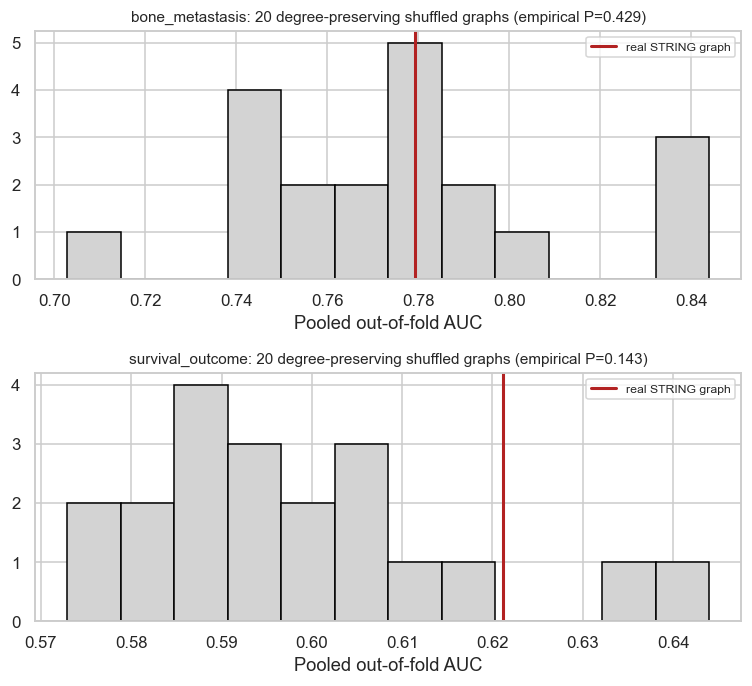


Manuscript wording (generated from the numbers):
  [bone_metastasis] (all primary repeats) In this cohort, there was no evidence that the specific STRING topology improved prediction beyond a degree-matched random graph (real pooled OOF AUC 0.779; shuffled graphs 0.703-0.844, 8 of 20 at or above the real graph; empirical P=0.429; paired corrected test vs the seed-0 shuffle P_Holm=1). Versus identity adjacency (no propagation), no significant difference (mean +0.018, p_holm=1); versus an mlp without graph structure, no significant difference (mean +0.029, p_holm=1).
    The real graph ranked above every shuffled graph in 1 of 5 repeats.
  [survival_outcome] (all primary repeats) In this cohort, there was no evidence that the specific STRING topology improved prediction beyond a degree-matched random graph (real pooled OOF AUC 0.621; shuffled graphs 0.573-0.644, 2 of 20 at or above the real graph; empirical P=0.143; paired corrected test vs the seed-0 shuffle P_Holm=1). Versus identity 

In [39]:
# ============================================================
# 12P-6. Graph-topology ablation: corrected paired tests + a distribution of shuffled graphs  [R5]   (v13)
# ============================================================
# Needs 12P-5 (for nadeau_bengio_ttest and holm_adjust).
# (a) Corrected paired tests of GCN_real_K7 against every comparator, on identical folds.
# (b) One shuffled graph (12P-1, seed 0) is a single draw from the null. This cell adds
#     N_EXTRA_SHUFFLED_GRAPHS more degree-preserving shuffles (seeds 1..N), trains each through the
#     same engine on the same partitions, and asks where the real STRING graph ranks.
#     With S shuffled graphs in total, the smallest attainable empirical P is 1/(S+1):
#     19 extra graphs (20 in total) are needed before P can go below 0.05.
# Runtime: N_EXTRA_SHUFFLED_GRAPHS x len(SHUFFLE_NULL_REPEATS) x 5 folds x 2 tasks network fits (950 by default).
# v14.1 speed-up (same models, same seeds, same checkpoints):
#   - the shuffled-graph operators are stored as DENSE matrices; dense matmul is several times faster on CPU than
#     torch.sparse.mm for a graph this dense (sparse vs dense predictions agree to ~1e-7);
#   - if a GPU runtime is available, the shuffled-graph fits run on it (USE_GPU_IF_AVAILABLE);
#   - checkpoints already written by the slower v14 cell are reused (same fingerprint), so interrupted work is kept;
#   - progress with an ETA is printed after every graph.
# If compute is short, set SHUFFLE_NULL_REPEATS = [0, 1, 2] and report it as a 3-repeat SENSITIVITY analysis.
assert all(f in globals() for f in ["nadeau_bengio_ttest", "nadeau_bengio_ci", "holm_adjust"]), "Run 12P-5 first."

RUN_SHUFFLE_NULL = True
N_EXTRA_SHUFFLED_GRAPHS = 19
SHUFFLE_NULL_REPEATS = list(range(N_REPEATS_PRIMARY))   # [0, 1, 2] = cheaper, label as sensitivity analysis
SHUFFLE_NULL_IS_FULL = sorted(SHUFFLE_NULL_REPEATS) == list(range(N_REPEATS_PRIMARY))
USE_GPU_IF_AVAILABLE = True
PARITY_CHECK = True            # one fold, sparse vs dense, same seed -> confirms the speed-up does not change results

# ---------- speed-up plumbing ----------
def cheb_filter(L_hat, x, K):
    """Same Chebyshev recursion as Section 9; a dense operator uses ordinary matmul. Sparse path unchanged."""
    B, N_, Fin = x.shape
    def apply_L(t):
        flat = t.permute(1, 0, 2).reshape(N_, B * Fin)
        out = torch.sparse.mm(L_hat, flat) if L_hat.is_sparse else L_hat @ flat
        return out.reshape(N_, B, Fin).permute(1, 0, 2)
    xs = [x]
    if K > 1:
        xs.append(apply_L(xs[-1]))
    for k in range(2, K):
        xs.append(2 * apply_L(xs[-1]) - xs[-2])
    return torch.stack(xs, dim=0)

GRAPH_HASH_SOURCE = globals().get("GRAPH_HASH_SOURCE", {})   # graph key -> sparse operator used for the fingerprint
def _graph_hash(graph_key):
    if graph_key is None:
        return None
    L = GRAPH_HASH_SOURCE.get(graph_key, GRAPH_OPERATORS[graph_key])
    L = L.to_sparse().coalesce() if not L.is_sparse else L.coalesce()
    return hashlib.sha1(L.indices().cpu().numpy().tobytes() + np.round(L.values().cpu().numpy(), 6).tobytes()).hexdigest()

_DENSE_OPS = {}
FAST_DEVICE = torch.device("cuda" if (USE_GPU_IF_AVAILABLE and torch.cuda.is_available()) else "cpu")
print(f"Shuffled-graph fits will run on: {FAST_DEVICE}")

def _fit_predict_fast(model_name, Xtr, ytr, Xva, yva, Xte, seed, n_epochs=N_EPOCHS_PRIMARY, batch_size=16, lr=5e-4):
    """fit_predict for GCN models with a dense operator, optionally on GPU. Same training loop as _fit_nn."""
    family, graph, K = PRIMARY_MODELS[model_name]
    dev = FAST_DEVICE
    if graph not in _DENSE_OPS:
        op = GRAPH_OPERATORS[graph]
        _DENSE_OPS[graph] = op.to_dense() if op.is_sparse else op
    L_op = _DENSE_OPS[graph].to(dev)
    torch.manual_seed(seed); np.random.seed(seed)
    model = GraphCNN(N, K=K).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr, device=dev), torch.tensor(ytr, device=dev)
    Xva_t, Xte_t = torch.tensor(Xva, device=dev), torch.tensor(Xte, device=dev)
    best_auc, best_state = -1, None
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))                     # CPU generator, same order as the engine
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size].to(dev)
            opt.zero_grad()
            loss = lossf(model(L_op, Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(L_op, Xva_t), dim=1)[:, 1].cpu().numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc = auc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        va = torch.softmax(model(L_op, Xva_t), 1)[:, 1].cpu().numpy()
        te = torch.softmax(model(L_op, Xte_t), 1)[:, 1].cpu().numpy()
    return model.cpu(), va, te, best_auc

_fit_predict_engine = globals().get("_fit_predict_engine", fit_predict)   # keep the original engine function
FAST_MODELS = set()
def fit_predict(model_name, Xtr, ytr, Xva, yva, Xte, seed):
    if model_name in FAST_MODELS:
        return _fit_predict_fast(model_name, Xtr, ytr, Xva, yva, Xte, seed)
    return _fit_predict_engine(model_name, Xtr, ytr, Xva, yva, Xte, seed)

# ---------- (a) corrected paired tests ----------
TOPO_COMPARATORS = [m for m in ["GCN_shuffled_K7", "GCN_identity_K7", "MLP_no_graph", "LogisticRegression",
                                "RandomForest"] if m in set(PRIMARY_FOLD.model)]
topo_rows = []
for task_name in TASKS:
    pf = PRIMARY_FOLD[PRIMARY_FOLD.task == task_name]
    n_tr = float((pf["n_train"] + pf["n_val"]).mean()); n_te = float(pf["n_test"].mean())
    base = pf[pf.model == "GCN_real_K7"].set_index(["repeat", "fold"])["AUC"]
    tmp = []
    for other in TOPO_COMPARATORS:
        oth = pf[pf.model == other].set_index(["repeat", "fold"])["AUC"].reindex(base.index)
        d = (base - oth).values
        mean_d, t, p = nadeau_bengio_ttest(d, n_tr, n_te)
        ci_lo, ci_hi = nadeau_bengio_ci(d, n_tr, n_te)
        tmp.append({"task": task_name, "comparison": f"GCN_real_K7 minus {other}", "mean_fold_AUC_diff": mean_d,
                    "CI95_lower": ci_lo, "CI95_upper": ci_hi,
                    "folds_real_better": int(np.nansum(d > 0)), "n_folds": int(np.sum(~np.isnan(d))),
                    "corrected_t": t, "P_corrected": p})
    for r, pa in zip(tmp, holm_adjust([r["P_corrected"] for r in tmp])):
        r["P_Holm"] = pa
    topo_rows += tmp
topo_tests = pd.DataFrame(topo_rows)
topo_tests.to_csv(f"{PRIMARY_DIR}/topology_paired_tests_corrected.csv", index=False)
print("Paired uncertainty table, real STRING graph vs comparators. Same held-out folds for every model; the 95% CI "
      "and P use the Nadeau-Bengio correction for overlapping training sets across repeated CV; P is Holm-adjusted "
      "within task:")
display(topo_tests[["task", "comparison", "mean_fold_AUC_diff", "CI95_lower", "CI95_upper", "P_corrected", "P_Holm",
                    "folds_real_better", "n_folds"]].round(4))

# ---------- (b) distribution of shuffled graphs ----------
real_edges = {frozenset(e) for e in G_main.edges()}
def _edge_overlap(G):
    e = {frozenset(x) for x in G.edges()}
    return len(e & real_edges) / max(len(real_edges), 1)

null_models = ["GCN_shuffled_K7"]
overlap_rows = [{"graph": "shuffled (seed 0, 12P-1)", "fraction_real_edges_retained": _edge_overlap(G_shuffled_primary)}]
if RUN_SHUFFLE_NULL:
    for s in range(1, N_EXTRA_SHUFFLED_GRAPHS + 1):
        Gs = G_main.copy()
        nx.double_edge_swap(Gs, nswap=int(2.5 * Gs.number_of_edges()),
                            max_tries=int(50 * Gs.number_of_edges()), seed=s)
        assert dict(Gs.degree()) == dict(G_main.degree()), "degree sequence changed"
        _sp_op = scipy_to_torch_sparse(normalized_laplacian(nx.to_scipy_sparse_array(Gs, nodelist=gene_list, format="csr")))
        GRAPH_HASH_SOURCE[f"shuffled_s{s}"] = _sp_op          # fingerprint identical to the v14 checkpoints
        GRAPH_OPERATORS[f"shuffled_s{s}"] = _sp_op.to_dense()  # dense operator for speed
        name = f"GCN_shuffled_s{s}_K7"
        PRIMARY_MODELS[name] = ("gcn", f"shuffled_s{s}", 7)
        MODEL_INDEX.setdefault(name, len(MODEL_INDEX))   # appended -> existing models' seeds are unchanged
        null_models.append(name)
        FAST_MODELS.add(name)
        overlap_rows.append({"graph": f"shuffled (seed {s})", "fraction_real_edges_retained": _edge_overlap(Gs)})
    if PARITY_CHECK:
        _tn = list(TASKS)[0]; _p = PRIMARY_PARTITIONS[_tn][0]; _lab = PRIMARY_LABELS[_tn]
        _Xtr, _ = prep_fold(_p["train"], _p["train"]); _Xva, _ = prep_fold(_p["train"], _p["val"])
        _Xte, _ = prep_fold(_p["train"], _p["test"])
        _args = (_Xtr, _lab.loc[_p["train"]].to_numpy(), _Xva, _lab.loc[_p["val"]].to_numpy(), _Xte, 12345)
        _t0 = time.time(); GRAPH_OPERATORS["_parity"] = GRAPH_HASH_SOURCE["shuffled_s1"]
        PRIMARY_MODELS["_parity"] = ("gcn", "_parity", 7)
        _, _, te_sparse, _ = _fit_predict_engine("_parity", *_args); _t_sparse = time.time() - _t0
        GRAPH_OPERATORS["_parity"] = GRAPH_OPERATORS["shuffled_s1"]
        _t0 = time.time(); _, _, te_dense, _ = _fit_predict_fast("_parity", *_args); _t_dense = time.time() - _t0
        del GRAPH_OPERATORS["_parity"], PRIMARY_MODELS["_parity"]; _DENSE_OPS.pop("_parity", None)
        print(f"Parity check (1 fold, same seed): max |prob diff| sparse vs fast = "
              f"{np.abs(te_sparse - te_dense).max():.2e}; time {_t_sparse:.1f}s -> {_t_dense:.1f}s per fit")
edge_overlap_df = pd.DataFrame(overlap_rows)
print(f"\nDegree-preserving shuffles keep, on average, {edge_overlap_df.fraction_real_edges_retained.mean():.1%} "
      f"of the real STRING edges (lower = more thoroughly randomized).")

def _per_repeat_pooled_auc(oof):
    return oof.groupby("repeat").apply(lambda g: roc_auc_score(g.y_true, g.prob))

null_rows, null_summary_rows, null_rank_rows = [], [], []
_n_jobs = len(TASKS) * (len(null_models) - 1)
_job, _t_start = 0, time.time()
for task_name in TASKS:
    parts = [p for p in PRIMARY_PARTITIONS[task_name] if p["repeat"] in SHUFFLE_NULL_REPEATS]
    po = PRIMARY_OOF[PRIMARY_OOF.task == task_name]
    real = _per_repeat_pooled_auc(po[(po.model == "GCN_real_K7") & po.repeat.isin(SHUFFLE_NULL_REPEATS)])
    for name in null_models:
        if name == "GCN_shuffled_K7":
            oof = po[(po.model == name) & po.repeat.isin(SHUFFLE_NULL_REPEATS)]
        else:
            _t_job = time.time()
            _, oof = run_cv(task_name, name, parts, PRIMARY_LABELS[task_name], ckpt_prefix=task_name, verbose=False)
            _job += 1
            _el = time.time() - _t_start
            print(f"  [{_job}/{_n_jobs}] {task_name} | {name}: {time.time() - _t_job:.0f}s "
                  f"(elapsed {_el / 60:.1f} min, ETA {_el / _job * (_n_jobs - _job) / 60:.1f} min)", flush=True)
        for r, auc in _per_repeat_pooled_auc(oof).items():
            null_rows.append({"task": task_name, "graph_model": name, "repeat": r, "pooled_OOF_AUC": auc})
    nd = pd.DataFrame([x for x in null_rows if x["task"] == task_name])
    null_means = nd.groupby("graph_model")["pooled_OOF_AUC"].mean()
    real_mean = real.mean()
    S = len(null_means)
    p_emp = (1 + int((null_means >= real_mean).sum())) / (S + 1)
    # per-repeat rank of the real graph among the shuffled graphs (does any advantage reproduce across repeats?)
    for r in sorted(nd.repeat.unique()):
        null_r = nd[nd.repeat == r]["pooled_OOF_AUC"]
        null_rank_rows.append({"task": task_name, "repeat": int(r), "real_graph_AUC": real.loc[r],
                               "n_shuffled": len(null_r), "n_shuffled_at_or_above_real": int((null_r >= real.loc[r]).sum()),
                               "empirical_P_this_repeat": (1 + int((null_r >= real.loc[r]).sum())) / (len(null_r) + 1)})
    null_summary_rows.append({"task": task_name, "repeats_used": str(SHUFFLE_NULL_REPEATS),
                              "full_primary_evaluation": SHUFFLE_NULL_IS_FULL,
                              "real_graph_pooled_OOF_AUC": real_mean,
                              "shuffled_graphs_n": S, "shuffled_mean": null_means.mean(),
                              "shuffled_sd": null_means.std(ddof=1) if S > 1 else np.nan,
                              "shuffled_min": null_means.min(), "shuffled_max": null_means.max(),
                              "n_shuffled_at_or_above_real": int((null_means >= real_mean).sum()),
                              "empirical_P_one_sided": p_emp, "smallest_attainable_P": 1 / (S + 1)})
shuffle_null_df = pd.DataFrame(null_rows)
shuffle_null_summary = pd.DataFrame(null_summary_rows)
shuffle_null_df.to_csv(f"{PRIMARY_DIR}/topology_shuffled_graph_null_per_repeat.csv", index=False)
shuffle_null_summary.to_csv(f"{PRIMARY_DIR}/topology_shuffled_graph_null_summary.csv", index=False)
edge_overlap_df.to_csv(f"{PRIMARY_DIR}/topology_shuffled_edge_overlap.csv", index=False)
shuffle_null_ranks = pd.DataFrame(null_rank_rows)
shuffle_null_ranks.to_csv(f"{PRIMARY_DIR}/topology_shuffled_graph_null_rank_per_repeat.csv", index=False)
display(shuffle_null_summary.round(4))
print("Real graph vs shuffled graphs, repeat by repeat:")
display(shuffle_null_ranks.round(4))

fig, axes = plt.subplots(len(TASKS), 1, figsize=(7, 3.2 * len(TASKS)))
axes = np.atleast_1d(axes)
for ax, task_name in zip(axes, TASKS):
    nd = shuffle_null_df[shuffle_null_df.task == task_name].groupby("graph_model")["pooled_OOF_AUC"].mean()
    s = shuffle_null_summary[shuffle_null_summary.task == task_name].iloc[0]
    ax.hist(nd.values, bins=min(12, max(3, len(nd))), color="lightgrey", edgecolor="black")
    ax.axvline(s.real_graph_pooled_OOF_AUC, color="firebrick", lw=2, label="real STRING graph")
    ax.set_title(f"{task_name}: {int(s.shuffled_graphs_n)} degree-preserving shuffled graphs "
                 f"(empirical P={s.empirical_P_one_sided:.3f})", fontsize=10)
    ax.set_xlabel("Pooled out-of-fold AUC"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/topology_shuffled_graph_null.png", dpi=200, bbox_inches="tight"); plt.show()

print("\nManuscript wording (generated from the numbers):")
for task_name in TASKS:
    s = shuffle_null_summary[shuffle_null_summary.task == task_name].iloc[0]
    tt = topo_tests[topo_tests.task == task_name].set_index("comparison")
    shuf = tt.loc["GCN_real_K7 minus GCN_shuffled_K7"]
    ident = tt.loc["GCN_real_K7 minus GCN_identity_K7"] if "GCN_real_K7 minus GCN_identity_K7" in tt.index else None
    mlp = tt.loc["GCN_real_K7 minus MLP_no_graph"] if "GCN_real_K7 minus MLP_no_graph" in tt.index else None
    topo_supported = (s.empirical_P_one_sided < 0.05) and (shuf.P_Holm < 0.05) and (shuf.mean_fold_AUC_diff > 0)
    if topo_supported:
        txt = (f"the STRING topology outperformed degree-preserving shuffled graphs (real pooled OOF AUC "
               f"{s.real_graph_pooled_OOF_AUC:.3f} vs {s.shuffled_mean:.3f} ± {s.shuffled_sd:.3f} across "
               f"{int(s.shuffled_graphs_n)} shuffled graphs; empirical P={s.empirical_P_one_sided:.3f}).")
    else:
        txt = (f"there was no evidence that the specific STRING topology improved prediction beyond a degree-matched "
               f"random graph (real pooled OOF AUC {s.real_graph_pooled_OOF_AUC:.3f}; shuffled graphs "
               f"{s.shuffled_min:.3f}-{s.shuffled_max:.3f}, {int(s.n_shuffled_at_or_above_real)} of "
               f"{int(s.shuffled_graphs_n)} at or above the real graph; empirical P={s.empirical_P_one_sided:.3f}; "
               f"paired corrected test vs the seed-0 shuffle P_Holm={shuf.P_Holm:.3g}).")
    extra = []
    for lab, r in [("identity adjacency (no propagation)", ident), ("an MLP without graph structure", mlp)]:
        if r is None:
            continue
        if r.P_Holm < 0.05:
            extra.append(f"versus {lab}, the real graph was {'better' if r.mean_fold_AUC_diff > 0 else 'worse'} "
                         f"(mean fold AUC difference {r.mean_fold_AUC_diff:+.3f}, P_Holm={r.P_Holm:.3g})")
        else:
            extra.append(f"versus {lab}, no significant difference (mean {r.mean_fold_AUC_diff:+.3f}, "
                         f"P_Holm={r.P_Holm:.3g})")
    scope = ("all primary repeats" if SHUFFLE_NULL_IS_FULL
             else f"repeats {SHUFFLE_NULL_REPEATS} only -- a SENSITIVITY analysis, not the full primary evaluation")
    rk = shuffle_null_ranks[shuffle_null_ranks.task == task_name]
    print(f"  [{task_name}] ({scope}) In this cohort, {txt} " + ("; ".join(extra).capitalize() + "." if extra else ""))
    print(f"    The real graph ranked above every shuffled graph in {int((rk.n_shuffled_at_or_above_real == 0).sum())} "
          f"of {len(rk)} repeats.")
    if s.smallest_attainable_P >= 0.05:
        print(f"    NOTE: with {int(s.shuffled_graphs_n)} shuffled graphs the smallest attainable P is "
              f"{s.smallest_attainable_P:.3f}; raise N_EXTRA_SHUFFLED_GRAPHS to >= 19 before reporting a P value.")


Graph structure (same 737-gene node set throughout):


,graph,n_genes,n_edges,mean_degree,median_degree,density,isolated_genes,n_connected_components,fraction_reachable_in_K-1=6_hops,fraction_reachable_in_2_hops
0,STRING>=400 (primary),737,19902,54.0081,36.0,0.0734,0,1,1.0000,0.6649
1,shuffled (seed 0),737,19902,54.0081,36.0,0.0734,0,1,1.0000,0.8188
2,STRING>=700,737,6231,16.9091,10.0,0.0230,80,85,0.7632,0.2134
3,STRING>=900,737,2603,7.0638,4.0,0.0096,172,181,0.5315,0.0665
4,identity (no edges),737,0,0.0000,0.0,0.0000,737,737,0.0000,0.0000


  bone_metastasis | GCN_string700_K7: done (elapsed 0.6 min)


  bone_metastasis | GCN_string900_K7: done (elapsed 1.2 min)


  survival_outcome | GCN_string700_K7: done (elapsed 1.7 min)


  survival_outcome | GCN_string900_K7: done (elapsed 2.3 min)



Performance vs graph density (repeats [0, 1, 2, 3, 4], shared partitions):


,task,graph,model,n_edges,mean_degree,density,reach_6_hops,pooled_OOF_AUC_mean,pooled_OOF_AUC_sd,fold_averaged_AUC_mean
0,bone_metastasis,STRING>=400 (primary),GCN_real_K7,19902.0,54.0081,0.0734,1.0000,0.7792,0.0978,0.8827
1,bone_metastasis,shuffled (seed 0),GCN_shuffled_K7,19902.0,54.0081,0.0734,1.0000,0.7488,0.0586,0.8731
2,bone_metastasis,identity (no edges),GCN_identity_K7,0.0,0.0000,0.0000,0.0000,0.7021,0.0693,0.8649
3,bone_metastasis,STRING>=700,GCN_string700_K7,6231.0,16.9091,0.0230,0.7632,0.8079,0.0423,0.8914
4,bone_metastasis,STRING>=900,GCN_string900_K7,2603.0,7.0638,0.0096,0.5315,0.7546,0.0837,0.8936
5,survival_outcome,STRING>=400 (primary),GCN_real_K7,19902.0,54.0081,0.0734,1.0000,0.6212,0.0650,0.6933
6,survival_outcome,shuffled (seed 0),GCN_shuffled_K7,19902.0,54.0081,0.0734,1.0000,0.5811,0.0441,0.6654
7,survival_outcome,identity (no edges),GCN_identity_K7,0.0,0.0000,0.0000,0.0000,0.5492,0.0151,0.6580
8,survival_outcome,STRING>=700,GCN_string700_K7,6231.0,16.9091,0.0230,0.7632,0.5554,0.0180,0.6764
9,survival_outcome,STRING>=900,GCN_string900_K7,2603.0,7.0638,0.0096,0.5315,0.5771,0.0293,0.6454


Paired, corrected comparisons with the primary STRING>=400 graph:


,task,comparison,mean_fold_AUC_diff,CI95_lower,CI95_upper,P_corrected,P_Holm
0,bone_metastasis,STRING>=700 minus STRING>=400,0.0087,-0.0428,0.0602,0.7307,0.9823
1,bone_metastasis,STRING>=900 minus STRING>=400,0.0108,-0.0212,0.0429,0.4912,0.9823
2,survival_outcome,STRING>=700 minus STRING>=400,-0.0169,-0.1733,0.1395,0.8253,0.8349
3,survival_outcome,STRING>=900 minus STRING>=400,-0.0479,-0.1678,0.0719,0.4175,0.8349


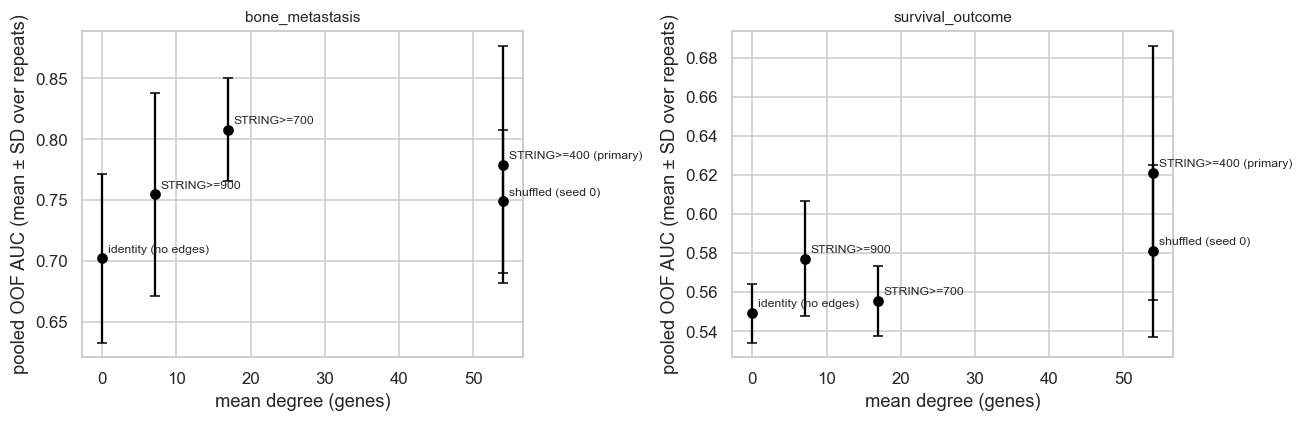


Oversmoothing diagnostic (repeat 0, folds [0, 1, 2, 3, 4]; held-out samples): mean |gene-gene correlation| across samples at the input and after each layer (closer to 1 = genes carry a more common signal):


,task,graph,gene_corr_input,gene_corr_layer1,gene_corr_layer2,layer2_minus_input,constant_gene_fraction_L2,mean_degree
3,bone_metastasis,identity (no edges),0.2489,0.2489,0.2489,0.0000,0.0000,0.0000
2,bone_metastasis,STRING>=900,0.2489,0.3774,0.2324,-0.0165,0.0076,7.0638
1,bone_metastasis,STRING>=700,0.2489,0.4742,0.2705,0.0216,0.0217,16.9091
0,bone_metastasis,STRING>=400 (primary),0.2489,0.3635,0.2679,0.0190,0.0318,54.0081
4,bone_metastasis,shuffled (seed 0),0.2489,0.4424,0.2588,0.0099,0.0000,54.0081
8,survival_outcome,identity (no edges),0.2275,0.2275,0.2275,-0.0000,0.0000,0.0000
7,survival_outcome,STRING>=900,0.2275,0.3058,0.2342,0.0066,0.0003,7.0638
6,survival_outcome,STRING>=700,0.2275,0.3896,0.2770,0.0494,0.0217,16.9091
5,survival_outcome,STRING>=400 (primary),0.2275,0.2900,0.2345,0.0069,0.0201,54.0081
9,survival_outcome,shuffled (seed 0),0.2275,0.3657,0.2537,0.0262,0.0000,54.0081



Manuscript wording (generated):
  [bone_metastasis] At STRING >= 400 a K=7 filter can reach 100% of genes from a typical gene. Sparser, higher-confidence graphs did not change performance significantly (STRING>=700 minus STRING>=400: ΔAUC +0.009, 95% CI -0.043 to +0.060; STRING>=900 minus STRING>=400: ΔAUC +0.011, 95% CI -0.021 to +0.043). Mean |gene-gene correlation| rose from 0.25 at the input to 0.27 after layer 2 on the primary graph (identity graph: 0.25); descriptive diagnostic, not a test.
  [survival_outcome] At STRING >= 400 a K=7 filter can reach 100% of genes from a typical gene. Sparser, higher-confidence graphs did not change performance significantly (STRING>=700 minus STRING>=400: ΔAUC -0.017, 95% CI -0.173 to +0.139; STRING>=900 minus STRING>=400: ΔAUC -0.048, 95% CI -0.168 to +0.072). Mean |gene-gene correlation| rose from 0.23 at the input to 0.23 after layer 2 on the primary graph (identity graph: 0.23); descriptive diagnostic, not a test.


In [40]:
# ============================================================
# 12P-7. Graph density, STRING confidence threshold, and propagation / oversmoothing diagnostics  [R5]   (v14)
# ============================================================
# Question: is the STRING >= 400 graph so dense that K=7 Chebyshev filtering mixes almost every gene with
# almost every other gene, washing out the topology? Three parts:
#   (a) STRING confidence sensitivity: graphs at combined_score >= 700 and >= 900 built on the SAME gene_list
#       (genes left without edges stay in, as isolated nodes), so only the topology changes, not the features.
#       Trained through the primary engine on the shared partitions -> paired, corrected comparisons with >= 400.
#   (b) Structure table for every graph used: edges, mean degree, density, isolated genes, and how much of the
#       graph a K=7 filter can reach (Chebyshev order K mixes information over K-1 hops).
#   (c) Oversmoothing: models re-fit with the engine's repeat-0 seeds (identical to its repeat-0 fits). Each gene's
#       representation after a layer is summarised per sample (mean over channels); the mean |correlation| ACROSS
#       SAMPLES between genes is compared with the same quantity for the raw input. If propagation mixes genes into a
#       common signal, gene-gene correlation rises toward 1 (oversmoothing). The identity graph shows the no-mixing level.
#       (Cosine-distance MAD is not used: with one input value per gene, layer-1 embeddings are near-colinear by
#       construction, so MAD would be low even without any mixing.)
# Runtime: (a) 2 graphs x len(DENSITY_REPEATS) x 5 folds x 2 tasks (all repeats = 100 fits, ~35 min);
#          (c) len(DIAG_GRAPHS) x len(DIAG_FOLDS) x 2 tasks (default 5 x 5 x 2 = 50 fits, ~20 min).
assert all(f in globals() for f in ["nadeau_bengio_ttest", "nadeau_bengio_ci", "holm_adjust"]), "Run 12P-5 first."
assert "_fit_predict_fast" in globals(), "Run 12P-6 first (defines the fast dense/GPU training path)."
from collections import deque

STRING_THRESHOLDS_EXTRA = [700, 900]       # 400 is the primary graph (GCN_real_K7)
DENSITY_REPEATS = list(range(N_REPEATS_PRIMARY))
RUN_OVERSMOOTHING_DIAG = True
DIAG_FOLDS = list(range(N_FOLDS_PRIMARY))   # repeat 0 folds used for the representation diagnostics

# ---------- (a) graphs at higher STRING confidence, same nodes ----------
assert "links_hc" in globals(), "links_hc (STRING links, score >= 400) from Section 2.2 is needed."
gene_set_ = set(gene_list)
_e_all = links_hc[links_hc["sym1"].isin(gene_set_) & links_hc["sym2"].isin(gene_set_)]
GRAPHS_BY_NAME = {"STRING>=400 (primary)": G_main, "shuffled (seed 0)": G_shuffled_primary}
for thr in STRING_THRESHOLDS_EXTRA:
    Gt = nx.from_pandas_edgelist(_e_all[_e_all["combined_score"] >= thr], "sym1", "sym2")
    Gt.add_nodes_from(gene_list)
    Gt.remove_edges_from(nx.selfloop_edges(Gt))
    GRAPHS_BY_NAME[f"STRING>={thr}"] = Gt
    _sp_op = scipy_to_torch_sparse(normalized_laplacian(nx.to_scipy_sparse_array(Gt, nodelist=gene_list, format="csr")))
    GRAPH_HASH_SOURCE[f"string{thr}"] = _sp_op
    GRAPH_OPERATORS[f"string{thr}"] = _sp_op.to_dense()
    name = f"GCN_string{thr}_K7"
    PRIMARY_MODELS[name] = ("gcn", f"string{thr}", 7)
    FAST_MODELS.add(name)
    MODEL_INDEX.setdefault(name, len(MODEL_INDEX))
G_identity_ = nx.empty_graph(gene_list)
GRAPHS_BY_NAME["identity (no edges)"] = G_identity_

# ---------- (b) structure + K-hop reach ----------
def _khop_reach(G, hops, nodes):
    """Mean fraction of other genes within `hops` steps of a gene (BFS from every gene)."""
    n = len(nodes); fr = []
    for s in nodes:
        seen = {s}; frontier = deque([(s, 0)])
        while frontier:
            u, d = frontier.popleft()
            if d == hops:
                continue
            for v in G.neighbors(u):
                if v not in seen:
                    seen.add(v); frontier.append((v, d + 1))
        fr.append((len(seen) - 1) / (n - 1))
    return float(np.mean(fr))

struct_rows = []
for gname, Gx in GRAPHS_BY_NAME.items():
    Gx = Gx.subgraph(gene_list) if set(Gx.nodes()) != gene_set_ else Gx
    _deg_arr = np.array([d for _, d in Gx.degree(gene_list)])   # NOT `deg`: that name holds the Section 3 DEG table
    struct_rows.append({"graph": gname, "n_genes": len(gene_list), "n_edges": Gx.number_of_edges(),
                        "mean_degree": _deg_arr.mean(), "median_degree": float(np.median(_deg_arr)),
                        "density": nx.density(Gx), "isolated_genes": int((_deg_arr == 0).sum()),
                        "n_connected_components": nx.number_connected_components(Gx),
                        "fraction_reachable_in_K-1=6_hops": _khop_reach(Gx, 6, gene_list),
                        "fraction_reachable_in_2_hops": _khop_reach(Gx, 2, gene_list)})
graph_structure = pd.DataFrame(struct_rows)
graph_structure.to_csv(f"{PRIMARY_DIR}/graph_structure_density_reach.csv", index=False)
print(f"Graph structure (same {len(gene_list)}-gene node set throughout):")
display(graph_structure.round(4))

# ---------- (a) run the higher-confidence graphs through the primary engine ----------
density_models = [f"GCN_string{t}_K7" for t in STRING_THRESHOLDS_EXTRA]
_t_start = time.time()
for task_name in TASKS:
    parts = [p for p in PRIMARY_PARTITIONS[task_name] if p["repeat"] in DENSITY_REPEATS]
    for name in density_models:
        f_df, o_df = run_cv(task_name, name, parts, PRIMARY_LABELS[task_name], ckpt_prefix=task_name, verbose=False)
        print(f"  {task_name} | {name}: done (elapsed {(time.time() - _t_start) / 60:.1f} min)", flush=True)
        f_df.insert(0, "model", name); f_df.insert(0, "task", task_name)
        o_df.insert(0, "model", name); o_df.insert(0, "task", task_name)
        PRIMARY_FOLD = pd.concat([PRIMARY_FOLD[~((PRIMARY_FOLD.task == task_name) & (PRIMARY_FOLD.model == name))], f_df],
                                 ignore_index=True)
        PRIMARY_OOF = pd.concat([PRIMARY_OOF[~((PRIMARY_OOF.task == task_name) & (PRIMARY_OOF.model == name))], o_df],
                                ignore_index=True)

GRAPH_MODEL_OF = {"STRING>=400 (primary)": "GCN_real_K7", "shuffled (seed 0)": "GCN_shuffled_K7",
                  "identity (no edges)": "GCN_identity_K7",
                  **{f"STRING>={t}": f"GCN_string{t}_K7" for t in STRING_THRESHOLDS_EXTRA}}
dens_rows, dens_test_rows = [], []
for task_name in TASKS:
    pf = PRIMARY_FOLD[(PRIMARY_FOLD.task == task_name) & PRIMARY_FOLD.repeat.isin(DENSITY_REPEATS)]
    po = PRIMARY_OOF[(PRIMARY_OOF.task == task_name) & PRIMARY_OOF.repeat.isin(DENSITY_REPEATS)]
    n_tr = float((pf["n_train"] + pf["n_val"]).mean()); n_te = float(pf["n_test"].mean())
    for gname, mname in GRAPH_MODEL_OF.items():
        d = po[po.model == mname]
        if d.empty:
            continue
        s_ = summarize_cv(pf[pf.model == mname], d)
        st = graph_structure.set_index("graph").loc[gname]
        dens_rows.append({"task": task_name, "graph": gname, "model": mname, "n_edges": st.n_edges,
                          "mean_degree": st.mean_degree, "density": st.density,
                          "reach_6_hops": st["fraction_reachable_in_K-1=6_hops"],
                          "pooled_OOF_AUC_mean": s_["pooled_OOF_AUC_mean"], "pooled_OOF_AUC_sd": s_["pooled_OOF_AUC_sd"],
                          "fold_averaged_AUC_mean": s_["fold_averaged_AUC_mean"]})
    base = pf[pf.model == "GCN_real_K7"].set_index(["repeat", "fold"])["AUC"]
    tmp = []
    for t in STRING_THRESHOLDS_EXTRA:
        oth = pf[pf.model == f"GCN_string{t}_K7"].set_index(["repeat", "fold"])["AUC"].reindex(base.index)
        dd = (oth - base).values
        m_, t_, p_ = nadeau_bengio_ttest(dd, n_tr, n_te); lo_, hi_ = nadeau_bengio_ci(dd, n_tr, n_te)
        tmp.append({"task": task_name, "comparison": f"STRING>={t} minus STRING>=400", "mean_fold_AUC_diff": m_,
                    "CI95_lower": lo_, "CI95_upper": hi_, "P_corrected": p_})
    for r, pa in zip(tmp, holm_adjust([r["P_corrected"] for r in tmp])):
        r["P_Holm"] = pa
    dens_test_rows += tmp
density_perf = pd.DataFrame(dens_rows)
density_tests = pd.DataFrame(dens_test_rows)
density_perf.to_csv(f"{PRIMARY_DIR}/graph_density_vs_performance.csv", index=False)
density_tests.to_csv(f"{PRIMARY_DIR}/graph_density_paired_tests.csv", index=False)
print(f"\nPerformance vs graph density (repeats {DENSITY_REPEATS}, shared partitions):")
display(density_perf.round(4))
print("Paired, corrected comparisons with the primary STRING>=400 graph:")
display(density_tests.round(4))

fig, axes = plt.subplots(1, len(TASKS), figsize=(6 * len(TASKS), 4), squeeze=False)
for ax, task_name in zip(axes[0], TASKS):
    d = density_perf[density_perf.task == task_name].sort_values("mean_degree")
    ax.errorbar(d.mean_degree, d.pooled_OOF_AUC_mean, yerr=d.pooled_OOF_AUC_sd, fmt="o", color="black", capsize=3)
    for _, r in d.iterrows():
        ax.annotate(r.graph, (r.mean_degree, r.pooled_OOF_AUC_mean), fontsize=8, xytext=(4, 4),
                    textcoords="offset points")
    ax.set_xlabel("mean degree (genes)"); ax.set_ylabel("pooled OOF AUC (mean ± SD over repeats)")
    ax.set_title(task_name, fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/graph_density_vs_AUC.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- (c) oversmoothing diagnostics ----------
def _mean_abs_gene_corr(M):
    """M: (B samples, N genes). Mean |Pearson r| across samples over all gene pairs (constant genes excluded)."""
    M = np.asarray(M, float)
    keep = M.std(axis=0) > 1e-10
    if keep.sum() < 2 or M.shape[0] < 3:
        return np.nan, float(1 - keep.mean())
    R = np.corrcoef(M[:, keep].T)
    iu = np.triu_indices(R.shape[0], k=1)
    return float(np.nanmean(np.abs(R[iu]))), float(1 - keep.mean())

smooth_rows = []
if RUN_OVERSMOOTHING_DIAG:
    _diag_models = set(GRAPH_MODEL_OF.values()) - FAST_MODELS
    FAST_MODELS.update(_diag_models)      # diagnostic re-fits use the fast dense path too (parity ~1e-7 on CPU)
    for task_name in TASKS:
        parts0 = [p for p in PRIMARY_PARTITIONS[task_name] if p["repeat"] == 0 and p["fold"] in DIAG_FOLDS]
        lab = PRIMARY_LABELS[task_name]
        for gname, mname in GRAPH_MODEL_OF.items():
            family, graph_key, K_ = PRIMARY_MODELS[mname]
            L_op = GRAPH_OPERATORS[graph_key]
            for p in parts0:
                tr, va, te = p["train"], p["val"], p["test"]
                Xtr, _ = prep_fold(tr, tr); Xva, _ = prep_fold(tr, va); Xte, _ = prep_fold(tr, te)
                seed = 10000 * 0 + 100 * p["fold"] + MODEL_INDEX[mname]          # same seed as the engine
                model_d, _, _, _ = fit_predict(mname, Xtr, lab.loc[tr].to_numpy(), Xva, lab.loc[va].to_numpy(), Xte, seed)
                model_d.eval()
                with torch.no_grad():
                    xb = torch.tensor(Xte).unsqueeze(-1)
                    h1 = torch.relu(model_d.conv1(L_op, xb))
                    h2 = torch.relu(model_d.conv2(L_op, h1))
                c0, _ = _mean_abs_gene_corr(Xte)
                c1, const1 = _mean_abs_gene_corr(h1.mean(-1).numpy())
                c2, const2 = _mean_abs_gene_corr(h2.mean(-1).numpy())
                smooth_rows.append({"task": task_name, "graph": gname, "fold": p["fold"], "n_test": len(te),
                                    "gene_corr_input": c0, "gene_corr_layer1": c1, "gene_corr_layer2": c2,
                                    "layer2_minus_input": c2 - c0, "constant_gene_fraction_L2": const2})
    FAST_MODELS.difference_update(_diag_models)
    oversmoothing = pd.DataFrame(smooth_rows)
    oversmoothing.to_csv(f"{PRIMARY_DIR}/oversmoothing_gene_correlation_by_graph.csv", index=False)
    smooth_summary = (oversmoothing.groupby(["task", "graph"])[["gene_corr_input", "gene_corr_layer1",
                                                                "gene_corr_layer2", "layer2_minus_input",
                                                                "constant_gene_fraction_L2"]].mean().reset_index())
    smooth_summary = smooth_summary.merge(graph_structure[["graph", "mean_degree"]], on="graph").sort_values(
        ["task", "mean_degree"])
    print(f"\nOversmoothing diagnostic (repeat 0, folds {DIAG_FOLDS}; held-out samples): mean |gene-gene correlation| "
          "across samples at the input and after each layer (closer to 1 = genes carry a more common signal):")
    display(smooth_summary.round(4))

print("\nManuscript wording (generated):")
for task_name in TASKS:
    dp = density_perf[density_perf.task == task_name].set_index("graph")
    dt = density_tests[density_tests.task == task_name]
    sig = dt[dt.P_Holm < 0.05]
    reach400 = graph_structure.set_index("graph").loc["STRING>=400 (primary)", "fraction_reachable_in_K-1=6_hops"]
    line = (f"At STRING >= 400 a K=7 filter can reach {reach400:.0%} of genes from a typical gene. ")
    if len(sig):
        line += "; ".join(f"{r.comparison}: ΔAUC {r.mean_fold_AUC_diff:+.3f} (95% CI {r.CI95_lower:+.3f} to "
                          f"{r.CI95_upper:+.3f}, P_Holm={r.P_Holm:.3g})" for _, r in sig.iterrows()) + "."
    else:
        line += ("Sparser, higher-confidence graphs did not change performance significantly ("
                 + "; ".join(f"{r.comparison}: ΔAUC {r.mean_fold_AUC_diff:+.3f}, 95% CI {r.CI95_lower:+.3f} to "
                             f"{r.CI95_upper:+.3f}" for _, r in dt.iterrows()) + ").")
    if RUN_OVERSMOOTHING_DIAG:
        ss = smooth_summary[smooth_summary.task == task_name].set_index("graph")
        r = ss.loc["STRING>=400 (primary)"]; ri = ss.loc["identity (no edges)"]
        line += (f" Mean |gene-gene correlation| rose from {r.gene_corr_input:.2f} at the input to "
                 f"{r.gene_corr_layer2:.2f} after layer 2 on the primary graph (identity graph: "
                 f"{ri.gene_corr_layer2:.2f}); descriptive diagnostic, not a test.")
    print(f"  [{task_name}] {line}")


In [41]:
# ============================================================
# 12P-8. Checkpoint reproducibility audit  [v14]
# ============================================================
# 1) lists every checkpoint file: fingerprint matches current config / legacy (no fingerprint) / stale
# 2) retrains AUDIT_N_PER_TASK randomly chosen (model, repeat, fold) units from scratch, with the same seed,
#    preprocessing and partitions, and compares the test probabilities to the saved out-of-fold predictions.
#    Legacy (unfingerprinted) checkpoints are audited first.
import glob
AUDIT_N_PER_TASK = 4
AUDIT_TOL = 1e-4
torch.use_deterministic_algorithms(True, warn_only=True)

ck_rows = []
for path in sorted(glob.glob(os.path.join(PRIMARY_DIR, f"*__{PRIMARY_CKPT_TAG}.pkl"))):
    base = os.path.basename(path).replace(f"__{PRIMARY_CKPT_TAG}.pkl", "")
    task_name, model_name, rep = base.split("__")
    rep = int(rep.replace("rep", ""))
    if task_name not in TASKS or model_name not in PRIMARY_MODELS:
        ck_rows.append({"file": os.path.basename(path), "task": task_name, "model": model_name, "repeat": rep,
                        "status": "orphan (model/task not in current config)"}); continue
    with open(path, "rb") as f:
        saved = pickle.load(f)
    fp_now = ckpt_fingerprint(model_name, [p for p in PRIMARY_PARTITIONS[task_name] if p["repeat"] == rep],
                              PRIMARY_LABELS[task_name])
    fp_saved = saved.get("fingerprint")
    status = ("verified (fingerprint matches)" if fp_saved == fp_now
              else "legacy (no fingerprint)" if fp_saved is None else "STALE (config changed)")
    ck_rows.append({"file": os.path.basename(path), "task": task_name, "model": model_name, "repeat": rep,
                    "status": status, "saved_env": saved.get("env")})
ckpt_inventory = pd.DataFrame(ck_rows)
ckpt_inventory.to_csv(f"{PRIMARY_DIR}/checkpoint_inventory.csv", index=False)
display(ckpt_inventory.groupby(["task", "status"]).size().rename("n_checkpoints").reset_index())
print(f"Current environment: {_ckpt_env()}")

rng_a = np.random.default_rng(2026)
audit_rows = []
for task_name in TASKS:
    inv = ckpt_inventory[(ckpt_inventory.task == task_name) & ~ckpt_inventory.status.str.startswith(("orphan", "STALE"))]
    inv = inv[inv.model.isin(set(PRIMARY_OOF[PRIMARY_OOF.task == task_name].model))]   # need saved OOF to compare
    legacy = inv[inv.status.str.startswith("legacy")]
    pool = pd.concat([legacy.sample(min(len(legacy), AUDIT_N_PER_TASK), random_state=0),
                      inv.drop(legacy.index)]).head(max(AUDIT_N_PER_TASK, 1)) if len(inv) else inv
    for _, r in pool.iterrows():
        fold = int(rng_a.integers(0, N_FOLDS_PRIMARY))
        p = next(p for p in PRIMARY_PARTITIONS[task_name] if p["repeat"] == r["repeat"] and p["fold"] == fold)
        lab = PRIMARY_LABELS[task_name]
        tr, va, te = p["train"], p["val"], p["test"]
        Xtr, _ = prep_fold(tr, tr); Xva, _ = prep_fold(tr, va); Xte, _ = prep_fold(tr, te)
        seed = 10000 * r["repeat"] + 100 * fold + MODEL_INDEX[r.model]
        _, _, te_probs, _ = fit_predict(r.model, Xtr, lab.loc[tr].to_numpy(), Xva, lab.loc[va].to_numpy(), Xte, seed)
        saved_oof = (PRIMARY_OOF[(PRIMARY_OOF.task == task_name) & (PRIMARY_OOF.model == r.model)
                                 & (PRIMARY_OOF.repeat == r["repeat"]) & (PRIMARY_OOF.fold == fold)]
                     .set_index("sample_id").reindex(te)["prob"].to_numpy())
        diff = np.nanmax(np.abs(saved_oof - te_probs))
        auc_saved = roc_auc_score(lab.loc[te], saved_oof) if lab.loc[te].nunique() > 1 else np.nan
        auc_new = roc_auc_score(lab.loc[te], te_probs) if lab.loc[te].nunique() > 1 else np.nan
        audit_rows.append({"task": task_name, "model": r.model, "repeat": r["repeat"], "fold": fold,
                           "checkpoint_status": r.status, "max_abs_prob_diff": diff,
                           "AUC_saved": auc_saved, "AUC_retrained": auc_new,
                           "reproduced": bool(diff <= AUDIT_TOL)})
ckpt_audit = pd.DataFrame(audit_rows)
ckpt_audit.to_csv(f"{PRIMARY_DIR}/checkpoint_reproducibility_audit.csv", index=False)
display(ckpt_audit.round(6))
if len(ckpt_audit):
    n_ok = int(ckpt_audit.reproduced.sum())
    print(f"{n_ok}/{len(ckpt_audit)} audited folds reproduced within {AUDIT_TOL}.")
    if n_ok < len(ckpt_audit):
        print("Not all folds reproduced: set CKPT_LEGACY_POLICY = 'retrain' in 12P-1 (or delete the listed checkpoints) "
              "and rerun 12P-2 onward before reporting results. Small differences with AUC_saved == AUC_retrained "
              "usually come from a different torch/CPU build; the saved_env column shows what produced each file.")
n_stale = int(ckpt_inventory.status.str.startswith("STALE").sum())
if n_stale:
    print(f"{n_stale} checkpoints are STALE for the current configuration; they were retrained (not reused) by run_cv.")


,task,status,n_checkpoints
0,bone_metastasis,verified (fingerprint matches),150
1,survival_outcome,verified (fingerprint matches),150


Current environment: {'torch': '2.8.0', 'numpy': '2.0.2', 'sklearn': '1.6.1', 'threads': 4}


,task,model,repeat,fold,checkpoint_status,max_abs_prob_diff,AUC_saved,AUC_retrained,reproduced
0,bone_metastasis,GCN_identity_K7,0,4,verified (fingerprint matches),0.0,0.777778,0.777778,True
1,bone_metastasis,GCN_identity_K7,1,0,verified (fingerprint matches),0.0,0.971429,0.971429,True
2,bone_metastasis,GCN_identity_K7,2,0,verified (fingerprint matches),0.0,0.990476,0.990476,True
3,bone_metastasis,GCN_identity_K7,3,3,verified (fingerprint matches),0.0,0.790323,0.790323,True
4,survival_outcome,GCN_identity_K7,0,1,verified (fingerprint matches),0.0,0.810924,0.810924,True
5,survival_outcome,GCN_identity_K7,1,2,verified (fingerprint matches),0.0,0.714286,0.714286,True
6,survival_outcome,GCN_identity_K7,2,0,verified (fingerprint matches),0.0,0.663866,0.663866,True
7,survival_outcome,GCN_identity_K7,3,1,verified (fingerprint matches),0.0,0.579832,0.579832,True


8/8 audited folds reproduced within 0.0001.


In [42]:
# ============================================================
# 13-0. Fold-internal preprocessing for the GLRP explanation split  [R3]
# ============================================================
# Sections 13, 13c, Item 9, Item 10, C, D and F all use the same 80/20 split
# (random_state=7) followed by a 15% validation split (random_state=7). This cell fits
# imputation + shift on that split's TRAINING samples only and applies it to every
# sample of the task, giving EXPL_X. Because train_test_split's partition depends only on
# (n, y, random_state), the downstream cells reproduce exactly the same split from EXPL_X.
EXPL_X, EXPL_SPLIT_COUNTS = {}, {}
for task_name, task in TASKS.items():
    ids, y = TASK_SAMPLE_IDS[task_name], task["y"]
    idx = np.arange(len(y))
    tr0, te = train_test_split(idx, test_size=0.2, stratify=y, random_state=7)
    tr, va = train_test_split(tr0, test_size=0.15, stratify=y[tr0], random_state=7)
    EXPL_X[task_name], n_clip = prep_fold(ids[tr], ids)
    EXPL_SPLIT_COUNTS[task_name] = {"n_total": len(y), "n_train": len(tr), "n_val": len(va), "n_test": len(te),
                                    "n_pos_total": int(y.sum()), "n_pos_test": int(y[te].sum())}
    print(f"[{task_name}] explanation split: train {len(tr)}, val {len(va)}, held-out test {len(te)} "
          f"({int(y[te].sum())} positive); preprocessing fit on the {len(tr)} training samples; "
          f"{n_clip} values clipped at 0.")


[bone_metastasis] explanation split: train 124, val 23, held-out test 37 (7 positive); preprocessing fit on the 124 training samples; 0 values clipped at 0.
[survival_outcome] explanation split: train 102, val 19, held-out test 31 (14 positive); preprocessing fit on the 102 training samples; 1 values clipped at 0.



=== bone-site vs. non-bone-site metastatic biopsy classification (Paper 1's task) -- held-out test: AUC=0.752, accuracy=0.838, F1=0.571 (threshold=0.264) ===
  class=1 MOST-CONFIDENT correctly-classified patient GSM5344087 (selection rule: highest target-class logit, not typical/random -- see Item 10 for a non-cherry-picked alternative): output_logit=-0.1514, R_x sum=-0.1463, conservation=96.6%
  class=0 MOST-CONFIDENT correctly-classified patient GSM5344131 (selection rule: highest target-class logit, not typical/random -- see Item 10 for a non-cherry-picked alternative): output_logit=-0.0963, R_x sum=-0.0951, conservation=98.8%


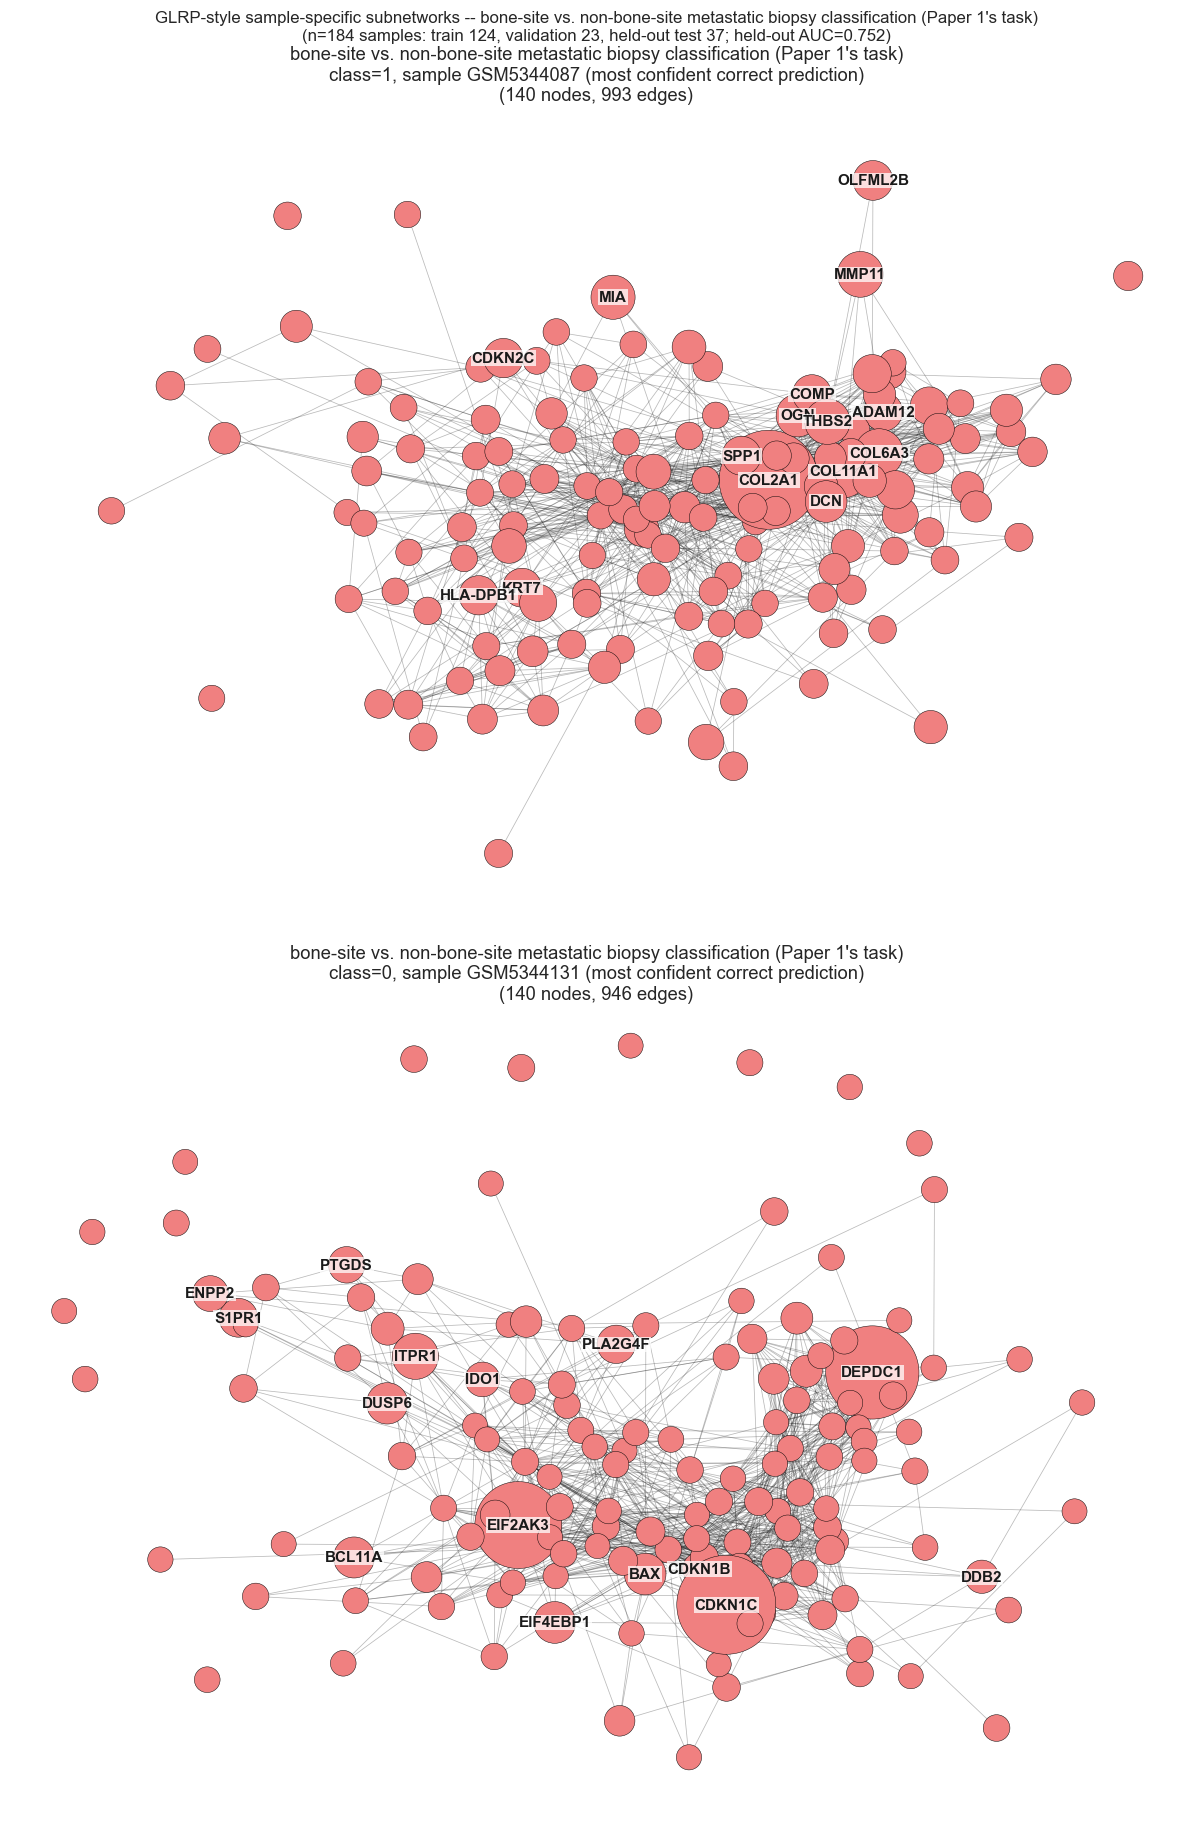


=== post-metastatic-diagnosis mortality within 36 months vs. alive >=36 months -- held-out test: AUC=0.630, accuracy=0.677, F1=0.688 (threshold=0.504) ===
  class=1 MOST-CONFIDENT correctly-classified patient GSM5344134 (selection rule: highest target-class logit, not typical/random -- see Item 10 for a non-cherry-picked alternative): output_logit=0.0764, R_x sum=6.0115, conservation=7865.3%
  class=0 MOST-CONFIDENT correctly-classified patient GSM5344055 (selection rule: highest target-class logit, not typical/random -- see Item 10 for a non-cherry-picked alternative): output_logit=0.0778, R_x sum=0.0475, conservation=61.0%


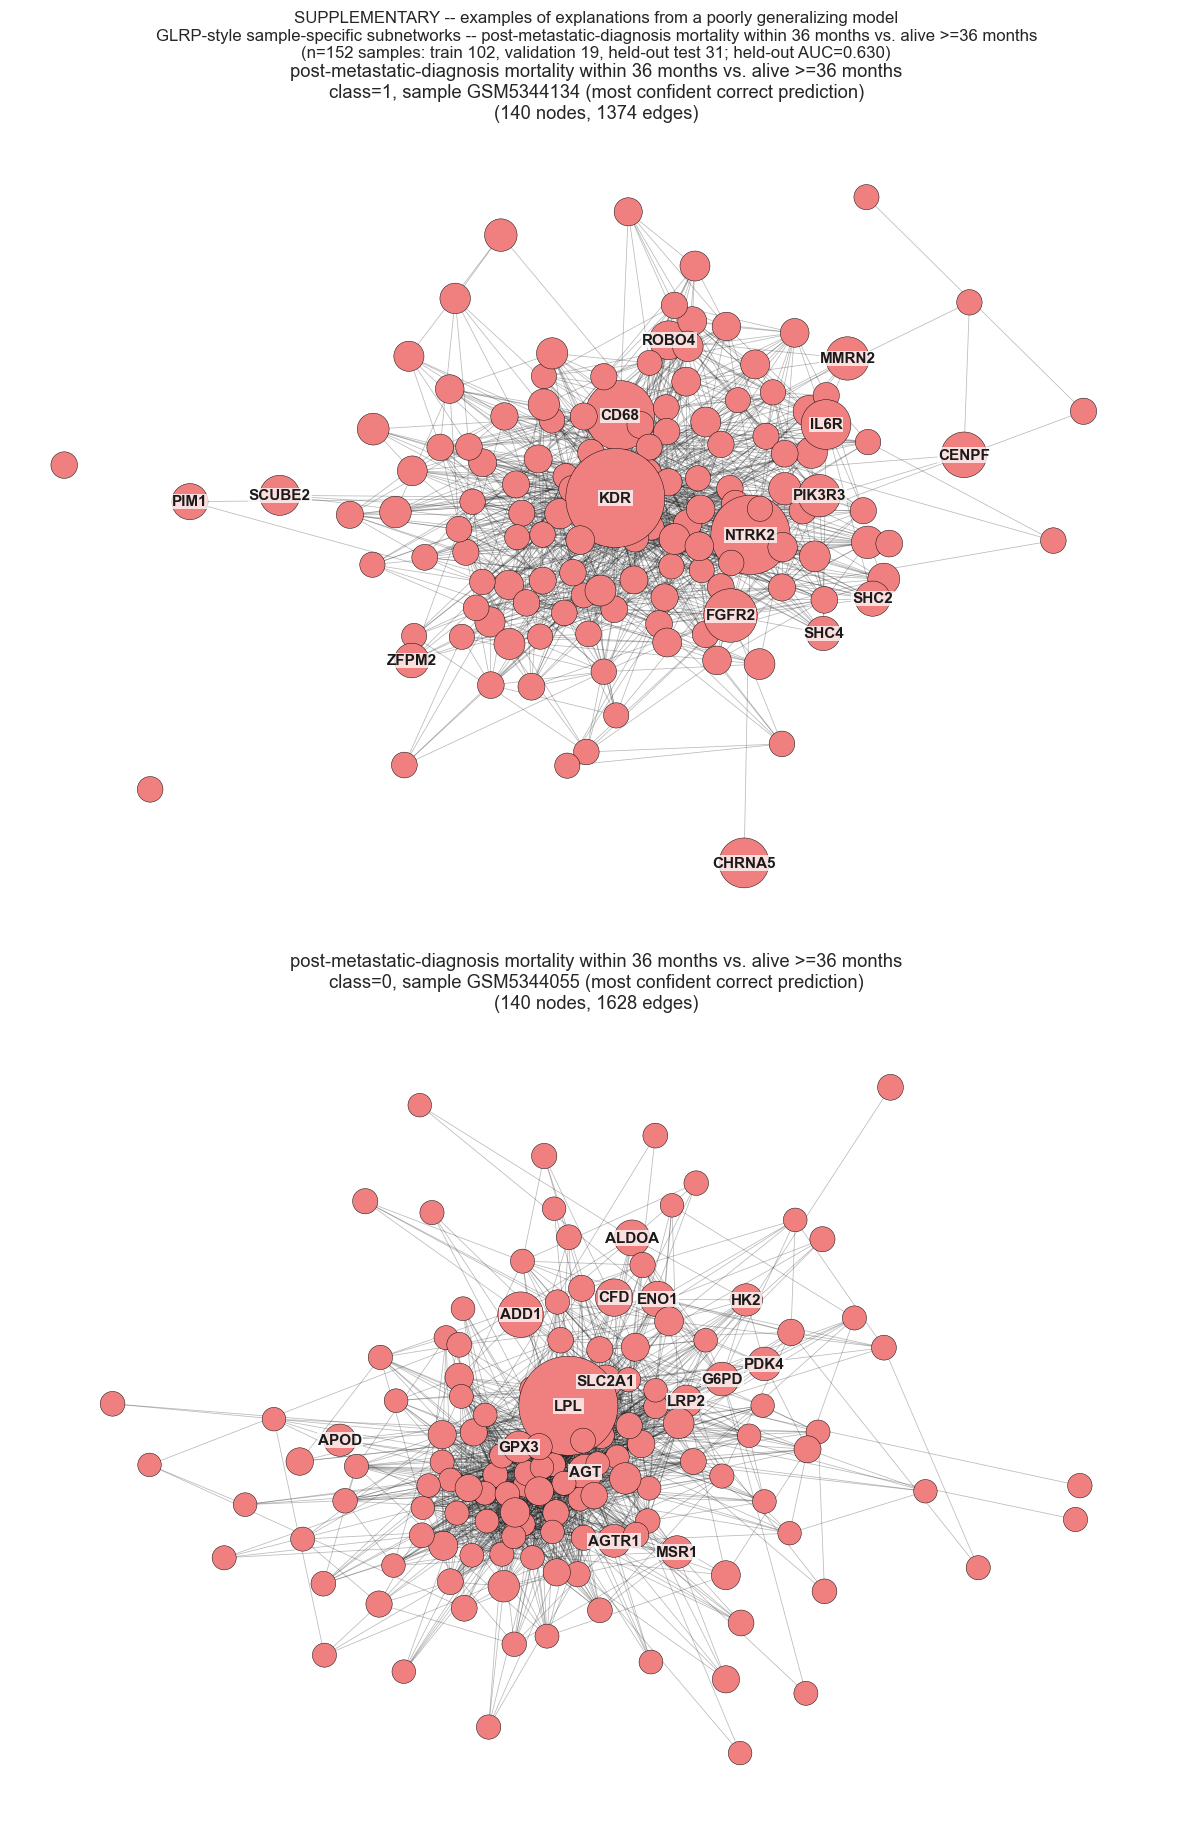

In [43]:
def glrp_explain(model, x0, target_class):
    with torch.no_grad():
        h1 = torch.relu(model.conv1(L_hat, x0))
        h2 = torch.relu(model.conv2(L_hat, h1))
        flat = h2.reshape(1, -1)
        hfc = torch.relu(model.fc1(flat))
        logits = model.fc2(hfc)
    R_out = torch.zeros_like(logits); R_out[0, target_class] = logits[0, target_class]
    R_hfc = relevance_step(hfc, fc_fwd, (model.fc2.weight.clamp(min=0),), R_out)
    R_flat = relevance_step(flat, fc_fwd, (model.fc1.weight.clamp(min=0),), R_hfc)
    R_h2 = R_flat.reshape(1, model.N, model.F2)
    R_h1 = relevance_step(h1, lambda a, tp: torch.relu(model.conv2(L_hat, a, theta=tp)), (model.conv2.theta.clamp(min=0),), R_h2)
    R_x = relevance_step(x0, lambda a, tp: torch.relu(model.conv1(L_hat, a, theta=tp)), (model.conv1.theta.clamp(min=0),), R_h1)
    return logits[0, target_class].item(), R_out.sum().item(), R_x.squeeze().detach().numpy()

def build_and_plot_subnetwork(title, rel, ax, top_n=140):
    top_genes = pd.Series(np.abs(rel), index=gene_list).sort_values(ascending=False).head(top_n).index.tolist()
    sub = G_main.subgraph(top_genes).copy()
    rel_series = pd.Series(np.abs(rel), index=gene_list)
    denom = max(rel_series[top_genes].max(), np.finfo(float).eps)
    sizes = [200 + 4000 * rel_series[g] / denom for g in sub.nodes()]
    pos = nx.spring_layout(sub, seed=0, k=0.5)
    nx.draw_networkx_edges(sub, pos, ax=ax, alpha=0.3, width=0.5)
    nx.draw_networkx_nodes(sub, pos, ax=ax, node_size=sizes, node_color="lightcoral", edgecolors="black", linewidths=0.3)
    top10 = rel_series[top_genes].sort_values(ascending=False).head(10).index
    top15 = rel_series[top_genes].sort_values(ascending=False).head(15).index   # [R10] more, larger labels
    nx.draw_networkx_labels(sub, pos, labels={g: g for g in sub.nodes() if g in top15}, ax=ax, font_size=10,
                            font_weight="bold", bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=0.5))
    ax.set_title(f"{title}\n({sub.number_of_nodes()} nodes, {sub.number_of_edges()} edges)")
    ax.axis("off")
    return top_genes

glrp_results = {}  # task_name -> {class_label: (patient_id, relevance_array, subnetwork_genes)}
final_models = {}
final_test_splits = {}

for task_name, task in TASKS.items():
    X_task, y_task = EXPL_X[task_name], task["y"]   # [R3] fold-internal preprocessing (cell 13-0)
    patient_ids = (Xall.index.tolist() if task_name == "bone_metastasis" else Xall.index[task2_mask].tolist())
    Xtr, Xte, ytr, yte, ptr, pte = train_test_split(
        X_task, y_task, patient_ids, test_size=0.2, stratify=y_task, random_state=7
    )
    Xtr, Xva, ytr, yva = train_test_split(Xtr, ytr, test_size=0.15, stratify=ytr, random_state=7)
    model, val_auc = train_one_fold(Xtr, ytr, Xva, yva)
    model.eval()
    final_models[task_name] = model
    with torch.no_grad():
        te_logits = model(L_hat, torch.tensor(Xte)).numpy()
        va_probs = torch.softmax(model(L_hat, torch.tensor(Xva)), dim=1)[:, 1].numpy()
    te_probs = torch.tensor(te_logits).softmax(dim=1)[:, 1].numpy()
    thr = youden_threshold(yva, va_probs)
    te_preds = (te_probs >= thr).astype(int)
    final_test_splits[task_name] = {
        "Xte": Xte, "yte": np.asarray(yte), "pte": list(pte),
        "te_logits": te_logits, "te_probs": te_probs, "te_preds": te_preds, "threshold": thr,
    }
    te_auc_val = roc_auc_score(yte, te_probs)
    print(f"\n=== {task['label']} -- held-out test: AUC={te_auc_val:.3f}, "
          f"accuracy={accuracy_score(yte, te_preds):.3f}, F1={f1_score(yte, te_preds, zero_division=0):.3f} (threshold={thr:.3f}) ===")

    fig, axes = plt.subplots(2, 1, figsize=(11, 17))
    glrp_results[task_name] = {}
    for ax, target_class in zip(axes, [1, 0]):
        # GLRP demonstrations must be TRUE positives/TRUE negatives for the
        # requested class, not merely patients whose ground-truth label matches.
        class_idx = [
            i for i in range(len(yte))
            if int(yte[i]) == target_class and int(te_preds[i]) == target_class
        ]
        if not class_idx:
            raise RuntimeError(
                f"No correctly classified held-out patients for {task_name}, class={target_class}; "
                "do not substitute a misclassified patient for an explanation of a correct prediction."
            )
        # SELECTION RULE FOR THIS FIGURE: the correctly-classified patient with the
        # HIGHEST target-class logit ("most confident" prediction) -- kept as-is so this
        # figure's file/caption/patient identity don't shift under whatever the manuscript
        # already references. This is a convenience selection, not a representative or
        # random one; Item 10 (Revision Round 2, later in the notebook) selects patients by
        # median-probability ("typical") and closest-to-threshold ("borderline") rules
        # instead, specifically to avoid this figure being the only patient-level evidence
        # reported. If this figure is used in the manuscript, its caption should say
        # "most confident correctly-classified example" rather than implying it's typical.
        best_i = max(class_idx, key=lambda i: te_logits[i, target_class])
        x0 = torch.tensor(Xte[best_i:best_i + 1]).unsqueeze(-1)
        logit_val, R_sum, rel = glrp_explain(model, x0, target_class)
        patient_id = pte[best_i]
        conservation = 100 * rel.sum() / logit_val if abs(logit_val) > np.finfo(float).eps else float("nan")
        print(f"  class={target_class} MOST-CONFIDENT correctly-classified patient {patient_id} "
              f"(selection rule: highest target-class logit, not typical/random -- see Item 10 for "
              f"a non-cherry-picked alternative): output_logit={logit_val:.4f}, R_x sum={rel.sum():.4f}, "
              f"conservation={conservation:.1f}%")
        subnetwork_genes = build_and_plot_subnetwork(f"{task['label']}\nclass={target_class}, sample {patient_id} (most confident correct prediction)", rel, ax)
        glrp_results[task_name][target_class] = (patient_id, rel, subnetwork_genes)
    # [R9, R10] sample-specific wording, sample counts, survival panels routed to the supplement
    is_supp = task_name == "survival_outcome" or te_auc_val < 0.60
    counts = (f"n={len(y_task)} samples: train {len(ytr)}, validation {len(yva)}, held-out test {len(yte)}; "
              f"held-out AUC={te_auc_val:.3f}")
    title = (f"SUPPLEMENTARY -- examples of explanations from a poorly generalizing model\n" if is_supp else "")
    plt.suptitle(f"{title}GLRP-style sample-specific subnetworks -- {task['label']}\n({counts})", fontsize=11)
    fig_name = f"SUPP_10_subnetworks_{task_name}.png" if is_supp else f"10_subnetworks_{task_name}.png"
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fig_name}", dpi=200, bbox_inches="tight"); plt.show()

    for cls, (pid, rel, genes) in glrp_results[task_name].items():
        pd.Series(genes, name="gene").to_csv(f"{OUT_DIR}/subnetwork_{task_name}_class{cls}.csv", index=False)


In [44]:
# ============================================================
# 13-A. Layer-wise relevance audit for the implementation in Section 9a  [R6]
# ============================================================
def glrp_explain_layers(model, x0, target_class):
    """Same computation as glrp_explain, but returns the relevance sum at every layer."""
    with torch.no_grad():
        h1 = torch.relu(model.conv1(L_hat, x0)); h2 = torch.relu(model.conv2(L_hat, h1))
        flat = h2.reshape(1, -1); hfc = torch.relu(model.fc1(flat)); logits = model.fc2(hfc)
    R_out = torch.zeros_like(logits); R_out[0, target_class] = logits[0, target_class]
    R_hfc = relevance_step(hfc, fc_fwd, (model.fc2.weight.clamp(min=0),), R_out)
    R_flat = relevance_step(flat, fc_fwd, (model.fc1.weight.clamp(min=0),), R_hfc)
    R_h2 = R_flat.reshape(1, model.N, model.F2)
    R_h1 = relevance_step(h1, lambda a, tp: torch.relu(model.conv2(L_hat, a, theta=tp)), (model.conv2.theta.clamp(min=0),), R_h2)
    R_x = relevance_step(x0, lambda a, tp: torch.relu(model.conv1(L_hat, a, theta=tp)), (model.conv1.theta.clamp(min=0),), R_h1)
    rx = R_x.squeeze().numpy()
    return {"logit": logits[0, target_class].item(), "sum_R_fc1_out": R_hfc.sum().item(),
            "sum_R_conv2_out": R_flat.sum().item(), "sum_R_conv1_out": R_h1.sum().item(), "sum_R_input": rx.sum(),
            "frac_genes_same_sign_as_logit": float(np.mean(np.sign(rx[rx != 0]) == np.sign(logits[0, target_class].item())))
                                              if (rx != 0).any() else np.nan}

layer_rows = []
for task_name in TASKS:
    model, split = final_models[task_name], final_test_splits[task_name]
    for i in range(len(split["yte"])):
        c = int(split["yte"][i])
        if int(split["te_preds"][i]) != c:
            continue
        r = glrp_explain_layers(model, torch.tensor(split["Xte"][i:i + 1]).unsqueeze(-1), c)
        r.update({"task": task_name, "sample_id": split["pte"][i], "class": c})
        layer_rows.append(r)
glrp_layer_audit = pd.DataFrame(layer_rows)
for col in ["sum_R_fc1_out", "sum_R_conv2_out", "sum_R_conv1_out", "sum_R_input"]:
    glrp_layer_audit[col.replace("sum_R", "pct")] = 100 * glrp_layer_audit[col] / glrp_layer_audit["logit"]
glrp_layer_audit.to_csv(f"{OUT_DIR}/glrp_layerwise_conservation_audit.csv", index=False)
print("Layer-wise relevance as % of the explained logit (100% = fully conserved through that layer):")
display(glrp_layer_audit.groupby("task")[["pct_fc1_out", "pct_conv2_out", "pct_conv1_out", "pct_input",
                                          "frac_genes_same_sign_as_logit"]].describe().T.round(2))
print("Negative logits explained:", int((glrp_layer_audit["logit"] < 0).sum()), "of", len(glrp_layer_audit))


Layer-wise relevance as % of the explained logit (100% = fully conserved through that layer):


task                                 bone_metastasis  survival_outcome
pct_fc1_out                   count            31.00             21.00
                              mean            100.00            100.00
                              std               0.00              0.00
                              min             100.00            100.00
                              25%             100.00            100.00
                              50%             100.00            100.00
                              75%             100.00            100.00
                              max             100.00            100.00
pct_conv2_out                 count            31.00             21.00
                              mean            100.00            100.00
                              std               0.00              0.00
                              min             100.00            100.00
                              25%             100.00            100.00
                              50%             100.00            100.00
                              75%             100.00            100.00
                              max             100.00            100.00
pct_conv1_out                 count            31.00             21.00
                              mean             95.28            105.34
                              std               0.56             24.69
                              min              94.46             98.92
                              25%              95.01             99.83
                              50%              95.25             99.99
                              75%              95.50            100.21
                              max              97.56            213.08
pct_input                     count            31.00             21.00
                              mean             94.68            470.27
                              std               3.48           1694.50
                              min              84.24             61.02
                              25%              94.57             96.69
                              50%              95.35            100.09
                              75%              96.56            106.96
                              max              98.89           7865.33
frac_genes_same_sign_as_logit count            31.00             21.00
                              mean              0.68              0.61
                              std               0.08              0.16
                              min               0.47              0.24
                              25%               0.61              0.52
                              50%               0.69              0.63
                              75%               0.75              0.74
                              max               0.81              0.82

Negative logits explained: 31 of 52


In [45]:
# ============================================================
# 13-B. Self-contained caption text for Figure 10 and its supplementary counterpart  [R9, R10]
# ============================================================
for task_name in TASKS:
    c = EXPL_SPLIT_COUNTS[task_name]; s = final_test_splits[task_name]
    auc_te = roc_auc_score(s["yte"], s["te_probs"])
    n_correct = int((s["yte"] == s["te_preds"]).sum())
    is_supp = task_name == "survival_outcome" or auc_te < 0.60
    label = "Supplementary Figure S10" if is_supp else "Figure 10"
    pid1, _, g1 = glrp_results[task_name][1]; pid0, _, g0 = glrp_results[task_name][0]
    print(f"\n{label}. Sample-specific GLRP-style relevance subnetworks, {TASKS[task_name]['label']}. "
          f"One Graph-CNN (K=7, STRING v12 graph, 737 genes) was trained on {c['n_train']} samples, with "
          f"{c['n_val']} validation samples used for checkpoint and threshold selection, and evaluated on "
          f"{c['n_test']} held-out samples ({c['n_pos_test']} positive; held-out AUC = {auc_te:.3f}; "
          f"{n_correct}/{c['n_test']} correctly classified). Preprocessing was fit on the training samples only. "
          f"Each panel shows the top-140 genes by |relevance| for one correctly classified held-out sample "
          f"(top: class 1, sample {pid1}; bottom: class 0, sample {pid0}), selected as the most confident "
          f"correct prediction in its class and therefore not representative. Node size is proportional to |relevance|; "
          f"edges are STRING interactions among the displayed genes; the 15 highest-relevance genes are labeled. "
          f"Relevance is the target-class logit redistributed by the z+ rule described in Section 9a; its sign follows "
          f"the logit, so magnitude rather than sign is shown."
          + (" These subnetworks are shown as examples of explanations from a poorly generalizing model and should not "
             "be interpreted as biologically informative." if is_supp else ""))



Figure 10. Sample-specific GLRP-style relevance subnetworks, bone-site vs. non-bone-site metastatic biopsy classification (Paper 1's task). One Graph-CNN (K=7, STRING v12 graph, 737 genes) was trained on 124 samples, with 23 validation samples used for checkpoint and threshold selection, and evaluated on 37 held-out samples (7 positive; held-out AUC = 0.752; 31/37 correctly classified). Preprocessing was fit on the training samples only. Each panel shows the top-140 genes by |relevance| for one correctly classified held-out sample (top: class 1, sample GSM5344087; bottom: class 0, sample GSM5344131), selected as the most confident correct prediction in its class and therefore not representative. Node size is proportional to |relevance|; edges are STRING interactions among the displayed genes; the 15 highest-relevance genes are labeled. Relevance is the target-class logit redistributed by the z+ rule described in Section 9a; its sign follows the logit, so magnitude rather than sign is 

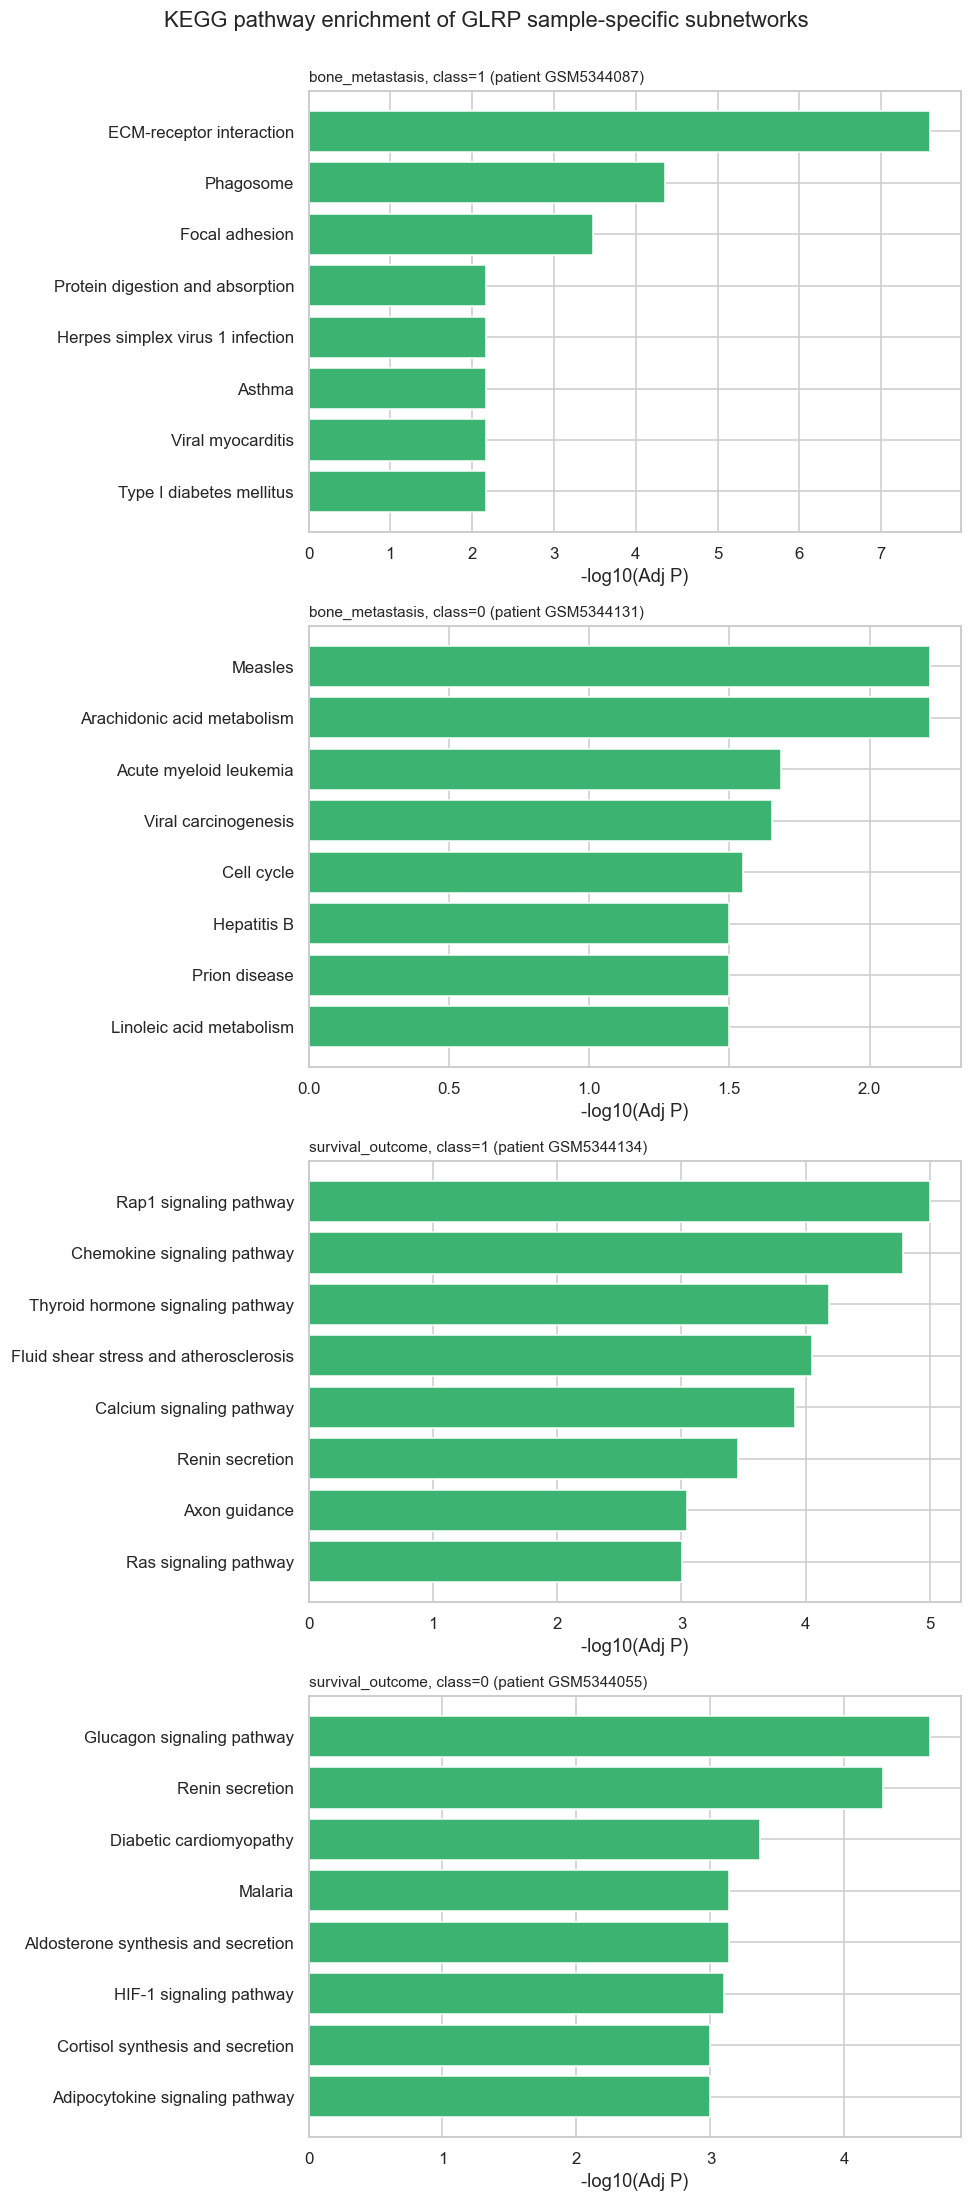

In [46]:
fig, axes = plt.subplots(4, 1, figsize=(9, 20))
subnetwork_pathways = {}
panel = 0
for task_name, task in TASKS.items():
    for target_class in [1, 0]:
        ax = axes[panel]; panel += 1
        pid, rel, genes = glrp_results[task_name][target_class]
        res = enrichr_retry(genes, ["KEGG_2021_Human"], background=gene_list).sort_values("Adjusted P-value").head(8)
        subnetwork_pathways[(task_name, target_class)] = res
        plot_df = res.iloc[::-1]
        ax.barh(plot_df["Term"].str.slice(0, 45), -np.log10(plot_df["Adjusted P-value"]), color="mediumseagreen")
        ax.set_title(f"{task_name}, class={target_class} (patient {pid})", fontsize=10, loc="left")
        ax.set_xlabel("-log10(Adj P)")
        res.to_csv(f"{OUT_DIR}/pathways_{task_name}_class{target_class}.csv", index=False)
        time.sleep(3)
plt.suptitle("KEGG pathway enrichment of GLRP sample-specific subnetworks", y=1.0)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/11_pathway_enrichment_both_tasks.png"); plt.show()


In [47]:
N_PATIENTS_PER_CLASS = 4  # set to 3 if you want fewer panels per class

def select_patients(task_name, target_class, n=N_PATIENTS_PER_CLASS):
    """Pick up to n correctly-classified held-out test patients for one class,
    ranked by the model's raw output logit for that class. Reuses the exact
    Section 13 held-out split and predictions saved in final_test_splits.
    """
    model = final_models[task_name]
    split = final_test_splits[task_name]
    Xte = split["Xte"]
    yte = split["yte"]
    pte = split["pte"]
    te_logits = split["te_logits"]
    te_preds = split["te_preds"]

    class_idx = [
        i for i in range(len(yte))
        if int(yte[i]) == target_class and int(te_preds[i]) == target_class
    ]
    class_idx_sorted = sorted(class_idx, key=lambda i: te_logits[i, target_class], reverse=True)
    picked = class_idx_sorted[:n]
    if len(picked) < n:
        print(f"Warning: requested {n} correctly-classified patients for {task_name}, class={target_class}, but only {len(picked)} are available.")

    out = []
    for i in picked:
        x0 = torch.tensor(Xte[i:i + 1]).unsqueeze(-1)
        logit_val, R_sum, rel = glrp_explain(model, x0, target_class)
        out.append({"patient_id": pte[i], "logit": logit_val, "relevance": rel})
    return out

multi_patient_results = {}
for task_name, task in TASKS.items():
    multi_patient_results[task_name] = {}
    for target_class in [1, 0]:
        multi_patient_results[task_name][target_class] = select_patients(task_name, target_class)

print(f"Requested up to {N_PATIENTS_PER_CLASS} correctly-classified patients per class (real GSM accessions, most-confident first):")
for task_name, classes in multi_patient_results.items():
    for target_class, patients in classes.items():
        print(f"  {task_name}, class={target_class}: {[p['patient_id'] for p in patients]}  (logits: {[round(p['logit'],2) for p in patients]})")


Requested up to 4 correctly-classified patients per class (real GSM accessions, most-confident first):
  bone_metastasis, class=1: ['GSM5344087', 'GSM5344119', 'GSM5344170', 'GSM5344148']  (logits: [-0.15, -0.54, -0.72, -0.81])
  bone_metastasis, class=0: ['GSM5344131', 'GSM5344141', 'GSM5344041', 'GSM5344130']  (logits: [-0.1, -0.11, -0.14, -0.2])
  survival_outcome, class=1: ['GSM5344134', 'GSM5344214', 'GSM5344125', 'GSM5344191']  (logits: [0.08, 0.08, 0.08, 0.08])
  survival_outcome, class=0: ['GSM5344055', 'GSM5344110', 'GSM5344132', 'GSM5344066']  (logits: [0.08, 0.07, 0.07, 0.07])


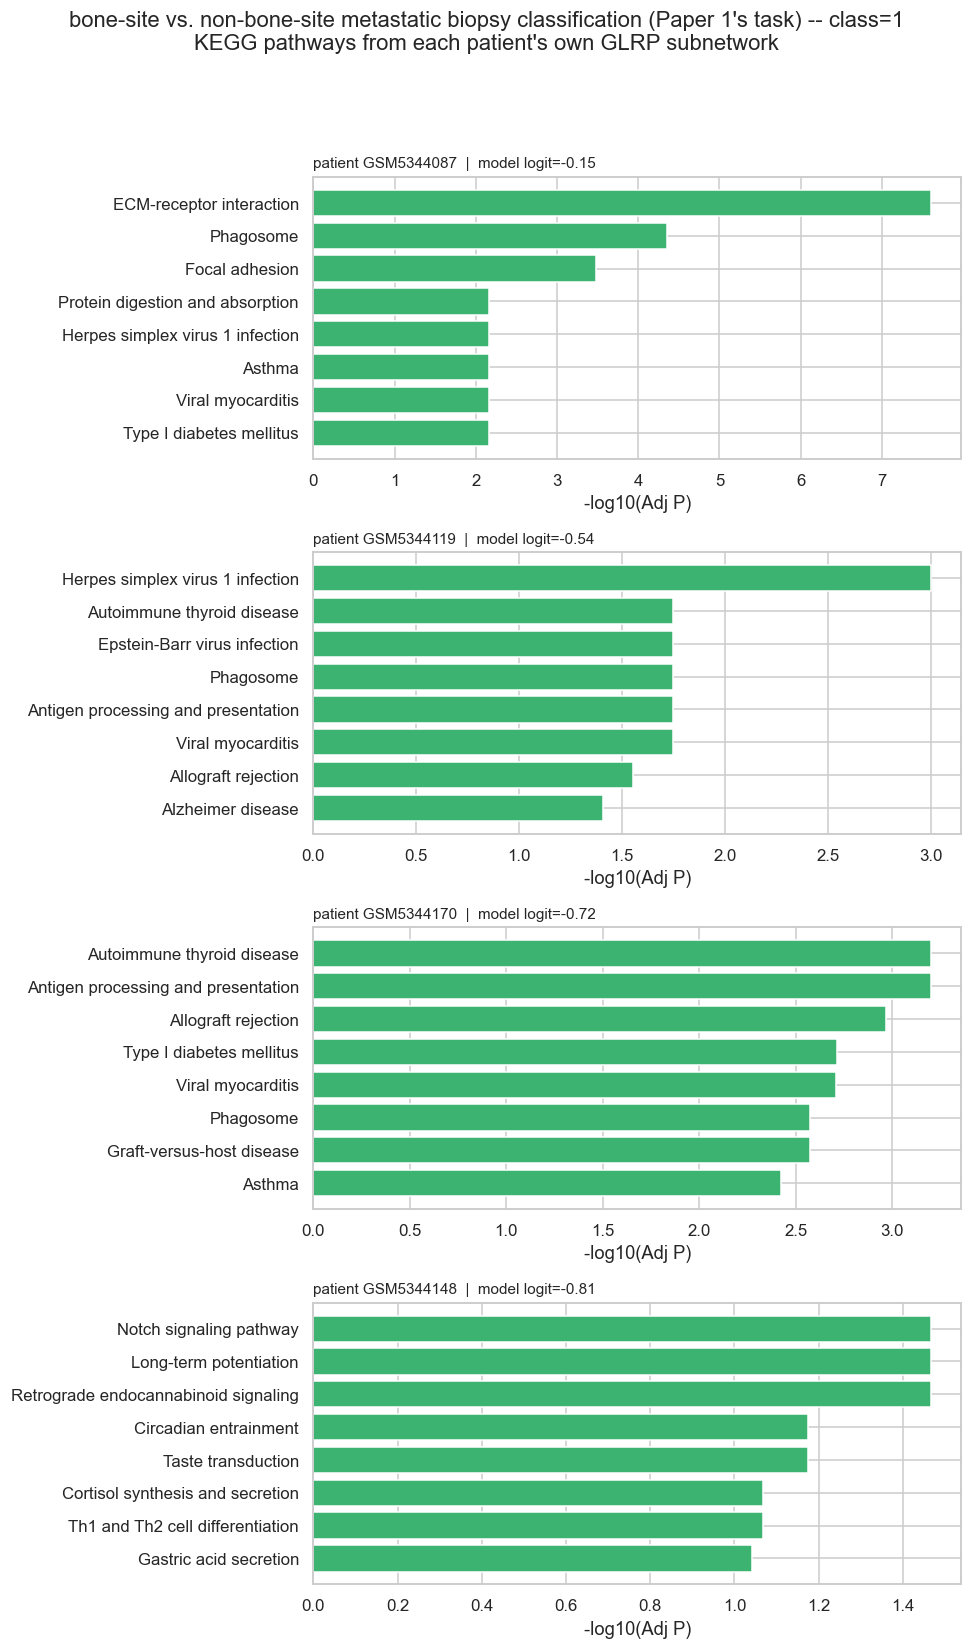

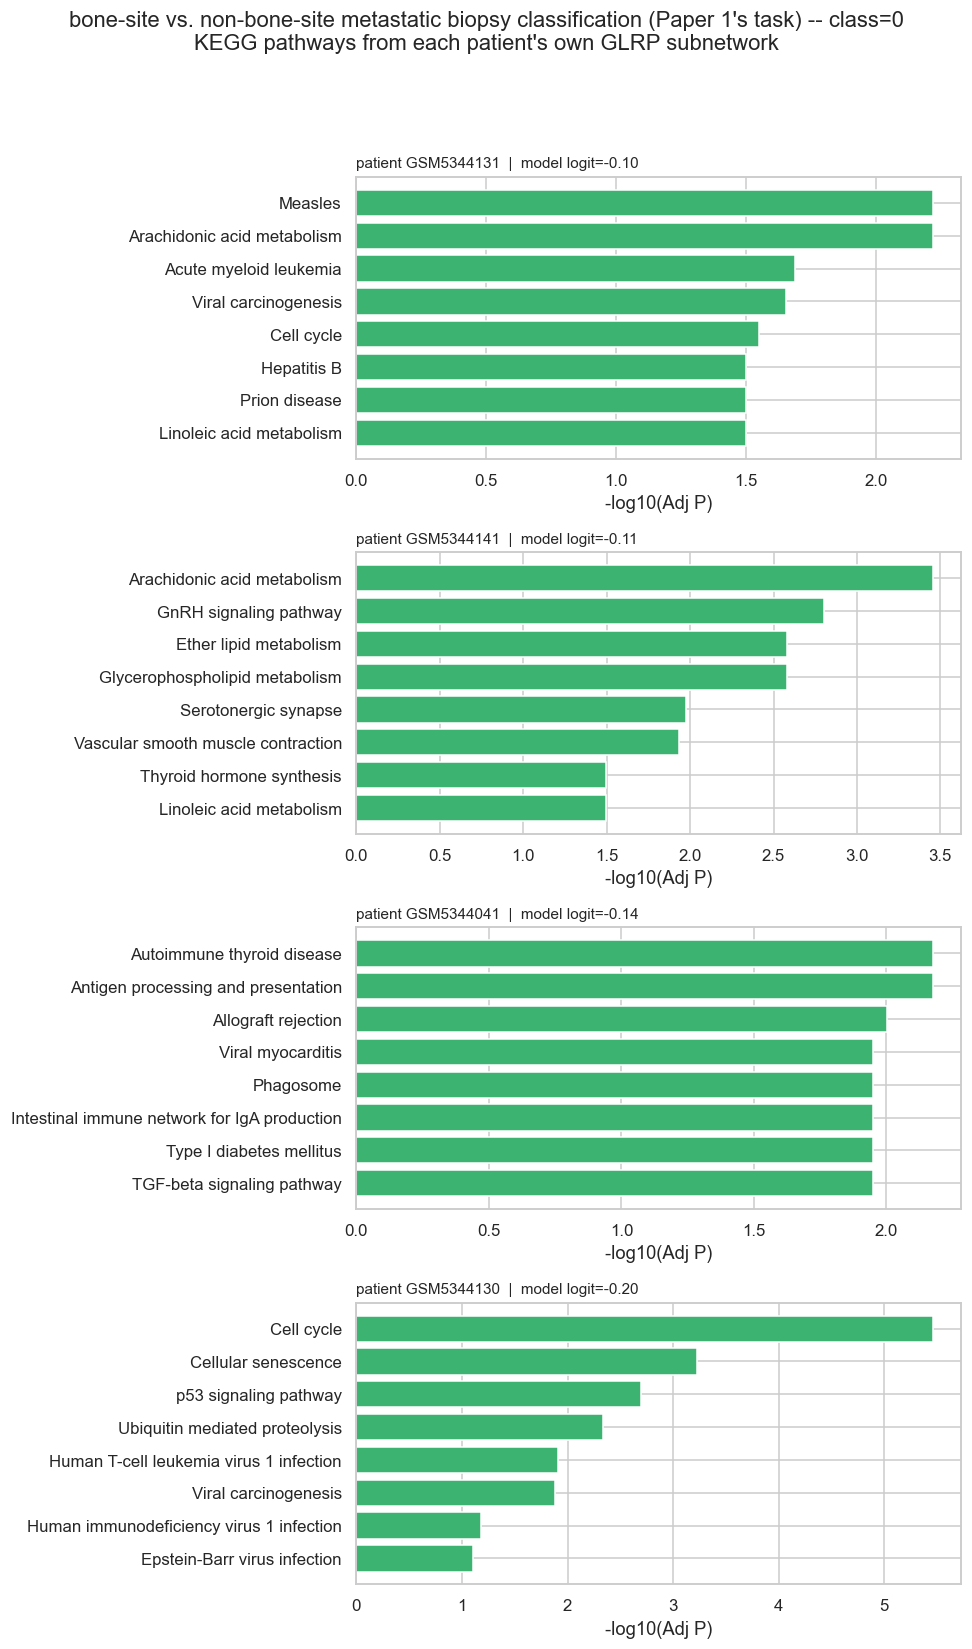

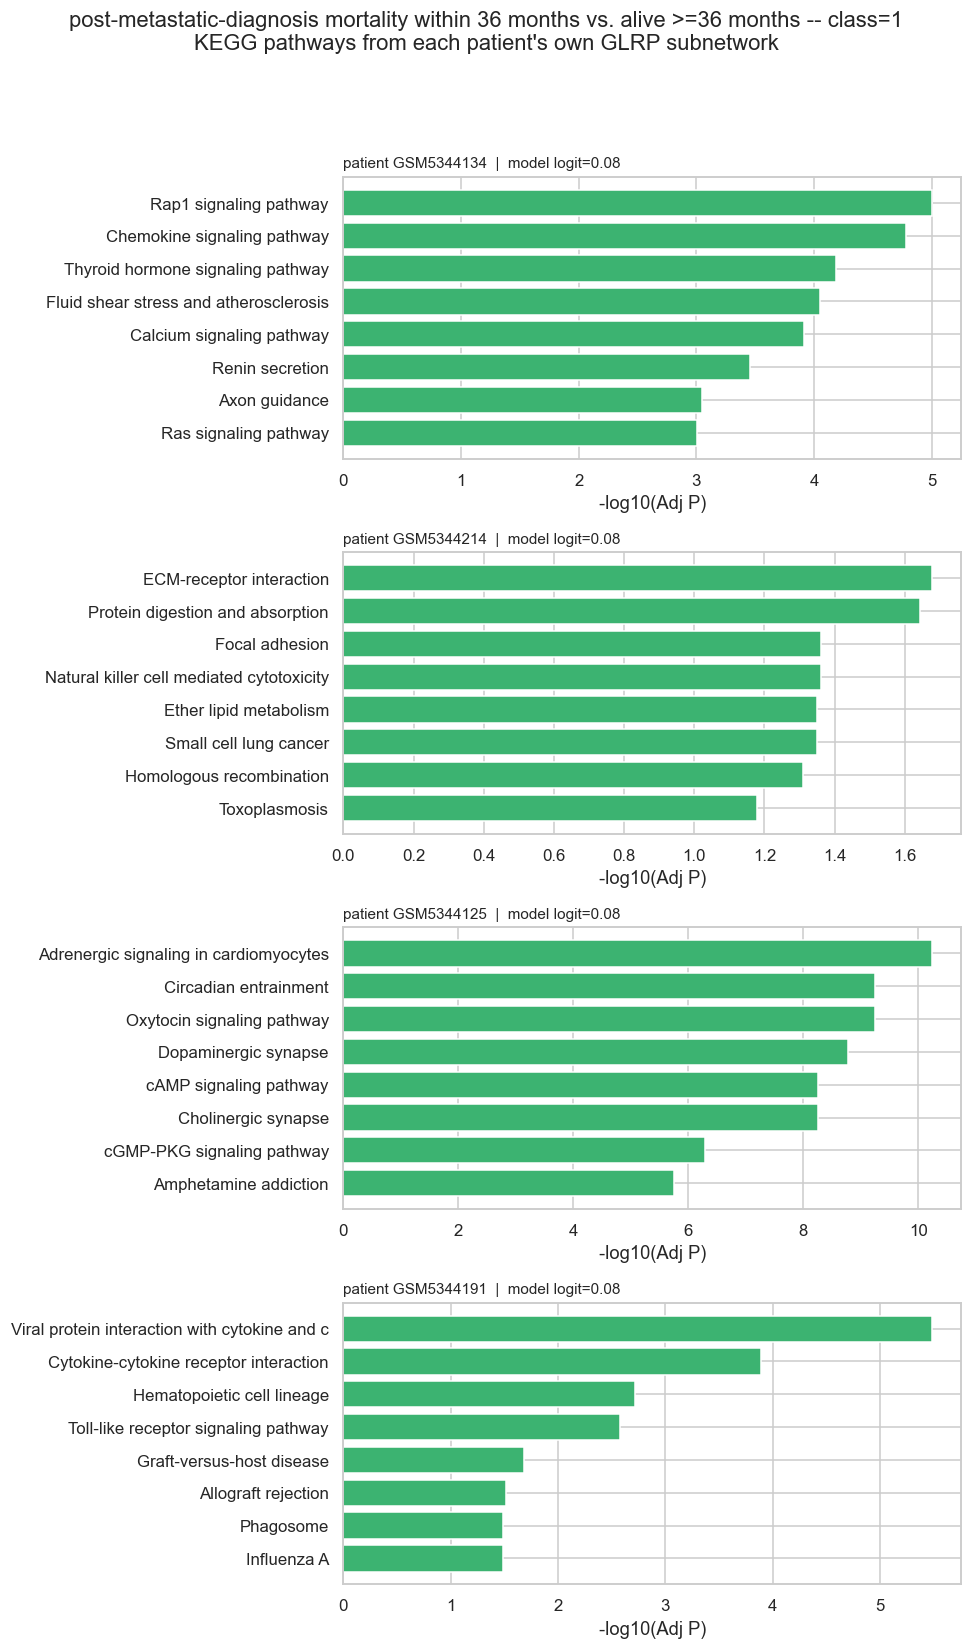

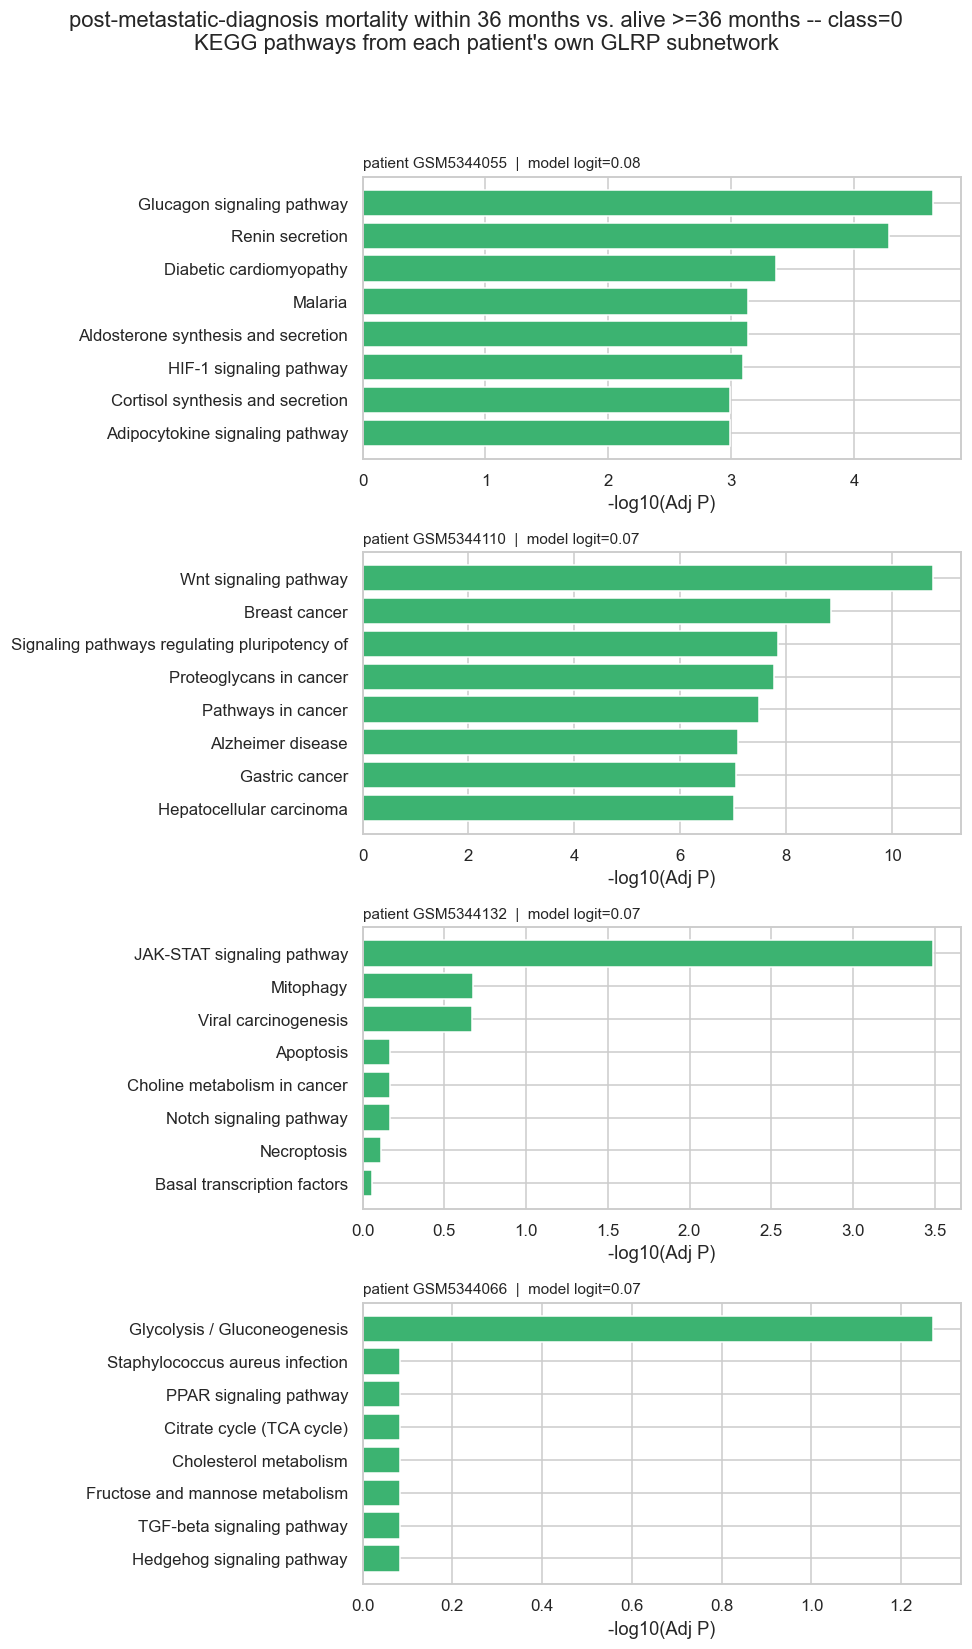

In [48]:
def plot_patient_bar_grid(task_name, target_class, patients, top_n=140):
    n = len(patients)
    # One patient per ROW (n rows x 1 column) instead of one row of n columns --
    # each patient's panel is now full-width and easier to read top-to-bottom.
    fig, axes = plt.subplots(n, 1, figsize=(9, 3.6 * n))
    if n == 1:
        axes = [axes]
    for ax, p in zip(axes, patients):
        top_genes = pd.Series(np.abs(p["relevance"]), index=gene_list).sort_values(ascending=False).head(top_n).index.tolist()
        res = enrichr_retry(top_genes, ["KEGG_2021_Human"], background=gene_list).sort_values("Adjusted P-value").head(8)
        plot_df = res.iloc[::-1]
        ax.barh(plot_df["Term"].str.slice(0, 45), -np.log10(plot_df["Adjusted P-value"]), color="mediumseagreen")
        ax.set_title(f"patient {p['patient_id']}  |  model logit={p['logit']:.2f}", fontsize=10, loc="left")
        ax.set_xlabel("-log10(Adj P)")
        time.sleep(3)  # be polite to the Enrichr API, same as Section 14
    plt.suptitle(f"{TASKS[task_name]['label']} -- class={target_class}\nKEGG pathways from each patient's own GLRP subnetwork", y=1.0 + 0.01 * n)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/14_pathways_{task_name}_class{target_class}_multi.png", bbox_inches="tight")
    plt.show()

for task_name in TASKS:
    for target_class in [1, 0]:
        plot_patient_bar_grid(task_name, target_class, multi_patient_results[task_name][target_class])

In [49]:
# Generalizes select_patients() from Section 13c: ALL correctly-classified
# held-out test patients per (task, class), not just the top-N by confidence.
def select_all_correct_patients(task_name, target_class):
    model = final_models[task_name]
    split = final_test_splits[task_name]
    Xte, yte, pte = split["Xte"], split["yte"], split["pte"]
    te_logits, te_preds = split["te_logits"], split["te_preds"]
    class_idx = [i for i in range(len(yte))
                 if int(yte[i]) == target_class and int(te_preds[i]) == target_class]
    out = []
    for i in class_idx:
        x0 = torch.tensor(Xte[i:i + 1]).unsqueeze(-1)
        logit_val, R_sum, rel = glrp_explain(model, x0, target_class)
        out.append({"patient_id": pte[i], "logit": logit_val, "relevance": rel})
    return out

all_patient_results = {}
for task_name in TASKS:
    all_patient_results[task_name] = {}
    for target_class in [1, 0]:
        pts = select_all_correct_patients(task_name, target_class)
        all_patient_results[task_name][target_class] = pts
        print(f"{task_name}, class={target_class}: {len(pts)} correctly-classified "
              f"held-out patients available for heterogeneity analysis")


bone_metastasis, class=1: 4 correctly-classified held-out patients available for heterogeneity analysis


bone_metastasis, class=0: 27 correctly-classified held-out patients available for heterogeneity analysis
survival_outcome, class=1: 11 correctly-classified held-out patients available for heterogeneity analysis


survival_outcome, class=0: 10 correctly-classified held-out patients available for heterogeneity analysis


In [50]:
def topk_geneset(rel, k):
    return set(pd.Series(np.abs(rel), index=gene_list).sort_values(ascending=False).head(k).index)

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a or b) else np.nan

def pairwise_jaccard(patient_list, k):
    genesets = [topk_geneset(p["relevance"], k) for p in patient_list]
    return [jaccard(genesets[i], genesets[j])
            for i in range(len(genesets)) for j in range(i + 1, len(genesets))]

def _pairwise_similarity_matrix(sets):
    # Computes every pairwise Jaccard value ONCE, as an n x n matrix.
    n = len(sets)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            v = jaccard(sets[i], sets[j])
            M[i, j] = M[j, i] = v
    return M

def permutation_test_jaccard_gap(sets1, sets0, n_perm=2000, rng_seed=0):
    """
    Patient-level permutation test for the within-vs-between Jaccard gap.
    A plain Mann-Whitney test on all pairwise Jaccard values treats each pair
    as an independent observation, but every patient contributes to many
    pairs -- that inflates apparent significance. This permutes class labels
    across the pooled patient set (keeping n1/n0 fixed), recomputes the same
    summary statistic (mean within-class Jaccard minus mean between-class
    Jaccard) each time, and reports the fraction of permutations at least as
    extreme as the observed value -- a cluster-correct alternative.

    Performance note: the O(n^2) Jaccard similarity matrix is built ONCE, up
    front. Each of the n_perm permutations then only re-averages cells of
    that already-computed matrix (fast numpy indexing) instead of
    recomputing Jaccard from the raw gene/term sets every time -- for the
    larger CV-pooled patient pool, the naive version recomputed Jaccard tens
    of millions of times; this version computes it n*(n-1)/2 times, period.
    """
    rng = np.random.default_rng(rng_seed)
    all_sets = sets1 + sets0
    n1 = len(sets1)
    n = len(all_sets)
    if n1 < 2 or (n - n1) < 2:
        return np.nan, np.nan

    M = _pairwise_similarity_matrix(all_sets)

    def gap_stat_from_labels(is_class1):
        idx1 = np.where(is_class1)[0]
        idx0 = np.where(~is_class1)[0]
        if len(idx1) < 2 or len(idx0) < 2:
            return np.nan
        within_vals = np.concatenate([
            M[np.ix_(idx1, idx1)][np.triu_indices(len(idx1), k=1)],
            M[np.ix_(idx0, idx0)][np.triu_indices(len(idx0), k=1)],
        ])
        between_vals = M[np.ix_(idx1, idx0)].ravel()
        if within_vals.size == 0 or between_vals.size == 0:
            return np.nan
        return within_vals.mean() - between_vals.mean()

    base_labels = np.zeros(n, dtype=bool)
    base_labels[:n1] = True
    observed = gap_stat_from_labels(base_labels)
    if np.isnan(observed):
        return observed, np.nan

    perm_stats = np.empty(n_perm)
    for p in range(n_perm):
        perm_stats[p] = gap_stat_from_labels(rng.permutation(base_labels))
    perm_stats = perm_stats[~np.isnan(perm_stats)]
    p_value = (np.sum(np.abs(perm_stats) >= abs(observed)) + 1) / (len(perm_stats) + 1)
    return observed, p_value

K_VALUES = [100, 140, 180]
heterogeneity_rows = []

for task_name in TASKS:
    class1_patients = all_patient_results[task_name][1]
    class0_patients = all_patient_results[task_name][0]
    for k in K_VALUES:
        within = pairwise_jaccard(class1_patients, k) + pairwise_jaccard(class0_patients, k)
        genesets1 = [topk_geneset(p["relevance"], k) for p in class1_patients]
        genesets0 = [topk_geneset(p["relevance"], k) for p in class0_patients]
        between = [jaccard(g1, g0) for g1 in genesets1 for g0 in genesets0]
        observed_gap, pval = permutation_test_jaccard_gap(genesets1, genesets0, n_perm=2000, rng_seed=k)
        heterogeneity_rows.append({
            "task": TASKS[task_name]["label"], "top_k": k,
            "n_class1": len(class1_patients), "n_class0": len(class0_patients),
            "n_within_pairs": len(within), "n_between_pairs": len(between),
            "mean_within_jaccard": np.mean(within) if within else np.nan,
            "mean_between_jaccard": np.mean(between) if between else np.nan,
            "permutation_p": pval,
        })

heterogeneity_summary = pd.DataFrame(heterogeneity_rows)
heterogeneity_summary.to_csv(f"{OUT_DIR}/glrp_heterogeneity_jaccard_summary.csv", index=False)
print("Gene-level GLRP heterogeneity (within- vs between-class Jaccard, by threshold):")
display(heterogeneity_summary)


Gene-level GLRP heterogeneity (within- vs between-class Jaccard, by threshold):


,task,top_k,n_class1,n_class0,n_within_pairs,n_between_pairs,mean_within_jaccard,mean_between_jaccard,permutation_p
0,bone-site vs. non-bone-site metastatic biopsy ...,100,4,27,357,108,0.142469,0.151621,0.595202
1,bone-site vs. non-bone-site metastatic biopsy ...,140,4,27,357,108,0.184242,0.196541,0.481759
2,bone-site vs. non-bone-site metastatic biopsy ...,180,4,27,357,108,0.216456,0.233895,0.292854
3,post-metastatic-diagnosis mortality within 36 ...,100,11,10,100,110,0.102165,0.088316,0.012994
4,post-metastatic-diagnosis mortality within 36 ...,140,11,10,100,110,0.141765,0.126010,0.006997
5,post-metastatic-diagnosis mortality within 36 ...,180,11,10,100,110,0.179294,0.163521,0.011994


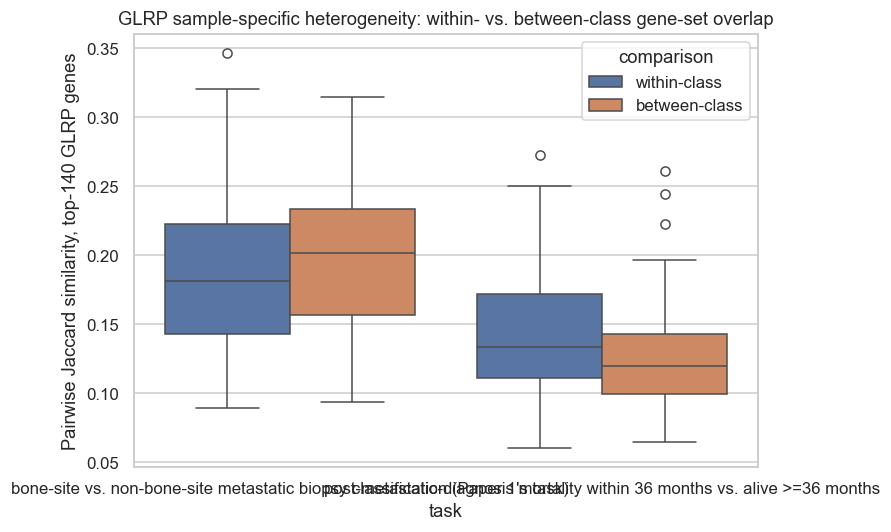

In [51]:
plot_rows = []
for task_name in TASKS:
    class1_patients = all_patient_results[task_name][1]
    class0_patients = all_patient_results[task_name][0]
    genesets1 = [topk_geneset(p["relevance"], 140) for p in class1_patients]
    genesets0 = [topk_geneset(p["relevance"], 140) for p in class0_patients]
    within = pairwise_jaccard(class1_patients, 140) + pairwise_jaccard(class0_patients, 140)
    between = [jaccard(g1, g0) for g1 in genesets1 for g0 in genesets0]
    for v in within:
        plot_rows.append({"task": TASKS[task_name]["label"], "comparison": "within-class", "jaccard": v})
    for v in between:
        plot_rows.append({"task": TASKS[task_name]["label"], "comparison": "between-class", "jaccard": v})

plot_df = pd.DataFrame(plot_rows)
plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_df, x="task", y="jaccard", hue="comparison")
plt.ylabel("Pairwise Jaccard similarity, top-140 GLRP genes")
plt.title("GLRP sample-specific heterogeneity: within- vs. between-class gene-set overlap")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/glrp_heterogeneity_within_vs_between.png", dpi=300, bbox_inches="tight")
plt.show()


In [52]:
hub_stability_rows = []
for task_name in TASKS:
    for target_class in [1, 0]:
        patients = all_patient_results[task_name][target_class]
        for k in K_VALUES:
            genesets = [topk_geneset(p["relevance"], k) for p in patients]
            for gene in HUB_GENES:
                frac = np.mean([gene in gs for gs in genesets]) if genesets else np.nan
                hub_stability_rows.append({
                    "task": TASKS[task_name]["label"], "class": target_class, "top_k": k,
                    "gene": gene, "fraction_of_patients_included": frac, "n_patients": len(genesets),
                })

hub_stability = pd.DataFrame(hub_stability_rows)
hub_stability.to_csv(f"{OUT_DIR}/glrp_hub_gene_threshold_stability.csv", index=False)
print("Hub-gene inclusion rate by threshold (use this for the PROM1 sensitivity claim):")
display(hub_stability.pivot_table(index=["task", "class", "gene"], columns="top_k",
                                   values="fraction_of_patients_included"))


Hub-gene inclusion rate by threshold (use this for the PROM1 sensitivity claim):


top_k                                                                100  \
task                                               class gene              
bone-site vs. non-bone-site metastatic biopsy c... 0     BMP2   0.444444   
                                                         CCL2   0.074074   
                                                         ITGB3  0.148148   
                                                         MMP9   0.037037   
                                                         PROM1  0.000000   
                                                   1     BMP2   0.000000   
                                                         CCL2   0.000000   
                                                         ITGB3  0.250000   
                                                         MMP9   0.000000   
                                                         PROM1  0.000000   
post-metastatic-diagnosis mortality within 36 m... 0     BMP2   0.100000   
                                                         CCL2   0.400000   
                                                         ITGB3  0.000000   
                                                         MMP9   0.200000   
                                                         PROM1  0.100000   
                                                   1     BMP2   0.000000   
                                                         CCL2   0.363636   
                                                         ITGB3  0.272727   
                                                         MMP9   0.272727   
                                                         PROM1  0.090909   

top_k                                                                140  \
task                                               class gene              
bone-site vs. non-bone-site metastatic biopsy c... 0     BMP2   0.518519   
                                                         CCL2   0.148148   
                                                         ITGB3  0.185185   
                                                         MMP9   0.111111   
                                                         PROM1  0.074074   
                                                   1     BMP2   0.000000   
                                                         CCL2   0.000000   
                                                         ITGB3  0.250000   
                                                         MMP9   0.000000   
                                                         PROM1  0.000000   
post-metastatic-diagnosis mortality within 36 m... 0     BMP2   0.200000   
                                                         CCL2   0.500000   
                                                         ITGB3  0.000000   
                                                         MMP9   0.300000   
                                                         PROM1  0.100000   
                                                   1     BMP2   0.181818   
                                                         CCL2   0.363636   
                                                         ITGB3  0.272727   
                                                         MMP9   0.363636   
                                                         PROM1  0.090909   

top_k                                                                180  
task                                               class gene             
bone-site vs. non-bone-site metastatic biopsy c... 0     BMP2   0.555556  
                                                         CCL2   0.185185  
                                                         ITGB3  0.296296  
                                                         MMP9   0.148148  
                                                         PROM1  0.111111  
                                                   1     BMP2   0.500000  
                                                      

In [53]:
def patient_kegg_termset(rel, k=140, padj_cutoff=0.05):
    genes = list(topk_geneset(rel, k))
    res = enrichr_retry(genes, ["KEGG_2021_Human"], background=gene_list)
    time.sleep(3)
    return set(res.loc[res["Adjusted P-value"] < padj_cutoff, "Term"])

pathway_heterogeneity_rows = []
for task_name in TASKS:
    class1_patients = all_patient_results[task_name][1]
    class0_patients = all_patient_results[task_name][0]
    terms1 = [patient_kegg_termset(p["relevance"]) for p in class1_patients]
    terms0 = [patient_kegg_termset(p["relevance"]) for p in class0_patients]
    within = ([jaccard(terms1[i], terms1[j]) for i in range(len(terms1)) for j in range(i + 1, len(terms1))] +
              [jaccard(terms0[i], terms0[j]) for i in range(len(terms0)) for j in range(i + 1, len(terms0))])
    between = [jaccard(t1, t0) for t1 in terms1 for t0 in terms0]
    observed_gap, pval = permutation_test_jaccard_gap(terms1, terms0, n_perm=2000, rng_seed=0)
    pathway_heterogeneity_rows.append({
        "task": TASKS[task_name]["label"],
        "mean_within_pathway_jaccard": np.mean(within) if within else np.nan,
        "mean_between_pathway_jaccard": np.mean(between) if between else np.nan,
        "permutation_p": pval,
    })

pathway_heterogeneity_summary = pd.DataFrame(pathway_heterogeneity_rows)
pathway_heterogeneity_summary.to_csv(f"{OUT_DIR}/glrp_heterogeneity_pathway_jaccard_summary.csv", index=False)
print("Pathway-level GLRP heterogeneity (within- vs. between-class KEGG term-set Jaccard):")
display(pathway_heterogeneity_summary)


Pathway-level GLRP heterogeneity (within- vs. between-class KEGG term-set Jaccard):


,task,mean_within_pathway_jaccard,mean_between_pathway_jaccard,permutation_p
0,bone-site vs. non-bone-site metastatic biopsy ...,NaN,0.158378,NaN
1,post-metastatic-diagnosis mortality within 36 ...,NaN,0.048534,NaN


In [54]:
TASK_PATIENT_IDS = {
    "bone_metastasis": Xall.index.tolist(),
    "survival_outcome": Xall.index[task2_mask].tolist(),
}

# [R3, R5] Revised: uses the PRIMARY partitions (repeat 0), fold-internal preprocessing,
# and the same seed as the primary GCN_real_K7 fit for that fold. The models explained
# here are therefore the primary evaluation's repeat-0 models, not a separate pipeline.
N_EPOCHS_POOLED = N_EPOCHS_PRIMARY

cv_pooled_patient_results = {}
_pooled_start = time.time()
for task_name, task in TASKS.items():
    labels = PRIMARY_LABELS[task_name]
    pooled = {1: [], 0: []}
    for p in [p for p in PRIMARY_PARTITIONS[task_name] if p["repeat"] == 0]:
        _fold_start = time.time()
        tr, va, te = p["train"], p["val"], p["test"]
        Xtr, _ = prep_fold(tr, tr); Xva, _ = prep_fold(tr, va); Xte_fold, _ = prep_fold(tr, te)
        ytr, yva, yte_fold = labels.loc[tr].to_numpy(), labels.loc[va].to_numpy(), labels.loc[te].to_numpy()
        seed = 10000 * 0 + 100 * p["fold"] + MODEL_INDEX["GCN_real_K7"]
        model, va_probs, te_probs, val_auc = fit_predict("GCN_real_K7", Xtr, ytr, Xva, yva, Xte_fold, seed)
        thr = youden_threshold(yva, va_probs)
        te_preds = (te_probs >= thr).astype(int)
        print(f"[{task_name}] fold {p['fold'] + 1}/5 done in {time.time() - _fold_start:.0f}s "
              f"(inner val AUC {val_auc:.3f}, elapsed {time.time() - _pooled_start:.0f}s)")
        for i in range(len(yte_fold)):
            true_cls = int(yte_fold[i])
            if int(te_preds[i]) != true_cls:
                continue
            x0 = torch.tensor(Xte_fold[i:i + 1]).unsqueeze(-1)
            logit_val, R_sum, rel = glrp_explain(model, x0, true_cls)
            pooled[true_cls].append({"patient_id": te[i], "fold": p["fold"], "logit": logit_val, "relevance": rel})
    cv_pooled_patient_results[task_name] = pooled
    print(f"{task_name}: pooled across 5 folds -- class=1: {len(pooled[1])} correctly-classified, "
          f"class=0: {len(pooled[0])} correctly-classified (of {len(labels)} samples)")


[bone_metastasis] fold 1/5 done in 5s (inner val AUC 1.000, elapsed 5s)


[bone_metastasis] fold 2/5 done in 5s (inner val AUC 0.947, elapsed 11s)


[bone_metastasis] fold 3/5 done in 5s (inner val AUC 1.000, elapsed 17s)


[bone_metastasis] fold 4/5 done in 6s (inner val AUC 0.987, elapsed 23s)


[bone_metastasis] fold 5/5 done in 5s (inner val AUC 1.000, elapsed 29s)


...

[survival_outcome] fold 2/5 done in 5s (inner val AUC 0.795, elapsed 39s)


[survival_outcome] fold 3/5 done in 5s (inner val AUC 0.830, elapsed 44s)


[survival_outcome] fold 4/5 done in 5s (inner val AUC 0.822, elapsed 49s)


[survival_outcome] fold 5/5 done in 5s (inner val AUC 0.622, elapsed 54s)


survival_outcome: pooled across 5 folds -- class=1: 38 correctly-classified, class=0: 43 correctly-classified (of 152 samples)


In [55]:
heterogeneity_rows_pooled = []
for task_name in TASKS:
    class1_patients = cv_pooled_patient_results[task_name][1]
    class0_patients = cv_pooled_patient_results[task_name][0]
    for k in K_VALUES:
        within = pairwise_jaccard(class1_patients, k) + pairwise_jaccard(class0_patients, k)
        genesets1 = [topk_geneset(p["relevance"], k) for p in class1_patients]
        genesets0 = [topk_geneset(p["relevance"], k) for p in class0_patients]
        between = [jaccard(g1, g0) for g1 in genesets1 for g0 in genesets0]
        observed_gap, pval = permutation_test_jaccard_gap(genesets1, genesets0, n_perm=2000, rng_seed=k)
        heterogeneity_rows_pooled.append({
            "task": TASKS[task_name]["label"], "top_k": k,
            "n_class1": len(class1_patients), "n_class0": len(class0_patients),
            "n_within_pairs": len(within), "n_between_pairs": len(between),
            "mean_within_jaccard": np.mean(within) if within else np.nan,
            "mean_between_jaccard": np.mean(between) if between else np.nan,
            "permutation_p": pval,
        })

heterogeneity_summary_pooled = pd.DataFrame(heterogeneity_rows_pooled)
heterogeneity_summary_pooled.to_csv(f"{OUT_DIR}/glrp_heterogeneity_jaccard_summary_CVPOOLED.csv", index=False)
print("Gene-level GLRP heterogeneity, CV-fold-pooled (compare n's and p-values against the single-split table above):")
display(heterogeneity_summary_pooled)

# Compact, print-safe side-by-side comparison, rounded and narrow enough
# to survive a print-to-PDF export without column clipping.
compare_cols = ["task", "top_k", "n_class1", "n_class0", "mean_within_jaccard", "mean_between_jaccard", "permutation_p"]
def _compact(df_, label):
    out = df_[compare_cols].copy()
    for c in ["mean_within_jaccard", "mean_between_jaccard"]:
        out[c] = out[c].round(3)
    out["permutation_p"] = out["permutation_p"].map(lambda p: f"{p:.2e}" if pd.notna(p) else "NA")
    out.insert(0, "split", label)
    return out

compact_compare = pd.concat([
    _compact(heterogeneity_summary, "single 80/20 split"),
    _compact(heterogeneity_summary_pooled, "CV-fold-pooled"),
], ignore_index=True)
compact_compare.to_csv(f"{OUT_DIR}/glrp_heterogeneity_split_vs_pooled_compact.csv", index=False)
print("\nCompact comparison (single-split vs. CV-pooled), meeting-print-safe:")
for _, row in compact_compare.iterrows():
    print(f"  [{row['split']:>18}] {row['task'][:38]:<38} k={row['top_k']:<4} "
          f"n1={row['n_class1']:<3} n0={row['n_class0']:<3} "
          f"within={row['mean_within_jaccard']} between={row['mean_between_jaccard']} p={row['permutation_p']}")


Gene-level GLRP heterogeneity, CV-fold-pooled (compare n's and p-values against the single-split table above):


,task,top_k,n_class1,n_class0,n_within_pairs,n_between_pairs,mean_within_jaccard,mean_between_jaccard,permutation_p
0,bone-site vs. non-bone-site metastatic biopsy ...,100,24,138,9729,3312,0.111186,0.105121,0.168916
1,bone-site vs. non-bone-site metastatic biopsy ...,140,24,138,9729,3312,0.150365,0.142963,0.103448
2,bone-site vs. non-bone-site metastatic biopsy ...,180,24,138,9729,3312,0.189632,0.182619,0.151924
3,post-metastatic-diagnosis mortality within 36 ...,100,38,43,1606,1634,0.128380,0.110002,0.000500
4,post-metastatic-diagnosis mortality within 36 ...,140,38,43,1606,1634,0.168319,0.148293,0.000500
5,post-metastatic-diagnosis mortality within 36 ...,180,38,43,1606,1634,0.204728,0.186354,0.000500



Compact comparison (single-split vs. CV-pooled), meeting-print-safe:
  [single 80/20 split] bone-site vs. non-bone-site metastatic k=100  n1=4   n0=27  within=0.142 between=0.152 p=5.95e-01
  [single 80/20 split] bone-site vs. non-bone-site metastatic k=140  n1=4   n0=27  within=0.184 between=0.197 p=4.82e-01
  [single 80/20 split] bone-site vs. non-bone-site metastatic k=180  n1=4   n0=27  within=0.216 between=0.234 p=2.93e-01
  [single 80/20 split] post-metastatic-diagnosis mortality wi k=100  n1=11  n0=10  within=0.102 between=0.088 p=1.30e-02
  [single 80/20 split] post-metastatic-diagnosis mortality wi k=140  n1=11  n0=10  within=0.142 between=0.126 p=7.00e-03
  [single 80/20 split] post-metastatic-diagnosis mortality wi k=180  n1=11  n0=10  within=0.179 between=0.164 p=1.20e-02
  [    CV-fold-pooled] bone-site vs. non-bone-site metastatic k=100  n1=24  n0=138 within=0.111 between=0.105 p=1.69e-01
  [    CV-fold-pooled] bone-site vs. non-bone-site metastatic k=140  n1=24  n0=138 

In [56]:
genes_of_interest = sorted(set(HUB_GENES) | set(top20["gene"]))

def in_subnetwork_rank(task_name, target_class, gene):
    pid, rel, genes = glrp_results[task_name][target_class]
    if gene not in genes:
        return None
    rel_series = pd.Series(np.abs(rel), index=gene_list).sort_values(ascending=False)
    return int(np.where(rel_series.index == gene)[0][0]) + 1  # 1-indexed rank

rows = []
deg_indexed = deg.set_index("gene")
cox_indexed = cox_uni.set_index("gene")
for gene in genes_of_interest:
    row = {
        "gene": gene,
        "DEG logFC": deg_indexed.loc[gene, "logFC"] if gene in deg_indexed.index else np.nan,
        "DEG pvalue": deg_indexed.loc[gene, "pvalue"] if gene in deg_indexed.index else np.nan,
        "Is DEG (Part A)": gene in set(deg_sig["gene"]),
        "PPI hub gene (Part A)": gene in data_driven_hub,
        "Cox HR (Part A)": cox_indexed.loc[gene, "HR"] if gene in cox_indexed.index else np.nan,
        "Cox pvalue (Part A)": cox_indexed.loc[gene, "pvalue"] if gene in cox_indexed.index else np.nan,
        "GLRP rank, Task1 class=bone (Part B)": in_subnetwork_rank("bone_metastasis", 1, gene),
        "GLRP rank, Task1 class=non-bone (Part B)": in_subnetwork_rank("bone_metastasis", 0, gene),
        "GLRP rank, Task2 class=died (Part B)": in_subnetwork_rank("survival_outcome", 1, gene),
        "GLRP rank, Task2 class=alive (Part B)": in_subnetwork_rank("survival_outcome", 0, gene),
    }
    rows.append(row)
master_table = pd.DataFrame(rows).sort_values("DEG pvalue")
master_table.to_csv(f"{OUT_DIR}/master_comparison_table.csv", index=False)
print("Master comparison table (Paper 1's hub genes are highlighted in the discussion below):")
display(master_table.style.apply(lambda r: ["background-color: #fff3b0" if r["gene"] in HUB_GENES else "" for _ in r], axis=1))

Master comparison table (Paper 1's hub genes are highlighted in the discussion below):


,gene,DEG logFC,DEG pvalue,Is DEG (Part A),PPI hub gene (Part A),Cox HR (Part A),Cox pvalue (Part A),"GLRP rank, Task1 class=bone (Part B)","GLRP rank, Task1 class=non-bone (Part B)","GLRP rank, Task2 class=died (Part B)","GLRP rank, Task2 class=alive (Part B)"
13,IBSP,5.239913,0.000000,True,False,nan,nan,nan,nan,127.000000,nan
16,MMP9,3.609914,0.000000,True,True,1.043130,0.268798,nan,nan,nan,73.000000
20,WIF1,4.057325,0.000000,True,False,nan,nan,57.000000,nan,nan,nan
6,CHAD,4.106619,0.000000,True,False,nan,nan,110.000000,nan,nan,nan
14,ITGB3,2.100035,0.000000,True,False,0.957945,0.568104,37.000000,135.000000,73.000000,nan
9,EYA1,2.403626,0.000000,True,False,nan,nan,58.000000,nan,nan,nan
19,VIT,2.426797,0.000000,True,False,nan,nan,nan,nan,nan,nan
11,GREM1,-2.063199,0.000000,True,False,nan,nan,123.000000,nan,31.000000,nan
12,HBB,4.830262,0.000000,True,False,nan,nan,nan,nan,nan,114.000000
0,BMP2,1.793015,0.000001,True,False,0.922709,0.251819,nan,48.000000,nan,138.000000


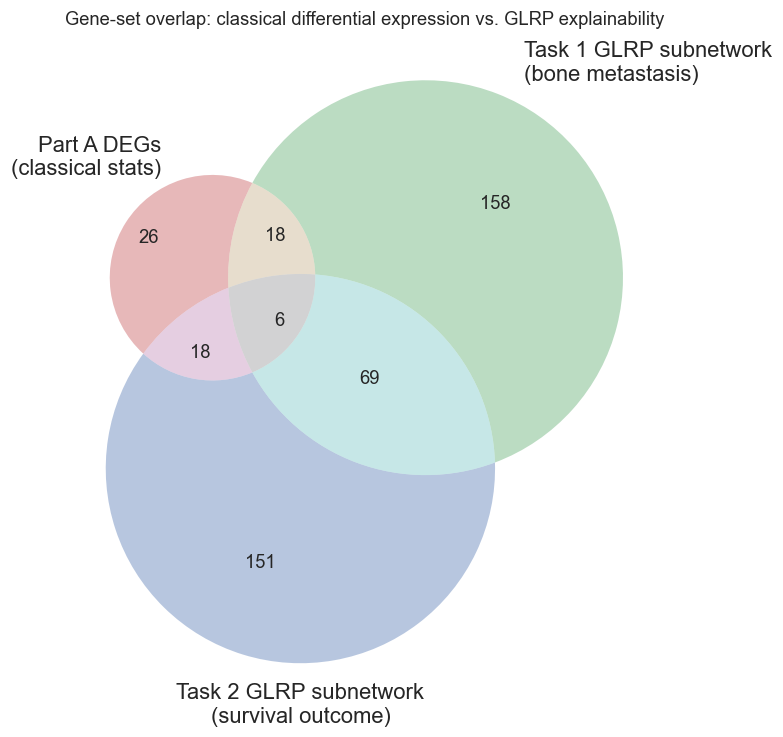

DEGs also in Task 1 (bone metastasis) GLRP subnetwork: 24/68 DEGs -- ['AGR2', 'BCAS1', 'BMP2', 'CCL21', 'CDH3', 'CHAD', 'COL11A1', 'COMP', 'CXCL9', 'DPT', 'ENPP2', 'EYA1', 'EYA2', 'EYA4', 'FGFR3', 'FLNC', 'FOXA1', 'FZD8', 'GREM1', 'ITGB3', 'OLFML2B', 'SPP1', 'TIMP4', 'WIF1']
DEGs also in Task 2 (survival) GLRP subnetwork: 24/68 DEGs -- ['AGR2', 'ALDH1A1', 'BMP2', 'CCL2', 'CD36', 'CEACAM6', 'CKB', 'COLEC12', 'CXCL10', 'CXCL9', 'ESR1', 'FGFR3', 'FOXC2', 'GREM1', 'HBB', 'IBSP', 'ITGB3', 'LEPR', 'LIFR', 'LPL', 'MARCO', 'MMP9', 'RORB', 'WNT2']
In all three: ['AGR2', 'BMP2', 'CXCL9', 'FGFR3', 'GREM1', 'ITGB3']
DEGs vs Task 1 GLRP subnetwork: 24 overlapping genes (out of 66 and 251, universe=737) -- hypergeometric P=0.3863
DEGs vs Task 2 GLRP subnetwork: 24 overlapping genes (out of 66 and 244, universe=737) -- hypergeometric P=0.3221

Paper 1's 5 named hub genes -- where does each show up?


,gene,Part A: significant DEG,Task 1 GLRP subnetwork,Task 2 GLRP subnetwork
0,MMP9,True,False,True
1,ITGB3,True,True,True
2,BMP2,True,True,True
3,CCL2,True,False,True
4,PROM1,True,False,False


In [57]:
from matplotlib_venn import venn3

deg_set = set(deg_sig["gene"])
task1_subnet_genes = set(glrp_results["bone_metastasis"][1][2]) | set(glrp_results["bone_metastasis"][0][2])
task2_subnet_genes = set(glrp_results["survival_outcome"][1][2]) | set(glrp_results["survival_outcome"][0][2])

fig, ax = plt.subplots(figsize=(7, 7))
venn3([deg_set, task1_subnet_genes, task2_subnet_genes],
      set_labels=("Part A DEGs\n(classical stats)", "Task 1 GLRP subnetwork\n(bone metastasis)", "Task 2 GLRP subnetwork\n(survival outcome)"),
      ax=ax)
ax.set_title("Gene-set overlap: classical differential expression vs. GLRP explainability")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/12_venn_overlap.png"); plt.show()

overlap_deg_task1 = deg_set & task1_subnet_genes
overlap_deg_task2 = deg_set & task2_subnet_genes
overlap_all_three = deg_set & task1_subnet_genes & task2_subnet_genes
print(f"DEGs also in Task 1 (bone metastasis) GLRP subnetwork: {len(overlap_deg_task1)}/{len(deg_set)} DEGs -- {sorted(overlap_deg_task1)}")
print(f"DEGs also in Task 2 (survival) GLRP subnetwork: {len(overlap_deg_task2)}/{len(deg_set)} DEGs -- {sorted(overlap_deg_task2)}")
print(f"In all three: {sorted(overlap_all_three)}")

# Cross-method overlap: is this bigger than chance, not just a raw count? Both gene
# sets are drawn from the same 737-gene panel, so hypergeometric enrichment against
# that panel (not the whole genome) is the right test here.
from scipy.stats import hypergeom

def _overlap_hypergeom(set_a, set_b, universe, label_a, label_b):
    universe_size = len(universe)
    a_in_u, b_in_u = set_a & universe, set_b & universe
    k_observed = len(a_in_u & b_in_u)
    p = hypergeom.sf(k_observed - 1, universe_size, len(a_in_u), len(b_in_u))
    print(f"{label_a} vs {label_b}: {k_observed} overlapping genes "
          f"(out of {len(a_in_u)} and {len(b_in_u)}, universe={universe_size}) -- "
          f"hypergeometric P={p:.4g}")
    return p

gene_universe = set(gene_list)
p_overlap_task1 = _overlap_hypergeom(deg_set, task1_subnet_genes, gene_universe,
                                      "DEGs", "Task 1 GLRP subnetwork")
p_overlap_task2 = _overlap_hypergeom(deg_set, task2_subnet_genes, gene_universe,
                                      "DEGs", "Task 2 GLRP subnetwork")

print("\nPaper 1's 5 named hub genes -- where does each show up?")
hub_gene_overlap_rows = []
for g in HUB_GENES:
    hub_gene_overlap_rows.append((g, g in deg_set, g in task1_subnet_genes, g in task2_subnet_genes))
display(pd.DataFrame(hub_gene_overlap_rows, columns=["gene", "Part A: significant DEG", "Task 1 GLRP subnetwork", "Task 2 GLRP subnetwork"]))

,gene,"DEG rank (of 771, by p-value)",Cox survival p-value,Cox significant (P<0.05),Task1 GLRP subnetwork rank (of 140),Task2 GLRP subnetwork rank (of 140)
0,MMP9,2,0.268798,False,NaN,73.0
1,ITGB3,5,0.568104,False,37.0,73.0
2,BMP2,12,0.251819,False,48.0,138.0
3,CCL2,41,0.007161,True,NaN,41.0
4,PROM1,33,0.005113,True,NaN,NaN


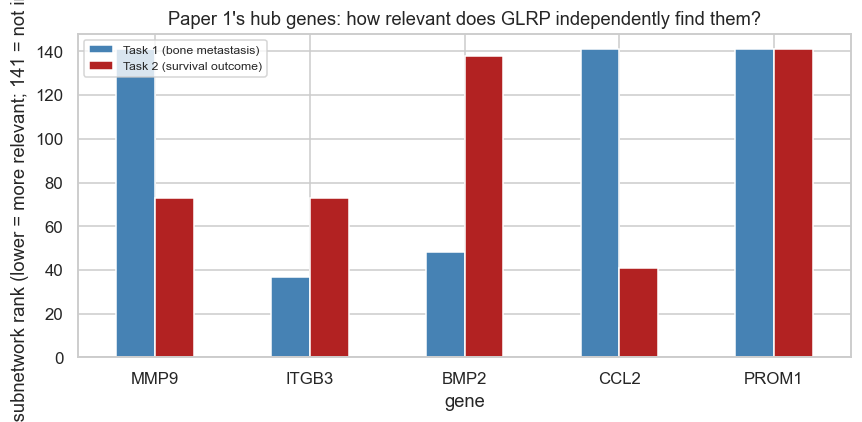

In [58]:
leaderboard_rows = []
for gene in HUB_GENES:
    deg_rank = int(deg["pvalue"].rank()[deg["gene"] == gene].iloc[0]) if gene in deg["gene"].values else None
    cox_p = cox_indexed.loc[gene, "pvalue"] if gene in cox_indexed.index else np.nan
    t1_rank = min([r for r in [in_subnetwork_rank("bone_metastasis", c, gene) for c in [0, 1]] if r is not None], default=None)
    t2_rank = min([r for r in [in_subnetwork_rank("survival_outcome", c, gene) for c in [0, 1]] if r is not None], default=None)
    leaderboard_rows.append({
        "gene": gene,
        "DEG rank (of 771, by p-value)": deg_rank,
        "Cox survival p-value": cox_p,
        "Cox significant (P<0.05)": cox_p < 0.05 if pd.notna(cox_p) else False,
        "Task1 GLRP subnetwork rank (of 140)": t1_rank,
        "Task2 GLRP subnetwork rank (of 140)": t2_rank,
    })
leaderboard = pd.DataFrame(leaderboard_rows)
leaderboard.to_csv(f"{OUT_DIR}/hub_gene_leaderboard.csv", index=False)
display(leaderboard)

fig, ax = plt.subplots(figsize=(8, 4))
plot_data = leaderboard.set_index("gene")[["Task1 GLRP subnetwork rank (of 140)", "Task2 GLRP subnetwork rank (of 140)"]].fillna(141)
plot_data.plot(kind="bar", ax=ax, color=["steelblue", "firebrick"])
ax.set_ylabel("GLRP subnetwork rank (lower = more relevant; 141 = not in top-140)")
ax.set_title("Paper 1's hub genes: how relevant does GLRP independently find them?")
ax.legend(["Task 1 (bone metastasis)", "Task 2 (survival outcome)"], fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/13_hub_gene_leaderboard.png"); plt.show()

In [59]:
def _safe_to_markdown(df_):
    # .to_markdown() needs the optional "tabulate" package; fall back to plain
    # CSV-style text (still readable, just not markdown-table-formatted) if it's
    # missing rather than crashing the whole report cell over one pretty-printer.
    try:
        return df_.to_markdown(index=False)
    except ImportError:
        return df_.to_csv(index=False)

report_lines = [
    "# Combined reproduction report: Paper 1 (classical stats) + Paper 2 (Graph-CNN/GLRP), same data",
    "",
    "Generated by Combined_BRCA_GLRP_synthesis.ipynb",
    "",
    "## Part A (classical) key results",
    f"- DEGs identified using BH-FDR < {DEG_FDR_CUTOFF} and |logFC| > {DEG_LOGFC_CUTOFF}: {len(deg_sig)}",
    f"- Data-driven hub-gene shortlist: {', '.join(sorted(data_driven_hub))}",
    f"- Prognostic genes, univariate Cox, nominal P<0.05: {sig_genes_raw}",
    f"- Prognostic genes, univariate Cox, BH-FDR<0.05 across the 5 candidate genes: {sig_genes_fdr}",
    "",
    "## Part B (Graph-CNN + GLRP) key results",
    "",
    "Primary evaluation (Section 12P; fold-internal preprocessing, 5 x 5-fold, shared partitions):",
    _safe_to_markdown(primary_summary[["task", "model", "fold_averaged_AUC_mean", "fold_averaged_AUC_sd",
                                       "pooled_OOF_AUC_mean", "pooled_OOF_AUC_sd"]].round(3)),
    "",
    "## Part C (synthesis) key results",
    "",
    _safe_to_markdown(leaderboard),
    "",
    f"- FDR-significant DEGs also in Task 1 GLRP subnetwork: {sorted(overlap_deg_task1)} "
    f"(hypergeometric P={p_overlap_task1:.4g} against the 737-gene panel)",
    f"- FDR-significant DEGs also in Task 2 GLRP subnetwork: {sorted(overlap_deg_task2)} "
    f"(hypergeometric P={p_overlap_task2:.4g} against the 737-gene panel)",
    "",
    "Task 3B within-bone-met gene-wise Cox results are exploratory because of the small subgroup/event count and require independent validation.",
    "See the notebook for full methodology, all tables, and all visualizations.",
]
with open(f"{OUT_DIR}/results_summary.md", "w") as f:
    f.write("\n".join(report_lines))
print(f"Report saved to {OUT_DIR}/results_summary.md")


Report saved to ./output/results_summary.md


In [60]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from lifelines import CoxPHFitter


def bone_met_only_survival_analysis(expr175, clin175, gene_list):
    """Restrict to the 33 real bone-metastasis patients only, then ask which
    genes (of the modeling panel) are prognostic WITHIN that group -- a
    question the original paper and notebook never ask, since both only ever
    contrast bone-met against non-bone-met."""
    bone_mask = clin175["organ"] == "Bone"
    bm_clin = clin175.loc[bone_mask]
    bm_expr = expr175.loc[gene_list, bone_mask.index[bone_mask]]

    surv = bm_clin[["ose", "os (months) since dxmet"]].copy()
    surv.columns = ["event", "time_months"]
    surv["event"] = pd.to_numeric(surv["event"], errors="coerce")
    surv["time_months"] = pd.to_numeric(surv["time_months"], errors="coerce")

    rows = []
    for gene in gene_list:
        df = surv.join(bm_expr.loc[gene].rename(gene)).dropna()
        if len(df) < 15 or df["event"].sum() < 5:
            continue  # too few bone-met patients / events for a stable Cox fit
        cph = CoxPHFitter()
        try:
            cph.fit(df[["time_months", "event", gene]], duration_col="time_months", event_col="event")
        except Exception:
            continue
        s = cph.summary.loc[gene]
        rows.append((gene, s["exp(coef)"], s["p"], len(df), int(df["event"].sum())))

    out = pd.DataFrame(rows, columns=["gene", "HR", "pvalue", "n_bone_met_patients", "n_events"])
    out["FDR"] = multipletests(out["pvalue"], method="fdr_bh")[1] if len(out) else []
    return out.sort_values("pvalue")

In [61]:
bone_met_only_results = bone_met_only_survival_analysis(expr175, clin175, gene_list)
display(bone_met_only_results.head(20))

bone_met_only_out_path = os.path.join(OUT_DIR, "task3B_within_bonemet_cox_survival.csv")
bone_met_only_results.to_csv(bone_met_only_out_path, index=False)
print("Saved to:", os.path.abspath(bone_met_only_out_path))

,gene,HR,pvalue,n_bone_met_patients,n_events,FDR
531,PLA2G3,0.322796,0.001023,31,11,0.754045
667,TCF4,3.846591,0.012470,31,11,0.915200
181,DCN,3.158044,0.019748,31,11,0.915200
37,BAMBI,1.864118,0.020203,31,11,0.915200
628,SMAD1,4.139785,0.024630,31,11,0.915200
647,SPN,0.509685,0.024989,31,11,0.915200
249,FGFR4,1.574798,0.026066,31,11,0.915200
26,ASPN,1.872698,0.026677,31,11,0.915200
65,CA12,0.734114,0.027561,31,11,0.915200
475,NOD2,0.472095,0.028684,31,11,0.915200


Saved to: /Users/soumyasriperepu/researchAgent/version 14/output/task3B_within_bonemet_cox_survival.csv


In [62]:
def primary_vs_bonemet_paired_analysis(expr_bulk, clin_bulk, patient_col, tissue_col,
                                        primary_label="Primary", bonemet_label="Bone metastasis"):
    """Paired within-patient differential expression: primary tumor vs bone metastasis.

    If more than one sample exists for a patient/tissue combination, expression is
    averaged within that patient/tissue stratum before the paired Wilcoxon test.
    """
    if patient_col not in clin_bulk.columns or tissue_col not in clin_bulk.columns:
        raise KeyError(f"Required metadata columns not found: patient_col={patient_col!r}, tissue_col={tissue_col!r}")

    meta = clin_bulk[[patient_col, tissue_col]].copy()
    meta[patient_col] = meta[patient_col].astype(str).str.strip()
    meta[tissue_col] = meta[tissue_col].astype(str).str.strip()
    joined = expr_bulk.T.join(meta, how="inner")

    # Average technical/biological replicates within a patient x tissue stratum.
    numeric_genes = [g for g in expr_bulk.index if g in joined.columns]
    collapsed = joined.groupby([patient_col, tissue_col])[numeric_genes].mean(numeric_only=True)
    paired = collapsed.unstack(tissue_col)

    rows = []
    for gene in numeric_genes:
        try:
            a = paired[(gene, bonemet_label)].dropna()
            b = paired[(gene, primary_label)].dropna()
        except KeyError:
            continue
        common = a.index.intersection(b.index)
        if len(common) < 2:
            continue
        delta = a.loc[common] - b.loc[common]
        if np.allclose(delta.to_numpy(), 0, equal_nan=True):
            p = 1.0
        else:
            _, p = stats.wilcoxon(a.loc[common], b.loc[common], zero_method="wilcox", alternative="two-sided")
        rows.append((gene, delta.mean(), p, len(common)))

    out = pd.DataFrame(rows, columns=["gene", "mean_delta_bonemet_minus_primary", "pvalue", "n_pairs"])
    if len(out):
        out["FDR"] = multipletests(out["pvalue"], method="fdr_bh")[1]
        out = out.sort_values(["FDR", "pvalue", "gene"]).reset_index(drop=True)
    else:
        out["FDR"] = pd.Series(dtype=float)
    return out


In [63]:
try:
    import GEOparse
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "GEOparse"], check=True)
    import GEOparse

gse_super = GEOparse.get_GEO(geo="GSE190772", destdir=DATA_DIR, silent=True)
relation_lines = gse_super.metadata.get("relation", [])
subseries_ids = [r.split(":", 1)[-1].strip() for r in relation_lines if "SuperSeries of" in r]
print("GSE190772 is a SuperSeries of:", subseries_ids)

bulk_subseries_id = None
for sid in subseries_ids:
    sub = GEOparse.get_GEO(geo=sid, destdir=DATA_DIR, silent=True)
    title = sub.metadata.get("title", [""])[0]
    summary = " ".join(sub.metadata.get("summary", []))
    lib_strategies = sorted({
        gsm.metadata.get("library_strategy", [""])[0]
        for gsm in sub.gsms.values()
    }) if hasattr(sub, "gsms") else []
    print(f"  {sid}: {title!r}")
    print(f"      library strategies: {lib_strategies}")
    if any("rna-seq" in s.lower() for s in lib_strategies) and "single cell" not in title.lower():
        bulk_subseries_id = sid

if bulk_subseries_id:
    print("\nAuto-identified bulk RNA-seq SubSeries:", bulk_subseries_id)
else:
    print("\nCouldn't auto-identify the bulk-arm SubSeries from the titles/library")
    print("strategies printed above -- read them and set it manually, e.g.:")
    print('  bulk_subseries_id = "GSE1909xx"')

GSE190772 is a SuperSeries of: []

Couldn't auto-identify the bulk-arm SubSeries from the titles/library
strategies printed above -- read them and set it manually, e.g.:
  bulk_subseries_id = "GSE1909xx"


In [64]:
# ============================================================
# Task 3A — GSE190772 bulk RNA-seq
# Primary tumor vs bone metastasis
# ============================================================

bulk_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE190nnn/GSE190772/suppl/"
    "GSE190772_BoM_primary_bulkRNA.txt.gz"
)

bulk_path = os.path.join(
    DATA_DIR,
    "GSE190772_BoM_primary_bulkRNA.txt.gz"
)

download(bulk_url, bulk_path)

# Read processed bulk RNA expression table
expr_bulk_raw = pd.read_csv(
    bulk_path,
    sep="\t",
    compression="gzip",
    index_col=0
)

print("GSE190772 bulk RNA-seq shape:", expr_bulk_raw.shape)

display(expr_bulk_raw.head())
print("\nColumns:")
print(expr_bulk_raw.columns.tolist())

GSE190772 bulk RNA-seq shape: (37214, 3)


,Primary,BoM1,BoM2
converted,,,
TSPAN6,3.144109,3.642574,4.117340
TNMD,0.990361,0.000000,0.419557
DPM1,5.748180,6.343638,6.576481
SCYL3,5.220854,3.898331,4.690257
C1orf112,4.997593,4.689186,5.372271



Columns:
['Primary', 'BoM1', 'BoM2']


In [65]:
print("Shape:", expr_bulk_raw.shape)
print("Columns:")
for c in expr_bulk_raw.columns:
    print(c)

Shape: (37214, 3)
Columns:
Primary
BoM1
BoM2


In [66]:
# ============================================================
# Task 3A — inspect and classify GSE190772 bulk samples directly
# ============================================================

expr_bulk = expr_bulk_raw.copy()

# Clean sample names
expr_bulk.columns = [
    str(c).strip().replace('"', '')
    for c in expr_bulk.columns
]

print("Available bulk RNA-seq samples:")
for c in expr_bulk.columns:
    print(" -", c)

Available bulk RNA-seq samples:
 - Primary
 - BoM1
 - BoM2


In [67]:
# Canonical major-compartment markers explicitly reported by Hu et al. (2026).
# This is intentionally a conservative reference, not a fabricated full marker table.
HU_CANONICAL_MARKERS = {
    "epithelial/tumor": ["EPCAM", "KRT8", "KRT18"],
    "myeloid/macrophage": ["IL3RA", "CD14", "C1QA", "LYZ"],
    "T cell": ["CD3D", "CD2", "TRBC2"],
    "B cell": ["CD79A", "CD79B", "MS4A1"],
    "endothelial": ["PECAM1", "CDH5", "PLVAP", "ENG"],
    "fibroblast/perivascular": ["DCN", "RGS5", "MYH11", "COL1A1"],
    "mast cell": ["TPSB2", "TPSAB1", "CPA3"],
    "plasma cell": ["CD79A", "JCHAIN", "MZB1"],
}

celltype_marker_table = pd.DataFrame(
    [(gene, cell_type, "Hu et al. 2026 canonical marker")
     for cell_type, genes in HU_CANONICAL_MARKERS.items()
     for gene in genes],
    columns=["gene", "cell_type", "evidence"]
)

def annotate_gene_compartment_origin(gene_list, marker_table,
                                      gene_col="gene", celltype_col="cell_type"):
    """Annotate genes against an explicit cell-compartment marker reference.

    All matching compartments are retained. Absence from this conservative
    canonical-marker list is not interpreted as evidence of no cell-type origin.
    """
    needed = {gene_col, celltype_col}
    missing = needed.difference(marker_table.columns)
    if missing:
        raise ValueError(f"Marker table is missing required columns: {sorted(missing)}")

    mt = marker_table.copy()
    mt[gene_col] = mt[gene_col].astype(str).str.upper().str.strip()
    mt[celltype_col] = mt[celltype_col].astype(str).str.strip()
    rows = []
    for gene in gene_list:
        g = str(gene).upper().strip()
        hits = mt.loc[mt[gene_col] == g, celltype_col].dropna().drop_duplicates().tolist()
        if not hits:
            rows.append((gene, None, 0, "not assigned by canonical-marker reference"))
        else:
            rows.append((gene, "; ".join(hits), len(hits), "canonical marker match"))
    return pd.DataFrame(rows, columns=["gene", "compartment(s)", "n_compartments", "note"])

print(f"Hu canonical-marker reference ready: {len(celltype_marker_table)} marker rows across {celltype_marker_table['cell_type'].nunique()} compartments.")
display(celltype_marker_table)


Hu canonical-marker reference ready: 27 marker rows across 8 compartments.


,gene,cell_type,evidence
0,EPCAM,epithelial/tumor,Hu et al. 2026 canonical marker
1,KRT8,epithelial/tumor,Hu et al. 2026 canonical marker
2,KRT18,epithelial/tumor,Hu et al. 2026 canonical marker
3,IL3RA,myeloid/macrophage,Hu et al. 2026 canonical marker
4,CD14,myeloid/macrophage,Hu et al. 2026 canonical marker
5,C1QA,myeloid/macrophage,Hu et al. 2026 canonical marker
6,LYZ,myeloid/macrophage,Hu et al. 2026 canonical marker
7,CD3D,T cell,Hu et al. 2026 canonical marker
8,CD2,T cell,Hu et al. 2026 canonical marker
9,TRBC2,T cell,Hu et al. 2026 canonical marker


In [68]:
patient_rel = pd.DataFrame({
    "gene": gene_list,
    "relevance": np.abs(rel)
})

# attach cell-type origin
patient_origin = patient_rel.merge(
    celltype_marker_table,
    on="gene",
    how="left"
)

patient_origin["cell_type"] = (
    patient_origin["cell_type"]
    .fillna("Unassigned")
)

# Sum GLRP importance by compartment
compartment_scores = (
    patient_origin
    .groupby("cell_type")["relevance"]
    .sum()
    .sort_values(ascending=False)
)

# Convert to percentage
compartment_percent = (
    compartment_scores /
    compartment_scores.sum() * 100
)

display(compartment_percent)

cell_type
Unassigned                 99.074043
endothelial                 0.763448
fibroblast/perivascular     0.078755
mast cell                   0.068065
myeloid/macrophage          0.015694
Name: relevance, dtype: float32

In [69]:
hub_gene_origins = annotate_gene_compartment_origin(HUB_GENES, celltype_marker_table)
display(hub_gene_origins)

hub_gene_origins_out_path = os.path.join(OUT_DIR, "task4_hub_gene_compartment_origins.csv")
hub_gene_origins.to_csv(hub_gene_origins_out_path, index=False)
print("Saved to:", os.path.abspath(hub_gene_origins_out_path))

# Also annotate the FDR-significant DEGs and save them for synthesis.
deg_gene_origins = annotate_gene_compartment_origin(deg_sig["gene"].tolist(), celltype_marker_table)
deg_gene_origins_out_path = os.path.join(OUT_DIR, "task4_deg_compartment_origins.csv")
deg_gene_origins.to_csv(deg_gene_origins_out_path, index=False)
print("Saved to:", os.path.abspath(deg_gene_origins_out_path))


,gene,compartment(s),n_compartments,note
0,MMP9,None,0,not assigned by canonical-marker reference
1,ITGB3,None,0,not assigned by canonical-marker reference
2,BMP2,None,0,not assigned by canonical-marker reference
3,CCL2,None,0,not assigned by canonical-marker reference
4,PROM1,None,0,not assigned by canonical-marker reference


Saved to: /Users/soumyasriperepu/researchAgent/version 14/output/task4_hub_gene_compartment_origins.csv
Saved to: /Users/soumyasriperepu/researchAgent/version 14/output/task4_deg_compartment_origins.csv


In [70]:
glrp_compartment_rows = []
for task_name in glrp_results:
    for target_class, (patient_id, rel, subnetwork_genes) in glrp_results[task_name].items():
        origins = annotate_gene_compartment_origin(subnetwork_genes, celltype_marker_table)
        assigned = origins.dropna(subset=["compartment(s)"]).copy()

        # A marker such as CD79A can legitimately map to more than one major compartment;
        # explode those matches rather than arbitrarily choosing one.
        if not assigned.empty:
            exploded = assigned.assign(
                compartment=assigned["compartment(s)"].str.split("; ")
            ).explode("compartment")
            counts = exploded["compartment"].value_counts()
            for compartment, n_genes in counts.items():
                glrp_compartment_rows.append({
                    "task": task_name,
                    "class": target_class,
                    "patient_id": patient_id,
                    "compartment": compartment,
                    "n_canonical_marker_genes_in_top_subnetwork": int(n_genes),
                })
        n_unassigned = int(origins["compartment(s)"].isna().sum())
        glrp_compartment_rows.append({
            "task": task_name,
            "class": target_class,
            "patient_id": patient_id,
            "compartment": "unassigned_by_canonical_reference",
            "n_canonical_marker_genes_in_top_subnetwork": n_unassigned,
        })

glrp_compartment_summary = pd.DataFrame(glrp_compartment_rows)
display(glrp_compartment_summary)
glrp_compartment_out_path = os.path.join(OUT_DIR, "task4_glrp_compartment_summary.csv")
glrp_compartment_summary.to_csv(glrp_compartment_out_path, index=False)
print("Saved to:", os.path.abspath(glrp_compartment_out_path))


,task,class,patient_id,compartment,n_canonical_marker_genes_in_top_subnetwork
0,bone_metastasis,1,GSM5344087,fibroblast/perivascular,1
1,bone_metastasis,1,GSM5344087,unassigned_by_canonical_reference,139
2,bone_metastasis,0,GSM5344131,unassigned_by_canonical_reference,140
3,survival_outcome,1,GSM5344134,endothelial,2
4,survival_outcome,1,GSM5344134,fibroblast/perivascular,1
5,survival_outcome,1,GSM5344134,unassigned_by_canonical_reference,137
6,survival_outcome,0,GSM5344055,endothelial,2
7,survival_outcome,0,GSM5344055,fibroblast/perivascular,1
8,survival_outcome,0,GSM5344055,unassigned_by_canonical_reference,137


Saved to: /Users/soumyasriperepu/researchAgent/version 14/output/task4_glrp_compartment_summary.csv


In [71]:
# ============================================================
# Task 4B
# Patient-specific cellular origin of the GLRP signal
# Bone-metastasis patients only
# ============================================================

# We only want Task 1, class = 1
# class 1 = bone metastasis
bone_patients = multi_patient_results["bone_metastasis"][1]

print("Bone-metastasis patients used:")
for p in bone_patients:
    print(" ", p["patient_id"])

Bone-metastasis patients used:
  GSM5344087
  GSM5344119
  GSM5344170
  GSM5344148


In [72]:
# ============================================================
# Map one patient's GLRP relevance onto cell compartments
# ============================================================

def glrp_compartment_analysis(
    patient,
    gene_list,
    marker_table,
    top_n=140
):
    """
    For one correctly-classified bone-metastasis patient:

    1. Take absolute GLRP relevance for every gene.
    2. Keep the top_n most relevant genes.
    3. Match genes against the Hu et al. canonical cell-type markers.
    4. Sum GLRP relevance by compartment.
    5. Convert the compartment relevance to percentage.

    Important:
    This estimates which CELLULAR COMPARTMENTS are associated
    with the model's important genes. It does not prove the exact
    anatomical location of every transcript.
    """

    # -----------------------------
    # 1. GLRP gene relevance
    # -----------------------------
    rel_df = pd.DataFrame({
        "gene": gene_list,
        "relevance": np.abs(patient["relevance"])
    })

    rel_df["gene"] = (
        rel_df["gene"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    rel_df = (
        rel_df
        .sort_values("relevance", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

    rel_df["GLRP_rank"] = np.arange(1, len(rel_df) + 1)

    # -----------------------------
    # 2. Prepare marker table
    # -----------------------------
    marker = marker_table.copy()

    marker["gene"] = (
        marker["gene"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    marker["cell_type"] = (
        marker["cell_type"]
        .astype(str)
        .str.strip()
    )

    # -----------------------------
    # 3. Merge GLRP genes with
    #    cell-compartment markers
    # -----------------------------
    mapped = rel_df.merge(
        marker[["gene", "cell_type"]],
        on="gene",
        how="left"
    )

    mapped["cell_type"] = mapped["cell_type"].fillna(
        "Unassigned"
    )

    # If a gene maps to >1 cell type,
    # divide its relevance equally so
    # we do not double count it.
    n_hits = (
        mapped
        .groupby("gene")["cell_type"]
        .transform("count")
    )

    mapped["weighted_relevance"] = (
        mapped["relevance"] / n_hits
    )

    # -----------------------------
    # 4. Sum relevance by compartment
    # -----------------------------
    summary = (
        mapped
        .groupby("cell_type", as_index=False)
        ["weighted_relevance"]
        .sum()
        .rename(
            columns={
                "weighted_relevance":
                "GLRP_relevance"
            }
        )
    )

    total = summary["GLRP_relevance"].sum()

    summary["percent_total_GLRP"] = (
        summary["GLRP_relevance"] /
        total * 100
    )

    summary = summary.sort_values(
        "percent_total_GLRP",
        ascending=False
    ).reset_index(drop=True)

    # Add patient ID
    summary.insert(
        0,
        "patient_id",
        patient["patient_id"]
    )

    mapped.insert(
        0,
        "patient_id",
        patient["patient_id"]
    )

    return mapped, summary

In [73]:
# ============================================================
# Run cell-origin analysis for 3 bone-metastasis patients
# ============================================================

N_PATIENTS_FOR_ORIGIN = 3

origin_gene_tables = {}
origin_summaries = {}

for patient in bone_patients[:N_PATIENTS_FOR_ORIGIN]:

    pid = patient["patient_id"]

    gene_table, summary = glrp_compartment_analysis(
        patient=patient,
        gene_list=gene_list,
        marker_table=celltype_marker_table,
        top_n=140
    )

    origin_gene_tables[pid] = gene_table
    origin_summaries[pid] = summary

    print("\n====================================")
    print("Patient:", pid)
    print("====================================")

    display(summary)


Patient: GSM5344087


,patient_id,cell_type,GLRP_relevance,percent_total_GLRP
0,GSM5344087,Unassigned,0.303936,98.379824
1,GSM5344087,fibroblast/perivascular,0.005005,1.620176



Patient: GSM5344119


,patient_id,cell_type,GLRP_relevance,percent_total_GLRP
0,GSM5344119,Unassigned,0.545326,99.668772
1,GSM5344119,mast cell,0.001812,0.331228



Patient: GSM5344170


,patient_id,cell_type,GLRP_relevance,percent_total_GLRP
0,GSM5344170,Unassigned,0.593361,99.624799
1,GSM5344170,fibroblast/perivascular,0.002235,0.375201


In [74]:
# ============================================================
# Save Task 4 outputs
# ============================================================

all_gene_origin = pd.concat(
    origin_gene_tables.values(),
    ignore_index=True
)

all_summary_origin = pd.concat(
    origin_summaries.values(),
    ignore_index=True
)

all_gene_origin.to_csv(
    os.path.join(
        OUT_DIR,
        "task4_bonemet_patient_gene_compartment_mapping.csv"
    ),
    index=False
)

all_summary_origin.to_csv(
    os.path.join(
        OUT_DIR,
        "task4_bonemet_patient_compartment_GLRP_summary.csv"
    ),
    index=False
)

all_summary_origin.to_csv(
    os.path.join(
        OUT_DIR,
        "task4_three_patient_compartment_comparison.csv"
    )
)

print("Task 4 sample-specific compartment results saved.")

Task 4 sample-specific compartment results saved.


In [75]:
# ============================================================
# IMPORTANT diagnostic:
# How much GLRP relevance could actually be assigned?
# ============================================================

coverage_rows = []

for pid, gene_table in origin_gene_tables.items():

    total_rel = gene_table["weighted_relevance"].sum()

    assigned_rel = gene_table.loc[
        gene_table["cell_type"] != "Unassigned",
        "weighted_relevance"
    ].sum()

    coverage = (
        assigned_rel / total_rel * 100
        if total_rel > 0 else np.nan
    )

    coverage_rows.append({
        "patient_id": pid,
        "assigned_GLRP_percent": coverage,
        "unassigned_GLRP_percent": 100 - coverage
    })

coverage_df = pd.DataFrame(coverage_rows)

display(coverage_df)

,patient_id,assigned_GLRP_percent,unassigned_GLRP_percent
0,GSM5344087,1.620176,98.379824
1,GSM5344119,0.331228,99.668772
2,GSM5344170,0.375201,99.624799


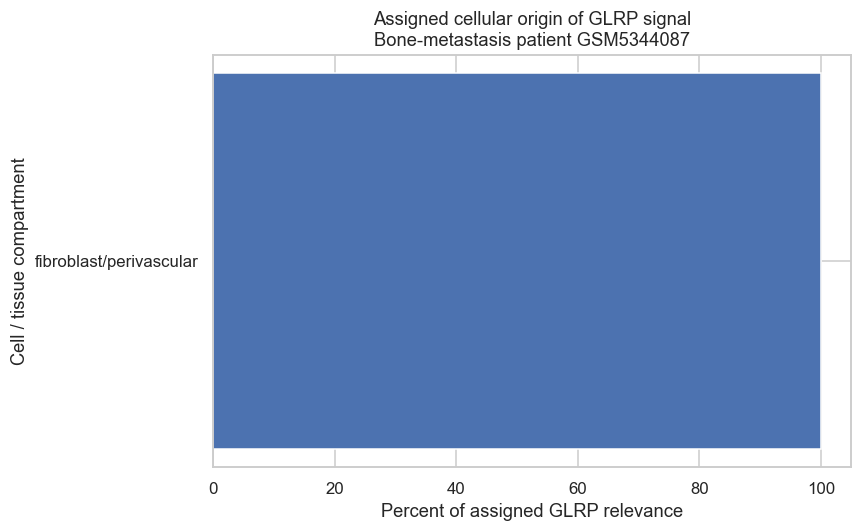

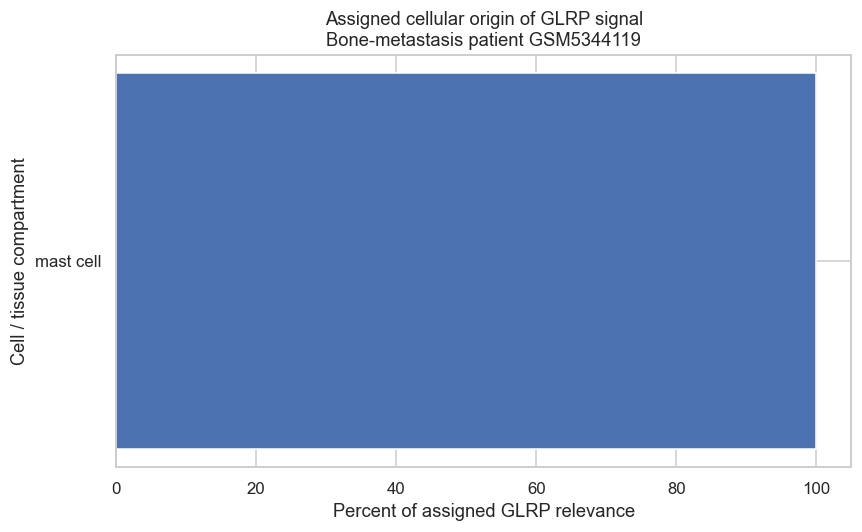

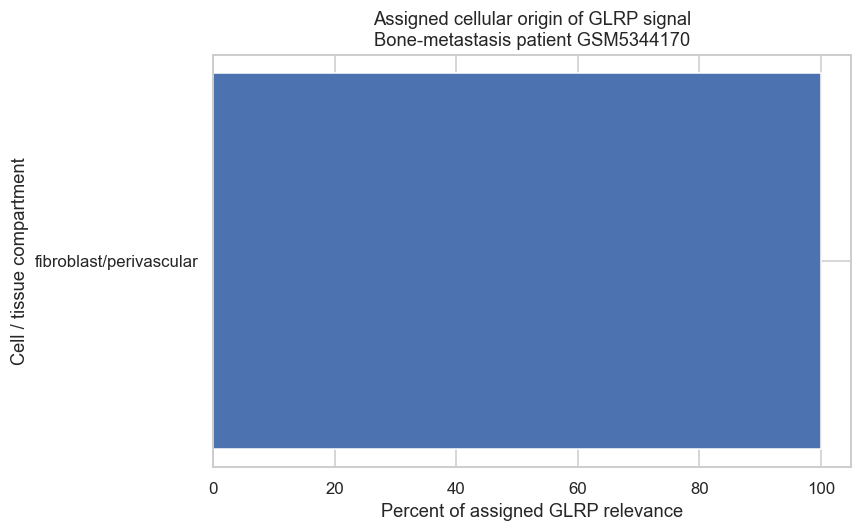

In [76]:
# ============================================================
# Assigned-marker signal only
# ============================================================

for pid, summary in origin_summaries.items():

    assigned = summary[
        summary["cell_type"] != "Unassigned"
    ].copy()

    if assigned.empty:
        print(
            f"{pid}: no top GLRP genes matched "
            "the canonical marker reference."
        )
        continue

    assigned["percent_assigned_signal"] = (
        assigned["GLRP_relevance"] /
        assigned["GLRP_relevance"].sum()
        * 100
    )

    assigned = assigned.sort_values(
        "percent_assigned_signal",
        ascending=True
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        assigned["cell_type"],
        assigned["percent_assigned_signal"]
    )

    plt.xlabel(
        "Percent of assigned GLRP relevance"
    )

    plt.ylabel(
        "Cell / tissue compartment"
    )

    plt.title(
        f"Assigned cellular origin of GLRP signal\n"
        f"Bone-metastasis patient {pid}"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIG_DIR,
            f"task4_assigned_origin_{pid}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [77]:
# ============================================================
# Frozen external-validation gene panel
# ============================================================

EXTERNAL_TOP_GLRP_PER_PATIENT = 40
EXTERNAL_TOP_BONE_COX = 40

external_gene_sources = {}
external_gene_sources["GSE175692_DEG"] = set(deg_sig["gene"].astype(str).str.upper())
external_gene_sources["Paper1_hubs"] = set(str(g).upper() for g in HUB_GENES)

task1_bone_glrp = set()
if "multi_patient_results" in globals():
    for p in multi_patient_results.get("bone_metastasis", {}).get(1, []):
        s = pd.Series(np.abs(p["relevance"]),
                      index=[str(g).upper() for g in gene_list]).sort_values(ascending=False)
        task1_bone_glrp.update(s.head(EXTERNAL_TOP_GLRP_PER_PATIENT).index.tolist())
else:
    pid, rel_, _ = glrp_results["bone_metastasis"][1]
    s = pd.Series(np.abs(rel_),
                  index=[str(g).upper() for g in gene_list]).sort_values(ascending=False)
    task1_bone_glrp.update(s.head(EXTERNAL_TOP_GLRP_PER_PATIENT).index.tolist())

external_gene_sources["Task1_bone_GLRP"] = task1_bone_glrp

if "bone_met_only_results" in globals() and len(bone_met_only_results):
    external_gene_sources["Within_bone_Cox"] = set(
        bone_met_only_results.sort_values("pvalue").head(EXTERNAL_TOP_BONE_COX)["gene"]
        .astype(str).str.upper()
    )
else:
    external_gene_sources["Within_bone_Cox"] = set()

external_validation_genes = sorted(set().union(*external_gene_sources.values()))

external_gene_membership = pd.DataFrame({"gene": external_validation_genes})
for source_name, source_genes in external_gene_sources.items():
    external_gene_membership[source_name] = external_gene_membership["gene"].isin(source_genes)

external_gene_membership["n_notebook_sources"] = (
    external_gene_membership[list(external_gene_sources.keys())].sum(axis=1)
)

external_gene_membership = external_gene_membership.sort_values(
    ["n_notebook_sources", "gene"], ascending=[False, True]
).reset_index(drop=True)

print(f"Frozen external-validation panel: {len(external_validation_genes)} unique genes")
display(external_gene_membership.head(30))

external_gene_membership.to_csv(
    os.path.join(OUT_DIR, "task5_6_frozen_external_validation_gene_panel.csv"),
    index=False
)


Frozen external-validation panel: 209 unique genes


,gene,GSE175692_DEG,Paper1_hubs,Task1_bone_GLRP,Within_bone_Cox,n_notebook_sources
0,BAMBI,True,False,True,True,3
1,ITGB3,True,True,True,False,3
2,ASPN,False,False,True,True,2
3,BMP2,True,True,False,False,2
4,BMPR1B,False,False,True,True,2
5,CACNA1H,False,False,True,True,2
6,CCL2,True,True,False,False,2
7,CCL21,True,False,True,False,2
8,CDKN2D,False,False,True,True,2
9,COL11A1,True,False,True,False,2


In [78]:
# ============================================================
# Task 5A — discover GSE131007 processed supplementary files
# ============================================================

from urllib.parse import urljoin, unquote
import re

GSE131007_SUPPL_DIR = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE131nnn/GSE131007/suppl/"
)

def list_geo_supplementary_files(suppl_url):
    r = requests.get(suppl_url, timeout=120)
    r.raise_for_status()
    hrefs = re.findall(r'href=["\']([^"\']+)["\']', r.text, flags=re.I)
    files = []
    for href in hrefs:
        name = unquote(href.split("/")[-1])
        if not name or name in {".", ".."}:
            continue
        if any(name.lower().endswith(ext) for ext in
               (".gz", ".txt", ".tsv", ".csv", ".mtx", ".rds", ".h5", ".h5ad", ".tar")):
            files.append((name, urljoin(suppl_url, href)))
    seen, out = set(), []
    for item in files:
        if item[0] not in seen:
            out.append(item)
            seen.add(item[0])
    return out

gse131007_files = list_geo_supplementary_files(GSE131007_SUPPL_DIR)

print("GSE131007 supplementary files discovered:")
for name, url in gse131007_files:
    print(" ", name)

if not gse131007_files:
    raise RuntimeError("No GSE131007 supplementary files were discovered.")


GSE131007 supplementary files discovered:
  GSE131007_ucd46_count_matrix.tsv.gz
  GSE131007_ucd4_count_matrix.tsv.gz
  GSE131007_ucd65_count_matrix.tsv.gz


In [79]:
# ============================================================
# Task 5B — download tabular GSE131007 processed files
# ============================================================

GSE131007_DIR = os.path.join(DATA_DIR, "GSE131007")
os.makedirs(GSE131007_DIR, exist_ok=True)

gse131007_local = {}
for name, url in gse131007_files:
    if not any(name.lower().endswith(ext) for ext in
               (".txt", ".txt.gz", ".tsv", ".tsv.gz", ".csv", ".csv.gz")):
        continue
    dest = os.path.join(GSE131007_DIR, name)
    try:
        download(url, dest, timeout=240)
        gse131007_local[name] = dest
    except Exception as e:
        print(f"Could not download {name}: {e}")

print(f"Downloaded {len(gse131007_local)} tabular processed files to {GSE131007_DIR}")


Downloaded 3 tabular processed files to ./data/GSE131007


In [80]:
# ============================================================
# Task 5C — audit file shapes and infer matrix/metadata roles
# ============================================================

def read_geo_table_auto(path):
    compression = "gzip" if str(path).lower().endswith(".gz") else None
    try:
        df = pd.read_csv(path, sep="\t", compression=compression, low_memory=False)
        if df.shape[1] > 1:
            return df
    except Exception:
        pass
    return pd.read_csv(path, sep=",", compression=compression, low_memory=False)

gse131007_tables = {}
audit_rows = []

for name, path_ in gse131007_local.items():
    try:
        df_ = read_geo_table_auto(path_)
        gse131007_tables[name] = df_
        lower_cols = [str(c).lower() for c in df_.columns]
        role = "unknown"
        if df_.shape[0] > 1000 and df_.shape[1] > 100:
            role = "possible_gene_x_cell_matrix"
        if any(any(k in c for k in ["cell", "barcode", "tissue", "site", "source", "organ"])
               for c in lower_cols) and df_.shape[1] < 100:
            role = "possible_cell_metadata"
        audit_rows.append({
            "file": name, "rows": df_.shape[0], "columns": df_.shape[1],
            "role_guess": role,
            "first_columns": ", ".join(map(str, df_.columns[:8]))
        })
    except Exception as e:
        audit_rows.append({
            "file": name, "rows": np.nan, "columns": np.nan,
            "role_guess": "parse_failed", "first_columns": str(e)[:120]
        })

gse131007_audit = pd.DataFrame(audit_rows)
display(gse131007_audit)

gse131007_audit.to_csv(
    os.path.join(OUT_DIR, "task5_GSE131007_file_audit.csv"),
    index=False
)


,file,rows,columns,role_guess,first_columns
0,GSE131007_ucd46_count_matrix.tsv.gz,16767,747,possible_gene_x_cell_matrix,"gene, UCD46T_AAACGGGGTGTTCGAT, UCD46T_AAATGCCT..."
1,GSE131007_ucd4_count_matrix.tsv.gz,19086,6695,possible_gene_x_cell_matrix,"gene, UCD4T_AAACCTGAGCCATCGC, UCD4T_AAACCTGAGG..."
2,GSE131007_ucd65_count_matrix.tsv.gz,16816,1868,possible_gene_x_cell_matrix,"gene, UCD65T_AAACCTGCAGCATGAG, UCD65T_AAACCTGC..."


In [81]:
# ============================================================
# Task 5D — harmonize matrices and recover site labels
# ============================================================

GSE131007_FILE_SITE_OVERRIDES = {
    # "exact_processed_filename.tsv.gz": "Bone",
}

VALID_SITES = {"PRIMARY", "BONE", "BRAIN", "LIVER"}

def normalize_site_label(x):
    if pd.isna(x):
        return None
    s = str(x).strip().upper()
    if "BONE" in s or re.search(r"\bBM\b", s):
        return "Bone"
    if "BRAIN" in s:
        return "Brain"
    if "LIVER" in s:
        return "Liver"
    if "PRIMARY" in s or "MAMMARY" in s or re.search(r"\bMFP\b", s):
        return "Primary"
    # Fallback: GSE131007's own barcode naming convention embeds an abbreviated
    # site code directly after the sample number, no separator -- e.g. a column
    # named "UCD65Bo_AAACGGG..." or "UCD46L_...". CONFIRMED codes, from the actual
    # prefixes recovered across all 3 matrices by the Item 11 diagnostic below:
    #   ucd46: L, T   |   ucd4: L, T   |   ucd65: Bo, Br, T
    # i.e. exactly {T, L, Bo, Br} -- single-letter L for Liver and T for Primary/
    # Tumor (unambiguous on their own), two-letter Bo/Br for Bone/Brain (both start
    # with B, so need the second letter to disambiguate). No Lung samples exist in
    # this dataset -- there is no "Lu"/"LU" code to guess. (An earlier version of
    # this fix incorrectly guessed a two-letter "LI" for Liver, which never matched
    # the real single-letter "L" -- that's fixed here.)
    ABBREV_SITE_CODES = {"T": "Primary", "L": "Liver", "BO": "Bone", "BR": "Brain"}
    prefix = s.split("_")[0]
    m = re.match(r"^UCD\d+([A-Z]+)$", prefix)
    if m and m.group(1) in ABBREV_SITE_CODES:
        return ABBREV_SITE_CODES[m.group(1)]
    return None

def standardize_gene_cell_matrix(df):
    x = df.copy()
    first_col = x.columns[0]
    candidate = x[first_col].astype(str)
    if candidate.nunique(dropna=True) >= 0.8 * len(candidate):
        x = x.set_index(first_col)
    x.index = x.index.astype(str).str.upper().str.strip()
    x = x.apply(pd.to_numeric, errors="coerce")
    x = x.loc[:, x.notna().sum(axis=0) > 0]
    return x

matrix_candidates = []
metadata_candidates = []

for name, df_ in gse131007_tables.items():
    if df_.shape[0] > 1000 and df_.shape[1] > 100:
        try:
            m = standardize_gene_cell_matrix(df_)
            if m.shape[0] > 1000 and m.shape[1] > 100:
                matrix_candidates.append((name, m))
        except Exception:
            pass
    lower_cols = [str(c).lower() for c in df_.columns]
    if any(any(k in c for k in ["cell", "barcode", "tissue", "site", "source", "organ"])
           for c in lower_cols):
        metadata_candidates.append((name, df_.copy()))

print("Possible gene x cell matrices:")
for name, m in matrix_candidates:
    print(" ", name, m.shape)

print("\nPossible metadata tables:")
for name, d in metadata_candidates:
    print(" ", name, d.shape)


Possible gene x cell matrices:
  GSE131007_ucd46_count_matrix.tsv.gz (16767, 746)
  GSE131007_ucd4_count_matrix.tsv.gz (19086, 6694)
  GSE131007_ucd65_count_matrix.tsv.gz (16816, 1867)

Possible metadata tables:


In [82]:
# ============================================================
# Task 5E — build per-cell site metadata when possible
# ============================================================

def infer_cell_metadata(metadata_candidates):
    rows = []
    for fname, df_ in metadata_candidates:
        cols = {str(c).lower(): c for c in df_.columns}
        barcode_col = None
        for key, original in cols.items():
            if any(k in key for k in ["barcode", "cell_id", "cellid", "cell"]):
                barcode_col = original
                break
        site_col = None
        for key, original in cols.items():
            if any(k in key for k in ["tissue", "site", "source", "organ", "sample"]):
                site_col = original
                break
        if barcode_col is None or site_col is None:
            continue
        tmp = df_[[barcode_col, site_col]].copy()
        tmp.columns = ["cell_id", "raw_site"]
        tmp["site"] = tmp["raw_site"].map(normalize_site_label)
        tmp["metadata_file"] = fname
        tmp = tmp.dropna(subset=["cell_id", "site"])
        rows.append(tmp)
    if not rows:
        return pd.DataFrame(columns=["cell_id", "raw_site", "site", "metadata_file"])
    return pd.concat(rows, ignore_index=True).drop_duplicates(subset=["cell_id"])

gse131007_cell_metadata = infer_cell_metadata(metadata_candidates)

print("Cell-level site annotations recovered:", len(gse131007_cell_metadata))
if len(gse131007_cell_metadata):
    display(gse131007_cell_metadata["site"].value_counts().rename_axis("site").reset_index(name="n_cells"))


Cell-level site annotations recovered: 0


In [83]:
# ============================================================
# Task 5F — external organ-specific validation
# ============================================================

def _safe_log_transform(expr, label=""):
    """
    Log-transform apparent raw counts before z-scoring, but print the actual value
    range and the decision made -- applying log1p to data that's already been
    normalized/log-transformed upstream (which can differ file to file in GSE131007's
    processed supplementary matrices) would silently double-transform it. Whether
    that's happening here can't be verified without knowing each file's own upstream
    processing, so the decision is surfaced explicitly instead of hidden inside a
    one-line ternary -- check this printout if any GSE131007 result looks off.
    """
    vmin, vmax, vmean = np.nanmin(expr.values), np.nanmax(expr.values), np.nanmean(expr.values)
    looks_like_raw_counts = (vmin >= 0) and (vmax > 20)
    print(f"  [{label}] expression range: min={vmin:.2f}, max={vmax:.2f}, mean={vmean:.2f} -- "
          f"{'applying log1p (range consistent with raw counts)' if looks_like_raw_counts else 'NOT applying log1p -- range is small/negative, may already be normalized upstream; verify against the source file if a result here looks wrong'}")
    return np.log1p(expr) if looks_like_raw_counts else expr.copy()

task5_cell_level_rows = []
task5_site_summaries = []

for fname, mat in matrix_candidates:
    file_site = GSE131007_FILE_SITE_OVERRIDES.get(fname)

    if file_site is not None:
        if str(file_site).upper() not in VALID_SITES:
            raise ValueError(f"Invalid site override for {fname}: {file_site}")
        site_by_cell = pd.Series(file_site, index=mat.columns, name="site")
    else:
        meta_map = (gse131007_cell_metadata.set_index("cell_id")["site"]
                    if len(gse131007_cell_metadata) else pd.Series(dtype=object))
        site_by_cell = pd.Series([meta_map.get(c, None) for c in mat.columns],
                                 index=mat.columns, name="site")
        missing = site_by_cell.isna()
        if missing.any():
            site_by_cell.loc[missing] = [normalize_site_label(c)
                                         for c in site_by_cell.index[missing]]

    usable_cells = site_by_cell.dropna().index.intersection(mat.columns)
    if len(usable_cells) == 0:
        print(f"{fname}: no trustworthy site labels could be assigned; skipping.")
        continue

    common_genes = sorted(set(external_validation_genes).intersection(mat.index))
    if not common_genes:
        print(f"{fname}: no frozen candidate genes matched matrix row names.")
        continue

    expr = mat.loc[common_genes, usable_cells].copy()
    expr_for_score = _safe_log_transform(expr, label=fname)

    gene_mean = expr_for_score.mean(axis=1)
    gene_sd = expr_for_score.std(axis=1).replace(0, np.nan)
    z = expr_for_score.sub(gene_mean, axis=0).div(gene_sd, axis=0)
    cell_signature = z.mean(axis=0, skipna=True)

    cell_df = pd.DataFrame({
        "file": fname,
        "cell_id": cell_signature.index,
        "site": site_by_cell.loc[cell_signature.index].values,
        "notebook_candidate_signature": cell_signature.values
    })
    task5_cell_level_rows.append(cell_df)

    for gene in common_genes:
        tmp = pd.DataFrame({
            "site": site_by_cell.loc[usable_cells].values,
            "expression": expr_for_score.loc[gene, usable_cells].values
        })
        means = tmp.groupby("site")["expression"].mean()
        row = {"file": fname, "gene": gene, "n_labeled_cells": len(tmp)}
        for site in ["Primary", "Bone", "Brain", "Liver"]:
            row[f"mean_{site}"] = means.get(site, np.nan)
        if "Bone" in means.index:
            other_vals = means.drop(labels=["Bone"], errors="ignore")
            row["Bone_minus_mean_other_sites"] = (
                means["Bone"] - other_vals.mean() if len(other_vals) else np.nan
            )
        else:
            row["Bone_minus_mean_other_sites"] = np.nan
        task5_site_summaries.append(row)

task5_cell_level = pd.concat(task5_cell_level_rows, ignore_index=True) if task5_cell_level_rows else pd.DataFrame()
task5_gene_site_summary = pd.DataFrame(task5_site_summaries)

if len(task5_cell_level):
    display(task5_cell_level.groupby("site")["notebook_candidate_signature"]
            .agg(["count", "mean", "median", "std"]).sort_values("mean", ascending=False))
    task5_cell_level.to_csv(
        os.path.join(OUT_DIR, "task5_GSE131007_cell_signature_scores.csv"),
        index=False
    )

if len(task5_gene_site_summary):
    task5_gene_site_summary = task5_gene_site_summary.sort_values(
        "Bone_minus_mean_other_sites", ascending=False, na_position="last"
    )
    display(task5_gene_site_summary.head(30))
    task5_gene_site_summary.to_csv(
        os.path.join(OUT_DIR, "task5_GSE131007_candidate_gene_site_validation.csv"),
        index=False
    )


  [GSE131007_ucd46_count_matrix.tsv.gz] expression range: min=0.00, max=1243.00, mean=2.88 -- applying log1p (range consistent with raw counts)
  [GSE131007_ucd4_count_matrix.tsv.gz] expression range: min=0.00, max=1077.00, mean=0.94 -- applying log1p (range consistent with raw counts)


  [GSE131007_ucd65_count_matrix.tsv.gz] expression range: min=0.00, max=576.00, mean=0.91 -- applying log1p (range consistent with raw counts)


,count,mean,median,std
site,,,,
Brain,110,0.325670,0.300848,0.371197
Primary,5285,0.006193,-0.031819,0.212322
Liver,3314,-0.014464,-0.065044,0.213272
Bone,598,-0.034479,-0.061629,0.202170


,file,gene,n_labeled_cells,mean_Primary,mean_Bone,mean_Brain,mean_Liver,Bone_minus_mean_other_sites
418,GSE131007_ucd65_count_matrix.tsv.gz,ID1,1867,0.320416,0.847178,0.158297,NaN,0.607822
427,GSE131007_ucd65_count_matrix.tsv.gz,JUN,1867,0.349824,1.091981,0.660943,NaN,0.586597
419,GSE131007_ucd65_count_matrix.tsv.gz,ID2,1867,0.697490,1.082565,1.149471,NaN,0.159084
399,GSE131007_ucd65_count_matrix.tsv.gz,FZD7,1867,0.085592,0.359781,0.376217,NaN,0.128877
473,GSE131007_ucd65_count_matrix.tsv.gz,SOX9,1867,0.187241,0.388580,0.419339,NaN,0.085290
390,GSE131007_ucd65_count_matrix.tsv.gz,FGFR3,1867,0.110596,0.151300,0.044109,NaN,0.073947
450,GSE131007_ucd65_count_matrix.tsv.gz,PIK3R2,1867,0.013755,0.105021,0.056712,NaN,0.069787
431,GSE131007_ucd65_count_matrix.tsv.gz,LFNG,1867,0.047653,0.143578,0.111880,NaN,0.063812
401,GSE131007_ucd65_count_matrix.tsv.gz,GADD45A,1867,0.206940,0.498596,0.687078,NaN,0.051587
360,GSE131007_ucd65_count_matrix.tsv.gz,CDKN2D,1867,0.070786,0.169953,0.170620,NaN,0.049250


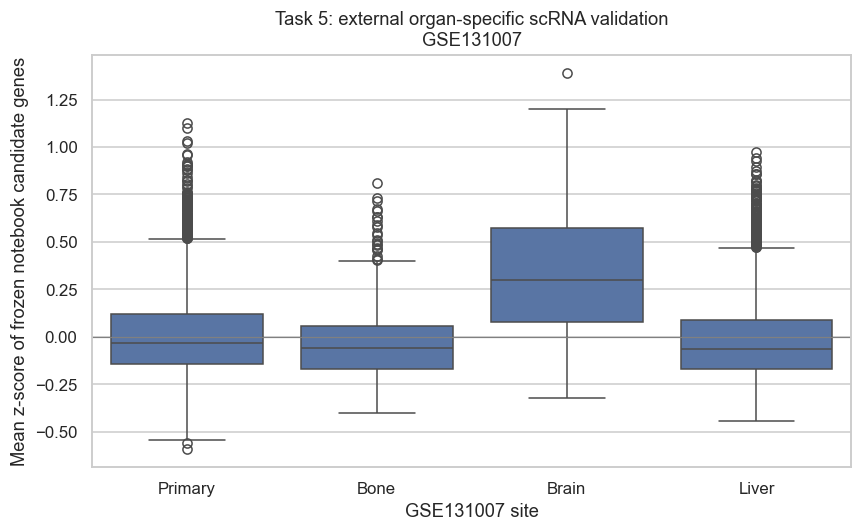

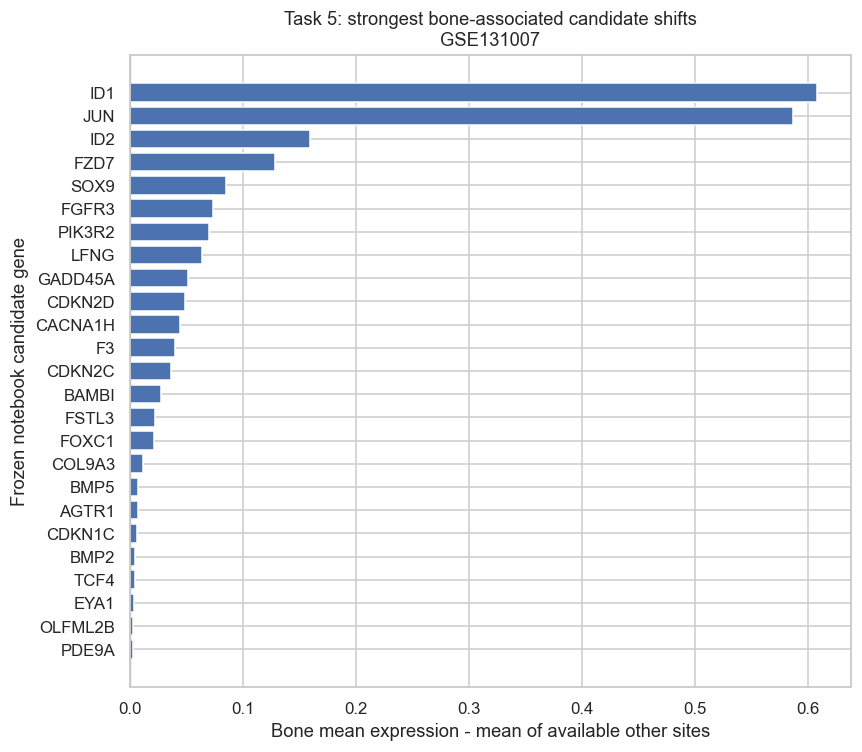

In [84]:
# ============================================================
# Task 5G — plots
# ============================================================

if len(task5_cell_level):
    sites_order = [s for s in ["Primary", "Bone", "Brain", "Liver"]
                   if s in set(task5_cell_level["site"])]
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=task5_cell_level, x="site",
                y="notebook_candidate_signature", order=sites_order)
    plt.axhline(0, lw=0.8, color="grey")
    plt.xlabel("GSE131007 site")
    plt.ylabel("Mean z-score of frozen notebook candidate genes")
    plt.title("Task 5: external organ-specific scRNA validation\nGSE131007")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "task5_GSE131007_candidate_signature_by_site.png"),
                dpi=300, bbox_inches="tight")
    plt.show()

if len(task5_gene_site_summary):
    plot_task5 = (task5_gene_site_summary
                  .dropna(subset=["Bone_minus_mean_other_sites"])
                  .head(25)
                  .sort_values("Bone_minus_mean_other_sites"))
    if len(plot_task5):
        plt.figure(figsize=(8, max(5, 0.28 * len(plot_task5))))
        plt.barh(plot_task5["gene"], plot_task5["Bone_minus_mean_other_sites"])
        plt.axvline(0, lw=0.8, color="grey")
        plt.xlabel("Bone mean expression - mean of available other sites")
        plt.ylabel("Frozen notebook candidate gene")
        plt.title("Task 5: strongest bone-associated candidate shifts\nGSE131007")
        plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, "task5_GSE131007_bone_specific_candidate_genes.png"),
                    dpi=300, bbox_inches="tight")
        plt.show()


In [85]:
print(f"Matrix candidates found: {len(matrix_candidates)}")
for name, m in matrix_candidates:
    print(f"  {name}: {m.shape[0]} rows x {m.shape[1]} columns")

print(f"\nMetadata candidates found: {len(metadata_candidates)}")
for name, df_ in metadata_candidates:
    print(f"  {name}: columns = {list(df_.columns)}")

print(f"\nCell-level site annotations recovered via metadata: {len(gse131007_cell_metadata)}")

if len(gse131007_cell_metadata) == 0 and metadata_candidates:
    print("\nMetadata tables were found, but no column's values normalized to a site label.")
    print("Raw values actually present in the columns that matched the tissue/site/source/organ/sample keywords:")
    for fname, df_ in metadata_candidates:
        cols = {str(c).lower(): c for c in df_.columns}
        for key, original in cols.items():
            if any(k in key for k in ["tissue", "site", "source", "organ", "sample"]):
                vals = df_[original].dropna().astype(str).unique()[:15]
                print(f"  {fname} :: column '{original}': {list(vals)}")

if not metadata_candidates:
    print("\nNo table's column names matched the keyword search "
          "(tissue/site/source/organ/sample, or cell/barcode/cell_id) at all.")
    print("Actual column names in every downloaded table, for a manual look:")
    for fname, df_ in gse131007_tables.items():
        print(f"  {fname}: {list(df_.columns)[:20]}")

if matrix_candidates:
    print("\nFallback check -- do the matrices' own column names (cell barcodes) carry a "
          "recognizable site keyword (BONE/BRAIN/LIVER/PRIMARY/MFP/BM), the way GSE131007's "
          "loader falls back to when no metadata match exists?")
    for name, m in matrix_candidates:
        recognized = sum(1 for c in m.columns if normalize_site_label(c) is not None)
        print(f"  {name}: {recognized}/{len(m.columns)} column names matched a site keyword "
              f"(sample columns: {list(m.columns[:5])})")

print("\nRead this before deciding whether to cut Section 23: a naming-convention mismatch "
      "(e.g. a 'group' or 'condition' column not in the keyword list, or site names embedded "
      "in a filename rather than a column) is fixable by widening the keyword list or adding "
      "a GSE131007_FILE_SITE_OVERRIDES entry; truly absent site information is not.")


Matrix candidates found: 3
  GSE131007_ucd46_count_matrix.tsv.gz: 16767 rows x 746 columns
  GSE131007_ucd4_count_matrix.tsv.gz: 19086 rows x 6694 columns
  GSE131007_ucd65_count_matrix.tsv.gz: 16816 rows x 1867 columns

Metadata candidates found: 0

Cell-level site annotations recovered via metadata: 0

No table's column names matched the keyword search (tissue/site/source/organ/sample, or cell/barcode/cell_id) at all.
Actual column names in every downloaded table, for a manual look:
  GSE131007_ucd46_count_matrix.tsv.gz: ['gene', 'UCD46T_AAACGGGGTGTTCGAT', 'UCD46T_AAATGCCTCACCATAG', 'UCD46T_AACGTTGCAAGCGCTC', 'UCD46T_AACTCAGGTGTCCTCT', 'UCD46T_AACTCCCTCGCCTGTT', 'UCD46T_AACTTTCTCACATAGC', 'UCD46T_AAGACCTCACAGATTC', 'UCD46T_AAGCCGCGTGAGTGAC', 'UCD46T_AAGGCAGCAATGGAGC', 'UCD46T_AAGGCAGCAGTCAGAG', 'UCD46T_AAGGCAGTCCTAGGGC', 'UCD46T_AAGGTTCGTGGTTTCA', 'UCD46T_AAGGTTCTCTGCGACG', 'UCD46T_AATCGGTTCGGCTTGG', 'UCD46T_ACACCAAAGGGTCTCC', 'UCD46T_ACACCAACACATCTTT', 'UCD46T_ACACCAAGTTACAGAA', 'UC

In [86]:
COVERAGE_MIN_CELLS_PER_SITE = 30
COVERAGE_MIN_SITES = 2  # must include Bone + at least one other site

site_counts = (task5_cell_level["site"].value_counts()
               if len(task5_cell_level) else pd.Series(dtype=int))
sites_meeting_threshold = site_counts[site_counts >= COVERAGE_MIN_CELLS_PER_SITE]
bone_ok = "Bone" in sites_meeting_threshold.index
coverage_ok = bone_ok and len(sites_meeting_threshold) >= COVERAGE_MIN_SITES

print("GSE131007 site-label coverage (cells with a confidently recovered site label):")
print(site_counts)
print(f"\nSites meeting the >= {COVERAGE_MIN_CELLS_PER_SITE}-cell threshold: {list(sites_meeting_threshold.index)}")
print(f"Coverage sufficient for a reportable Results statement: {coverage_ok}")


GSE131007 site-label coverage (cells with a confidently recovered site label):
site
Primary    5285
Liver      3314
Bone        598
Brain       110
Name: count, dtype: int64

Sites meeting the >= 30-cell threshold: ['Primary', 'Liver', 'Bone', 'Brain']
Coverage sufficient for a reportable Results statement: True


In [87]:
try:
    from statsmodels.stats.multitest import multipletests
    def fdr_bh(pvals):
        return multipletests(pvals, method="fdr_bh")[1]
except ImportError:
    def fdr_bh(pvals):
        pvals = np.asarray(pvals)
        n = len(pvals)
        order = np.argsort(pvals)
        ranked = pvals[order] * n / (np.arange(n) + 1)
        ranked = np.minimum.accumulate(ranked[::-1])[::-1]
        out = np.empty(n)
        out[order] = np.clip(ranked, 0, 1)
        return out

from scipy.stats import kruskal, mannwhitneyu

if coverage_ok:
    usable_sites = list(sites_meeting_threshold.index)
    sub = task5_cell_level[task5_cell_level["site"].isin(usable_sites)]

    # Aggregate candidate-signature test across sites.
    groups = [sub.loc[sub["site"] == s, "notebook_candidate_signature"].dropna().values for s in usable_sites]
    kw_stat, kw_p = kruskal(*groups)
    print(f"Kruskal-Wallis across {usable_sites} (candidate-panel signature): H={kw_stat:.2f}, p={kw_p:.2e}")

    # Per-gene test: Bone vs. pooled-other, on log-transformed per-cell expression,
    # reconstructed from matrix_candidates + the site labels already recovered in task5_cell_level.
    per_gene_pvals = []
    for fname, mat in matrix_candidates:
        cells_this_file = task5_cell_level.loc[task5_cell_level["file"] == fname]
        if not len(cells_this_file):
            continue
        site_map = cells_this_file.set_index("cell_id")["site"]
        usable_cells = [c for c in mat.columns if c in site_map.index]
        if not usable_cells:
            continue
        common_genes = sorted(set(external_validation_genes).intersection(mat.index))
        expr = mat.loc[common_genes, usable_cells]
        expr_log = _safe_log_transform(expr, label=f"{fname} (per-gene test)")
        sites_here = site_map.loc[usable_cells]
        for gene in common_genes:
            vals = expr_log.loc[gene]
            bone_vals = vals[sites_here == "Bone"].dropna()
            other_vals = vals[sites_here != "Bone"].dropna()
            if len(bone_vals) >= 5 and len(other_vals) >= 5:
                stat, p = mannwhitneyu(bone_vals, other_vals, alternative="two-sided")
                per_gene_pvals.append({"file": fname, "gene": gene, "n_bone": len(bone_vals),
                                        "n_other": len(other_vals), "mannwhitney_p": p})

    per_gene_df = pd.DataFrame(per_gene_pvals)
    if len(per_gene_df):
        per_gene_df["fdr_q"] = fdr_bh(per_gene_df["mannwhitney_p"].values)
        per_gene_df = per_gene_df.sort_values("fdr_q")
        per_gene_df.to_csv(os.path.join(OUT_DIR, "task5_GSE131007_per_gene_bone_vs_other_FDR.csv"), index=False)
        print(f"\nPer-gene Bone-vs-other test, FDR-corrected ({len(per_gene_df)} gene x file rows):")
        display(per_gene_df.head(20))
    else:
        print("\nNo gene had >=5 labeled cells in both Bone and other sites -- per-gene test not run.")

    # PROM1 can appear once per matrix file; a file with no Bone-labeled cells for
    # it gives Bone_minus_mean_other_sites = NaN even when another file has real data.
    # Blindly taking .iloc[0] picked whichever file happened to be first, which could
    # be the NaN one -- prefer a row that actually has a value instead.
    prom1_rows = task5_gene_site_summary[task5_gene_site_summary["gene"] == "PROM1"]
    prom1_valid = prom1_rows.dropna(subset=["Bone_minus_mean_other_sites"])
    if len(prom1_valid):
        _r = prom1_valid.iloc[0]
        prom1_note = (f"PROM1 showed a Bone-minus-other-sites shift of "
                       f"{_r['Bone_minus_mean_other_sites']:.2f} "
                       f"(n={_r['n_labeled_cells']} labeled cells, from {_r['file']}).")
    elif len(prom1_rows):
        prom1_note = "PROM1 was present in labeled matrices, but no single file had both Bone and other-site cells for it."
    else:
        prom1_note = "PROM1 was not present in the confidently labeled matrices."

    print("\n--- Draft Results sentence (verify the actual numbers after a real run before pasting) ---")
    print(
        f"Among {sub.shape[0]} cells with confidently recovered site labels across "
        f"{', '.join(usable_sites)}, the frozen candidate-gene signature differed significantly "
        f"by site (Kruskal-Wallis, H={kw_stat:.2f}, p={kw_p:.2e}). {prom1_note}"
    )
else:
    print("Coverage check failed -- see the 'insufficient coverage' cell below instead of running this one.")


Kruskal-Wallis across ['Primary', 'Liver', 'Bone', 'Brain'] (candidate-panel signature): H=148.46, p=5.67e-32
  [GSE131007_ucd46_count_matrix.tsv.gz (per-gene test)] expression range: min=0.00, max=1243.00, mean=2.88 -- applying log1p (range consistent with raw counts)
  [GSE131007_ucd4_count_matrix.tsv.gz (per-gene test)] expression range: min=0.00, max=1077.00, mean=0.94 -- applying log1p (range consistent with raw counts)


  [GSE131007_ucd65_count_matrix.tsv.gz (per-gene test)] expression range: min=0.00, max=576.00, mean=0.91 -- applying log1p (range consistent with raw counts)

Per-gene Bone-vs-other test, FDR-corrected (159 gene x file rows):


,file,gene,n_bone,n_other,mannwhitney_p,fdr_q
82,GSE131007_ucd65_count_matrix.tsv.gz,HLA-A,598,1269,1.331924e-176,2.117760e-174
83,GSE131007_ucd65_count_matrix.tsv.gz,HLA-B,598,1269,6.645819e-174,5.283426e-172
136,GSE131007_ucd65_count_matrix.tsv.gz,SLC39A6,598,1269,3.985082e-77,2.112094e-75
96,GSE131007_ucd65_count_matrix.tsv.gz,JUN,598,1269,4.998084e-75,1.986738e-73
49,GSE131007_ucd65_count_matrix.tsv.gz,ENO1,598,1269,3.670412e-65,9.726591e-64
15,GSE131007_ucd65_count_matrix.tsv.gz,BMPR1B,598,1269,3.444085e-65,9.726591e-64
87,GSE131007_ucd65_count_matrix.tsv.gz,ID1,598,1269,2.695714e-53,6.123122e-52
104,GSE131007_ucd65_count_matrix.tsv.gz,MLPH,598,1269,1.145230e-37,2.276145e-36
3,GSE131007_ucd65_count_matrix.tsv.gz,AGR2,598,1269,2.546622e-35,4.499032e-34
68,GSE131007_ucd65_count_matrix.tsv.gz,FZD7,598,1269,4.883253e-35,7.764372e-34



--- Draft Results sentence (verify the actual numbers after a real run before pasting) ---
Among 9307 cells with confidently recovered site labels across Primary, Liver, Bone, Brain, the frozen candidate-gene signature differed significantly by site (Kruskal-Wallis, H=148.46, p=5.67e-32). PROM1 was present in labeled matrices, but no single file had both Bone and other-site cells for it.


In [88]:
# ============================================================
# GSE131007: biological replication vs cell counts  [R7]
# ============================================================
sc_rep = task5_cell_level.copy()
sc_rep["pdx_model"] = sc_rep["file"].str.extract(r"(ucd\d+)", flags=re.IGNORECASE)[0].str.upper()
cells_by_model_site = sc_rep.groupby(["site", "pdx_model"]).size().unstack(fill_value=0)
print("Cells per site x PDX model:")
display(cells_by_model_site)
n_models_per_site = (cells_by_model_site > 0).sum(axis=1).rename("n_independent_PDX_models")
display(n_models_per_site.to_frame())

pseudobulk = (sc_rep.groupby(["pdx_model", "site"])["notebook_candidate_signature"]
              .agg(["mean", "count"]).rename(columns={"mean": "pseudobulk_signature", "count": "n_cells"}))
print("\nPseudobulk candidate signature (one value per PDX model x site):")
display(pseudobulk.round(3))
pseudobulk.to_csv(f"{OUT_DIR}/task5_GSE131007_pseudobulk_by_model_site.csv")
cells_by_model_site.to_csv(f"{OUT_DIR}/task5_GSE131007_cells_by_model_site.csv")

bone_models = n_models_per_site.get("Bone", 0)
print(f"\nBone-site cells come from {bone_models} PDX model(s): "
      f"{list(cells_by_model_site.columns[cells_by_model_site.loc['Bone'] > 0]) if 'Bone' in cells_by_model_site.index else []}.")
if bone_models <= 1:
    print("Biological n for bone = 1. Report the bone-vs-other single-cell result descriptively "
          "(within-model, pseudobulk values above) as contextual, exploratory evidence. The cell-level "
          "Kruskal-Wallis / Mann-Whitney P values measure cell-to-cell differences within one xenograft model "
          "and must not be presented as biological replication.")


Cells per site x PDX model:


pdx_model,UCD4,UCD46,UCD65
site,,,
Bone,0,0,598
Brain,0,0,110
Liver,3038,276,0
Primary,3656,470,1159


,n_independent_PDX_models
site,
Bone,1
Brain,1
Liver,2
Primary,3



Pseudobulk candidate signature (one value per PDX model x site):


pseudobulk_signature  n_cells
pdx_model site                                  
UCD4      Liver                  -0.031     3038
          Primary                 0.026     3656
UCD46     Liver                   0.168      276
          Primary                -0.099      470
UCD65     Bone                   -0.034      598
          Brain                   0.326      110
          Primary                -0.013     1159


Bone-site cells come from 1 PDX model(s): ['UCD65'].
Biological n for bone = 1. Report the bone-vs-other single-cell result descriptively (within-model, pseudobulk values above) as contextual, exploratory evidence. The cell-level Kruskal-Wallis / Mann-Whitney P values measure cell-to-cell differences within one xenograft model and must not be presented as biological replication.


In [89]:
if not coverage_ok:
    print("--- INSUFFICIENT COVERAGE ---")
    print(f"Site counts: {dict(site_counts)}")
    print("Recommend shortening Section 23 to a short Methods note and dropping it from the main")
    print("Results, rather than reporting a quantitative claim from this few confidently-labeled cells.")
    print("\n--- Draft replacement text (paste in place of the current Section 23 Methods/Results) ---")
    print(
        "GSE131007 was examined as a potential source of organ-specific single-cell context for the "
        "frozen candidate-gene panel. Because reliable Primary/Bone/Brain/Liver site labels could be "
        "recovered for only a limited subset of cells in the processed supplementary data "
        f"({dict(site_counts)}), this comparison did not meet our pre-specified coverage threshold "
        f"(>= {COVERAGE_MIN_CELLS_PER_SITE} confidently-labeled cells in Bone plus at least one other "
        "site) and is not reported as a quantitative result; the file audit and recovered labels are "
        "provided in the accompanying code and output files for transparency."
    )
else:
    print("Coverage check passed -- see the statistical-test cell above instead of this one.")


Coverage check passed -- see the statistical-test cell above instead of this one.


In [90]:
# ============================================================
# Task 6A — download GSE334772 RSEM gene-level files
# ============================================================

GSE334772_SAMPLES = {
    "NF1_plus_rep1": {"gsm": "GSM9796867", "file": "GSM9796867_M1.rsem.genes.results.gz", "group": "NF1_plus"},
    "NF1_plus_rep2": {"gsm": "GSM9796868", "file": "GSM9796868_M2.rsem.genes.results.gz", "group": "NF1_plus"},
    "NF1_KO_rep1": {"gsm": "GSM9796869", "file": "GSM9796869_MKO1.rsem.genes.results.gz", "group": "NF1_KO"},
    "NF1_KO_rep2": {"gsm": "GSM9796870", "file": "GSM9796870_MKO2.rsem.genes.results.gz", "group": "NF1_KO"},
}

GSE334772_DIR = os.path.join(DATA_DIR, "GSE334772")
os.makedirs(GSE334772_DIR, exist_ok=True)

for sample_name, meta in GSE334772_SAMPLES.items():
    gsm = meta["gsm"]
    filename = meta["file"]
    gsm_num = int(re.sub(r"\D", "", gsm))
    gsm_block = f"GSM{gsm_num // 1000}nnn"
    url = f"https://ftp.ncbi.nlm.nih.gov/geo/samples/{gsm_block}/{gsm}/suppl/{filename}"
    dest = os.path.join(GSE334772_DIR, filename)
    print(sample_name, "->", url)
    download(url, dest, timeout=240)
    meta["path"] = dest

print("GSE334772 files downloaded.")


NF1_plus_rep1 -> https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9796nnn/GSM9796867/suppl/GSM9796867_M1.rsem.genes.results.gz
NF1_plus_rep2 -> https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9796nnn/GSM9796868/suppl/GSM9796868_M2.rsem.genes.results.gz
NF1_KO_rep1 -> https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9796nnn/GSM9796869/suppl/GSM9796869_MKO1.rsem.genes.results.gz
NF1_KO_rep2 -> https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9796nnn/GSM9796870/suppl/GSM9796870_MKO2.rsem.genes.results.gz
GSE334772 files downloaded.


In [91]:
# ============================================================
# Task 6B — construct RSEM tables
# ============================================================

rsem_tables = {}
for sample_name, meta in GSE334772_SAMPLES.items():
    df_ = pd.read_csv(meta["path"], sep="\t", compression="gzip", low_memory=False)
    needed = {"gene_id", "expected_count", "TPM"}
    missing = needed.difference(df_.columns)
    if missing:
        raise ValueError(f"{sample_name} RSEM file is missing columns: {sorted(missing)}")
    rsem_tables[sample_name] = df_

print("RSEM table shapes:")
for k, v in rsem_tables.items():
    print(" ", k, v.shape)


RSEM table shapes:
  NF1_plus_rep1 (60675, 7)
  NF1_plus_rep2 (60675, 7)
  NF1_KO_rep1 (60675, 7)
  NF1_KO_rep2 (60675, 7)


In [92]:
# ============================================================
# Task 6C — map RSEM gene IDs to gene symbols
# GSE334772 IDs look like ENSG00000000003_TSPAN6
# so the gene symbol is already embedded after the underscore.
# ============================================================

base = rsem_tables[next(iter(rsem_tables))][["gene_id"]].copy()

base["gene"] = (
    base["gene_id"]
    .astype(str)
    .str.split("_", n=1)
    .str[1]
    .str.upper()
    .str.strip()
)

print("Gene symbols mapped:", int(base["gene"].notna().sum()), "/", len(base))
display(base.head(10))

Gene symbols mapped: 60675 / 60675


,gene_id,gene
0,ENSG00000000003_TSPAN6,TSPAN6
1,ENSG00000000005_TNMD,TNMD
2,ENSG00000000419_DPM1,DPM1
3,ENSG00000000457_SCYL3,SCYL3
4,ENSG00000000460_C1orf112,C1ORF112
5,ENSG00000000938_FGR,FGR
6,ENSG00000000971_CFH,CFH
7,ENSG00000001036_FUCA2,FUCA2
8,ENSG00000001084_GCLC,GCLC
9,ENSG00000001167_NFYA,NFYA


In [93]:
# ============================================================
# Task 6D — descriptive NF1-KO expression change
# ============================================================

expr_tpm = pd.DataFrame(index=base.index)
expr_counts = pd.DataFrame(index=base.index)

for sample_name, df_ in rsem_tables.items():
    expr_tpm[sample_name] = pd.to_numeric(df_["TPM"], errors="coerce")
    expr_counts[sample_name] = pd.to_numeric(df_["expected_count"], errors="coerce")

expr_tpm["gene"] = base["gene"].values
expr_counts["gene"] = base["gene"].values

tpm_gene = (expr_tpm.dropna(subset=["gene"])
            .groupby("gene")[list(GSE334772_SAMPLES.keys())].mean())

count_gene = (expr_counts.dropna(subset=["gene"])
              .groupby("gene")[list(GSE334772_SAMPLES.keys())].sum())

plus_cols = [k for k, v in GSE334772_SAMPLES.items() if v["group"] == "NF1_plus"]
ko_cols = [k for k, v in GSE334772_SAMPLES.items() if v["group"] == "NF1_KO"]

task6_nf1 = pd.DataFrame(index=tpm_gene.index)
task6_nf1["mean_TPM_NF1_plus"] = tpm_gene[plus_cols].mean(axis=1)
task6_nf1["mean_TPM_NF1_KO"] = tpm_gene[ko_cols].mean(axis=1)
task6_nf1["log2FC_NF1KO_vs_plus"] = np.log2(
    (task6_nf1["mean_TPM_NF1_KO"] + 0.1) /
    (task6_nf1["mean_TPM_NF1_plus"] + 0.1)
)
task6_nf1["abs_log2FC"] = task6_nf1["log2FC_NF1KO_vs_plus"].abs()

task6_nf1 = (task6_nf1.sort_values("abs_log2FC", ascending=False)
             .reset_index().rename(columns={"index": "gene"}))

display(task6_nf1.head(30))

task6_nf1.to_csv(
    os.path.join(OUT_DIR, "task6_GSE334772_NF1KO_expression_changes.csv"),
    index=False
)


,gene,mean_TPM_NF1_plus,mean_TPM_NF1_KO,log2FC_NF1KO_vs_plus,abs_log2FC
0,TECRP1,0.000,104.960,10.036998,10.036998
1,USP41,0.000,74.185,9.536927,9.536927
2,TP53TG1_2,0.000,26.870,8.075212,8.075212
3,AC004824.2,23.740,0.000,-7.897240,7.897240
4,RP13-401N8.3,15.605,0.000,-7.295080,7.295080
5,CTD-2510F5.6,0.000,14.990,7.237449,7.237449
6,RP11-498C9.13,0.000,14.955,7.234099,7.234099
7,ST7-OT4_1,13.845,0.000,-7.123604,7.123604
8,RP6-65G23.5,0.000,11.595,6.869748,6.869748
9,BP-2171C21.5,11.460,0.000,-6.852998,6.852998


In [94]:
# ============================================================
# Task 6E — integrate NF1 perturbation with notebook evidence
# ============================================================

task6_integrated = external_gene_membership.merge(
    task6_nf1[["gene", "mean_TPM_NF1_plus", "mean_TPM_NF1_KO",
               "log2FC_NF1KO_vs_plus", "abs_log2FC"]],
    on="gene", how="left"
)

task6_integrated["NF1_KO_direction"] = np.select(
    [task6_integrated["log2FC_NF1KO_vs_plus"] >= 1,
     task6_integrated["log2FC_NF1KO_vs_plus"] <= -1],
    ["UP_after_NF1_KO", "DOWN_after_NF1_KO"],
    default="small_or_no_change"
)

task6_integrated = task6_integrated.sort_values(
    ["n_notebook_sources", "abs_log2FC"],
    ascending=[False, False], na_position="last"
).reset_index(drop=True)

display(task6_integrated.head(40))

task6_integrated.to_csv(
    os.path.join(OUT_DIR, "task6_GSE334772_integrated_notebook_gene_validation.csv"),
    index=False
)


,gene,GSE175692_DEG,Paper1_hubs,Task1_bone_GLRP,Within_bone_Cox,n_notebook_sources,mean_TPM_NF1_plus,mean_TPM_NF1_KO,log2FC_NF1KO_vs_plus,abs_log2FC,NF1_KO_direction
0,ITGB3,True,True,True,False,3,0.140,0.085,-0.375509,0.375509,small_or_no_change
1,BAMBI,True,False,True,True,3,60.045,73.945,0.299958,0.299958,small_or_no_change
2,MMP9,True,True,False,False,2,0.245,1.795,2.457530,2.457530,UP_after_NF1_KO
3,LIFR,True,False,True,False,2,2.605,0.585,-1.981453,1.981453,DOWN_after_NF1_KO
4,LEPR,True,False,True,False,2,1.260,0.430,-1.359542,1.359542,DOWN_after_NF1_KO
5,OLFML2B,True,False,True,False,2,0.185,0.025,-1.189034,1.189034,DOWN_after_NF1_KO
6,CCL2,True,True,False,False,2,15.510,6.895,-1.158075,1.158075,DOWN_after_NF1_KO
7,WNT5B,True,False,True,False,2,0.485,1.145,1.089637,1.089637,UP_after_NF1_KO
8,POLD1,False,False,True,True,2,28.035,58.560,1.060011,1.060011,UP_after_NF1_KO
9,BMP2,True,True,False,False,2,0.150,0.025,-1.000000,1.000000,DOWN_after_NF1_KO


In [95]:
# ============================================================
# Task 6F — strongest convergent genes + KEGG
# ============================================================

NF1_EFFECT_THRESHOLD = 1.0

task6_convergent = task6_integrated[
    task6_integrated["abs_log2FC"] >= NF1_EFFECT_THRESHOLD
].copy().sort_values(
    ["n_notebook_sources", "abs_log2FC"],
    ascending=[False, False]
)

print(f"Frozen notebook genes with |NF1-KO log2FC| >= {NF1_EFFECT_THRESHOLD}: {len(task6_convergent)}")
display(task6_convergent.head(30))

task6_convergent.to_csv(
    os.path.join(OUT_DIR, "task6_GSE334772_convergent_candidate_genes.csv"),
    index=False
)

if len(task6_convergent) >= 5:
    task6_kegg = enrichr_retry(
        task6_convergent["gene"].tolist(), ["KEGG_2021_Human"], background=gene_list
    ).sort_values("Adjusted P-value")
    display(task6_kegg[["Term", "Overlap", "Adjusted P-value", "Genes"]].head(15))
    task6_kegg.to_csv(
        os.path.join(OUT_DIR, "task6_GSE334772_convergent_KEGG.csv"),
        index=False
    )
else:
    task6_kegg = pd.DataFrame()
    print("Fewer than 5 convergent genes; skipping KEGG enrichment.")


Frozen notebook genes with |NF1-KO log2FC| >= 1.0: 59


,gene,GSE175692_DEG,Paper1_hubs,Task1_bone_GLRP,Within_bone_Cox,n_notebook_sources,mean_TPM_NF1_plus,mean_TPM_NF1_KO,log2FC_NF1KO_vs_plus,abs_log2FC,NF1_KO_direction
2,MMP9,True,True,False,False,2,0.245,1.795,2.457530,2.457530,UP_after_NF1_KO
3,LIFR,True,False,True,False,2,2.605,0.585,-1.981453,1.981453,DOWN_after_NF1_KO
4,LEPR,True,False,True,False,2,1.260,0.430,-1.359542,1.359542,DOWN_after_NF1_KO
5,OLFML2B,True,False,True,False,2,0.185,0.025,-1.189034,1.189034,DOWN_after_NF1_KO
6,CCL2,True,True,False,False,2,15.510,6.895,-1.158075,1.158075,DOWN_after_NF1_KO
7,WNT5B,True,False,True,False,2,0.485,1.145,1.089637,1.089637,UP_after_NF1_KO
8,POLD1,False,False,True,True,2,28.035,58.560,1.060011,1.060011,UP_after_NF1_KO
9,BMP2,True,True,False,False,2,0.150,0.025,-1.000000,1.000000,DOWN_after_NF1_KO
35,HLA-DRA,False,False,True,False,1,2.840,0.195,-3.317029,3.317029,DOWN_after_NF1_KO
36,AGR2,True,False,False,False,1,3.455,28.090,2.987262,2.987262,UP_after_NF1_KO


,Term,Overlap,Adjusted P-value,Genes
89,Intestinal immune network for IgA production,5/12,0.194475,HLA-DQB1;HLA-DRA;CXCL12;HLA-DRB1;HLA-DPB1
150,Staphylococcus aureus infection,5/13,0.194475,KRT14;HLA-DQB1;HLA-DRA;HLA-DRB1;HLA-DPB1
151,Systemic lupus erythematosus,4/11,0.358157,HLA-DRB1;HLA-DQB1;HLA-DRA;HLA-DPB1
14,Asthma,4/11,0.358157,HLA-DRB1;HLA-DQB1;HLA-DRA;HLA-DPB1
53,Fat digestion and absorption,2/3,0.505187,CD36;PLA2G3
145,Rheumatoid arthritis,6/29,0.505187,HLA-DQB1;HLA-DRA;CXCL12;HLA-DRB1;CCL2;HLA-DPB1
85,Influenza A,8/44,0.505187,TMPRSS2;HLA-DQB1;HLA-DRA;CXCL10;EP300;HLA-DRB1...
18,Basal cell carcinoma,6/29,0.505187,FZD7;PTCH1;GSK3B;WNT5B;GADD45A;BMP2
31,Cholesterol metabolism,2/4,0.507910,APOE;CD36
7,Allograft rejection,4/16,0.507910,HLA-DRB1;HLA-DQB1;HLA-DRA;HLA-DPB1


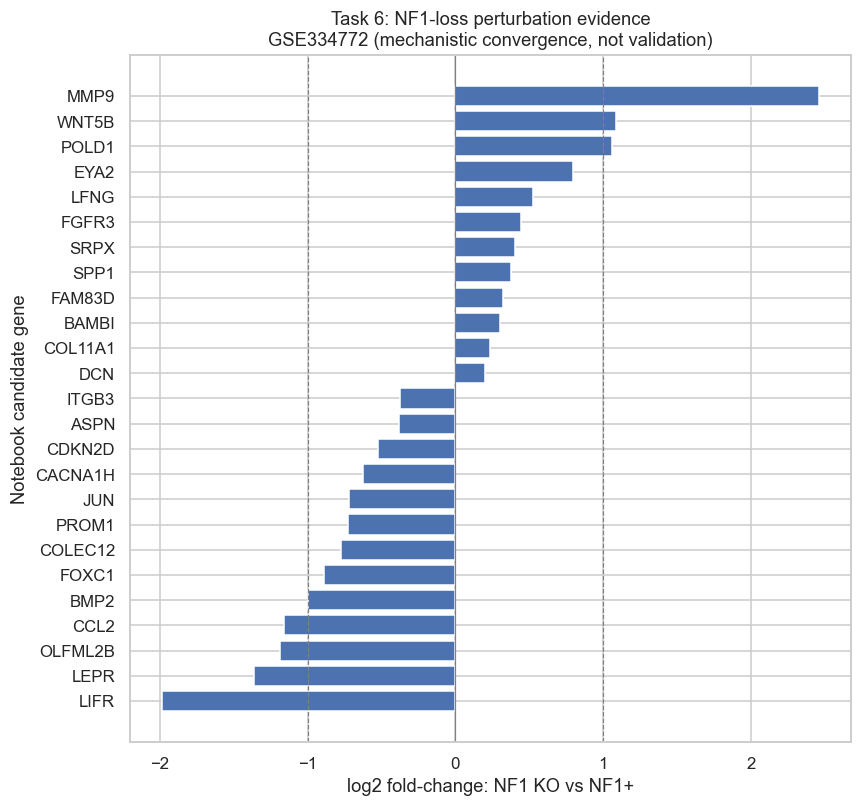

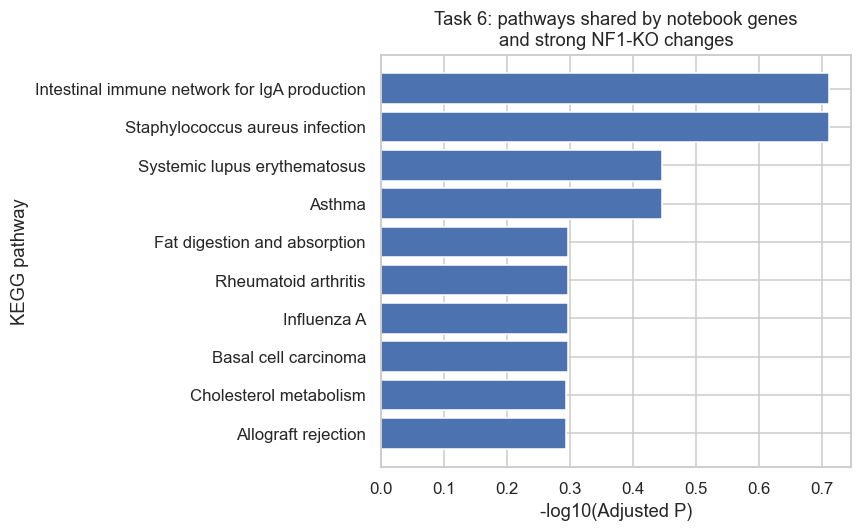

In [96]:
# ============================================================
# Task 6G — plots
# ============================================================

plot_task6 = (task6_integrated
              .dropna(subset=["log2FC_NF1KO_vs_plus"])
              .sort_values(["n_notebook_sources", "abs_log2FC"],
                           ascending=[False, False])
              .head(25)
              .sort_values("log2FC_NF1KO_vs_plus"))

if len(plot_task6):
    plt.figure(figsize=(8, max(5, 0.30 * len(plot_task6))))
    plt.barh(plot_task6["gene"], plot_task6["log2FC_NF1KO_vs_plus"])
    plt.axvline(0, lw=0.8, color="grey")
    plt.axvline(1, ls="--", lw=0.8, color="grey")
    plt.axvline(-1, ls="--", lw=0.8, color="grey")
    plt.xlabel("log2 fold-change: NF1 KO vs NF1+")
    plt.ylabel("Notebook candidate gene")
    plt.title("Task 6: NF1-loss perturbation evidence\nGSE334772 (mechanistic convergence, not validation)")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "task6_GSE334772_notebook_candidates_NF1KO.png"),
                dpi=300, bbox_inches="tight")
    plt.show()

if len(task6_kegg):
    plot_kegg = task6_kegg.head(10).iloc[::-1]
    plt.figure(figsize=(8, 5))
    plt.barh(plot_kegg["Term"].str.slice(0, 55),
             -np.log10(plot_kegg["Adjusted P-value"].clip(lower=np.finfo(float).tiny)))
    plt.xlabel("-log10(Adjusted P)")
    plt.ylabel("KEGG pathway")
    plt.title("Task 6: pathways shared by notebook genes\nand strong NF1-KO changes")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "task6_GSE334772_convergent_KEGG.png"),
                dpi=300, bbox_inches="tight")
    plt.show()


In [97]:
# ============================================================
# Task 5/6 extension synthesis table
# ============================================================

extension_synthesis = external_gene_membership.copy()

if "task5_gene_site_summary" in globals() and len(task5_gene_site_summary):
    t5 = (task5_gene_site_summary.groupby("gene", as_index=False)
          .agg(GSE131007_bone_minus_other=("Bone_minus_mean_other_sites", "mean")))
    extension_synthesis = extension_synthesis.merge(t5, on="gene", how="left")
else:
    extension_synthesis["GSE131007_bone_minus_other"] = np.nan

extension_synthesis = extension_synthesis.merge(
    task6_nf1[["gene", "log2FC_NF1KO_vs_plus", "abs_log2FC"]],
    on="gene", how="left"
)

extension_synthesis["external_evidence_count"] = (
    extension_synthesis[["GSE131007_bone_minus_other", "log2FC_NF1KO_vs_plus"]]
    .notna().sum(axis=1)
)

extension_synthesis = extension_synthesis.sort_values(
    ["n_notebook_sources", "external_evidence_count", "abs_log2FC"],
    ascending=[False, False, False], na_position="last"
).reset_index(drop=True)

display(extension_synthesis.head(50))

extension_synthesis.to_csv(
    os.path.join(OUT_DIR, "task5_6_external_RNA_extension_synthesis.csv"),
    index=False
)

print("Saved Task 5/6 external RNA extension synthesis.")


,gene,GSE175692_DEG,Paper1_hubs,Task1_bone_GLRP,Within_bone_Cox,n_notebook_sources,GSE131007_bone_minus_other,log2FC_NF1KO_vs_plus,abs_log2FC,external_evidence_count
0,BAMBI,True,False,True,True,3,0.027692,0.299958,0.299958,2
1,ITGB3,True,True,True,False,3,NaN,-0.375509,0.375509,1
2,MMP9,True,True,False,False,2,-0.010455,2.457530,2.457530,2
3,LIFR,True,False,True,False,2,-0.003693,-1.981453,1.981453,2
4,LEPR,True,False,True,False,2,-0.012736,-1.359542,1.359542,2
5,OLFML2B,True,False,True,False,2,0.003178,-1.189034,1.189034,2
6,CCL2,True,True,False,False,2,-0.011035,-1.158075,1.158075,2
7,WNT5B,True,False,True,False,2,-0.000009,1.089637,1.089637,2
8,POLD1,False,False,True,True,2,-0.205319,1.060011,1.060011,2
9,BMP2,True,True,False,False,2,0.005015,-1.000000,1.000000,2


Saved Task 5/6 external RNA extension synthesis.


In [98]:
definitive_results = {
    "PPI network -- nodes (genes in main connected component)": G_main.number_of_nodes(),
    "PPI network -- edges": G_main.number_of_edges(),
    "STRING version": "v12.0 (score >= 400)",
    "Significant DEGs (BH-FDR<0.05, |log2FC|>1)": len(deg_sig),
    "PROM1/CCL2 risk score -- coefficients": f"PROM1={coef_prom1:.5f}, CCL2={coef_ccl2:.5f}",
    "PROM1/CCL2 risk score -- C-index": round(cindex_rs, 4),
    f"PROM1/CCL2 risk score -- {HORIZON_MONTHS}-month AUC": (round(auc_h, 4) if not np.isnan(auc_h) else "NA (insufficient known statuses)"),
    "Univariate Cox -- FDR<0.05 genes": sig_genes_fdr,
    "Univariate Cox -- nominal P<0.05 genes": sig_genes_raw,
}
# [R3, R5] Primary evaluation (Section 12P) -- the only performance numbers to report
for _, row in primary_summary.iterrows():
    key = f"PRIMARY | {row['model']} | {row['task']}"
    definitive_results[f"{key} | fold-averaged AUC (25 folds)"] = f"{row['fold_averaged_AUC_mean']:.3f} ± {row['fold_averaged_AUC_sd']:.3f}"
    definitive_results[f"{key} | pooled OOF AUC (5 repeats)"] = f"{row['pooled_OOF_AUC_mean']:.3f} ± {row['pooled_OOF_AUC_sd']:.3f}"
    definitive_results[f"{key} | pooled OOF balanced accuracy"] = f"{row['pooled_OOF_balanced_accuracy_mean']:.3f}"
    definitive_results[f"{key} | pooled OOF F1"] = f"{row['pooled_OOF_F1_mean']:.3f}"

def_df = pd.DataFrame(list(definitive_results.items()), columns=["metric", "value"])
def_df.to_csv(f"{OUT_DIR}/DEFINITIVE_RESULTS_TABLE.csv", index=False)
print("=" * 78)
print("DEFINITIVE RESULTS TABLE")
print(f"Saved to: {OUT_DIR}/DEFINITIVE_RESULTS_TABLE.csv")
print("This CSV is the ONLY source manuscript text, figure captions, the supplement, and the")
print("GitHub README should read numbers from. If a number in any of those places doesn't")
print("match this file after a re-run, the CSV is right and the other place needs updating --")
print("not the other way around.")
print("=" * 78)
display(def_df)


DEFINITIVE RESULTS TABLE
Saved to: ./output/DEFINITIVE_RESULTS_TABLE.csv
This CSV is the ONLY source manuscript text, figure captions, the supplement, and the
GitHub README should read numbers from. If a number in any of those places doesn't
match this file after a re-run, the CSV is right and the other place needs updating --
not the other way around.


,metric,value
0,PPI network -- nodes (genes in main connected ...,737
1,PPI network -- edges,19902
2,STRING version,v12.0 (score >= 400)
3,"Significant DEGs (BH-FDR<0.05, |log2FC|>1)",68
4,PROM1/CCL2 risk score -- coefficients,"PROM1=0.07681, CCL2=0.12554"
...,...,...
76,PRIMARY | GCN_real_K5 | survival_outcome | poo...,0.587
77,PRIMARY | GCN_real_K9 | survival_outcome | fol...,0.697 ± 0.097
78,PRIMARY | GCN_real_K9 | survival_outcome | poo...,0.633 ± 0.053
79,PRIMARY | GCN_real_K9 | survival_outcome | poo...,0.610


In [99]:
import importlib.metadata as importlib_metadata

def _ver(pkg):
    try:
        return importlib_metadata.version(pkg)
    except importlib_metadata.PackageNotFoundError:
        return "not found"

repro_table = pd.DataFrame([
    ("Graph-CNN architecture", "2x Chebyshev graph-conv (K=7): 1->16, 16->8 channels, ReLU after each; flatten; FC N*8->64; dropout 0.5; FC 64->2"),
    ("Chebyshev order K", "7 (default); sensitivity to K in {3,5,7,9} reported in Item 7 below"),
    ("Optimizer", "Adam, lr=5e-4, weight_decay=5e-4 (L2)"),
    ("Loss", "nn.CrossEntropyLoss(), unweighted for the Graph-CNN"),
    ("Epochs", "30 fixed epochs/fold; best-epoch checkpoint selected by validation AUC (not early stopping)"),
    ("Batch size", "16"),
    ("Global random seed", "torch.manual_seed(0); np.random.seed(0), set once at notebook start"),
    ("CV split seed", "StratifiedKFold(random_state=0); inner train/val split random_state=fold (0-4)"),
    ("Class weighting", "Random Forest: class_weight='balanced' (per fold). Graph-CNN: none in the loss; imbalance addressed via per-fold Youden-threshold selection on validation data. An optional class-weighted Graph-CNN variant exists but is not applied by default."),
    ("Random Forest", "n_estimators=300, class_weight='balanced', random_state=fold"),
    ("Preprocessing", "737-gene STRING largest-connected-component topology fixed before any split (not per-fold gene selection). Default pipeline imputes/shifts once on the full cohort before CV; a strict per-fold-preprocessing variant is also provided earlier in the notebook."),
    ("STRING version", "v12.0, protein.links, combined_score >= 400"),
    ("GEO series used", "GSE175692 (discovery), GSE14020, GSE124647, GSE11121 (external), GSE131007 (single-cell context), GSE334772 (NF1 perturbation)"),
    ("torch", _ver("torch")), ("scikit-learn", _ver("scikit-learn")), ("pandas", _ver("pandas")),
    ("numpy", _ver("numpy")), ("networkx", _ver("networkx")), ("lifelines", _ver("lifelines")),
    ("scipy", _ver("scipy")), ("statsmodels", _ver("statsmodels")), ("gseapy", _ver("gseapy")),
], columns=["item", "value"])

repro_table.to_csv(f"{OUT_DIR}/reproducibility_details.csv", index=False)
print("Reproducibility details (paste into Methods):")
display(repro_table)


Reproducibility details (paste into Methods):


,item,value
0,Graph-CNN architecture,"2x Chebyshev graph-conv (K=7): 1->16, 16->8 ch..."
1,Chebyshev order K,"7 (default); sensitivity to K in {3,5,7,9} rep..."
2,Optimizer,"Adam, lr=5e-4, weight_decay=5e-4 (L2)"
3,Loss,"nn.CrossEntropyLoss(), unweighted for the Grap..."
4,Epochs,30 fixed epochs/fold; best-epoch checkpoint se...
5,Batch size,16
6,Global random seed,"torch.manual_seed(0); np.random.seed(0), set o..."
7,CV split seed,StratifiedKFold(random_state=0); inner train/v...
8,Class weighting,Random Forest: class_weight='balanced' (per fo...
9,Random Forest,"n_estimators=300, class_weight='balanced', ran..."


In [100]:
external_summary_rows = []

n_bone_14020 = int((gse14020_clin["group"] == "Bone").sum())
n_nonbone_14020 = int((gse14020_clin["group"] == "Non-bone").sum())
for _, row in val_14020.iterrows():
    effect_size = row["mean_Bone"] - row["mean_Non-bone"]
    external_summary_rows.append({
        "cohort": "GSE14020", "endpoint": "Bone vs non-bone expression (Mann-Whitney)",
        "gene": row["gene"], "n_bone": n_bone_14020, "n_nonbone": n_nonbone_14020,
        "effect_direction": "higher in Bone" if effect_size > 0 else "higher in Non-bone",
        "effect_size": round(effect_size, 3), "HR": "NA", "CI_lower": "NA", "CI_upper": "NA",
        "pvalue": row["pvalue"],
        "note": "candidate-level expression-direction replication, not full-model external validation",
    })

# verify_rows only stored (gene, HR, p, logrank_p) -- no CI bounds -- so refit here directly
# against df124 (already computed earlier) to get the full Cox summary including 95% CI.
for gene, hr, p, logrank_p in verify_rows:
    cph_ci = CoxPHFitter()
    cph_ci.fit(df124[["time_months", "event", gene]], duration_col="time_months", event_col="event")
    s_ci = cph_ci.summary.loc[gene]
    external_summary_rows.append({
        "cohort": "GSE124647", "endpoint": "Overall survival (Cox), pre-specified candidate",
        "gene": gene, "n_bone": "NA", "n_nonbone": "NA",
        "effect_direction": "worse survival" if hr > 1 else "better survival",
        "effect_size": "NA", "HR": round(hr, 3),
        "CI_lower": round(s_ci["exp(coef) lower 95%"], 3), "CI_upper": round(s_ci["exp(coef) upper 95%"], 3),
        "pvalue": p,
        "note": (f"n={len(df124)}, {int(df124['event'].sum())} events; log-rank P={logrank_p:.3g}; "
                 "candidate-level prognosis replication, not full-model external validation"),
    })

external_summary_rows.append({
    "cohort": "GSE11121", "endpoint": "Distant-metastasis-free survival (Cox + pre-specified median split)",
    "gene": "PROM1", "n_bone": "NA", "n_nonbone": "NA",
    "effect_direction": "worse DMFS" if s11121["exp(coef)"] > 1 else "better DMFS",
    "effect_size": "NA", "HR": round(s11121["exp(coef)"], 3),
    "CI_lower": round(s11121["exp(coef) lower 95%"], 3), "CI_upper": round(s11121["exp(coef) upper 95%"], 3),
    "pvalue": s11121["p"],
    "note": (f"n={len(df11121)}, {int(df11121['event'].sum())} events; median-split log-rank P={res11121.p_value:.3g}; "
             "DMFS is a different endpoint from GSE175692's OS -- candidate-level replication, not external validation"),
})

external_summary = pd.DataFrame(external_summary_rows)
external_summary.to_csv(f"{OUT_DIR}/external_cohorts_consolidated_reporting.csv", index=False)
print("Consolidated external-cohort reporting:")
display(external_summary)


Consolidated external-cohort reporting:


,cohort,endpoint,gene,n_bone,n_nonbone,effect_direction,effect_size,HR,CI_lower,CI_upper,pvalue,note
0,GSE14020,Bone vs non-bone expression (Mann-Whitney),MMP9,18,47,higher in Bone,2.981,NA,NA,NA,7.507843e-07,candidate-level expression-direction replicati...
1,GSE14020,Bone vs non-bone expression (Mann-Whitney),ITGB3,18,47,higher in Bone,0.29,NA,NA,NA,1.106892e-03,candidate-level expression-direction replicati...
2,GSE14020,Bone vs non-bone expression (Mann-Whitney),BMP2,18,47,higher in Bone,1.646,NA,NA,NA,2.021569e-04,candidate-level expression-direction replicati...
3,GSE14020,Bone vs non-bone expression (Mann-Whitney),CCL2,18,47,higher in Bone,0.171,NA,NA,NA,6.130185e-01,candidate-level expression-direction replicati...
4,GSE14020,Bone vs non-bone expression (Mann-Whitney),PROM1,18,47,higher in Non-bone,-2.323,NA,NA,NA,7.786908e-05,candidate-level expression-direction replicati...
5,GSE124647,"Overall survival (Cox), pre-specified candidate",PROM1,NA,NA,worse survival,NA,1.161,1.018,1.325,2.654065e-02,"n=140, 97 events; log-rank P=0.54; candidate-l..."
6,GSE124647,"Overall survival (Cox), pre-specified candidate",CCL2,NA,NA,worse survival,NA,1.073,0.972,1.186,1.638003e-01,"n=140, 97 events; log-rank P=0.194; candidate-..."
7,GSE11121,Distant-metastasis-free survival (Cox + pre-sp...,PROM1,NA,NA,worse DMFS,NA,1.0,1.0,1.0,1.812387e-04,"n=200, 46 events; median-split log-rank P=0.17..."


In [101]:
from scipy.stats import hypergeom

nf1_gene_universe = set(task6_nf1["gene"]) & set(gene_list)
nf1_responsive = set(task6_nf1.loc[task6_nf1["abs_log2FC"] >= 1, "gene"]) & nf1_gene_universe
prioritized = set(external_validation_genes) & nf1_gene_universe

M = len(nf1_gene_universe)   # population: genes in both the 737-gene panel and GSE334772
n_success = len(nf1_responsive)  # NF1-responsive genes in that population
N_draw = len(prioritized)    # prioritized/candidate genes tested
k_observed = len(prioritized & nf1_responsive)

# One-sided: is the observed overlap bigger than expected by chance?
p_value = hypergeom.sf(k_observed - 1, M, n_success, N_draw)

print("NF1-loss overlap test (hypergeometric, one-sided enrichment):")
print(f"  Gene universe (737-gene panel x genes measured in GSE334772): {M}")
print(f"  NF1-responsive genes in that universe (|log2FC|>=1): {n_success}")
print(f"  Prioritized/candidate genes tested: {N_draw}")
print(f"  Observed overlap: {k_observed}")
print(f"  P(overlap >= {k_observed} by chance) = {p_value:.4g}")
print(f"  Overlapping genes: {sorted(prioritized & nf1_responsive)}")

nf1_overlap_result = pd.DataFrame([{
    "universe_size": M, "nf1_responsive_in_universe": n_success,
    "prioritized_tested": N_draw, "observed_overlap": k_observed, "pvalue_hypergeometric": p_value,
    "overlapping_genes": ", ".join(sorted(prioritized & nf1_responsive)),
}])
nf1_overlap_result.to_csv(f"{OUT_DIR}/nf1_overlap_hypergeometric_test.csv", index=False)


NF1-loss overlap test (hypergeometric, one-sided enrichment):
  Gene universe (737-gene panel x genes measured in GSE334772): 733
  NF1-responsive genes in that universe (|log2FC|>=1): 194
  Prioritized/candidate genes tested: 207
  Observed overlap: 59
  P(overlap >= 59 by chance) = 0.2438
  Overlapping genes: ['ACVRL1', 'ADCY9', 'AGR2', 'APOE', 'BCAS1', 'BCL2A1', 'BMP2', 'CA12', 'CACNG4', 'CCL2', 'CD36', 'CEACAM6', 'CHAD', 'COL27A1', 'CXCL10', 'CXCL12', 'CYP4F3', 'DDR2', 'DUSP6', 'EP300', 'ESR1', 'EYA4', 'FGF7', 'FZD7', 'GADD45A', 'GDF15', 'GSK3B', 'HAS1', 'HLA-DPB1', 'HLA-DQB1', 'HLA-DRA', 'HLA-DRB1', 'IBSP', 'ID1', 'JAG1', 'KRT14', 'KRT7', 'LEPR', 'LIFR', 'MMP9', 'NEO1', 'NOD2', 'NOTCH2', 'OLFML2B', 'PKMYT1', 'PLA2G3', 'POLD1', 'POLR2A', 'PTCH1', 'SERPINB5', 'SLC39A6', 'SLPI', 'SMAD5', 'ST6GALNAC2', 'TCF4', 'TFF1', 'TMPRSS2', 'WNT5B', 'ZFYVE9']


In [102]:
print("Full clin175 columns actually available:")
print(clin175.columns.tolist())

clin175_conf = clin175.copy()
for _c in ["hr", "her2"]:
    # [R1] literal "NA" strings are missing values, not a third category
    clin175_conf[_c] = clin175_conf[_c].astype(str).str.strip().str.upper().replace({"NA": np.nan, "NAN": np.nan, "": np.nan})
clin175_conf["bone_met"] = (clin175_conf["organ"] == "Bone")
clin175_conf["subtype_proxy"] = clin175_conf["hr"] + "/" + clin175_conf["her2"]

from scipy.stats import chi2_contingency, fisher_exact

def assoc_test(df_, col, label):
    tab = pd.crosstab(df_["bone_met"], df_[col])
    if tab.shape == (2, 2):
        _, p = fisher_exact(tab.values); test_name = "Fisher exact"
    else:
        _, p, _, _ = chi2_contingency(tab); test_name = "Chi-square"
    print(f"\n{label} vs bone-met status ({test_name}, P={p:.4g}; samples with missing {col} excluded):")
    display(tab)
    return p

conf_pvals = {}
for col, label in [("hr", "HR status"), ("her2", "HER2 status"), ("subtype_proxy", "HR/HER2 subtype proxy")]:
    conf_pvals[label] = assoc_test(clin175_conf.dropna(subset=[col]), col, label)
confounding_summary = pd.DataFrame(list(conf_pvals.items()), columns=["variable", "pvalue_vs_bone_met"])
confounding_summary.to_csv(f"{OUT_DIR}/confounding_association_tests.csv", index=False)

# [R3] Subtype-restricted sensitivity, through the primary engine (fold-internal preprocessing)
dominant_subtype = clin175_conf["subtype_proxy"].value_counts().idxmax()
subtype_series = clin175_conf["subtype_proxy"].reindex(Xall.index)
subtype_mask = (subtype_series == dominant_subtype).fillna(False).to_numpy()
ids_dom, y_dom = TASK_SAMPLE_IDS["bone_metastasis"][subtype_mask], y_task1[subtype_mask]
groups_dom = (TASK_PATIENT_ID_ARRAYS["bone_metastasis"][subtype_mask]
              if TASK_PATIENT_ID_ARRAYS["bone_metastasis"] is not None else None)
print(f"\nTask 1 restricted to dominant subtype {dominant_subtype}: {len(y_dom)} samples, {int(y_dom.sum())} bone-met")
if y_dom.sum() >= 5 and (len(y_dom) - y_dom.sum()) >= 5:
    s_dom = cv_auc_fold_internal(ids_dom, y_dom, groups=groups_dom, n_repeats=1, tag="subtype")
    print(f"Subtype-restricted Task 1 Graph-CNN: fold-averaged AUC {s_dom['fold_averaged_AUC_mean']:.3f} "
          f"± {s_dom['fold_averaged_AUC_sd']:.3f}; pooled OOF AUC {s_dom['pooled_OOF_AUC_mean']:.3f} "
          "(compare with GCN_real_K7 in PRIMARY_performance_summary.csv)")
else:
    print("Not enough bone-met/non-bone-met samples within the dominant subtype for a stable CV.")


Full clin175 columns actually available:
['title', 'source_name', 'organ', 'Sex', 'pre-post menopausal', 'de novo metastasis vs relapsed', 'site of metastatic biopsy', 'metastatic spread', 'number of metastatic sites', 'neoadjuvant or adjuvant treatment?', 'number of lines of treatment?', 'endocrine therapy? yes vs not', 'cdk treatment? yes vs not', 'anti-her2 treatment? yes vs not?', 'chemotherapy? yes vs not', 'immunotherapy', 'everolimus', 'pi3k inhibitors', 'akt inhibitor', 'bevacizumab', 'parp inhibitors', 'hr', 'her2', 'her2 ihc', 'her2 ish', 'ihc group', 'ose', 'os (months) since dxmet', 'age (years)', 'characteristic']

HR status vs bone-met status (Fisher exact, P=0.008095; samples with missing hr excluded):


hr,NEG,POS
bone_met,,
False,56,83
True,5,27



HER2 status vs bone-met status (Fisher exact, P=1; samples with missing her2 excluded):


her2,NEG,POS
bone_met,,
False,124,15
True,29,3



HR/HER2 subtype proxy vs bone-met status (Chi-square, P=0.01746; samples with missing subtype_proxy excluded):


subtype_proxy,NEG/NEG,NEG/POS,POS/NEG,POS/POS
bone_met,,,,
False,50,6,74,9
True,3,2,26,1



Task 1 restricted to dominant subtype POS/NEG: 100 samples, 26 bone-met
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


Subtype-restricted Task 1 Graph-CNN: fold-averaged AUC 0.898 ± 0.101; pooled OOF AUC 0.779 (compare with GCN_real_K7 in PRIMARY_performance_summary.csv)


In [103]:
print("Non-bone metastatic site breakdown (organ column):")
site_counts_clin = clin175["organ"].value_counts()
display(site_counts_clin)

non_bone_sites = [s for s in site_counts_clin.index if s != "Bone"]
dominant_non_bone = site_counts_clin.drop("Bone").idxmax()
print(f"\nNon-bone sites represented: {non_bone_sites}")
print(f"Dominant non-bone site: {dominant_non_bone} ({site_counts_clin[dominant_non_bone]} samples, "
      f"{100 * site_counts_clin[dominant_non_bone] / site_counts_clin.drop('Bone').sum():.1f}% of the non-bone group)")

# [R3] Leave-one-site-out through the primary engine (fold-internal preprocessing, same threshold rule)
loso_rows = []
for site in non_bone_sites:
    keep_mask = (clin175["organ"] != site).reindex(Xall.index).fillna(True).to_numpy()
    ids_loso, y_loso = TASK_SAMPLE_IDS["bone_metastasis"][keep_mask], y_task1[keep_mask]
    groups_loso = (TASK_PATIENT_ID_ARRAYS["bone_metastasis"][keep_mask]
                   if TASK_PATIENT_ID_ARRAYS["bone_metastasis"] is not None else None)
    n_removed, n_bone = int((~keep_mask).sum()), int(y_loso.sum())
    if n_removed < 3 or n_bone < 5 or (len(y_loso) - n_bone) < 5:
        continue
    s = cv_auc_fold_internal(ids_loso, y_loso, groups=groups_loso, n_repeats=1, tag=f"loso_{site}")
    loso_rows.append({"site_excluded": site, "n_excluded": n_removed, "n_remaining": len(y_loso),
                      "fold_averaged_AUC": s["fold_averaged_AUC_mean"], "fold_averaged_AUC_sd": s["fold_averaged_AUC_sd"],
                      "pooled_OOF_AUC": s["pooled_OOF_AUC_mean"]})
    print(f"Excluding {site} ({n_removed} samples): fold-averaged AUC={s['fold_averaged_AUC_mean']:.3f}"
          f"±{s['fold_averaged_AUC_sd']:.3f}, pooled OOF AUC={s['pooled_OOF_AUC_mean']:.3f}")

loso_summary = pd.DataFrame(loso_rows)
loso_summary.to_csv(f"{OUT_DIR}/leave_one_site_out_sensitivity.csv", index=False)
display(loso_summary) if len(loso_summary) else print("No non-bone site had enough samples to remove.")


Non-bone metastatic site breakdown (organ column):


organ
Bone          33
Liver         31
Skin          27
Breast        24
Brain         22
Lymph node    16
Lung          13
Pleura        10
Ovary          4
Muscle         2
Peritoneum     2
Name: count, dtype: int64


Non-bone sites represented: ['Liver', 'Skin', 'Breast', 'Brain', 'Lymph node', 'Lung', 'Pleura', 'Ovary', 'Muscle', 'Peritoneum']
Dominant non-bone site: Liver (31 samples, 20.5% of the non-bone group)
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


Excluding Liver (31 samples): fold-averaged AUC=0.872±0.110, pooled OOF AUC=0.739
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


Excluding Skin (27 samples): fold-averaged AUC=0.798±0.177, pooled OOF AUC=0.810
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


...

Excluding Lymph node (16 samples): fold-averaged AUC=0.887±0.121, pooled OOF AUC=0.771
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


Excluding Lung (13 samples): fold-averaged AUC=0.880±0.124, pooled OOF AUC=0.803
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


Excluding Pleura (10 samples): fold-averaged AUC=0.895±0.126, pooled OOF AUC=0.782
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


Excluding Ovary (4 samples): fold-averaged AUC=0.876±0.102, pooled OOF AUC=0.786


,site_excluded,n_excluded,n_remaining,fold_averaged_AUC,fold_averaged_AUC_sd,pooled_OOF_AUC
0,Liver,31,153,0.871825,0.109876,0.739394
1,Skin,27,157,0.798286,0.176913,0.810117
2,Breast,24,160,0.918249,0.096471,0.809592
3,Brain,22,162,0.868278,0.081055,0.693681
4,Lymph node,16,168,0.887302,0.120722,0.770595
5,Lung,13,171,0.879667,0.123807,0.803250
6,Pleura,10,174,0.895068,0.126366,0.781646
7,Ovary,4,180,0.876420,0.101532,0.785611


In [104]:
def train_one_fold_K(Xtr, ytr, Xva, yva, K, n_epochs=30, batch_size=16, lr=5e-4):
    model = GraphCNN(N, K=K)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(ytr)
    Xva_t = torch.tensor(Xva)
    best_auc, best_state = -1, None
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = lossf(model(L_hat, Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(L_hat, Xva_t), dim=1)[:, 1].numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_auc

K_SWEEP = [3, 5, 7, 9]
k_sweep_rows = []
for task_name, task in TASKS.items():
    X_task, y_task = task["X"], task["y"]
    for K in K_SWEEP:
        skf, _groups = make_cv_splitter(y_task, patient_ids=TASK_PATIENT_ID_ARRAYS[task_name], random_state=0)
        fold_aucs = []
        for fold, (train_idx, test_idx) in enumerate(skf.split(X_task, y_task, groups=_groups)):
            Xtr_full, ytr_full = X_task[train_idx], y_task[train_idx]
            Xte_fold, yte_fold = X_task[test_idx], y_task[test_idx]
            Xtr, Xva, ytr, yva = train_test_split(Xtr_full, ytr_full, test_size=0.15, stratify=ytr_full, random_state=fold)
            model, _ = train_one_fold_K(Xtr, ytr, Xva, yva, K)
            model.eval()
            with torch.no_grad():
                probs = torch.softmax(model(L_hat, torch.tensor(Xte_fold)), dim=1)[:, 1].numpy()
            fold_aucs.append(roc_auc_score(yte_fold, probs) if len(set(yte_fold)) > 1 else np.nan)
        k_sweep_rows.append({"task": TASKS[task_name]["label"], "K": K,
                              "mean_AUC": np.nanmean(fold_aucs), "std_AUC": np.nanstd(fold_aucs)})
        print(f"[{task_name}] K={K}: mean AUC={np.nanmean(fold_aucs):.3f} +- {np.nanstd(fold_aucs):.3f}")

k_sweep_summary = pd.DataFrame(k_sweep_rows)
k_sweep_summary.to_csv(f"{OUT_DIR}/chebyshev_K_sensitivity.csv", index=False)
display(k_sweep_summary)

# Data-driven wording, not an assumed conclusion -- computed from whatever the numbers
# actually turn out to be, so "K=7 is optimal" is never asserted unless it actually is.
print("\nInterpretation (for the manuscript -- computed from the table above, not assumed):")
for task_name in TASKS:
    task_rows = k_sweep_summary[k_sweep_summary["task"] == TASKS[task_name]["label"]]
    best_row = task_rows.loc[task_rows["mean_AUC"].idxmax()]
    k7_auc = task_rows.loc[task_rows["K"] == 7, "mean_AUC"].iloc[0]
    spread = task_rows["mean_AUC"].max() - task_rows["mean_AUC"].min()
    if best_row["K"] == 7:
        verdict = f"K=7 is the best-performing value tested for this task (spread across K: {spread:.3f})."
    elif spread < 0.01:
        verdict = (f"performance is essentially flat across K (spread {spread:.3f}) -- K=7 is a "
                   f"reasonable, defensible choice, but not uniquely optimal.")
    else:
        verdict = (f"K={int(best_row['K'])} (AUC={best_row['mean_AUC']:.3f}) outperforms K=7 "
                   f"(AUC={k7_auc:.3f}) by {best_row['mean_AUC'] - k7_auc:.3f} -- do NOT describe "
                   f"K=7 as empirically optimal for this task in the manuscript.")
    print(f"  [{task_name}] {verdict}")


  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


[bone_metastasis] K=3: mean AUC=0.824 +- 0.213
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


[bone_metastasis] K=5: mean AUC=0.886 +- 0.099
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


[bone_metastasis] K=7: mean AUC=0.854 +- 0.172
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


[bone_metastasis] K=9: mean AUC=0.864 +- 0.149
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


...

[survival_outcome] K=5: mean AUC=0.705 +- 0.115
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


[survival_outcome] K=7: mean AUC=0.712 +- 0.122
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


[survival_outcome] K=9: mean AUC=0.697 +- 0.087


,task,K,mean_AUC,std_AUC
0,bone-site vs. non-bone-site metastatic biopsy ...,3,0.824183,0.212702
1,bone-site vs. non-bone-site metastatic biopsy ...,5,0.886462,0.099201
2,bone-site vs. non-bone-site metastatic biopsy ...,7,0.854322,0.171638
3,bone-site vs. non-bone-site metastatic biopsy ...,9,0.864322,0.148857
4,post-metastatic-diagnosis mortality within 36 ...,3,0.673929,0.125571
5,post-metastatic-diagnosis mortality within 36 ...,5,0.704723,0.115493
6,post-metastatic-diagnosis mortality within 36 ...,7,0.711858,0.122486
7,post-metastatic-diagnosis mortality within 36 ...,9,0.697297,0.087108



Interpretation (for the manuscript -- computed from the table above, not assumed):
  [bone_metastasis] K=5 (AUC=0.886) outperforms K=7 (AUC=0.854) by 0.032 -- do NOT describe K=7 as empirically optimal for this task in the manuscript.
  [survival_outcome] K=7 is the best-performing value tested for this task (spread across K: 0.038).


In [105]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
    f1_score, recall_score, precision_score, matthews_corrcoef, confusion_matrix
)

# Observed timing from the last run: ~20s/fold for the neural-net model types.
# N_REPEATS x 5 folds x 3 NN model types x 2 tasks x ~20s:
#   N_REPEATS=2 -> ~20 min (already observed, got interrupted before finishing)
#   N_REPEATS=5 -> ~50 min (what item 4 actually asked for -- only raise this if you can
#                            let it run uninterrupted; Colab disconnects on idle/long cells)
N_REPEATS = 5
N_EPOCHS_ABLATION = 30   # matches the main pipeline's protocol; lower for a faster/approximate run
print(f"This cell will train roughly {N_REPEATS} x 5 x 3 x {len(TASKS)} = "
      f"{N_REPEATS * 5 * 3 * len(TASKS)} neural nets, at ~20s each based on the last run "
      f"-> approx {N_REPEATS * 5 * 3 * len(TASKS) * 20 / 60:.0f} minutes, plus Random Forest folds (fast). "
      f"Lower N_REPEATS above for a quicker pass.")

# --- Degree-preserving shuffled graph (built once) ---
G_shuffled = G_main.copy()
nx.double_edge_swap(G_shuffled, nswap=int(2.5 * G_shuffled.number_of_edges()),
                     max_tries=int(50 * G_shuffled.number_of_edges()), seed=0)
A_shuffled = nx.to_scipy_sparse_array(G_shuffled, nodelist=gene_list, format="csr")
L_hat_shuffled = scipy_to_torch_sparse(normalized_laplacian(A_shuffled))
print(f"Shuffled graph: {G_shuffled.number_of_nodes()} nodes, {G_shuffled.number_of_edges()} edges "
      f"(degree sequence preserved; real graph has {G_main.number_of_edges()} edges).")

# --- Identity adjacency (no message passing -- each node only sees itself) ---
A_identity = sp.identity(N, format="csr")
L_hat_identity = scipy_to_torch_sparse(normalized_laplacian(A_identity))
print("Identity-adjacency graph: no edges -- each gene's Chebyshev filter can only see itself, "
      "isolating whatever the graph convolution structure itself contributes vs. real message passing.")

from sklearn.linear_model import LogisticRegression

def train_one_fold_with_graph(Xtr, ytr, Xva, yva, L_hat_matrix, n_epochs=N_EPOCHS_ABLATION, batch_size=16, lr=5e-4):
    model = GraphCNN(N)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(ytr)
    Xva_t = torch.tensor(Xva)
    best_auc, best_state = -1, None
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = lossf(model(L_hat_matrix, Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(L_hat_matrix, Xva_t), dim=1)[:, 1].numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_auc

class PlainMLP(nn.Module):
    def __init__(self, n_features, hidden=64, n_classes=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features, hidden), nn.ReLU(), nn.Dropout(0.5), nn.Linear(hidden, n_classes))
    def forward(self, x):
        return self.net(x)

def train_one_fold_mlp(Xtr, ytr, Xva, yva, n_epochs=N_EPOCHS_ABLATION, batch_size=16, lr=5e-4):
    model = PlainMLP(Xtr.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(ytr)
    Xva_t = torch.tensor(Xva)
    best_auc, best_state = -1, None
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = lossf(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(Xva_t), dim=1)[:, 1].numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_auc

def full_metrics(y_true, probs, preds):
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {
        "AUC": roc_auc_score(y_true, probs) if len(set(y_true)) > 1 else np.nan,
        "PR_AUC": average_precision_score(y_true, probs),
        "accuracy": accuracy_score(y_true, preds),
        "balanced_accuracy": balanced_accuracy_score(y_true, preds),
        "sensitivity_recall": recall_score(y_true, preds, pos_label=1, zero_division=0),
        "specificity": recall_score(y_true, preds, pos_label=0, zero_division=0),
        "precision": precision_score(y_true, preds, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, preds, zero_division=0),
        "MCC": matthews_corrcoef(y_true, preds),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

ABLATION_MODELS = ["GCN_real_graph", "GCN_shuffled_graph", "GCN_identity_adjacency",
                   "MLP_no_graph", "LogisticRegression_signature", "RandomForest"]
METRIC_NAMES_FULL = ["AUC", "PR_AUC", "accuracy", "balanced_accuracy", "sensitivity_recall",
                      "specificity", "precision", "F1", "MCC"]

# Checkpointing, PER REPEAT (not per combo): each of the 5 repeats within a
# (task, model) combo is saved to disk the moment IT finishes, not just once the
# whole combo is done. A prior run showed why this matters: it got 24/25 folds
# through a combo (one repeat short of finishing) before disconnecting, and lost
# the entire combo because the old per-combo checkpoint hadn't been written yet.
# Per-repeat checkpoints cap the worst-case loss at ~1 repeat (~5 folds, ~1-2 min)
# instead of an entire combo (~5-10 min). Delete files in CHECKPOINT_DIR to force
# specific repeats/combos to redo.
import pickle
CHECKPOINT_DIR = os.path.join(OUT_DIR, "ablation_checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# "v2labelfix" invalidates every checkpoint from before the Task 2 (survival) label
# definition was corrected -- alive_after_3y used to wrongly require (ev == 0), excluding
# patients who lived past 3 years and later died. Old .pkl files (without this tag) are
# simply never matched below, so they're silently bypassed and recomputed -- no manual
# deletion required, though you can still delete the old CHECKPOINT_DIR contents for
# tidiness. This bumps BOTH tasks' checkpoints (not just survival_outcome) for simplicity;
# bone_metastasis results are unaffected by the fix but will recompute once, harmlessly.
CHECKPOINT_VERSION_TAG = "v3perrepeat"

def _repeat_checkpoint_path(task_name, model_name, repeat):
    return os.path.join(CHECKPOINT_DIR, f"{task_name}__{model_name}__rep{repeat}__{CHECKPOINT_VERSION_TAG}.pkl")

_n_total_units = len(TASKS) * len(ABLATION_MODELS) * N_REPEATS
_n_done_already = sum(os.path.exists(_repeat_checkpoint_path(t, m, r))
                       for t in TASKS for m in ABLATION_MODELS for r in range(N_REPEATS))
print(f"Ablation checkpoints found: {_n_done_already}/{_n_total_units} (task, model, repeat) units "
      f"already complete from a previous run of this cell.")

ablation_rows = []
oof_confusion = {}
_ablation_start = time.time()

for task_name, task in TASKS.items():
    X_task, y_task = task["X"], task["y"]
    for model_name in ABLATION_MODELS:
        pooled_true, pooled_preds = [], []
        per_repeat_metrics = []

        for repeat in range(N_REPEATS):
            rep_ckpt = _repeat_checkpoint_path(task_name, model_name, repeat)
            if os.path.exists(rep_ckpt):
                with open(rep_ckpt, "rb") as f:
                    _rc = pickle.load(f)
                per_repeat_metrics.append(_rc["metrics"])
                pooled_true.extend(_rc["repeat_true"]); pooled_preds.extend(_rc["repeat_preds"])
                print(f"[{task_name}|{model_name}] repeat {repeat+1}/{N_REPEATS} loaded from checkpoint.")
                continue

            skf, _groups = make_cv_splitter(y_task, patient_ids=TASK_PATIENT_ID_ARRAYS[task_name], random_state=repeat)
            repeat_true, repeat_probs, repeat_preds = [], [], []
            for fold, (train_idx, test_idx) in enumerate(skf.split(X_task, y_task, groups=_groups)):
                _fold_start = time.time()
                Xtr_full, ytr_full = X_task[train_idx], y_task[train_idx]
                Xte_fold, yte_fold = X_task[test_idx], y_task[test_idx]
                Xtr, Xva, ytr, yva = train_test_split(Xtr_full, ytr_full, test_size=0.15, stratify=ytr_full, random_state=fold)

                if model_name == "GCN_real_graph":
                    model, _ = train_one_fold_with_graph(Xtr, ytr, Xva, yva, L_hat)
                    with torch.no_grad():
                        va_probs = torch.softmax(model(L_hat, torch.tensor(Xva)), dim=1)[:, 1].numpy()
                        probs = torch.softmax(model(L_hat, torch.tensor(Xte_fold)), dim=1)[:, 1].numpy()
                elif model_name == "GCN_shuffled_graph":
                    model, _ = train_one_fold_with_graph(Xtr, ytr, Xva, yva, L_hat_shuffled)
                    with torch.no_grad():
                        va_probs = torch.softmax(model(L_hat_shuffled, torch.tensor(Xva)), dim=1)[:, 1].numpy()
                        probs = torch.softmax(model(L_hat_shuffled, torch.tensor(Xte_fold)), dim=1)[:, 1].numpy()
                elif model_name == "GCN_identity_adjacency":
                    model, _ = train_one_fold_with_graph(Xtr, ytr, Xva, yva, L_hat_identity)
                    with torch.no_grad():
                        va_probs = torch.softmax(model(L_hat_identity, torch.tensor(Xva)), dim=1)[:, 1].numpy()
                        probs = torch.softmax(model(L_hat_identity, torch.tensor(Xte_fold)), dim=1)[:, 1].numpy()
                elif model_name == "MLP_no_graph":
                    model, _ = train_one_fold_mlp(Xtr, ytr, Xva, yva)
                    with torch.no_grad():
                        va_probs = torch.softmax(model(torch.tensor(Xva)), dim=1)[:, 1].numpy()
                        probs = torch.softmax(model(torch.tensor(Xte_fold)), dim=1)[:, 1].numpy()
                elif model_name == "LogisticRegression_signature":
                    model = LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced")
                    model.fit(Xtr, ytr)
                    va_probs = model.predict_proba(Xva)[:, 1]
                    probs = model.predict_proba(Xte_fold)[:, 1]
                else:
                    model = RandomForestClassifier(n_estimators=300, random_state=fold, class_weight="balanced")
                    model.fit(Xtr, ytr)
                    va_probs = model.predict_proba(Xva)[:, 1]
                    probs = model.predict_proba(Xte_fold)[:, 1]

                thr = youden_threshold(yva, va_probs)
                preds = (probs >= thr).astype(int)
                repeat_true.extend(yte_fold.tolist()); repeat_probs.extend(probs.tolist()); repeat_preds.extend(preds.tolist())
                print(f"  [{task_name}|{model_name}] repeat {repeat+1}/{N_REPEATS} fold {fold+1}/5 done "
                      f"in {time.time()-_fold_start:.0f}s (elapsed {time.time()-_ablation_start:.0f}s total)")

            m = full_metrics(np.array(repeat_true), np.array(repeat_probs), np.array(repeat_preds))
            m["repeat"] = repeat
            per_repeat_metrics.append(m)
            pooled_true.extend(repeat_true); pooled_preds.extend(repeat_preds)

            with open(rep_ckpt, "wb") as f:
                pickle.dump({"metrics": m, "repeat_true": repeat_true, "repeat_preds": repeat_preds}, f)
            print(f"[{task_name}|{model_name}] repeat {repeat+1}/{N_REPEATS} checkpoint saved -- "
                  f"safe to disconnect now, worst case you redo only this one repeat.")

        per_repeat_df = pd.DataFrame(per_repeat_metrics)
        row = {"task": TASKS[task_name]["label"], "model": model_name, "n_repeats": N_REPEATS}
        for mname in METRIC_NAMES_FULL:
            vals = per_repeat_df[mname].dropna().to_numpy()
            mean_ = vals.mean() if len(vals) else np.nan
            std_ = vals.std(ddof=1) if len(vals) > 1 else 0.0
            ci_half = 1.96 * std_ / np.sqrt(len(vals)) if len(vals) > 1 else 0.0
            row[f"{mname}_mean"] = mean_; row[f"{mname}_std"] = std_
            row[f"{mname}_CI95_low"] = mean_ - ci_half; row[f"{mname}_CI95_high"] = mean_ + ci_half
        ablation_rows.append(row)

        cm = confusion_matrix(pooled_true, pooled_preds, labels=[0, 1])
        oof_confusion[(task_name, model_name)] = cm
        print(f"=== [{task_name} | {model_name}] pooled OOF over {N_REPEATS}x5-fold: "
              f"AUC={row['AUC_mean']:.3f}+-{row['AUC_std']:.3f}, balanced_acc={row['balanced_accuracy_mean']:.3f}, "
              f"MCC={row['MCC_mean']:.3f} ===")

ablation_summary = pd.DataFrame(ablation_rows)
ablation_summary.to_csv(f"{OUT_DIR}/ablation_repeated_CV_full_metrics.csv", index=False)
print("\nFull ablation + repeated-CV results (95% CI shown explicitly, as requested).")
print("NOTE ON METRIC DEFINITION: every _mean/_std/_CI95 value here is computed from POOLED "
      "out-of-fold predictions -- all 5 folds' predictions within one repeat are merged before "
      "computing AUC/etc. once per repeat, then averaged across the N_REPEATS repeats. This is "
      "NOT the same statistic as the main CV table (Item 3/4, earlier in the notebook), which "
      "averages 5 separately-computed per-fold AUCs. Do not treat numbers from the two tables "
      "as directly comparable without noting which one each came from.")
display(ablation_summary[["task", "model", "n_repeats",
                           "AUC_mean", "AUC_std", "AUC_CI95_low", "AUC_CI95_high",
                           "PR_AUC_mean", "accuracy_mean", "precision_mean",
                           "balanced_accuracy_mean", "sensitivity_recall_mean", "specificity_mean",
                           "F1_mean", "MCC_mean"]])


This cell will train roughly 5 x 5 x 3 x 2 = 150 neural nets, at ~20s each based on the last run -> approx 50 minutes, plus Random Forest folds (fast). Lower N_REPEATS above for a quicker pass.


Shuffled graph: 737 nodes, 19902 edges (degree sequence preserved; real graph has 19902 edges).
Identity-adjacency graph: no edges -- each gene's Chebyshev filter can only see itself, isolating whatever the graph convolution structure itself contributes vs. real message passing.
Ablation checkpoints found: 0/60 (task, model, repeat) units already complete from a previous run of this cell.
  [make_cv_splitter] WARNING: using sample-level StratifiedKFold, not patient-grouped -- patient identity was unavailable, mismatched in length, or had no repeats for this call.


  [bone_metastasis|GCN_real_graph] repeat 1/5 fold 1/5 done in 5s (elapsed 5s total)


  [bone_metastasis|GCN_real_graph] repeat 1/5 fold 2/5 done in 6s (elapsed 11s total)


  [bone_metastasis|GCN_real_graph] repeat 1/5 fold 3/5 done in 6s (elapsed 17s total)


...

  [survival_outcome|RandomForest] repeat 5/5 fold 2/5 done in 0s (elapsed 532s total)


  [survival_outcome|RandomForest] repeat 5/5 fold 3/5 done in 0s (elapsed 532s total)


  [survival_outcome|RandomForest] repeat 5/5 fold 4/5 done in 0s (elapsed 532s total)


  [survival_outcome|RandomForest] repeat 5/5 fold 5/5 done in 0s (elapsed 533s total)
[survival_outcome|RandomForest] repeat 5/5 checkpoint saved -- safe to disconnect now, worst case you redo only this one repeat.
=== [survival_outcome | RandomForest] pooled OOF over 5x5-fold: AUC=0.707+-0.020, balanced_acc=0.608, MCC=0.222 ===

Full ablation + repeated-CV results (95% CI shown explicitly, as requested).
NOTE ON METRIC DEFINITION: every _mean/_std/_CI95 value here is computed from POOLED out-of-fold predictions -- all 5 folds' predictions within one repeat are merged before computing AUC/etc. once per repeat, then averaged across the N_REPEATS repeats. This is NOT the same statistic as the main CV table (Item 3/4, earlier in the notebook), which averages 5 separately-computed per-fold AUCs. Do not treat numbers from the two tables as directly comparable without noting which one each came from.


,task,model,n_repeats,AUC_mean,AUC_std,AUC_CI95_low,AUC_CI95_high,PR_AUC_mean,accuracy_mean,precision_mean,balanced_accuracy_mean,sensitivity_recall_mean,specificity_mean,F1_mean,MCC_mean
0,bone-site vs. non-bone-site metastatic biopsy ...,GCN_real_graph,5,0.761068,0.100237,0.673206,0.848929,0.586269,0.900000,0.745716,0.820670,0.696970,0.944371,0.714575,0.658928
1,bone-site vs. non-bone-site metastatic biopsy ...,GCN_shuffled_graph,5,0.695725,0.088759,0.617925,0.773526,0.432749,0.883696,0.708492,0.779952,0.618182,0.941722,0.657602,0.591790
2,bone-site vs. non-bone-site metastatic biopsy ...,GCN_identity_adjacency,5,0.710496,0.055737,0.661640,0.759351,0.469011,0.876087,0.710599,0.789524,0.654545,0.924503,0.665060,0.603292
3,bone-site vs. non-bone-site metastatic biopsy ...,MLP_no_graph,5,0.783745,0.061456,0.729876,0.837613,0.596849,0.895652,0.735056,0.801445,0.654545,0.948344,0.690073,0.630875
4,bone-site vs. non-bone-site metastatic biopsy ...,LogisticRegression_signature,5,0.898455,0.005563,0.893578,0.903331,0.863712,0.929348,0.861163,0.850391,0.727273,0.973510,0.785220,0.749401
5,bone-site vs. non-bone-site metastatic biopsy ...,RandomForest,5,0.924844,0.012002,0.914325,0.935364,0.855123,0.910870,0.773415,0.843869,0.739394,0.948344,0.749922,0.700463
6,post-metastatic-diagnosis mortality within 36 ...,GCN_real_graph,5,0.583894,0.020865,0.565605,0.602182,0.536195,0.619737,0.569078,0.620658,0.629412,0.611905,0.595114,0.241885
7,post-metastatic-diagnosis mortality within 36 ...,GCN_shuffled_graph,5,0.583789,0.033640,0.554302,0.613275,0.544929,0.622368,0.574413,0.620238,0.600000,0.640476,0.579887,0.243582
8,post-metastatic-diagnosis mortality within 36 ...,GCN_identity_adjacency,5,0.558964,0.024028,0.537902,0.580025,0.524250,0.613158,0.566189,0.611625,0.597059,0.626190,0.580831,0.222704
9,post-metastatic-diagnosis mortality within 36 ...,MLP_no_graph,5,0.575175,0.023275,0.554774,0.595576,0.553617,0.584211,0.529722,0.591597,0.661765,0.521429,0.584821,0.187087


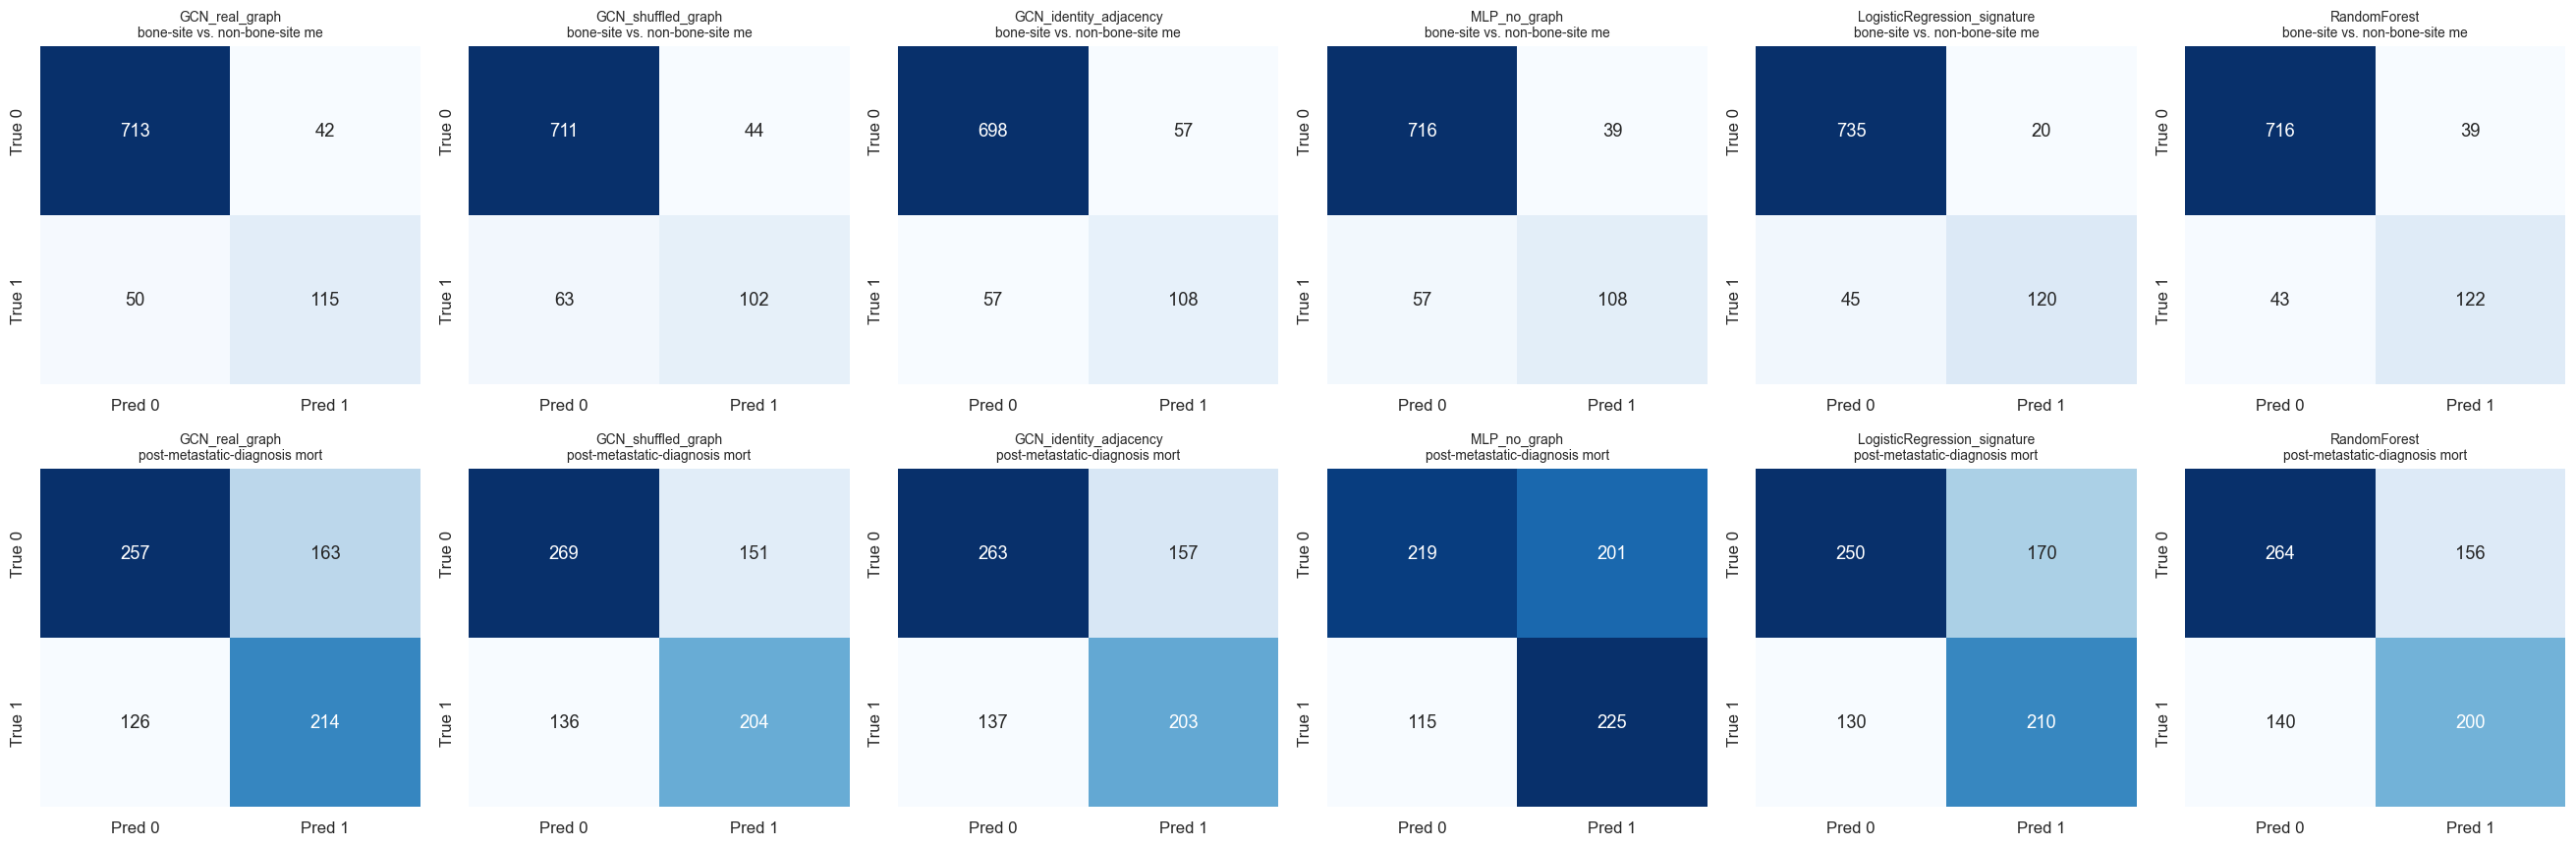

In [106]:
fig, axes = plt.subplots(len(TASKS), len(ABLATION_MODELS), figsize=(4 * len(ABLATION_MODELS), 4 * len(TASKS)))
for ti, task_name in enumerate(TASKS):
    for mi, model_name in enumerate(ABLATION_MODELS):
        ax = axes[ti, mi] if len(TASKS) > 1 else axes[mi]
        cm = oof_confusion[(task_name, model_name)]
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                    xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
        ax.set_title(f"{model_name}\n{TASKS[task_name]['label'][:30]}", fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ablation_pooled_OOF_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()


In [107]:
# ============================================================
# Reconciliation table: why the Graph-CNN (K=7, real graph) numbers differed  [R5]
# ============================================================
def _g(name):
    return globals().get(name)

recon = []
def _add(analysis, preprocessing, partitions, seeds, epochs, statistic, auc_mean, auc_sd):
    recon.append({"analysis": analysis, "preprocessing": preprocessing, "partitions": partitions,
                  "network seeds": seeds, "epochs / checkpoint": epochs, "AUC statistic": statistic,
                  "AUC mean": auc_mean, "AUC SD": auc_sd})

for task_name in TASKS:
    lab = TASKS[task_name]["label"]
    if _g("cv_results") is not None:
        d = cv_results[task_name]["gcnn"]
        _add(f"[{task_name}] Legacy main CV (Sec. 12)", "full cohort", "1 x 5-fold, random_state=0", "unseeded",
             "30 / best inner-val AUC", "fold-averaged (5 folds)", d["AUC"].mean(), d["AUC"].std())
    if _g("cv_results_strict") is not None:
        d = cv_results_strict[task_name]["gcnn"]
        _add(f"[{task_name}] Legacy strict variant (Sec. 12)", "fold-internal", "1 x 5-fold, random_state=0",
             "unseeded", "30 / best inner-val AUC", "fold-averaged (5 folds)", d["AUC"].mean(), d["AUC"].std())
    if _g("k_sweep_summary") is not None:
        d = k_sweep_summary[(k_sweep_summary.task == lab) & (k_sweep_summary.K == 7)]
        if len(d):
            _add(f"[{task_name}] Legacy K sweep, K=7 (Item 7)", "full cohort", "1 x 5-fold, random_state=0",
                 "unseeded", "30 / best inner-val AUC", "fold-averaged (5 folds), population SD",
                 d["mean_AUC"].iloc[0], d["std_AUC"].iloc[0])
    if _g("ablation_summary") is not None:
        d = ablation_summary[(ablation_summary.task == lab) & (ablation_summary.model == "GCN_real_graph")]
        if len(d):
            _add(f"[{task_name}] Legacy ablation (Items 2-4)", "full cohort", "5 x 5-fold, random_state=repeat",
                 "unseeded", "30 / best inner-val AUC", "pooled OOF per repeat, mean over 5",
                 d["AUC_mean"].iloc[0], d["AUC_std"].iloc[0])
    pf = PRIMARY_FOLD[(PRIMARY_FOLD.task == task_name) & (PRIMARY_FOLD.model == "GCN_real_K7")]
    po = primary_summary[(primary_summary.task == task_name) & (primary_summary.model == "GCN_real_K7")].iloc[0]
    r0 = pf[pf.repeat == 0]
    _add(f"[{task_name}] PRIMARY repeat 0 only (Sec. 12P)", "fold-internal", "saved; = legacy folds",
         "fixed per fold", "30 / best inner-val AUC", "fold-averaged (5 folds)", r0["AUC"].mean(), r0["AUC"].std())
    _add(f"[{task_name}] PRIMARY (Sec. 12P) -- REPORT THIS", "fold-internal", "saved, shared, 5 x 5-fold",
         "fixed per fold", "30 / best inner-val AUC", "fold-averaged (25 folds)",
         po["fold_averaged_AUC_mean"], po["fold_averaged_AUC_sd"])
    _add(f"[{task_name}] PRIMARY (Sec. 12P) -- REPORT THIS", "fold-internal", "saved, shared, 5 x 5-fold",
         "fixed per fold", "30 / best inner-val AUC", "pooled OOF per repeat, mean over 5",
         po["pooled_OOF_AUC_mean"], po["pooled_OOF_AUC_sd"])

reconciliation = pd.DataFrame(recon)
reconciliation.to_csv(f"{OUT_DIR}/graph_cnn_results_reconciliation.csv", index=False)
display(reconciliation.round(3))
print("Sources of difference between legacy rows: (1) unseeded network initialization and batch order, so "
      "two runs on identical folds differ; (2) the ablation used different outer partitions (random_state=repeat) "
      "and a pooled statistic; (3) the K sweep reported population SD (ddof=0); (4) full-cohort vs fold-internal "
      "preprocessing. The PRIMARY rows remove (1)-(4): one pipeline, fixed seeds, shared saved partitions.")


,analysis,preprocessing,partitions,network seeds,epochs / checkpoint,AUC statistic,AUC mean,AUC SD
0,[bone_metastasis] Legacy main CV (Sec. 12),full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.878,0.147
1,[bone_metastasis] Legacy strict variant (Sec. 12),fold-internal,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.889,0.102
2,"[bone_metastasis] Legacy K sweep, K=7 (Item 7)",full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,"fold-averaged (5 folds), population SD",0.854,0.172
3,[bone_metastasis] Legacy ablation (Items 2-4),full cohort,"5 x 5-fold, random_state=repeat",unseeded,30 / best inner-val AUC,"pooled OOF per repeat, mean over 5",0.761,0.100
4,[bone_metastasis] PRIMARY repeat 0 only (Sec. ...,fold-internal,saved; = legacy folds,fixed per fold,30 / best inner-val AUC,fold-averaged (5 folds),0.855,0.131
5,[bone_metastasis] PRIMARY (Sec. 12P) -- REPORT...,fold-internal,"saved, shared, 5 x 5-fold",fixed per fold,30 / best inner-val AUC,fold-averaged (25 folds),0.883,0.096
6,[bone_metastasis] PRIMARY (Sec. 12P) -- REPORT...,fold-internal,"saved, shared, 5 x 5-fold",fixed per fold,30 / best inner-val AUC,"pooled OOF per repeat, mean over 5",0.779,0.098
7,[survival_outcome] Legacy main CV (Sec. 12),full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.660,0.117
8,[survival_outcome] Legacy strict variant (Sec....,fold-internal,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.681,0.041
9,"[survival_outcome] Legacy K sweep, K=7 (Item 7)",full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,"fold-averaged (5 folds), population SD",0.712,0.122


Sources of difference between legacy rows: (1) unseeded network initialization and batch order, so two runs on identical folds differ; (2) the ablation used different outer partitions (random_state=repeat) and a pooled statistic; (3) the K sweep reported population SD (ddof=0); (4) full-cohort vs fold-internal preprocessing. The PRIMARY rows remove (1)-(4): one pipeline, fixed seeds, shared saved partitions.


In [108]:
# ============================================================
# Reconciliation addendum  [R5]   (v13)
# ============================================================
# 1. Verifies, from the saved predictions, that every primary model was scored on exactly the same
#    test sets and that each sample is tested once per repeat (the reconciliation rests on this).
# 2. Adds a 95% bootstrap CI to the primary pooled OOF AUC. Resampling unit = patient when the
#    patient mapping is available, otherwise sample. The same resample is applied to all repeats,
#    so the CI is for the repeat-averaged pooled OOF AUC (the number reported in Table 1).
# 3. Adds the Section 13 single-split AUC as its own row. That model exists only to produce the
#    GLRP explanations; its AUC comes from one 20% split and must not be quoted as performance.
# 4. Cross-checks every Graph-CNN AUC quoted in the manuscript against the table.
#    Fill MANUSCRIPT_AUCS with the numbers exactly as they appear in the text/figures.
MANUSCRIPT_AUCS = {
    # "bone_metastasis": {"Abstract": 0.00, "Results para 2": 0.00, "Figure 10 title": 0.00},
    # "survival_outcome": {"Abstract": 0.00},
}
N_BOOT_AUC = 2000

# ---- 1. partition sharing ----
share_rows = []
for task_name in TASKS:
    d = PRIMARY_OOF[PRIMARY_OOF.task == task_name]
    ref_key, ref_model = None, None
    for model_name, dm in d.groupby("model", sort=False):
        key = sorted(map(tuple, dm[["repeat", "fold", "sample_id"]].astype(str).to_numpy().tolist()))
        if ref_key is None:
            ref_key, ref_model = key, model_name
        once = dm.groupby("repeat")["sample_id"].apply(
            lambda s: s.is_unique and set(s) == set(TASK_SAMPLE_IDS[task_name])).all()
        share_rows.append({"task": task_name, "model": model_name,
                           f"same_test_sets_as_{ref_model}": key == ref_key,
                           "each_sample_tested_once_per_repeat": bool(once)})
partition_check = pd.DataFrame(share_rows)
display(partition_check)
assert partition_check.iloc[:, 2].all() and partition_check["each_sample_tested_once_per_repeat"].all(), \
    "Some model was NOT evaluated on the shared partitions -- the reconciliation table is not valid until fixed."
print("All primary models were evaluated on identical saved test sets.\n")

# ---- 2. bootstrap CI ----
_grp_lookup = None
if bool(globals().get("PATIENT_GROUPS_AVAILABLE", False)) and globals().get("PATIENT_ID_SERIES") is not None:
    _grp_lookup = PATIENT_ID_SERIES

def boot_ci_pooled_oof(d, groups_lookup=None, n_boot=N_BOOT_AUC, seed=0):
    """CI for the repeat-averaged pooled OOF AUC; one resample of units, applied to every repeat."""
    rng = np.random.default_rng(seed)
    Pdf = d.pivot_table(index="sample_id", columns="repeat", values="prob")
    sample_ids = Pdf.index
    y = d.drop_duplicates("sample_id").set_index("sample_id")["y_true"].reindex(sample_ids).to_numpy()
    P = Pdf.to_numpy()
    point = float(np.mean([roc_auc_score(y, P[:, r]) for r in range(P.shape[1])]))
    unit = "sample"
    unit_arr = np.asarray(sample_ids, dtype=object)
    if groups_lookup is not None:
        g = pd.Series(groups_lookup.reindex(sample_ids).to_numpy(), index=sample_ids)
        if g.notna().any():
            unit_arr = g.fillna(pd.Series(sample_ids, index=sample_ids)).to_numpy(dtype=object)
            unit = "patient"
    uniq = pd.unique(unit_arr)
    rows_by_unit = {u: np.where(unit_arr == u)[0] for u in uniq}
    stats_ = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_by_unit[u] for u in rng.choice(uniq, size=len(uniq), replace=True)])
        if len(np.unique(y[idx])) < 2:
            continue
        stats_.append(np.mean([roc_auc_score(y[idx], P[idx, r]) for r in range(P.shape[1])]))
    lo, hi = np.percentile(stats_, [2.5, 97.5])
    return point, float(lo), float(hi), len(stats_), unit

def boot_ci_single(y, p, n_boot=N_BOOT_AUC, seed=0):
    rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p)
    point = roc_auc_score(y, p); st = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) > 1:
            st.append(roc_auc_score(y[i], p[i]))
    return point, *np.percentile(st, [2.5, 97.5])

ci_rows = []
for task_name in TASKS:
    for model_name in [m for m in PRIMARY_MODELS if not m.startswith("GCN_shuffled_s")]:
        d = PRIMARY_OOF[(PRIMARY_OOF.task == task_name) & (PRIMARY_OOF.model == model_name)]
        if d.empty:
            continue
        pt, lo, hi, nb, unit = boot_ci_pooled_oof(d, _grp_lookup)
        ci_rows.append({"task": task_name, "model": model_name, "pooled_OOF_AUC_repeat_mean": pt,
                        "CI95_lower": lo, "CI95_upper": hi, "bootstrap_unit": unit, "n_boot_valid": nb})
primary_auc_ci = pd.DataFrame(ci_rows)
primary_auc_ci.to_csv(f"{OUT_DIR}/PRIMARY_pooled_OOF_AUC_bootstrap_CI.csv", index=False)
print("Primary pooled OOF AUC with 95% bootstrap CI:")
display(primary_auc_ci.round(3))

# ---- 3. single explanation split, as its own labeled row ----
extra_recon = []
for task_name in TASKS:
    if "final_test_splits" not in globals() or task_name not in final_test_splits:
        continue
    sp_ = final_test_splits[task_name]
    pt, lo, hi = boot_ci_single(sp_["yte"], sp_["te_probs"])
    extra_recon.append({"analysis": f"[{task_name}] Section 13 explanation model (single split) -- DO NOT REPORT "
                                    f"AS PERFORMANCE",
                        "preprocessing": "fold-internal (train part of the split)",
                        "partitions": "1 x 80/20, random_state=7", "network seeds": "unseeded",
                        "epochs / checkpoint": "30 / best val AUC",
                        "AUC statistic": f"single held-out split, n={len(sp_['yte'])} (95% CI {lo:.3f}-{hi:.3f})",
                        "AUC mean": pt, "AUC SD": np.nan})
for _, r in primary_auc_ci[primary_auc_ci.model == "GCN_real_K7"].iterrows():
    extra_recon.append({"analysis": f"[{r.task}] PRIMARY (Sec. 12P) -- REPORT THIS, with 95% CI",
                        "preprocessing": "fold-internal", "partitions": "saved, shared, 5 x 5-fold",
                        "network seeds": "fixed per fold", "epochs / checkpoint": "30 / best inner-val AUC",
                        "AUC statistic": f"pooled OOF, repeat mean (95% {r.bootstrap_unit} bootstrap CI "
                                         f"{r.CI95_lower:.3f}-{r.CI95_upper:.3f})",
                        "AUC mean": r.pooled_OOF_AUC_repeat_mean, "AUC SD": np.nan})
if "k_nested" in globals():
    for _, r in k_nested.iterrows():
        extra_recon.append({"analysis": f"[{r.task}] PRIMARY, K selected per fold (12P-5)",
                            "preprocessing": "fold-internal", "partitions": "saved, shared, 5 x 5-fold",
                            "network seeds": "fixed per fold", "epochs / checkpoint": "30 / best inner-val AUC",
                            "AUC statistic": "pooled OOF per repeat, mean over 5",
                            "AUC mean": r.pooled_OOF_AUC_mean, "AUC SD": r.pooled_OOF_AUC_sd})
reconciliation_v13 = pd.concat([reconciliation, pd.DataFrame(extra_recon)], ignore_index=True)
reconciliation_v13.to_csv(f"{OUT_DIR}/graph_cnn_results_reconciliation_v13.csv", index=False)
display(reconciliation_v13.round(3))

# ---- 4. manuscript cross-check ----
if not MANUSCRIPT_AUCS:
    print("\nMANUSCRIPT_AUCS is empty -- fill it with every Graph-CNN AUC quoted in the manuscript and re-run "
          "this cell to see which experiment each number came from.")
else:
    chk = []
    for task_name, quotes in MANUSCRIPT_AUCS.items():
        cand = reconciliation_v13[reconciliation_v13.analysis.str.startswith(f"[{task_name}]")]
        prim = cand[cand.analysis.str.contains("REPORT THIS")]
        for where, val in quotes.items():
            i_best = (cand["AUC mean"] - val).abs().idxmin()
            matches_primary = bool(((prim["AUC mean"] - val).abs() <= 0.0051).any())
            chk.append({"task": task_name, "manuscript location": where, "quoted AUC": val,
                        "closest row": cand.loc[i_best, "analysis"], "closest AUC": cand.loc[i_best, "AUC mean"],
                        "matches a PRIMARY row (±0.005)": matches_primary,
                        "action": "OK" if matches_primary else "REPLACE with the primary value (and state the statistic)"})
    manuscript_auc_check = pd.DataFrame(chk)
    manuscript_auc_check.to_csv(f"{OUT_DIR}/manuscript_auc_crosscheck.csv", index=False)
    display(manuscript_auc_check.round(3))


,task,model,same_test_sets_as_GCN_real_K7,each_sample_tested_once_per_repeat
0,bone_metastasis,GCN_real_K7,True,True
1,bone_metastasis,GCN_shuffled_K7,True,True
2,bone_metastasis,GCN_identity_K7,True,True
3,bone_metastasis,MLP_no_graph,True,True
4,bone_metastasis,LogisticRegression,True,True
5,bone_metastasis,RandomForest,True,True
6,bone_metastasis,GCN_real_K3,True,True
7,bone_metastasis,GCN_real_K5,True,True
8,bone_metastasis,GCN_real_K9,True,True
9,bone_metastasis,GCN_string700_K7,True,True


All primary models were evaluated on identical saved test sets.



Primary pooled OOF AUC with 95% bootstrap CI:


,task,model,pooled_OOF_AUC_repeat_mean,CI95_lower,CI95_upper,bootstrap_unit,n_boot_valid
0,bone_metastasis,GCN_real_K7,0.779,0.717,0.835,sample,2000
1,bone_metastasis,GCN_shuffled_K7,0.749,0.677,0.812,sample,2000
2,bone_metastasis,GCN_identity_K7,0.702,0.627,0.768,sample,2000
3,bone_metastasis,MLP_no_graph,0.737,0.667,0.802,sample,2000
4,bone_metastasis,LogisticRegression,0.903,0.809,0.976,sample,2000
5,bone_metastasis,RandomForest,0.926,0.850,0.978,sample,2000
6,bone_metastasis,GCN_real_K3,0.731,0.659,0.794,sample,2000
7,bone_metastasis,GCN_real_K5,0.765,0.694,0.826,sample,2000
8,bone_metastasis,GCN_real_K9,0.823,0.755,0.880,sample,2000
9,bone_metastasis,GCN_string700_K7,0.808,0.744,0.864,sample,2000


,analysis,preprocessing,partitions,network seeds,epochs / checkpoint,AUC statistic,AUC mean,AUC SD
0,[bone_metastasis] Legacy main CV (Sec. 12),full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.878,0.147
1,[bone_metastasis] Legacy strict variant (Sec. 12),fold-internal,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.889,0.102
2,"[bone_metastasis] Legacy K sweep, K=7 (Item 7)",full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,"fold-averaged (5 folds), population SD",0.854,0.172
3,[bone_metastasis] Legacy ablation (Items 2-4),full cohort,"5 x 5-fold, random_state=repeat",unseeded,30 / best inner-val AUC,"pooled OOF per repeat, mean over 5",0.761,0.100
4,[bone_metastasis] PRIMARY repeat 0 only (Sec. ...,fold-internal,saved; = legacy folds,fixed per fold,30 / best inner-val AUC,fold-averaged (5 folds),0.855,0.131
5,[bone_metastasis] PRIMARY (Sec. 12P) -- REPORT...,fold-internal,"saved, shared, 5 x 5-fold",fixed per fold,30 / best inner-val AUC,fold-averaged (25 folds),0.883,0.096
6,[bone_metastasis] PRIMARY (Sec. 12P) -- REPORT...,fold-internal,"saved, shared, 5 x 5-fold",fixed per fold,30 / best inner-val AUC,"pooled OOF per repeat, mean over 5",0.779,0.098
7,[survival_outcome] Legacy main CV (Sec. 12),full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.660,0.117
8,[survival_outcome] Legacy strict variant (Sec....,fold-internal,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,fold-averaged (5 folds),0.681,0.041
9,"[survival_outcome] Legacy K sweep, K=7 (Item 7)",full cohort,"1 x 5-fold, random_state=0",unseeded,30 / best inner-val AUC,"fold-averaged (5 folds), population SD",0.712,0.122



MANUSCRIPT_AUCS is empty -- fill it with every Graph-CNN AUC quoted in the manuscript and re-run this cell to see which experiment each number came from.


[bone_metastasis] tracking 31 held-out samples across 10 retrainings


[survival_outcome] tracking 21 held-out samples across 10 retrainings


Per-retraining held-out AUC and explanation similarity to the other retrainings:


,task,seed,best_val_AUC,heldout_AUC,GLRP_mean_top140_jaccard_to_other_seeds,IG_mean_top140_jaccard_to_other_seeds
0,bone_metastasis,1000,0.961,0.833,0.118,0.383
1,bone_metastasis,1001,0.961,0.710,0.147,0.307
2,bone_metastasis,1002,0.921,0.767,0.152,0.364
3,bone_metastasis,1003,1.000,0.743,0.154,0.279
4,bone_metastasis,1004,1.000,0.714,0.146,0.307
5,bone_metastasis,1005,0.987,0.767,0.144,0.363
6,bone_metastasis,1006,1.000,0.771,0.140,0.288
7,bone_metastasis,1007,1.000,0.719,0.173,0.315
8,bone_metastasis,1008,0.987,0.795,0.149,0.370
9,bone_metastasis,1009,1.000,0.790,0.148,0.371


Stability, median across tracked samples (chance = two random gene lists):


...

,jaccard_top20_GLRP_vs_IG,jaccard_top140_GLRP_vs_IG,spearman_GLRP_vs_IG
task,,,
bone_metastasis,0.026,0.120,0.017
survival_outcome,0.000,0.107,-0.004


IG completeness error (|sum IG - (f(x) - f(baseline))| / |f(x) - f(baseline)|):


,count,mean,std,min,25%,50%,75%,max
task,,,,,,,,
bone_metastasis,310.0,0.0028,0.0056,0.0,0.0004,0.0010,0.0021,0.0403
survival_outcome,210.0,0.0036,0.0067,0.0,0.0005,0.0013,0.0038,0.0479


IG samples above 5% error even at 256 steps: 0 of 520
Runtime per explanation (seconds):


method,GLRP,IG
task,,
bone_metastasis,0.0143,0.0933
survival_outcome,0.0144,0.0933


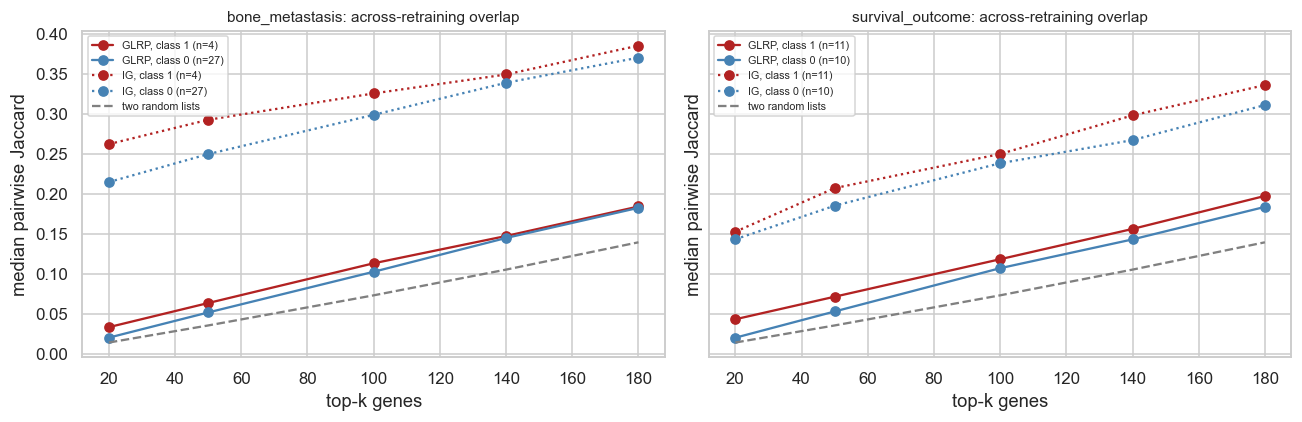

In [109]:
# ============================================================
# Item 9 (v14) -- explanation stability across 10 retrainings: GLRP-style vs Integrated Gradients  [R6, R8]
# ============================================================
# Both methods are applied to the SAME retrained checkpoints and the SAME tracked held-out samples.
# IG baseline = mean expression of the explanation split's training samples (no test data used).
import time as _time
from itertools import combinations
from scipy.stats import spearmanr

N_SEED_REPEATS = 10
STABILITY_TOPK = [20, 50, 100, 140, 180]
STABLE_CORE_FREQ = 0.8
MAX_TRACKED_PER_CLASS = None
IG_STEPS = [64, 128, 256]          # steps are increased until the completeness error is below IG_MAX_COMPLETENESS_ERR
IG_MAX_COMPLETENESS_ERR = 0.05
EXPLAIN_METHODS = ["GLRP", "IG"]

def integrated_gradients(model, x, baseline, target_class, L_op=None):
    """IG for the target-class logit (same output GLRP explains). Trapezoid rule on a straight path.
    Returns (attribution[N], relative completeness error, f(x)-f(baseline), steps used)."""
    L_op = L_hat if L_op is None else L_op
    model.eval()
    xt = torch.tensor(np.asarray(x, np.float32)); bt = torch.tensor(np.asarray(baseline, np.float32))
    with torch.no_grad():
        delta_f = (model(L_op, xt[None])[0, target_class] - model(L_op, bt[None])[0, target_class]).item()
    for steps in IG_STEPS:
        alphas = torch.linspace(0, 1, steps + 1)[:, None]
        path = (bt[None] + alphas * (xt - bt)[None]).requires_grad_(True)
        out = model(L_op, path)[:, target_class]
        grads = torch.autograd.grad(out.sum(), path)[0]
        avg_grad = ((grads[:-1] + grads[1:]) / 2).mean(0)
        ig = ((xt - bt) * avg_grad).detach().numpy()
        err = abs(ig.sum() - delta_f) / max(abs(delta_f), 1e-8)
        if err <= IG_MAX_COMPLETENESS_ERR:
            break
    return ig, float(err), float(delta_f), steps

def expected_random_jaccard(k, n):
    inter = k * k / n
    return inter / (2 * k - inter)

def _explain(method, model, x, cls, ig_baseline):
    t0 = _time.perf_counter()
    if method == "GLRP":
        _, _, rel = glrp_explain(model, torch.tensor(x[None]).unsqueeze(-1), cls); extra = {}
    else:
        rel, err, dfx, steps = integrated_gradients(model, x, ig_baseline, cls)
        extra = {"ig_completeness_error": err, "ig_steps": steps}
    return rel, _time.perf_counter() - t0, extra

seed_stability_rows, seed_model_rows, selection_freq_rows, runtime_rows, crossmethod_rows, ig_diag_rows = [], [], [], [], [], []
seed_stability_relevance_by_task = {}

for task_name, task in TASKS.items():
    X_task, y_task = EXPL_X[task_name], task["y"]
    sample_ids = list(TASK_SAMPLE_IDS[task_name])
    Xtr0, Xte, ytr0, yte, _, pte = train_test_split(X_task, y_task, sample_ids, test_size=0.2,
                                                    stratify=y_task, random_state=7)
    Xtr0, Xva0, ytr0, yva0 = train_test_split(Xtr0, ytr0, test_size=0.15, stratify=ytr0, random_state=7)
    ref = final_test_splits[task_name]
    assert list(pte) == list(ref["pte"]), "held-out split differs from Section 13"
    ig_baseline = Xtr0.mean(axis=0).astype(np.float32)

    track_idx = [i for i in range(len(yte)) if int(yte[i]) == int(ref["te_preds"][i])]
    if MAX_TRACKED_PER_CLASS:
        track_idx = ([i for i in track_idx if yte[i] == 1][:MAX_TRACKED_PER_CLASS]
                     + [i for i in track_idx if yte[i] == 0][:MAX_TRACKED_PER_CLASS])
    print(f"[{task_name}] tracking {len(track_idx)} held-out samples across {N_SEED_REPEATS} retrainings")

    rels = {m: {i: [] for i in track_idx} for m in EXPLAIN_METHODS}
    correct = {i: [] for i in track_idx}
    for s in range(N_SEED_REPEATS):
        seed = 1000 + s
        torch.manual_seed(seed); np.random.seed(seed)
        m_s, best_val = train_one_fold(Xtr0, ytr0, Xva0, yva0)
        m_s.eval()
        with torch.no_grad():
            va_p = torch.softmax(m_s(L_hat, torch.tensor(Xva0)), dim=1)[:, 1].numpy()
            te_p = torch.softmax(m_s(L_hat, torch.tensor(Xte)), dim=1)[:, 1].numpy()
        preds_s = (te_p >= youden_threshold(yva0, va_p)).astype(int)
        seed_model_rows.append({"task": task_name, "seed": seed, "best_val_AUC": best_val,
                                "heldout_AUC": roc_auc_score(yte, te_p)})
        for i in track_idx:
            for meth in EXPLAIN_METHODS:
                rel, secs, extra = _explain(meth, m_s, Xte[i], int(yte[i]), ig_baseline)
                rels[meth][i].append(rel)
                runtime_rows.append({"task": task_name, "method": meth, "seconds": secs})
                if meth == "IG":
                    ig_diag_rows.append({"task": task_name, "seed": seed, "patient_id": pte[i], **extra})
            correct[i].append(bool(preds_s[i] == yte[i]))
            a_, b_ = np.abs(rels["GLRP"][i][-1]), np.abs(rels["IG"][i][-1])
            crossmethod_rows.append({"task": task_name, "seed": seed, "patient_id": pte[i],
                                     "jaccard_top20_GLRP_vs_IG": jaccard(topk_geneset(rels["GLRP"][i][-1], 20),
                                                                         topk_geneset(rels["IG"][i][-1], 20)),
                                     "jaccard_top140_GLRP_vs_IG": jaccard(topk_geneset(rels["GLRP"][i][-1], 140),
                                                                          topk_geneset(rels["IG"][i][-1], 140)),
                                     "spearman_GLRP_vs_IG": spearmanr(a_, b_).correlation})

    seed_stability_relevance_by_task[task_name] = {
        "per_patient_relevance": rels["GLRP"], "per_patient_relevance_ig": rels["IG"],
        "per_patient_true_class": {i: int(yte[i]) for i in track_idx},
        "per_patient_correct": correct, "pte": pte,
    }

    for meth in EXPLAIN_METHODS:
        per_seed_j = {s: [] for s in range(N_SEED_REPEATS)}
        for i in track_idx:
            R = rels[meth][i]; ok = np.array(correct[i])
            pairs = list(combinations(range(len(R)), 2))
            absR = np.abs(np.vstack(R))
            row = {"task": task["label"], "task_key": task_name, "method": meth, "patient_id": pte[i],
                   "true_class": int(yte[i]), "n_seeds": len(R), "n_seeds_correct": int(ok.sum()),
                   "mean_pairwise_spearman_abs_relevance": np.mean([spearmanr(absR[a], absR[b]).correlation
                                                                    for a, b in pairs])}
            for k in STABILITY_TOPK:
                sets_k = [topk_geneset(r, k) for r in R]
                jk = np.mean([jaccard(sets_k[a], sets_k[b]) for a, b in pairs])
                row[f"jaccard_top{k}"] = jk
                row[f"jaccard_top{k}_fold_over_chance"] = jk / expected_random_jaccard(k, N)
            sets140 = [topk_geneset(r, 140) for r in R]
            for a, b in pairs:                                   # per-seed similarity to the other seeds
                jj = jaccard(sets140[a], sets140[b]); per_seed_j[a].append(jj); per_seed_j[b].append(jj)
            okidx = np.where(ok)[0]
            row["jaccard_top140_correct_seeds_only"] = (np.mean([jaccard(sets140[a], sets140[b])
                                                                 for a, b in combinations(okidx, 2)])
                                                        if len(okidx) >= 2 else np.nan)
            freq = pd.Series([g for s_ in sets140 for g in s_]).value_counts() / len(R)
            row["n_stable_core_genes_top140"] = int((freq >= STABLE_CORE_FREQ).sum())
            row["mean_pairwise_jaccard_across_seeds"] = row["jaccard_top140"]
            seed_stability_rows.append(row)
            for g, f in freq.items():
                selection_freq_rows.append({"task": task_name, "method": meth, "true_class": int(yte[i]),
                                            "patient_id": pte[i], "gene": g, "top140_selection_frequency": f})
        for s in range(N_SEED_REPEATS):
            mrow = next(r for r in seed_model_rows if r["task"] == task_name and r["seed"] == 1000 + s)
            mrow[f"{meth}_mean_top140_jaccard_to_other_seeds"] = np.mean(per_seed_j[s]) if per_seed_j[s] else np.nan

seed_stability_df = pd.DataFrame(seed_stability_rows)
seed_model_df = pd.DataFrame(seed_model_rows)
sel_freq_long = pd.DataFrame(selection_freq_rows)
explain_runtime = pd.DataFrame(runtime_rows)
crossmethod_df = pd.DataFrame(crossmethod_rows)
ig_diag = pd.DataFrame(ig_diag_rows)

n_tracked = seed_stability_df.groupby(["task_key", "method", "true_class"])["patient_id"].nunique()
gene_consensus = (sel_freq_long.groupby(["task", "method", "true_class", "gene"])["top140_selection_frequency"]
                  .sum().reset_index())
gene_consensus["mean_selection_frequency"] = gene_consensus.apply(
    lambda r: r.top140_selection_frequency / n_tracked.loc[(r.task, r.method, r.true_class)], axis=1)
gene_consensus = gene_consensus.drop(columns="top140_selection_frequency").sort_values(
    ["task", "method", "true_class", "mean_selection_frequency"], ascending=[True, True, True, False])
gene_consensus["is_hub_gene"] = gene_consensus["gene"].isin(HUB_GENES)

seed_stability_df.to_csv(f"{OUT_DIR}/glrp_seed_stability_gene_level.csv", index=False)
seed_model_df.to_csv(f"{OUT_DIR}/glrp_seed_stability_model_auc_and_similarity.csv", index=False)
gene_consensus.to_csv(f"{OUT_DIR}/glrp_seed_stability_gene_selection_frequency.csv", index=False)
crossmethod_df.to_csv(f"{OUT_DIR}/explanation_GLRP_vs_IG_agreement.csv", index=False)
ig_diag.to_csv(f"{OUT_DIR}/ig_completeness_diagnostics.csv", index=False)

stab_cols = (["mean_pairwise_spearman_abs_relevance"] + [f"jaccard_top{k}" for k in STABILITY_TOPK]
             + ["jaccard_top140_correct_seeds_only", "n_stable_core_genes_top140"])
stab_summary = seed_stability_df.groupby(["task_key", "method", "true_class"])[stab_cols].median().reset_index()
for k in STABILITY_TOPK:
    stab_summary[f"jaccard_top{k}_chance"] = expected_random_jaccard(k, N)
stab_summary.to_csv(f"{OUT_DIR}/glrp_seed_stability_summary.csv", index=False)

print("Per-retraining held-out AUC and explanation similarity to the other retrainings:")
display(seed_model_df.round(3))
print("Stability, median across tracked samples (chance = two random gene lists):")
display(stab_summary.round(3))
print("GLRP vs IG agreement on the same checkpoint (median):")
display(crossmethod_df.groupby("task")[["jaccard_top20_GLRP_vs_IG", "jaccard_top140_GLRP_vs_IG",
                                        "spearman_GLRP_vs_IG"]].median().round(3))
print("IG completeness error (|sum IG - (f(x) - f(baseline))| / |f(x) - f(baseline)|):")
display(ig_diag.groupby("task")["ig_completeness_error"].describe().round(4))
print(f"IG samples above {IG_MAX_COMPLETENESS_ERR:.0%} error even at {IG_STEPS[-1]} steps: "
      f"{int((ig_diag.ig_completeness_error > IG_MAX_COMPLETENESS_ERR).sum())} of {len(ig_diag)}")
print("Runtime per explanation (seconds):")
display(explain_runtime.groupby(["task", "method"])["seconds"].median().unstack().round(4))

fig, axes = plt.subplots(1, len(TASKS), figsize=(6 * len(TASKS), 4), sharey=True, squeeze=False)
for ax, task_name in zip(axes[0], TASKS):
    for meth, ls in [("GLRP", "-"), ("IG", ":")]:
        for cls, col in [(1, "firebrick"), (0, "steelblue")]:
            dc = seed_stability_df[(seed_stability_df.task_key == task_name) & (seed_stability_df.method == meth)
                                   & (seed_stability_df.true_class == cls)]
            if dc.empty:
                continue
            ax.plot(STABILITY_TOPK, [dc[f"jaccard_top{k}"].median() for k in STABILITY_TOPK], "o" + ls, color=col,
                    label=f"{meth}, class {cls} (n={len(dc)})")
    ax.plot(STABILITY_TOPK, [expected_random_jaccard(k, N) for k in STABILITY_TOPK], "--", color="grey",
            label="two random lists")
    ax.set_title(f"{task_name}: across-retraining overlap", fontsize=10)
    ax.set_xlabel("top-k genes"); ax.set_ylabel("median pairwise Jaccard"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/explanation_stability_GLRP_vs_IG.png", dpi=200, bbox_inches="tight"); plt.show()


In [110]:
# ============================================================
# Item 9 pathway part (v14) -- pathway-level stability, conditional AND unconditional, GLRP and IG
# ============================================================
# conditional   = mean Jaccard over pairs of retrainings where BOTH gave >= 1 significant KEGG term
# unconditional = mean Jaccard over ALL pairs; a pair with an empty term set on either side counts as 0
#                 (conservative: two empty sets are not counted as agreement)
# Cost: one Enrichr call per (sample, retraining, method): 2 tasks x 2 classes x 4 samples x 10 x 2 = 320 calls.
PATHWAY_MAX_PER_CLASS = 4
PATHWAY_METHODS = ["GLRP", "IG"]

pathway_seed_stability_rows = []
for task_name, task in TASKS.items():
    store = seed_stability_relevance_by_task[task_name]
    cls_of, pte = store["per_patient_true_class"], store["pte"]
    rel_by_method = {"GLRP": store["per_patient_relevance"], "IG": store["per_patient_relevance_ig"]}
    chosen = ([i for i in cls_of if cls_of[i] == 1][:PATHWAY_MAX_PER_CLASS]
              + [i for i in cls_of if cls_of[i] == 0][:PATHWAY_MAX_PER_CLASS])
    for meth in PATHWAY_METHODS:
        for i in chosen:
            R = rel_by_method[meth][i]
            if len(R) < 2:
                continue
            termsets = [patient_kegg_termset(r, k=140) for r in R]
            pairs = list(combinations(range(len(termsets)), 2))
            cond = [jaccard(termsets[a], termsets[b]) for a, b in pairs if termsets[a] and termsets[b]]
            uncond = [jaccard(termsets[a], termsets[b]) if (termsets[a] and termsets[b]) else 0.0 for a, b in pairs]
            pathway_seed_stability_rows.append({
                "task": task_name, "method": meth, "patient_id": pte[i], "true_class": cls_of[i],
                "n_retrainings": len(R), "n_retrainings_no_significant_terms": sum(1 for t in termsets if not t),
                "pathway_jaccard_conditional": np.mean(cond) if cond else np.nan,
                "n_pairs_conditional": len(cond),
                "pathway_jaccard_unconditional": np.mean(uncond),
                "mean_pairwise_pathway_jaccard_across_seeds": np.mean(cond) if cond else np.nan,
            })

pathway_seed_stability_df = pd.DataFrame(pathway_seed_stability_rows)
pathway_seed_stability_df.to_csv(f"{OUT_DIR}/glrp_seed_stability_pathway_level.csv", index=False)
display(pathway_seed_stability_df.round(3))
display(pathway_seed_stability_df.groupby(["task", "method"])[
    ["pathway_jaccard_conditional", "pathway_jaccard_unconditional", "n_retrainings_no_significant_terms"]]
    .median().round(3))


,task,method,patient_id,true_class,n_retrainings,n_retrainings_no_significant_terms,pathway_jaccard_conditional,n_pairs_conditional,pathway_jaccard_unconditional,mean_pairwise_pathway_jaccard_across_seeds
0,bone_metastasis,GLRP,GSM5344148,1,10,2,0.026,28,0.016,0.026
1,bone_metastasis,GLRP,GSM5344170,1,10,3,0.068,21,0.032,0.068
2,bone_metastasis,GLRP,GSM5344119,1,10,3,0.121,21,0.057,0.121
3,bone_metastasis,GLRP,GSM5344087,1,10,1,0.182,36,0.145,0.182
4,bone_metastasis,GLRP,GSM5344157,0,10,2,0.135,28,0.084,0.135
5,bone_metastasis,GLRP,GSM5344214,0,10,3,0.014,21,0.006,0.014
6,bone_metastasis,GLRP,GSM5344182,0,10,2,0.030,28,0.019,0.030
7,bone_metastasis,GLRP,GSM5344207,0,10,1,0.083,36,0.067,0.083
8,bone_metastasis,IG,GSM5344148,1,10,6,0.037,6,0.005,0.037
9,bone_metastasis,IG,GSM5344170,1,10,10,NaN,0,0.000,NaN


pathway_jaccard_conditional  \
task             method                                
bone_metastasis  GLRP                          0.076   
                 IG                            0.052   
survival_outcome GLRP                          0.102   
                 IG                            0.000   

                         pathway_jaccard_unconditional  \
task             method                                  
bone_metastasis  GLRP                            0.044   
                 IG                              0.000   
survival_outcome GLRP                            0.076   
                 IG                              0.000   

                         n_retrainings_no_significant_terms  
task             method                                      
bone_metastasis  GLRP                                   2.0  
                 IG                                     9.0  
survival_outcome GLRP                                   2.0  
                 IG                                     9.0

In [111]:
representative_rows = []
for task_name, task in TASKS.items():
    model = final_models[task_name]
    split = final_test_splits[task_name]
    Xte, yte, pte = split["Xte"], split["yte"], split["pte"]
    te_probs, te_preds, thr = split["te_probs"], split["te_preds"], split["threshold"]
    for target_class in [1, 0]:
        class_idx = [i for i in range(len(yte)) if int(yte[i]) == target_class and int(te_preds[i]) == target_class]
        if not class_idx:
            continue
        probs_here = te_probs[class_idx]
        median_i = class_idx[int(np.argmin(np.abs(probs_here - np.median(probs_here))))]
        borderline_i = class_idx[int(np.argmin(np.abs(probs_here - thr)))]
        for tag, i in [("typical (median probability)", median_i), ("borderline (closest to threshold)", borderline_i)]:
            x0 = torch.tensor(Xte[i:i + 1]).unsqueeze(-1)
            logit_val, R_sum, rel = glrp_explain(model, x0, target_class)
            conservation = 100 * R_sum / logit_val if abs(logit_val) > np.finfo(float).eps else np.nan
            top5 = pd.Series(np.abs(rel), index=gene_list).sort_values(ascending=False).head(5).index.tolist()
            representative_rows.append({
                "task": task["label"], "patient_id": pte[i], "selection_rule": tag,
                "true_label": int(yte[i]), "predicted_label": int(te_preds[i]),
                "predicted_probability": round(float(te_probs[i]), 4),
                "relevance_conservation_pct": (round(conservation, 1) if not np.isnan(conservation) else "NA"),
                "top5_relevant_genes": ", ".join(top5),
            })

representative_df = pd.DataFrame(representative_rows)
representative_df.to_csv(f"{OUT_DIR}/glrp_representative_patients_non_cherrypicked.csv", index=False)
print("Representative GLRP patients (median-probability / closest-to-threshold selection, not maximum logit):")
display(representative_df)


Representative GLRP patients (median-probability / closest-to-threshold selection, not maximum logit):


,task,patient_id,selection_rule,true_label,predicted_label,predicted_probability,relevance_conservation_pct,top5_relevant_genes
0,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344119,typical (median probability),1,1,0.3865,100.0,"EIF2AK3, ASPM, WNT5B, DUSP6, ACVRL1"
1,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344170,borderline (closest to threshold),1,1,0.3315,100.0,"ASPM, IL13RA1, PKMYT1, TNFSF10, CDKN2C"
2,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344199,typical (median probability),0,0,0.2016,100.0,"ADCY9, DDB2, GSK3B, HGF, NPR1"
3,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344126,borderline (closest to threshold),0,0,0.2450,100.0,"RBL1, HLA-C, SLC2A1, EDNRB, ZIC2"
4,post-metastatic-diagnosis mortality within 36 ...,GSM5344153,typical (median probability),1,1,0.5070,100.0,"CXCL9, DLGAP5, MELK, GNLY, IL1R2"
5,post-metastatic-diagnosis mortality within 36 ...,GSM5344057,borderline (closest to threshold),1,1,0.5049,100.0,"CD36, PIK3R1, SOX10, BCAS1, COLEC12"
6,post-metastatic-diagnosis mortality within 36 ...,GSM5344116,typical (median probability),0,0,0.5030,100.0,"MDM2, MED1, CEACAM5, CCL2, LPL"
7,post-metastatic-diagnosis mortality within 36 ...,GSM5344171,borderline (closest to threshold),0,0,0.5041,100.0,"SMO, MAP3K12, LRP2, MAPK8IP2, FGF12"


In [112]:
# Checkpointed per (task, k) -- this cell makes ~1 Enrichr call per patient per k
# (with the same 3s courtesy pause used elsewhere), which adds up across 2 tasks x 3
# k-values. Each of the 6 (task, k) units is saved the moment it finishes, so a
# disconnect only costs you the one unit in progress, not the whole cell.
import pickle
PATHWAY_K_CHECKPOINT_DIR = os.path.join(OUT_DIR, "pathway_k_checkpoints")
os.makedirs(PATHWAY_K_CHECKPOINT_DIR, exist_ok=True)

def _pathway_k_checkpoint_path(task_name, k):
    return os.path.join(PATHWAY_K_CHECKPOINT_DIR, f"{task_name}__k{k}.pkl")

pathway_k_rows = []
for task_name in TASKS:
    class1_patients = all_patient_results[task_name][1]
    class0_patients = all_patient_results[task_name][0]
    for k in K_VALUES:
        ckpt = _pathway_k_checkpoint_path(task_name, k)
        if os.path.exists(ckpt):
            with open(ckpt, "rb") as f:
                row = pickle.load(f)
            pathway_k_rows.append(row)
            print(f"[{task_name}] k={k} loaded from checkpoint: "
                  f"within={row['mean_within_pathway_jaccard']:.3f}, "
                  f"between={row['mean_between_pathway_jaccard']:.3f}, p={row['permutation_p']}")
            continue

        terms1 = [patient_kegg_termset(p["relevance"], k=k) for p in class1_patients]
        terms0 = [patient_kegg_termset(p["relevance"], k=k) for p in class0_patients]
        within = ([jaccard(terms1[a], terms1[b]) for a in range(len(terms1)) for b in range(a + 1, len(terms1))] +
                  [jaccard(terms0[a], terms0[b]) for a in range(len(terms0)) for b in range(a + 1, len(terms0))])
        between = [jaccard(t1, t0) for t1 in terms1 for t0 in terms0]
        _, pval = permutation_test_jaccard_gap(terms1, terms0, n_perm=2000, rng_seed=k)
        row = {
            "task": TASKS[task_name]["label"], "top_k": k,
            "mean_within_pathway_jaccard": np.mean(within) if within else np.nan,
            "mean_between_pathway_jaccard": np.mean(between) if between else np.nan,
            "permutation_p": pval,
        }
        with open(ckpt, "wb") as f:
            pickle.dump(row, f)
        pathway_k_rows.append(row)
        print(f"[{task_name}] pathway Jaccard at k={k}: "
              f"within={row['mean_within_pathway_jaccard']:.3f}, "
              f"between={row['mean_between_pathway_jaccard']:.3f}, p={pval} -- checkpoint saved.")

pathway_k_summary = pd.DataFrame(pathway_k_rows)
pathway_k_summary.to_csv(f"{OUT_DIR}/glrp_pathway_heterogeneity_K_sweep.csv", index=False)
display(pathway_k_summary)


[bone_metastasis] pathway Jaccard at k=100: within=nan, between=0.115, p=nan -- checkpoint saved.


[bone_metastasis] pathway Jaccard at k=140: within=nan, between=0.158, p=nan -- checkpoint saved.


[bone_metastasis] pathway Jaccard at k=180: within=nan, between=0.160, p=nan -- checkpoint saved.


[survival_outcome] pathway Jaccard at k=100: within=0.037, between=0.042, p=0.712143928035982 -- checkpoint saved.


[survival_outcome] pathway Jaccard at k=140: within=nan, between=0.049, p=nan -- checkpoint saved.


[survival_outcome] pathway Jaccard at k=180: within=0.047, between=0.053, p=0.6756621689155422 -- checkpoint saved.


,task,top_k,mean_within_pathway_jaccard,mean_between_pathway_jaccard,permutation_p
0,bone-site vs. non-bone-site metastatic biopsy ...,100,NaN,0.114962,NaN
1,bone-site vs. non-bone-site metastatic biopsy ...,140,NaN,0.158378,NaN
2,bone-site vs. non-bone-site metastatic biopsy ...,180,NaN,0.159811,NaN
3,post-metastatic-diagnosis mortality within 36 ...,100,0.037023,0.042326,0.712144
4,post-metastatic-diagnosis mortality within 36 ...,140,NaN,0.048534,NaN
5,post-metastatic-diagnosis mortality within 36 ...,180,0.047267,0.052977,0.675662


In [113]:
print("Distinct barcode prefixes (text before the first underscore) per GSE131007 matrix:")
for name, m in matrix_candidates:
    prefixes = sorted(set(c.split("_")[0] for c in m.columns))
    print(f"  {name}: {prefixes}")

print("\nRESOLVED: the prefixes above cover all 3 matrices and confirm the full code set is "
      "exactly {T=Primary, L=Liver, Bo=Bone, Br=Brain} -- no Lung samples exist in this dataset, "
      "so there is no 'Lu' code to guess. normalize_site_label() (Section 23D) now maps all four "
      "correctly (an earlier version of this fix incorrectly guessed a two-letter 'Li' for Liver, "
      "which never matched the real single-letter 'L' -- that's corrected now). Re-running the "
      "Section 23 coverage-gate cell should recover per-cell labels across Primary/Bone/Brain/"
      "Liver. If a future re-download of GSE131007 ever shows a prefix code not in "
      "{T, L, Bo, Br}, it will still return None and that sample stays unlabeled -- add it to "
      "ABBREV_SITE_CODES once confirmed, not guessed.")


Distinct barcode prefixes (text before the first underscore) per GSE131007 matrix:
  GSE131007_ucd46_count_matrix.tsv.gz: ['UCD46L', 'UCD46T']
  GSE131007_ucd4_count_matrix.tsv.gz: ['UCD4L', 'UCD4T']
  GSE131007_ucd65_count_matrix.tsv.gz: ['UCD65Bo', 'UCD65Br', 'UCD65T']

RESOLVED: the prefixes above cover all 3 matrices and confirm the full code set is exactly {T=Primary, L=Liver, Bo=Bone, Br=Brain} -- no Lung samples exist in this dataset, so there is no 'Lu' code to guess. normalize_site_label() (Section 23D) now maps all four correctly (an earlier version of this fix incorrectly guessed a two-letter 'Li' for Liver, which never matched the real single-letter 'L' -- that's corrected now). Re-running the Section 23 coverage-gate cell should recover per-cell labels across Primary/Bone/Brain/Liver. If a future re-download of GSE131007 ever shows a prefix code not in {T, L, Bo, Br}, it will still return None and that sample stays unlabeled -- add it to ABBREV_SITE_CODES once confirmed, n

In [114]:
CONSERVATION_TOLERANCE_PCT = 15  # |conservation - 100%| within this counts as "passes"

conservation_rows = []
for task_name, task in TASKS.items():
    model = final_models[task_name]
    split = final_test_splits[task_name]
    Xte, yte, pte, te_preds = split["Xte"], split["yte"], split["pte"], split["te_preds"]
    for i in range(len(yte)):
        true_cls = int(yte[i])
        if int(te_preds[i]) != true_cls:
            continue
        x0 = torch.tensor(Xte[i:i + 1]).unsqueeze(-1)
        logit_val, R_sum, rel = glrp_explain(model, x0, true_cls)
        conservation = 100 * R_sum / logit_val if abs(logit_val) > np.finfo(float).eps else np.nan
        passes = (not np.isnan(conservation)) and abs(conservation - 100) <= CONSERVATION_TOLERANCE_PCT
        conservation_rows.append({
            "task": task["label"], "patient_id": pte[i], "true_class": true_cls,
            "conservation_pct": conservation, "passes_tolerance": passes,
        })

conservation_df = pd.DataFrame(conservation_rows)
conservation_df.to_csv(f"{OUT_DIR}/glrp_conservation_all_patients.csv", index=False)
n_pass = conservation_df["passes_tolerance"].sum()
print(f"GLRP relevance conservation across {len(conservation_df)} correctly-classified held-out patients:")
print(f"  Mean conservation: {conservation_df['conservation_pct'].mean():.1f}%, "
      f"within +-{CONSERVATION_TOLERANCE_PCT}pp of 100%: {n_pass}/{len(conservation_df)} "
      f"({100 * n_pass / len(conservation_df):.0f}%)")
display(conservation_df.groupby("task")["conservation_pct"].describe())


GLRP relevance conservation across 52 correctly-classified held-out patients:
  Mean conservation: 100.0%, within +-15pp of 100%: 52/52 (100%)


,count,mean,std,min,25%,50%,75%,max
task,,,,,,,,
bone-site vs. non-bone-site metastatic biopsy classification (Paper 1's task),31.0,100.0,0.0,100.0,100.0,100.0,100.0,100.0
post-metastatic-diagnosis mortality within 36 months vs. alive >=36 months,21.0,100.0,0.0,100.0,100.0,100.0,100.0,100.0


In [115]:
signed_relevance_rows = []
for task_name, task in TASKS.items():
    model = final_models[task_name]
    split = final_test_splits[task_name]
    Xte, yte, pte = split["Xte"], split["yte"], split["pte"]
    te_probs, te_preds, thr = split["te_probs"], split["te_preds"], split["threshold"]
    for target_class in [1, 0]:
        class_idx = [i for i in range(len(yte)) if int(yte[i]) == target_class and int(te_preds[i]) == target_class]
        if not class_idx:
            continue
        probs_here = te_probs[class_idx]
        median_i = class_idx[int(np.argmin(np.abs(probs_here - np.median(probs_here))))]
        borderline_i = class_idx[int(np.argmin(np.abs(probs_here - thr)))]
        for tag, i in [("typical (median probability)", median_i), ("borderline (closest to threshold)", borderline_i)]:
            x0 = torch.tensor(Xte[i:i + 1]).unsqueeze(-1)
            logit_val, R_sum, rel = glrp_explain(model, x0, target_class)
            rel_series = pd.Series(rel, index=gene_list)  # SIGNED, not abs()
            top_pos = rel_series.sort_values(ascending=False).head(5)
            top_neg = rel_series.sort_values(ascending=True).head(5)
            signed_relevance_rows.append({
                "task": task["label"], "patient_id": pte[i], "selection_rule": tag,
                "true_label": int(yte[i]),
                "top5_genes_SUPPORTING_prediction": ", ".join(f"{g}({v:+.3f})" for g, v in top_pos.items()),
                "top5_genes_OPPOSING_prediction": ", ".join(f"{g}({v:+.3f})" for g, v in top_neg.items()),
            })

signed_relevance_df = pd.DataFrame(signed_relevance_rows)
signed_relevance_df.to_csv(f"{OUT_DIR}/glrp_signed_relevance_representative_patients.csv", index=False)
print("Signed relevance (supporting vs. opposing genes) for the representative patients:")
display(signed_relevance_df)


Signed relevance (supporting vs. opposing genes) for the representative patients:


,task,patient_id,selection_rule,true_label,top5_genes_SUPPORTING_prediction,top5_genes_OPPOSING_prediction
0,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344119,typical (median probability),1,"WNT5B(+0.033), ACVRL1(+0.008), PIK3R2(+0.007),...","EIF2AK3(-0.066), ASPM(-0.042), DUSP6(-0.008), ..."
1,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344170,borderline (closest to threshold),1,"TNFSF10(+0.017), CDKN2C(+0.016), LIFR(+0.005),...","ASPM(-0.104), IL13RA1(-0.025), PKMYT1(-0.017),..."
2,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344199,typical (median probability),0,"NPR1(+0.007), CACNA1D(+0.005), PDE9A(+0.003), ...","ADCY9(-0.024), DDB2(-0.013), GSK3B(-0.007), HG..."
3,bone-site vs. non-bone-site metastatic biopsy ...,GSM5344126,borderline (closest to threshold),0,"RBL1(+0.015), SLC2A1(+0.004), EDNRB(+0.004), C...","HLA-C(-0.004), ZIC2(-0.004), BCAS1(-0.003), GS..."
4,post-metastatic-diagnosis mortality within 36 ...,GSM5344153,typical (median probability),1,"MDM2(+0.003), WNT10A(+0.003), CCL5(+0.002), HL...","CXCL9(-0.066), DLGAP5(-0.040), MELK(-0.006), G..."
5,post-metastatic-diagnosis mortality within 36 ...,GSM5344057,borderline (closest to threshold),1,"PIK3R1(+0.086), SOX10(+0.072), BCAS1(+0.021), ...","CD36(-0.160), SYTL4(-0.008), ZEB1(-0.008), MEO..."
6,post-metastatic-diagnosis mortality within 36 ...,GSM5344116,typical (median probability),0,"MDM2(+0.074), CEACAM5(+0.049), ABCA8(+0.006), ...","MED1(-0.071), CCL2(-0.019), LPL(-0.013), EXO1(..."
7,post-metastatic-diagnosis mortality within 36 ...,GSM5344171,borderline (closest to threshold),0,"SMO(+0.037), MAPK8IP2(+0.026), TGFB3(+0.012), ...","MAP3K12(-0.031), LRP2(-0.029), FGF12(-0.025), ..."


In [116]:
RANDOMIZATION_SEED = 999
randomization_rows = []

for task_name, task in TASKS.items():
    X_task, y_task = EXPL_X[task_name], task["y"]   # [R3] fold-internal preprocessing (cell 13-0)
    patient_ids = (Xall.index.tolist() if task_name == "bone_metastasis" else Xall.index[task2_mask].tolist())
    Xtr0, Xte, ytr0, yte, ptr0, pte = train_test_split(
        X_task, y_task, patient_ids, test_size=0.2, stratify=y_task, random_state=7
    )
    Xtr0, Xva0, ytr0, yva0 = train_test_split(Xtr0, ytr0, test_size=0.15, stratify=ytr0, random_state=7)

    rng = np.random.default_rng(RANDOMIZATION_SEED)
    ytr_shuffled = rng.permutation(ytr0)

    torch.manual_seed(RANDOMIZATION_SEED)
    null_model, null_val_auc = train_one_fold(Xtr0, ytr_shuffled, Xva0, yva0)
    null_model.eval()
    with torch.no_grad():
        null_te_probs = torch.softmax(null_model(L_hat, torch.tensor(Xte)), dim=1)[:, 1].numpy()
    null_test_auc = roc_auc_score(yte, null_te_probs)   # [R8] unseen data, unlike the validation AUC

    real_model = final_models[task_name]
    track_idx = list(range(min(8, len(yte))))
    overlaps = []
    for i in track_idx:
        true_cls = int(yte[i])
        x0 = torch.tensor(Xte[i:i + 1]).unsqueeze(-1)
        _, _, rel_real = glrp_explain(real_model, x0, true_cls)
        _, _, rel_null = glrp_explain(null_model, x0, true_cls)
        overlaps.append(jaccard(topk_geneset(rel_real, 140), topk_geneset(rel_null, 140)))

    randomization_rows.append({
        "task": task["label"], "null_model_val_auc": null_val_auc, "null_model_heldout_test_auc": null_test_auc,
        "n_validation": len(yva0),
        "mean_jaccard_real_vs_label_shuffled_null": np.mean(overlaps),
        "n_patients_compared": len(overlaps),
    })
    print(f"[{task_name}] label-shuffled model: best-of-epochs validation AUC={null_val_auc:.3f} "
          f"(n_val={len(yva0)}); held-out test AUC={null_test_auc:.3f}.")
    if null_val_auc >= 0.65:
        print("    A high validation AUC from shuffled labels is a warning about checkpoint selection on a "
              "small validation set, not evidence of generalization; the held-out AUC is the relevant number.")
    print(f"    Mean top-140 Jaccard, real vs shuffled-label explanations ({len(overlaps)} samples): "
          f"{np.mean(overlaps):.3f}.")

randomization_df = pd.DataFrame(randomization_rows)
randomization_df.to_csv(f"{OUT_DIR}/glrp_randomization_sanity_check.csv", index=False)
display(randomization_df)


[bone_metastasis] label-shuffled model: best-of-epochs validation AUC=0.645 (n_val=23); held-out test AUC=0.552.
    Mean top-140 Jaccard, real vs shuffled-label explanations (8 samples): 0.127.


[survival_outcome] label-shuffled model: best-of-epochs validation AUC=0.716 (n_val=19); held-out test AUC=0.550.
    A high validation AUC from shuffled labels is a warning about checkpoint selection on a small validation set, not evidence of generalization; the held-out AUC is the relevant number.
    Mean top-140 Jaccard, real vs shuffled-label explanations (8 samples): 0.137.


,task,null_model_val_auc,null_model_heldout_test_auc,n_validation,mean_jaccard_real_vs_label_shuffled_null,n_patients_compared
0,bone-site vs. non-bone-site metastatic biopsy ...,0.644737,0.552381,23,0.127415,8
1,post-metastatic-diagnosis mortality within 36 ...,0.715909,0.550420,19,0.137266,8


[bone_metastasis] deletion test on 31 correctly classified held-out samples


[survival_outcome] deletion test on 21 correctly classified held-out samples


,task,method,baseline,budget,n_samples,mean_top_minus_random,CI95_lower,CI95_upper,fraction_top_exceeds_random,fraction_CI95_lower,fraction_CI95_upper,sign_test_P,wilcoxon_P,mean_top_drop,mean_random_drop,mean_bottom_drop,wilcoxon_P_Holm
0,bone_metastasis,GLRP,train_median,5,31,-0.0000,-0.0004,0.0004,0.4839,0.3226,0.6774,0.6399,0.4577,0.0003,0.0004,0.0003,0.8242
1,bone_metastasis,GLRP,train_median,10,31,0.0002,-0.0005,0.0010,0.4839,0.3226,0.6452,0.6399,0.4121,0.0008,0.0006,0.0006,0.8242
2,bone_metastasis,GLRP,train_median,20,31,0.0012,-0.0001,0.0024,0.5484,0.3871,0.7097,0.3601,0.0703,0.0025,0.0013,0.0009,0.2109
3,bone_metastasis,GLRP,train_median,50,31,0.0057,0.0026,0.0088,0.7419,0.5806,0.9032,0.0053,0.0009,0.0087,0.0030,0.0027,0.0051
4,bone_metastasis,GLRP,train_median,100,31,0.0070,0.0025,0.0113,0.7097,0.5484,0.8710,0.0147,0.0022,0.0131,0.0061,0.0056,0.0111
5,bone_metastasis,GLRP,train_median,140,31,0.0071,0.0023,0.0118,0.7097,0.5484,0.8710,0.0147,0.0062,0.0158,0.0087,0.0073,0.0249
6,bone_metastasis,GLRP,zero,5,31,0.0025,-0.0007,0.0060,0.5806,0.3871,0.7419,0.2366,0.0977,0.0028,0.0003,0.0002,0.1354
7,bone_metastasis,GLRP,zero,10,31,0.0064,0.0003,0.0126,0.5806,0.3871,0.7419,0.2366,0.0602,0.0071,0.0008,0.0005,0.1354
8,bone_metastasis,GLRP,zero,20,31,0.0127,0.0014,0.0236,0.6452,0.4839,0.8065,0.0748,0.0451,0.0140,0.0013,-0.0039,0.1354
9,bone_metastasis,GLRP,zero,50,31,0.0419,0.0165,0.0675,0.7419,0.5806,0.9032,0.0053,0.0013,0.0445,0.0026,-0.0089,0.0054


,task,baseline,budget,mean_GLRP_minus_IG_top_drop,fraction_GLRP_larger,wilcoxon_two_sided_P
0,bone_metastasis,train_median,5,-0.0099,0.2258,0.0081
1,bone_metastasis,train_median,10,-0.0138,0.2903,0.0022
2,bone_metastasis,train_median,20,-0.0169,0.2903,0.0034
3,bone_metastasis,train_median,50,-0.0209,0.2903,0.0039
4,bone_metastasis,train_median,100,-0.0220,0.2258,0.0076
5,bone_metastasis,train_median,140,-0.0217,0.2903,0.0149
6,bone_metastasis,zero,5,0.0039,0.6129,0.0759
7,bone_metastasis,zero,10,0.0080,0.7742,0.0289
8,bone_metastasis,zero,20,0.0211,0.8065,0.0097
9,bone_metastasis,zero,50,0.0522,0.8710,0.0062


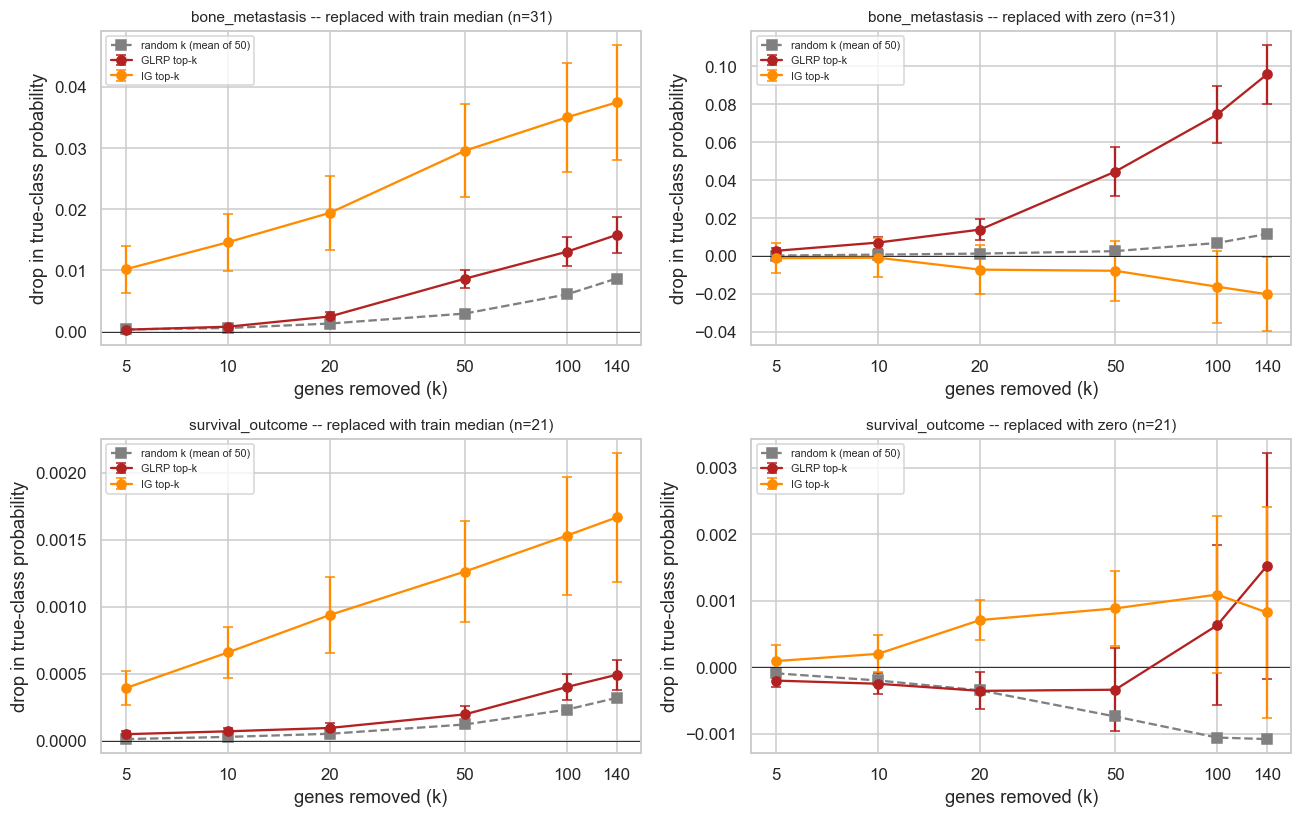

[bone_metastasis] GLRP: criteria met at 0 of 6 budgets [] -> no consistent evidence of attribution faithfulness in this limited test
[bone_metastasis] IG: criteria met at 4 of 6 budgets [5, 20, 50, 140] -> consistent with, but not proof of, attribution faithfulness
[survival_outcome] GLRP: criteria met at 0 of 6 budgets [] -> no consistent evidence of attribution faithfulness in this limited test
[survival_outcome] IG: criteria met at 6 of 6 budgets [5, 10, 20, 50, 100, 140] -> consistent with, but not proof of, attribution faithfulness


In [117]:
# ============================================================
# D (v14) -- Deletion (perturbation) test: GLRP vs IG, several budgets, shared random controls  [R8]
# ============================================================
# Same model (Section 13), same held-out samples, same random gene sets for both methods.
# This is a perturbation test of the MODEL, not evidence that the genes are causal drivers of disease.
# Caveat: IG's baseline (training mean) is close to the train_median replacement, which can favour IG
# under that replacement; the zero replacement is reported as a check.
from scipy.stats import binomtest, wilcoxon
assert "holm_adjust" in globals(), "Run 12P-5 first (defines holm_adjust)."
assert "integrated_gradients" in globals(), "Run the Item 9 (v14) cell first (defines integrated_gradients)."

DELETION_BUDGETS = [5, 10, 20, 50, 100, 140]
N_RANDOM_CONTROLS = 50
DELETION_BASELINES = ["train_median", "zero"]
PRIMARY_DELETION_BASELINE = "train_median"
DELETION_METHODS = ["GLRP", "IG"]
MAX_DELETION_SAMPLES = None
N_BOOT_DELETION = 2000

def _class_prob(model, X, cls):
    with torch.no_grad():
        return torch.softmax(model(L_hat, torch.tensor(X, dtype=torch.float32)), dim=1)[:, cls].numpy()

deletion_rows = []
for task_name, task in TASKS.items():
    model = final_models[task_name]; model.eval()
    sp_ = final_test_splits[task_name]
    Xte, yte, pte, te_preds = sp_["Xte"], sp_["yte"], sp_["pte"], sp_["te_preds"]
    idx_all = np.arange(len(task["y"]))
    tr0, _ = train_test_split(idx_all, test_size=0.2, stratify=task["y"], random_state=7)
    tr_, _ = train_test_split(tr0, test_size=0.15, stratify=task["y"][tr0], random_state=7)
    Xtrain_expl = EXPL_X[task_name][tr_]
    fill_values = {"zero": np.zeros(N, dtype=np.float32),
                   "train_median": np.median(Xtrain_expl, axis=0).astype(np.float32)}
    ig_base = Xtrain_expl.mean(axis=0).astype(np.float32)

    rng = np.random.default_rng(0)
    track = [i for i in range(len(yte)) if int(yte[i]) == int(te_preds[i])]
    if MAX_DELETION_SAMPLES:
        track = track[:MAX_DELETION_SAMPLES]
    print(f"[{task_name}] deletion test on {len(track)} correctly classified held-out samples")

    for i in track:
        cls = int(yte[i]); x = Xte[i].astype(np.float32)
        base_prob = float(_class_prob(model, x[None], cls)[0])
        orders = {}
        _, _, rel_g = glrp_explain(model, torch.tensor(x[None]).unsqueeze(-1), cls)
        orders["GLRP"] = np.argsort(-np.abs(rel_g))
        rel_i, _, _, _ = integrated_gradients(model, x, ig_base, cls)
        orders["IG"] = np.argsort(-np.abs(rel_i))
        for b in DELETION_BUDGETS:
            rand_sets = [rng.choice(N, size=b, replace=False) for _ in range(N_RANDOM_CONTROLS)]   # shared by methods
            for bl in DELETION_BASELINES:
                batch_r = np.repeat(x[None], N_RANDOM_CONTROLS, axis=0)
                for r_, gs in enumerate(rand_sets):
                    batch_r[r_, gs] = fill_values[bl][gs]
                rand_d = base_prob - _class_prob(model, batch_r, cls)
                for meth in DELETION_METHODS:
                    top, bottom = orders[meth][:b], orders[meth][-b:]
                    batch = np.repeat(x[None], 2, axis=0)
                    batch[0, top] = fill_values[bl][top]; batch[1, bottom] = fill_values[bl][bottom]
                    top_d, bottom_d = base_prob - _class_prob(model, batch, cls)
                    deletion_rows.append({
                        "task": task_name, "method": meth, "patient_id": pte[i], "true_class": cls, "budget": b,
                        "baseline": bl, "base_prob": base_prob, "top_k_drop": top_d, "bottom_k_drop": bottom_d,
                        "random_mean_drop": rand_d.mean(), "random_sd_drop": rand_d.std(ddof=1),
                        "top_minus_random": top_d - rand_d.mean(),
                        "top_percentile_among_random": float((rand_d < top_d).mean()),
                        "top_k_drop_exceeds_random_mean": bool(top_d > rand_d.mean()),
                    })

deletion_df = pd.DataFrame(deletion_rows)
deletion_df.to_csv(f"{OUT_DIR}/deletion_test_GLRP_vs_IG_multibudget.csv", index=False)

def _boot_mean_ci(v, n_boot=N_BOOT_DELETION, seed=0):
    v = np.asarray(v, float); rng = np.random.default_rng(seed)
    if len(v) < 2:
        return np.nan, np.nan
    bs = rng.choice(v, size=(n_boot, len(v)), replace=True).mean(axis=1)
    return tuple(np.percentile(bs, [2.5, 97.5]))

summ = []
for (t, meth, bl), g in deletion_df.groupby(["task", "method", "baseline"]):
    tmp = []
    for b, gb in g.groupby("budget"):
        n = len(gb); k_ = int(gb.top_k_drop_exceeds_random_mean.sum())
        d = gb.top_minus_random.to_numpy()
        try:
            w_p = wilcoxon(d, alternative="greater").pvalue if np.any(d != 0) else np.nan
        except ValueError:
            w_p = np.nan
        lo_, hi_ = _boot_mean_ci(d)
        flo_, fhi_ = _boot_mean_ci(gb.top_k_drop_exceeds_random_mean.astype(float).to_numpy())
        tmp.append({"task": t, "method": meth, "baseline": bl, "budget": b, "n_samples": n,
                    "mean_top_minus_random": d.mean(), "CI95_lower": lo_, "CI95_upper": hi_,
                    "fraction_top_exceeds_random": k_ / n if n else np.nan,
                    "fraction_CI95_lower": flo_, "fraction_CI95_upper": fhi_,
                    "sign_test_P": binomtest(k_, n, 0.5, alternative="greater").pvalue if n else np.nan,
                    "wilcoxon_P": w_p, "mean_top_drop": gb.top_k_drop.mean(),
                    "mean_random_drop": gb.random_mean_drop.mean(), "mean_bottom_drop": gb.bottom_k_drop.mean()})
    for r, pa in zip(tmp, holm_adjust([r["wilcoxon_P"] for r in tmp])):
        r["wilcoxon_P_Holm"] = pa
    summ += tmp
deletion_summary = pd.DataFrame(summ)
deletion_summary.to_csv(f"{OUT_DIR}/deletion_test_summary_by_method_budget.csv", index=False)
display(deletion_summary.round(4))

# head-to-head: which method's top-k removal moves the prediction more (same sample, budget, replacement)?
h2h = []
wide = deletion_df.pivot_table(index=["task", "patient_id", "budget", "baseline"], columns="method",
                               values="top_k_drop").reset_index()
for (t, bl, b), g in wide.groupby(["task", "baseline", "budget"]):
    dd = (g["GLRP"] - g["IG"]).to_numpy()
    try:
        p_ = wilcoxon(dd).pvalue if np.any(dd != 0) else np.nan
    except ValueError:
        p_ = np.nan
    h2h.append({"task": t, "baseline": bl, "budget": b, "mean_GLRP_minus_IG_top_drop": dd.mean(),
                "fraction_GLRP_larger": float((dd > 0).mean()), "wilcoxon_two_sided_P": p_})
deletion_h2h = pd.DataFrame(h2h)
deletion_h2h.to_csv(f"{OUT_DIR}/deletion_test_GLRP_vs_IG_head_to_head.csv", index=False)
display(deletion_h2h.round(4))

fig, axes = plt.subplots(len(TASKS), len(DELETION_BASELINES), figsize=(6 * len(DELETION_BASELINES),
                                                                       3.8 * len(TASKS)), squeeze=False)
for r_, task_name in enumerate(TASKS):
    for c_, bl in enumerate(DELETION_BASELINES):
        ax = axes[r_, c_]
        g = deletion_df[(deletion_df.task == task_name) & (deletion_df.baseline == bl)]
        for meth, colr in [("GLRP", "firebrick"), ("IG", "darkorange")]:
            gm = g[g.method == meth]
            m_ = gm.groupby("budget")["top_k_drop"].mean(); se = gm.groupby("budget")["top_k_drop"].sem()
            ax.errorbar(m_.index, m_.values, yerr=se.values, fmt="o-", color=colr, label=f"{meth} top-k", capsize=3)
        gr = g[g.method == "GLRP"]
        m_ = gr.groupby("budget")["random_mean_drop"].mean()
        ax.plot(m_.index, m_.values, "s--", color="grey", label=f"random k (mean of {N_RANDOM_CONTROLS})")
        ax.axhline(0, color="black", lw=0.5)
        ax.set_xscale("log"); ax.set_xticks(DELETION_BUDGETS); ax.set_xticklabels(DELETION_BUDGETS)
        ax.set_title(f"{task_name} -- replaced with {bl.replace('_', ' ')} (n={g.patient_id.nunique()})", fontsize=10)
        ax.set_xlabel("genes removed (k)"); ax.set_ylabel("drop in true-class probability"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/deletion_curves_GLRP_vs_IG.png", dpi=200, bbox_inches="tight"); plt.show()

DELETION_PASS = {}
for (t, meth), s in deletion_summary[deletion_summary.baseline == PRIMARY_DELETION_BASELINE].groupby(["task", "method"]):
    passing = s[(s.wilcoxon_P_Holm < 0.05) & (s.fraction_top_exceeds_random >= 0.75)
                & (s.mean_top_drop > s.mean_bottom_drop)]
    DELETION_PASS[(t, meth)] = (len(passing), len(s), passing.budget.tolist())
    print(f"[{t}] {meth}: criteria met at {len(passing)} of {len(s)} budgets {passing.budget.tolist()} -> "
          + ("consistent with, but not proof of, attribution faithfulness"
             if len(passing) >= int(np.ceil(len(s) / 2))
             else "no consistent evidence of attribution faithfulness in this limited test"))


In [118]:
# ============================================================
# Explanation summary (v14): GLRP vs IG, and stability / faithfulness / plausibility kept separate
# ============================================================
EXPLORATORY_AUC_CUTOFF = 0.65

cmp_rows = []
for task_name in TASKS:
    for meth in EXPLAIN_METHODS:
        st = seed_stability_df[(seed_stability_df.task_key == task_name) & (seed_stability_df.method == meth)]
        pw = (pathway_seed_stability_df[(pathway_seed_stability_df.task == task_name)
                                        & (pathway_seed_stability_df.method == meth)]
              if "pathway_seed_stability_df" in globals() and len(pathway_seed_stability_df) else pd.DataFrame())
        dl = deletion_summary[(deletion_summary.task == task_name) & (deletion_summary.method == meth)
                              & (deletion_summary.baseline == PRIMARY_DELETION_BASELINE)]
        n_pass, n_b, _ = DELETION_PASS.get((task_name, meth), (np.nan, np.nan, []))
        rt = explain_runtime[(explain_runtime.task == task_name) & (explain_runtime.method == meth)]["seconds"]
        cmp_rows.append({
            "task": task_name, "method": meth,
            "top-20 Jaccard across retrainings (median)": st["jaccard_top20"].median(),
            "top-140 Jaccard across retrainings (median)": st["jaccard_top140"].median(),
            "top-140 chance level": expected_random_jaccard(140, N),
            "pathway Jaccard, conditional (median)": pw["pathway_jaccard_conditional"].median() if len(pw) else np.nan,
            "pathway Jaccard, unconditional (median)": pw["pathway_jaccard_unconditional"].median() if len(pw) else np.nan,
            "deletion: budgets passing": f"{n_pass}/{n_b}",
            "deletion k=20: mean top-minus-random [95% CI]": (
                f"{dl[dl.budget == 20].mean_top_minus_random.iloc[0]:+.4f} "
                f"[{dl[dl.budget == 20].CI95_lower.iloc[0]:+.4f}, {dl[dl.budget == 20].CI95_upper.iloc[0]:+.4f}]"
                if (dl.budget == 20).any() else "n/a"),
            "runtime per sample, s (median)": rt.median(),
            "IG completeness error (median)": (ig_diag[ig_diag.task == task_name].ig_completeness_error.median()
                                               if meth == "IG" else np.nan),
        })
explanation_method_comparison = pd.DataFrame(cmp_rows)
explanation_method_comparison.to_csv(f"{OUT_DIR}/explanation_method_comparison_GLRP_vs_IG.csv", index=False)
display(explanation_method_comparison.set_index(["task", "method"]).T)

deg_genes_ = set(deg_sig["gene"]) if "deg_sig" in globals() else set()
frame_rows = []
for task_name in TASKS:
    pr = (primary_auc_ci[(primary_auc_ci.task == task_name) & (primary_auc_ci.model == "GCN_real_K7")].iloc[0]
          if "primary_auc_ci" in globals() else None)
    expl_auc = roc_auc_score(final_test_splits[task_name]["yte"], final_test_splits[task_name]["te_probs"])
    weak = (pr is None) or (pr.pooled_OOF_AUC_repeat_mean < EXPLORATORY_AUC_CUTOFF) or (pr.CI95_lower <= 0.5)
    for meth in EXPLAIN_METHODS:
        st = seed_stability_df[(seed_stability_df.task_key == task_name) & (seed_stability_df.method == meth)]
        gc = gene_consensus[(gene_consensus.task == task_name) & (gene_consensus.method == meth)]
        consensus = set(gc[gc.mean_selection_frequency >= 0.5].gene)
        n_pass, n_b, _ = DELETION_PASS.get((task_name, meth), (0, 0, []))
        frame_rows.append({
            "task": task_name, "method": meth,
            "model performance: primary pooled OOF AUC [95% CI]": (f"{pr.pooled_OOF_AUC_repeat_mean:.3f} "
                                                                    f"[{pr.CI95_lower:.3f}, {pr.CI95_upper:.3f}]"
                                                                    if pr is not None else "run reconciliation addendum"),
            "explanation model held-out AUC (single split)": round(expl_auc, 3),
            "STABILITY: top-140 Jaccard vs chance": f"{st.jaccard_top140.median():.2f} vs "
                                                    f"{expected_random_jaccard(140, N):.2f}",
            "FAITHFULNESS: deletion budgets passing": f"{n_pass}/{n_b}",
            "PLAUSIBILITY: hub genes in consensus top-140": f"{len(consensus & set(HUB_GENES))}/{len(HUB_GENES)}",
            "PLAUSIBILITY: consensus genes that are Paper 1 DEGs": (f"{len(consensus & deg_genes_)}/{len(consensus)}"
                                                                  if deg_genes_ else "deg_sig not available"),
            "status": "EXPLORATORY (weak model)" if weak else "primary",
        })
explanation_framework = pd.DataFrame(frame_rows)
explanation_framework.to_csv(f"{OUT_DIR}/explanation_stability_faithfulness_plausibility.csv", index=False)
display(explanation_framework)


task                                                      bone_metastasis  \
method                                                               GLRP   
top-20 Jaccard across retrainings (median)                       0.020023   
top-140 Jaccard across retrainings (median)                      0.144508   
top-140 chance level                                             0.104948   
pathway Jaccard, conditional (median)                            0.075626   
pathway Jaccard, unconditional (median)                          0.044166   
deletion: budgets passing                                             0/6   
deletion k=20: mean top-minus-random [95% CI]  +0.0012 [-0.0001, +0.0024]   
runtime per sample, s (median)                                   0.014345   
IG completeness error (median)                                        NaN   

task                                                                       \
method                                                                 IG   
top-20 Jaccard across retrainings (median)                       0.228441   
top-140 Jaccard across retrainings (median)                      0.338643   
top-140 chance level                                             0.104948   
pathway Jaccard, conditional (median)                            0.051852   
pathway Jaccard, unconditional (median)                               0.0   
deletion: budgets passing                                             4/6   
deletion k=20: mean top-minus-random [95% CI]  +0.0181 [+0.0073, +0.0306]   
runtime per sample, s (median)                                   0.093274   
IG completeness error (median)                                   0.000978   

task                                                     survival_outcome  \
method                                                               GLRP   
top-20 Jaccard across retrainings (median)                       0.034433   
top-140 Jaccard across retrainings (median)                       0.14876   
top-140 chance level                                             0.104948   
pathway Jaccard, conditional (median)                            0.102283   
pathway Jaccard, unconditional (median)                          0.076239   
deletion: budgets passing                                             0/6   
deletion k=20: mean top-minus-random [95% CI]  +0.0000 [-0.0000, +0.0001]   
runtime per sample, s (median)                                   0.014359   
IG completeness error (median)                                        NaN   

task                                                                       
method                                                                 IG  
top-20 Jaccard across retrainings (median)                       0.147646  
top-140 Jaccard across retrainings (median)                      0.295329  
top-140 chance level                                             0.104948  
pathway Jaccard, conditional (median)                                 0.0  
pathway Jaccard, unconditional (median)                               0.0  
deletion: budgets passing                                             6/6  
deletion k=20: mean top-minus-random [95% CI]  +0.0009 [+0.0004, +0.0014]  
runtime per sample, s (median)                                   0.093337  
IG completeness error (median)                                   0.001285

,task,method,model performance: primary pooled OOF AUC [95% CI],explanation model held-out AUC (single split),STABILITY: top-140 Jaccard vs chance,FAITHFULNESS: deletion budgets passing,PLAUSIBILITY: hub genes in consensus top-140,PLAUSIBILITY: consensus genes that are Paper 1 DEGs,status
0,bone_metastasis,GLRP,"0.779 [0.717, 0.835]",0.752,0.14 vs 0.10,0/6,0/5,2/22,primary
1,bone_metastasis,IG,"0.779 [0.717, 0.835]",0.752,0.34 vs 0.10,4/6,5/5,46/97,primary
2,survival_outcome,GLRP,"0.621 [0.559, 0.679]",0.630,0.15 vs 0.10,0/6,0/5,2/26,EXPLORATORY (weak model)
3,survival_outcome,IG,"0.621 [0.559, 0.679]",0.630,0.30 vs 0.10,6/6,1/5,17/57,EXPLORATORY (weak model)


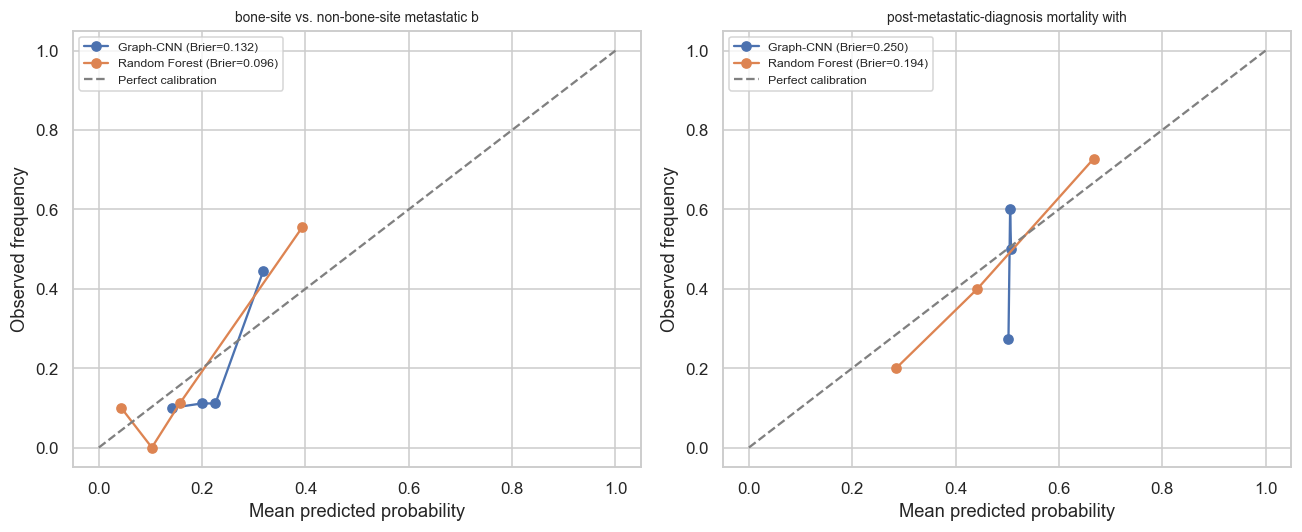

Lower Brier score = better calibrated. Small held-out test sets here mean these curves are noisy -- treat as descriptive, not a precise calibration claim.


,task,model,brier_score,n_bins
0,bone-site vs. non-bone-site metastatic biopsy ...,Graph-CNN,0.132041,4
1,bone-site vs. non-bone-site metastatic biopsy ...,Random Forest,0.095711,4
2,post-metastatic-diagnosis mortality within 36 ...,Graph-CNN,0.249632,3
3,post-metastatic-diagnosis mortality within 36 ...,Random Forest,0.193666,3


In [119]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, len(TASKS), figsize=(6 * len(TASKS), 5))
axes = np.atleast_1d(axes)
calibration_rows = []

for ax, (task_name, task) in zip(axes, TASKS.items()):
    X_task, y_task = EXPL_X[task_name], task["y"]   # [R3] fold-internal preprocessing (cell 13-0)
    patient_ids = (Xall.index.tolist() if task_name == "bone_metastasis" else Xall.index[task2_mask].tolist())
    Xtr0, Xte0, ytr0, yte0, ptr0, pte0 = train_test_split(
        X_task, y_task, patient_ids, test_size=0.2, stratify=y_task, random_state=7
    )
    split = final_test_splits[task_name]
    yte, gcn_probs = split["yte"], split["te_probs"]

    rf = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
    rf.fit(Xtr0, ytr0)
    rf_probs = rf.predict_proba(split["Xte"])[:, 1]

    for label, probs in [("Graph-CNN", gcn_probs), ("Random Forest", rf_probs)]:
        n_bins = min(5, max(2, len(yte) // 8))
        frac_pos, mean_pred = calibration_curve(yte, probs, n_bins=n_bins, strategy="quantile")
        brier = brier_score_loss(yte, probs)
        ax.plot(mean_pred, frac_pos, marker="o", label=f"{label} (Brier={brier:.3f})")
        calibration_rows.append({"task": task["label"], "model": label, "brier_score": brier, "n_bins": n_bins})

    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency")
    ax.set_title(task["label"][:40], fontsize=9); ax.legend(fontsize=8)

plt.tight_layout(); plt.savefig(f"{FIG_DIR}/calibration_curves.png", dpi=200, bbox_inches="tight"); plt.show()

calibration_df = pd.DataFrame(calibration_rows)
calibration_df.to_csv(f"{OUT_DIR}/calibration_brier_scores.csv", index=False)
print("Lower Brier score = better calibrated. Small held-out test sets here mean these curves are "
      "noisy -- treat as descriptive, not a precise calibration claim.")
display(calibration_df)


In [120]:
# [R1] Diagnostic kept as documentation: GSE175692 has no CBC field of any kind
print("All clinical columns in clin175:")
print(clin175.columns.tolist())

# Search for likely names (CBC could mean contralateral breast cancer or complete blood count)
keywords = ["cbc", "contralat", "blood", "wbc", "neutro", "lymph"]
cbc_hits = [c for c in clin175.columns if any(k in c.lower() for k in keywords)]
print("\nPossible CBC columns:", cbc_hits)

# Show how each candidate is coded (POS/NEG, Yes/No, numbers, missing)
for c in cbc_hits:
    print(f"\n--- {c} ---")
    print(clin175[c].value_counts(dropna=False).head(15))


All clinical columns in clin175:
['title', 'source_name', 'organ', 'Sex', 'pre-post menopausal', 'de novo metastasis vs relapsed', 'site of metastatic biopsy', 'metastatic spread', 'number of metastatic sites', 'neoadjuvant or adjuvant treatment?', 'number of lines of treatment?', 'endocrine therapy? yes vs not', 'cdk treatment? yes vs not', 'anti-her2 treatment? yes vs not?', 'chemotherapy? yes vs not', 'immunotherapy', 'everolimus', 'pi3k inhibitors', 'akt inhibitor', 'bevacizumab', 'parp inhibitors', 'hr', 'her2', 'her2 ihc', 'her2 ish', 'ihc group', 'ose', 'os (months) since dxmet', 'age (years)', 'characteristic']

Possible CBC columns: []


,step,n_samples,n_events
0,All GSE175692 samples,184,104
1,With survival time and status,180,104
2,With PROM1 and CCL2 expression,180,104
3,With known HR and HER2 status (final cohort),167,93


Final cohort: 167 samples, 93 events; events per parameter (M1) = 18.6

Complete hazard-ratio table (M1, M2, M3):


,model,covariate,coef,HR,HR_95CI_lower,HR_95CI_upper,SE,z,P
0,M1 standard Cox,PROM1,-0.0644,0.9376,0.8423,1.0437,0.0547,-1.1775,0.2390
1,M1 standard Cox,CCL2,0.0391,1.0399,0.8736,1.2378,0.0889,0.4399,0.6600
2,M1 standard Cox,bone_met,-0.2511,0.7779,0.3948,1.5329,0.3461,-0.7256,0.4681
3,M1 standard Cox,hr_pos,-1.3704,0.2540,0.1478,0.4365,0.2762,-4.9619,0.0000
4,M1 standard Cox,her2_pos,0.0818,1.0852,0.5829,2.0205,0.3171,0.2579,0.7965
5,M2 stratified by HR status,PROM1,-0.0589,0.9428,0.8466,1.0499,0.0549,-1.0736,0.2830
6,M2 stratified by HR status,CCL2,0.0363,1.0370,0.8746,1.2295,0.0869,0.4177,0.6762
7,M2 stratified by HR status,bone_met,-0.2042,0.8153,0.4127,1.6107,0.3474,-0.5879,0.5566
8,M2 stratified by HR status,her2_pos,0.1267,1.1351,0.6078,2.1201,0.3187,0.3976,0.6909
9,M3 stratified + CCL2 x log(time),PROM1,-0.0584,0.9432,0.8479,1.0493,0.0544,-1.0749,0.2824



M3: time-varying CCL2 hazard ratio per unit expression:


,months,CCL2_HR_per_unit
0,12,0.946
1,24,1.062
2,36,1.136



Schoenfeld-residual proportional-hazards tests (P < 0.05 = evidence of violation):


time_transform                            km    rank
model                      covariate                
M1 standard Cox            CCL2       0.1959  0.1845
                           PROM1      0.7914  0.6103
                           bone_met   0.3995  0.3044
                           her2_pos   0.8881  0.7619
                           hr_pos     0.0786  0.0339
M2 stratified by HR status CCL2       0.3180  0.1066
                           PROM1      0.7587  0.7108
                           bone_met   0.3957  0.2362
                           her2_pos   0.8509  0.0128

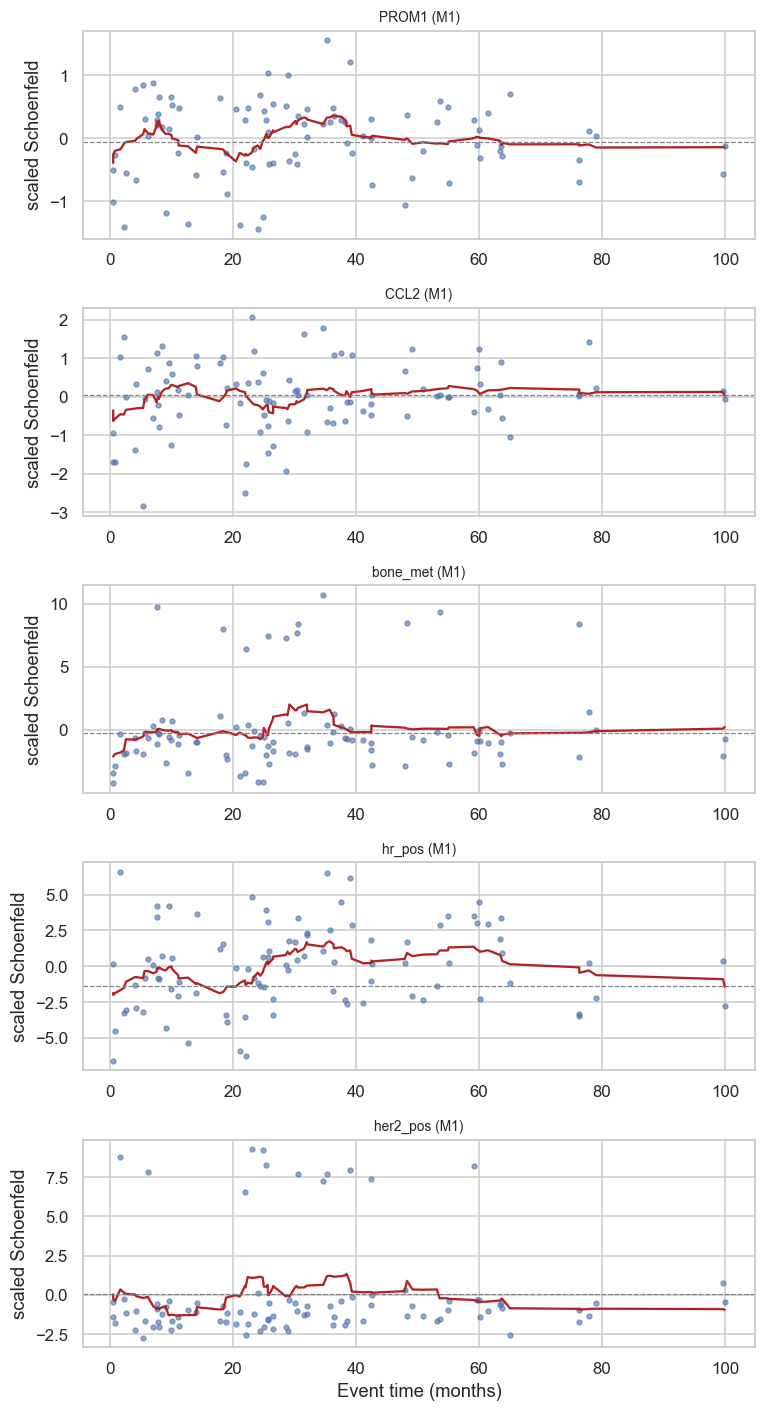


Interpretation:
  M2 (HR-stratified): no remaining PH violation outside CCL2 -> False
  M3: CCL2 x log(time) term P=0.0265 (CCL2 effect changes over time)
  PROM1 [M1]: HR 0.938 (95% CI 0.842-1.044), P=0.239 -> no statistically significant adjusted association
  PROM1 [M2]: HR 0.943 (95% CI 0.847-1.050), P=0.283 -> no statistically significant adjusted association
  CCL2 [M1]: HR 1.040 (95% CI 0.874-1.238), P=0.66 -> no statistically significant adjusted association
  CCL2 [M2]: HR 1.037 (95% CI 0.875-1.229), P=0.676 -> no statistically significant adjusted association

Report the multivariable Cox results as: EXPLORATORY (PH violations remain; interpret HRs as time-averaged).


In [121]:
# ============================================================
# G. Multivariable Cox -- corrected, with full tables, PH diagnostics and alternatives  [R1, R2, R8]
# ============================================================
from lifelines import CoxTimeVaryingFitter
from lifelines.statistics import proportional_hazard_test
from lifelines.utils import to_episodic_format

# ---- 1. Cohort build with explicit exclusion flow ----
clin_cox = clin175.copy()
for c in ["hr", "her2"]:
    clin_cox[c] = clin_cox[c].astype(str).str.strip().str.upper().replace({"NA": np.nan, "NAN": np.nan, "": np.nan})
cox_base = (surv175.join(expr175.loc[["PROM1", "CCL2"]].T).join(clin_cox[["organ", "hr", "her2"]]))
flow = [("All GSE175692 samples", len(cox_base), int(cox_base["event"].sum()))]
cox_base = cox_base.dropna(subset=["time_months", "event"])
flow.append(("With survival time and status", len(cox_base), int(cox_base["event"].sum())))
cox_base = cox_base.dropna(subset=["PROM1", "CCL2"])
flow.append(("With PROM1 and CCL2 expression", len(cox_base), int(cox_base["event"].sum())))
cox_base = cox_base.dropna(subset=["hr", "her2", "organ"])
flow.append(("With known HR and HER2 status (final cohort)", len(cox_base), int(cox_base["event"].sum())))
cox_flow = pd.DataFrame(flow, columns=["step", "n_samples", "n_events"])
display(cox_flow)

cox_base["bone_met"] = (cox_base["organ"] == "Bone").astype(int)
cox_base["hr_pos"] = (cox_base["hr"] == "POS").astype(int)
cox_base["her2_pos"] = (cox_base["her2"] == "POS").astype(int)
covars = ["PROM1", "CCL2", "bone_met", "hr_pos", "her2_pos"]
grouped = bool(globals().get("PATIENT_GROUPS_AVAILABLE", False)) and globals().get("PATIENT_ID_SERIES") is not None
if grouped:
    cox_base["patient_id"] = PATIENT_ID_SERIES.reindex(cox_base.index)
    print(f"Repeated samples: {cox_base['patient_id'].duplicated().sum()} samples share a patient -> "
          "cluster-robust SEs used in M1 and M2.")
n_ev = int(cox_base["event"].sum())
print(f"Final cohort: {len(cox_base)} samples, {n_ev} events; events per parameter (M1) = {n_ev / len(covars):.1f}")

def full_table(cph, model_label):
    s = cph.summary.copy()
    out = pd.DataFrame({"model": model_label, "covariate": s.index, "coef": s["coef"], "HR": s["exp(coef)"],
                        "HR_95CI_lower": s["exp(coef) lower 95%"], "HR_95CI_upper": s["exp(coef) upper 95%"],
                        "SE": s["se(coef)"], "z": s["z"], "P": s["p"]})
    return out.reset_index(drop=True)

fit_cols = ["time_months", "event"] + covars + (["patient_id"] if grouped else [])
kw = dict(duration_col="time_months", event_col="event")
if grouped:
    kw.update(cluster_col="patient_id", robust=True)

# ---- 2. M1: original specification, corrected coding ----
cph_m1 = CoxPHFitter().fit(cox_base[fit_cols], **kw)
tab_m1 = full_table(cph_m1, "M1 standard Cox")

# ---- 3. M2: stratified by HR status ----
cph_m2 = CoxPHFitter().fit(cox_base[fit_cols], strata=["hr_pos"], **kw)
tab_m2 = full_table(cph_m2, "M2 stratified by HR status")

# ---- 4. M3: M2 + CCL2 x log(time), time-varying coefficient ----
ep_cols = ["time_months", "event"] + covars
ep = to_episodic_format(cox_base[ep_cols].reset_index(drop=True), duration_col="time_months",
                        event_col="event", time_gaps=1.0)
ep["CCL2_x_logt"] = ep["CCL2"] * np.log(ep["stop"])
ctv = CoxTimeVaryingFitter()
ctv.fit(ep[["id", "start", "stop", "event", "PROM1", "CCL2", "CCL2_x_logt", "bone_met", "her2_pos", "hr_pos"]],
        id_col="id", start_col="start", stop_col="stop", event_col="event", strata=["hr_pos"])
tab_m3 = full_table(ctv, "M3 stratified + CCL2 x log(time)")
b0, b1 = ctv.params_["CCL2"], ctv.params_["CCL2_x_logt"]
ccl2_time_hr = pd.DataFrame({"months": [12, 24, 36],
                             "CCL2_HR_per_unit": [np.exp(b0 + b1 * np.log(t)) for t in [12, 24, 36]]})

cox_full = pd.concat([tab_m1, tab_m2, tab_m3], ignore_index=True)
cox_full.to_csv(f"{OUT_DIR}/multivariable_cox_full_table_M1_M2_M3.csv", index=False)
cox_flow.to_csv(f"{OUT_DIR}/multivariable_cox_cohort_flow.csv", index=False)
print("\nComplete hazard-ratio table (M1, M2, M3):")
display(cox_full.round(4))
print("\nM3: time-varying CCL2 hazard ratio per unit expression:")
display(ccl2_time_hr.round(3))

# ---- 5. Proportional-hazards diagnostics ----
# PH tests do not depend on the standard errors, so non-clustered refits are used here
data_ph = cox_base[["time_months", "event"] + covars]
cph_m1_ph = CoxPHFitter().fit(data_ph, duration_col="time_months", event_col="event")
cph_m2_ph = CoxPHFitter().fit(data_ph, duration_col="time_months", event_col="event", strata=["hr_pos"])
ph_rows = []
for label, cph in [("M1 standard Cox", cph_m1_ph), ("M2 stratified by HR status", cph_m2_ph)]:
    for transform in ["rank", "km"]:
        res = proportional_hazard_test(cph, data_ph, time_transform=transform)
        for cov, row in res.summary.iterrows():
            cov_name = cov if isinstance(cov, str) else cov[0]
            ph_rows.append({"model": label, "time_transform": transform, "covariate": cov_name,
                            "test_statistic": row["test_statistic"], "P": row["p"]})
ph_table = pd.DataFrame(ph_rows)
ph_table.to_csv(f"{OUT_DIR}/multivariable_cox_PH_tests.csv", index=False)
print("\nSchoenfeld-residual proportional-hazards tests (P < 0.05 = evidence of violation):")
display(ph_table.pivot_table(index=["model", "covariate"], columns="time_transform", values="P").round(4))

# Scaled Schoenfeld residual plots for M1 (visual diagnostic)
resid = cph_m1_ph.compute_residuals(data_ph, "scaled_schoenfeld")
event_times = cox_base.loc[resid.index, "time_months"]
fig, axes = plt.subplots(len(covars), 1, figsize=(7, 2.6 * len(covars)))
for ax, cov in zip(axes, covars):
    ax.scatter(event_times, resid[cov], s=10, alpha=0.6)
    order = np.argsort(event_times.values)
    smooth = pd.Series(resid[cov].values[order]).rolling(15, center=True, min_periods=5).mean()
    ax.plot(event_times.values[order], smooth, color="firebrick")
    ax.axhline(cph_m1_ph.params_[cov], color="grey", ls="--", lw=0.8)
    ax.set_title(f"{cov} (M1)", fontsize=9); ax.set_ylabel("scaled Schoenfeld")
axes[-1].set_xlabel("Event time (months)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/cox_M1_scaled_schoenfeld.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- 6. Data-driven wording ----
m2_ph_ok = (ph_table[(ph_table.model == "M2 stratified by HR status") & (ph_table.covariate != "CCL2")]["P"] >= 0.05).all()
m3_ccl2_term_p = tab_m3.set_index("covariate").loc["CCL2_x_logt", "P"]
print("\nInterpretation:")
print(f"  M2 (HR-stratified): no remaining PH violation outside CCL2 -> {m2_ph_ok}")
print(f"  M3: CCL2 x log(time) term P={m3_ccl2_term_p:.3g} "
      f"({'CCL2 effect changes over time' if m3_ccl2_term_p < 0.05 else 'no significant evidence the CCL2 effect changes over time'})")
for gene in ["PROM1", "CCL2"]:
    for label, tab in [("M1", tab_m1), ("M2", tab_m2)]:
        r = tab.set_index("covariate").loc[gene]
        verdict = ("statistically significant adjusted association" if r.P < 0.05
                   else "no statistically significant adjusted association")
        print(f"  {gene} [{label}]: HR {r.HR:.3f} (95% CI {r.HR_95CI_lower:.3f}-{r.HR_95CI_upper:.3f}), P={r.P:.3g} -> {verdict}")
status = "adjusted analysis (M2/M3)" if m2_ph_ok else "EXPLORATORY (PH violations remain; interpret HRs as time-averaged)"
print(f"\nReport the multivariable Cox results as: {status}.")


In [122]:
# ============================================================
# H1. One sample-flow table for every survival analysis, plus data checks  [R1, R8]   (v13)
# ============================================================
# Sections 7, 11 (Task 2), G and 8 each built their own survival cohort. This cell puts them side by
# side, lists every excluded GSE175692 sample with its reason, and runs the checks a reviewer would:
# event coding, negative times, likely time unit, repeated patients, and whether the 36-month case/
# control definition is identical in Section 7 (fixed-horizon ROC) and Section 11 (Task 2 label).
def _cohort_row(analysis, df, endpoint, note=""):
    t, e = df["time_months"], df["event"]
    return {"analysis": analysis, "endpoint": endpoint, "n_samples": len(df), "n_events": int(e.sum()),
            "event_values": ",".join(map(str, sorted(pd.unique(e.dropna())))),
            "time_min": t.min(), "time_median": t.median(), "time_max": t.max(),
            "n_negative_or_zero_time": int((t <= 0).sum()), "note": note}

def _unit_flag(tmax):
    if tmax > 360:
        return "max > 360: values look like DAYS, not months -- check before pooling/plotting"
    if tmax < 30:
        return "max < 30: values may be YEARS, not months -- check"
    return "plausible for months"

# ---- Task 2 cohort in survival form ----
t2 = surv175.reindex(TASK_SAMPLE_IDS["survival_outcome"])
cohorts = [
    _cohort_row("GSE175692 all samples with any survival field", surv175.dropna(how="all"), "OS from met. dx"),
    _cohort_row("Sec. 7 univariate Cox / PROM1+CCL2 risk score (surv_df)", surv_df, "OS from met. dx",
                "complete time, event and all hub genes"),
    _cohort_row("Sec. 11 Task 2 label (Graph-CNN)", t2, "death <=36 mo vs alive >36 mo",
                "early-censored (<=36 mo, no event) excluded"),
    _cohort_row("Sec. G multivariable Cox (cox_base)", cox_base, "OS from met. dx",
                "also requires known HR and HER2"),
]
if "df124" in globals():
    cohorts.append(_cohort_row("Sec. 8 GSE124647 (df124)", df124, "OS (column 'oas months')"))
if "df11121" in globals():
    cohorts.append(_cohort_row("Sec. 8 GSE11121 (df11121)", df11121, "DMFS (column 't.dmfs')",
                               "different endpoint from GSE175692"))
survival_cohorts = pd.DataFrame(cohorts)
survival_cohorts["time_unit_check"] = survival_cohorts["time_max"].apply(_unit_flag)
survival_cohorts.to_csv(f"{OUT_DIR}/survival_cohort_flow_all_sections.csv", index=False)
display(survival_cohorts.round(2))

# ---- per-sample exclusion reasons (GSE175692) ----
all_ids = clin175.index
ex = pd.DataFrame(index=all_ids)
ex["has_time_and_event"] = surv175.reindex(all_ids)[["time_months", "event"]].notna().all(axis=1)
ex["has_all_hub_gene_expression"] = expr175.reindex(columns=all_ids).loc[HUB_GENES].T.notna().all(axis=1)
ex["has_PROM1_CCL2"] = expr175.reindex(columns=all_ids).loc[["PROM1", "CCL2"]].T.notna().all(axis=1)
_hr = clin175["hr"].astype(str).str.strip().str.upper().replace({"NA": np.nan, "NAN": np.nan, "": np.nan})
_her2 = clin175["her2"].astype(str).str.strip().str.upper().replace({"NA": np.nan, "NAN": np.nan, "": np.nan})
ex["has_HR_HER2"] = _hr.notna() & _her2.notna()
ex["in_model_panel_Xall"] = ex.index.isin(Xall.index)
ex["in_sec7"] = ex.index.isin(surv_df.index)
ex["in_task2"] = ex.index.isin(TASK_SAMPLE_IDS["survival_outcome"])
ex["in_secG"] = ex.index.isin(cox_base.index)
def _reasons(r):
    out = []
    if not r.has_time_and_event: out.append("missing survival time/status")
    if not r.has_all_hub_gene_expression: out.append("missing hub-gene expression")
    if not r.has_HR_HER2: out.append("HR or HER2 unknown ('NA')")
    if r.has_time_and_event and not r.in_task2 and r.in_model_panel_Xall:
        out.append("censored at or before 36 months (Task 2 status unknown)")
    if not r.in_model_panel_Xall: out.append("not in Graph-CNN modeling matrix")
    return "; ".join(out)
ex["exclusion_reasons"] = ex.apply(_reasons, axis=1)
if bool(globals().get("PATIENT_GROUPS_AVAILABLE", False)) and globals().get("PATIENT_ID_SERIES") is not None:
    ex["patient_id"] = PATIENT_ID_SERIES.reindex(ex.index)
ex.to_csv(f"{OUT_DIR}/survival_sample_exclusions_GSE175692.csv")
excluded_any = ex[~(ex.in_sec7 & ex.in_task2 & ex.in_secG)]
print(f"\n{len(excluded_any)} of {len(ex)} GSE175692 samples are missing from at least one survival analysis:")
display(excluded_any[["in_sec7", "in_task2", "in_secG", "exclusion_reasons"]])

# ---- checks ----
checks = []
for lab, df_ in [("Sec. 7", surv_df), ("Task 2", t2), ("Sec. G", cox_base)] + \
               ([("GSE124647", df124)] if "df124" in globals() else []) + \
               ([("GSE11121", df11121)] if "df11121" in globals() else []):
    ev = set(pd.unique(df_["event"].dropna()))
    checks.append((lab, "event coded only as 0/1", ev <= {0, 1}, str(sorted(float(x) for x in ev))))
    checks.append((lab, "no negative or zero survival times", bool((df_["time_months"] > 0).all()),
                   f"{int((df_['time_months'] <= 0).sum())} non-positive"))

# Section 7 (fixed-horizon ROC) vs Section 11 (Task 2): same 36-month case/control definition?
h = surv175.reindex(TASK_SAMPLE_IDS["survival_outcome"]).dropna()
sec7_case = (h["event"] == 1) & (h["time_months"] <= 36)
sec7_ctrl = h["time_months"] > 36
task2_y = pd.Series(TASKS["survival_outcome"]["y"], index=TASK_SAMPLE_IDS["survival_outcome"]).reindex(h.index)
agree = bool(((sec7_case & (task2_y == 1)) | (sec7_ctrl & (task2_y == 0))).all())
checks.append(("Sec. 7 vs Task 2", "36-month case/control definitions identical", agree,
               f"{int(sec7_case.sum())} cases / {int(sec7_ctrl.sum())} controls"))

if "patient_id" in ex.columns:
    dup = ex.loc[ex.in_sec7, "patient_id"].dropna().duplicated().sum()
    checks.append(("Sec. 7", "no patient contributes more than one sample", dup == 0,
                   f"{int(dup)} repeated-patient samples; Sec. 7 Cox treats them as independent"
                   + ("" if dup == 0 else " -- use cluster-robust SEs as in Sec. G")))
else:
    checks.append(("Sec. 7 / G", "patient identity available", False,
                   "not recoverable (see [R2]); 184 samples from 176 patients analysed as independent -- state as a limitation"))
checks.append(("Sec. 7 vs Sec. G", "same cohort", len(surv_df) == len(cox_base),
               f"Sec. 7 n={len(surv_df)} vs Sec. G n={len(cox_base)}; difference = samples with unknown HR/HER2. "
               "Report both n's and say why they differ."))
survival_checks = pd.DataFrame(checks, columns=["scope", "check", "passed", "detail"])
survival_checks.to_csv(f"{OUT_DIR}/survival_data_checks.csv", index=False)
display(survival_checks)


,analysis,endpoint,n_samples,n_events,event_values,time_min,time_median,time_max,n_negative_or_zero_time,note,time_unit_check
0,GSE175692 all samples with any survival field,OS from met. dx,180,104,"0.0,1.0",0.53,32.06,318.35,0,,plausible for months
1,Sec. 7 univariate Cox / PROM1+CCL2 risk score ...,OS from met. dx,180,104,"0.0,1.0",0.53,32.06,318.35,0,"complete time, event and all hub genes",plausible for months
2,Sec. 11 Task 2 label (Graph-CNN),death <=36 mo vs alive >36 mo,152,104,"0.0,1.0",0.53,38.50,318.35,0,"early-censored (<=36 mo, no event) excluded",plausible for months
3,Sec. G multivariable Cox (cox_base),OS from met. dx,167,93,"0.0,1.0",0.53,34.68,318.35,0,also requires known HR and HER2,plausible for months
4,Sec. 8 GSE124647 (df124),OS (column 'oas months'),140,97,"0,1",0.16,24.04,126.06,0,,plausible for months
5,Sec. 8 GSE11121 (df11121),DMFS (column 't.dmfs'),200,46,"0,1",1.00,90.50,240.00,0,different endpoint from GSE175692,plausible for months



44 of 184 GSE175692 samples are missing from at least one survival analysis:


,in_sec7,in_task2,in_secG,exclusion_reasons
GSM5344040,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344042,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344046,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344052,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344054,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344058,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344074,False,False,False,missing survival time/status
GSM5344078,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344080,True,False,True,censored at or before 36 months (Task 2 status...
GSM5344083,True,False,True,censored at or before 36 months (Task 2 status...


,scope,check,passed,detail
0,Sec. 7,event coded only as 0/1,True,"[0.0, 1.0]"
1,Sec. 7,no negative or zero survival times,True,0 non-positive
2,Task 2,event coded only as 0/1,True,"[0.0, 1.0]"
3,Task 2,no negative or zero survival times,True,0 non-positive
4,Sec. G,event coded only as 0/1,True,"[0.0, 1.0]"
5,Sec. G,no negative or zero survival times,True,0 non-positive
6,GSE124647,event coded only as 0/1,True,"[0.0, 1.0]"
7,GSE124647,no negative or zero survival times,True,0 non-positive
8,GSE11121,event coded only as 0/1,True,"[0.0, 1.0]"
9,GSE11121,no negative or zero survival times,True,0 non-positive


In [123]:
# ============================================================
# H2. PROM1 + CCL2 risk score: apparent vs cross-validated performance  [R8]   (v13)
# ============================================================
# Section 7 fits the Cox coefficients on all samples, splits at the all-sample median, and evaluates
# on the same samples. Those are APPARENT (in-sample) numbers and are optimistic. Here the whole
# recipe (standardize -> fit Cox -> score -> median split at the TRAINING median) is repeated inside
# each fold, and only held-out scores are evaluated. Report the cross-validated values; the apparent
# values may be given alongside, labelled as apparent.
from lifelines.utils import concordance_index
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

RS_GENES = ["PROM1", "CCL2"]
N_RS_REPEATS = 20
N_RS_FOLDS = 5
RS_HORIZON = 36

rs_data = surv_df[["time_months", "event"] + RS_GENES].dropna().copy()
rs_groups = None
if bool(globals().get("PATIENT_GROUPS_AVAILABLE", False)) and globals().get("PATIENT_ID_SERIES") is not None:
    rs_groups = PATIENT_ID_SERIES.reindex(rs_data.index).fillna(pd.Series(rs_data.index, index=rs_data.index)).to_numpy()

def _fit_rs(train):
    mu, sd = train[RS_GENES].mean(), train[RS_GENES].std(ddof=0)
    z = (train[RS_GENES] - mu) / sd
    cph_ = CoxPHFitter().fit(pd.concat([train[["time_months", "event"]], z], axis=1),
                             duration_col="time_months", event_col="event")
    return mu, sd, cph_.params_[RS_GENES]

def _score(df, mu, sd, beta):
    return ((df[RS_GENES] - mu) / sd) @ beta

def _rs_metrics(df, lp, cut):
    d = df.assign(risk_score=lp)
    hi_, lo_ = d[d.risk_score > cut], d[d.risk_score <= cut]
    lr = logrank_test(hi_.time_months, lo_.time_months, hi_.event, lo_.event).p_value if len(hi_) and len(lo_) else np.nan
    roc = fixed_horizon_roc(d, RS_HORIZON)
    hr = CoxPHFitter().fit(d[["time_months", "event"]].assign(rs_z=(lp - lp.mean()) / lp.std()),
                           duration_col="time_months", event_col="event").summary.loc["rs_z"]
    return {"C_index": concordance_index(d.time_months, -lp, d.event), "logrank_P_median_split": lr,
            f"AUC_{RS_HORIZON}mo": roc[3] if roc is not None else np.nan,
            "HR_per_SD": hr["exp(coef)"], "HR_per_SD_P": hr["p"]}

# ---- apparent (Section 7 recipe, on z-scored genes; C-index is scale-invariant) ----
mu_all, sd_all, beta_all = _fit_rs(rs_data)
lp_all = _score(rs_data, mu_all, sd_all, beta_all)
apparent = _rs_metrics(rs_data, lp_all, lp_all.median())
print(f"Frozen GSE175692 model (z-scored genes): " + ", ".join(f"{g} beta={beta_all[g]:+.3f}" for g in RS_GENES))

# ---- cross-validated ----
cv_rows = []
for rep in range(N_RS_REPEATS):
    if rs_groups is not None and pd.Series(rs_groups).duplicated().any():
        spl = StratifiedGroupKFold(n_splits=N_RS_FOLDS, shuffle=True, random_state=rep)
        splits = spl.split(rs_data, rs_data.event.astype(int), groups=rs_groups)
    else:
        spl = StratifiedKFold(n_splits=N_RS_FOLDS, shuffle=True, random_state=rep)
        splits = spl.split(rs_data, rs_data.event.astype(int))
    oof_lp = pd.Series(np.nan, index=rs_data.index)
    oof_high = pd.Series(False, index=rs_data.index)
    fold_c = []
    for tr_i, te_i in splits:
        tr_d, te_d = rs_data.iloc[tr_i], rs_data.iloc[te_i]
        mu, sd, beta = _fit_rs(tr_d)
        lp_te = _score(te_d, mu, sd, beta)
        cut = _score(tr_d, mu, sd, beta).median()          # cut-point from training samples only
        oof_lp.loc[te_d.index] = lp_te
        oof_high.loc[te_d.index] = lp_te > cut
        fold_c.append(concordance_index(te_d.time_months, -lp_te, te_d.event))
    d = rs_data.assign(risk_score=oof_lp)
    hi_, lo_ = d[oof_high], d[~oof_high]
    roc = fixed_horizon_roc(d, RS_HORIZON)
    cv_rows.append({"repeat": rep, "fold_mean_C_index": np.mean(fold_c),
                    "pooled_C_index": concordance_index(d.time_months, -d.risk_score, d.event),
                    "logrank_P_median_split": logrank_test(hi_.time_months, lo_.time_months, hi_.event, lo_.event).p_value,
                    f"AUC_{RS_HORIZON}mo": roc[3] if roc is not None else np.nan})
rs_cv = pd.DataFrame(cv_rows)
rs_cv.to_csv(f"{OUT_DIR}/risk_score_cross_validated_per_repeat.csv", index=False)

rs_compare = pd.DataFrame([
    {"metric": "C-index", "apparent (Sec. 7)": apparent["C_index"],
     "cross-validated median": rs_cv.pooled_C_index.median(),
     "CV range": f"{rs_cv.pooled_C_index.min():.3f}-{rs_cv.pooled_C_index.max():.3f}",
     "optimism": apparent["C_index"] - rs_cv.pooled_C_index.median()},
    {"metric": f"{RS_HORIZON}-month AUC", "apparent (Sec. 7)": apparent[f"AUC_{RS_HORIZON}mo"],
     "cross-validated median": rs_cv[f"AUC_{RS_HORIZON}mo"].median(),
     "CV range": f"{rs_cv[f'AUC_{RS_HORIZON}mo'].min():.3f}-{rs_cv[f'AUC_{RS_HORIZON}mo'].max():.3f}",
     "optimism": apparent[f"AUC_{RS_HORIZON}mo"] - rs_cv[f"AUC_{RS_HORIZON}mo"].median()},
    {"metric": "median-split log-rank P", "apparent (Sec. 7)": apparent["logrank_P_median_split"],
     "cross-validated median": rs_cv.logrank_P_median_split.median(),
     "CV range": f"{rs_cv.logrank_P_median_split.min():.3g}-{rs_cv.logrank_P_median_split.max():.3g}",
     "optimism": np.nan},
])
rs_compare.to_csv(f"{OUT_DIR}/risk_score_apparent_vs_cross_validated.csv", index=False)
print(f"\nRisk score, n={len(rs_data)} samples, {int(rs_data.event.sum())} events; "
      f"{N_RS_REPEATS} x {N_RS_FOLDS}-fold CV"
      + (" (patient-grouped)" if rs_groups is not None else " (sample-level)") + ":")
display(rs_compare.round(4))

# ============================================================
# H3. Frozen risk score in the external cohorts + validation wording
# ============================================================
# The platforms differ (NanoString vs Affymetrix), so raw coefficients cannot be transferred.
# Each external cohort's genes are z-scored WITHIN that cohort and the frozen GSE175692 betas
# (estimated on z-scored genes above) are applied unchanged. No refitting, no cut-point search:
# the high/low split uses the cohort's own median, fixed in advance.
#
# EXTERNAL_COHORT_INFO: set "same_population" only after checking the GEO record and Paper 1.
# Section 2's table states that GSE124647's population differs from GSE175692 and that GSE11121 uses
# DMFS, a different endpoint. The defaults below follow that.
EXTERNAL_COHORT_INFO = {
    "GSE124647": {"endpoint": "OS", "same_endpoint_as_discovery": True, "same_population": False},
    "GSE11121": {"endpoint": "DMFS", "same_endpoint_as_discovery": False, "same_population": False},
}

def _boot_cindex(df, lp, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(df), len(df))
        if df.event.iloc[i].sum() > 0:
            vals.append(concordance_index(df.time_months.iloc[i], -lp.iloc[i], df.event.iloc[i]))
    return np.percentile(vals, [2.5, 97.5])

ext_rows = []
ext_sources = {}
if "gse124_genes" in globals() and "surv124" in globals():
    ext_sources["GSE124647"] = surv124.join(gse124_genes.reindex(columns=RS_GENES)).dropna()
if "gse11121_genes" in globals() and "surv11121" in globals():
    ext_sources["GSE11121"] = surv11121.join(gse11121_genes.reindex(columns=RS_GENES)).dropna()

for cohort, dfe in ext_sources.items():
    if len(dfe) < 20 or dfe.event.sum() < 5:
        print(f"{cohort}: too few complete samples/events for the frozen score (n={len(dfe)})."); continue
    lp_e = ((dfe[RS_GENES] - dfe[RS_GENES].mean()) / dfe[RS_GENES].std(ddof=0)) @ beta_all
    m_e = _rs_metrics(dfe, lp_e, lp_e.median())
    lo_c, hi_c = _boot_cindex(dfe, lp_e)
    info = EXTERNAL_COHORT_INFO.get(cohort, {})
    ext_rows.append({"cohort": cohort, "endpoint": info.get("endpoint"), "n": len(dfe), "events": int(dfe.event.sum()),
                     "C_index": m_e["C_index"], "C_index_CI95": f"{lo_c:.3f}-{hi_c:.3f}",
                     "HR_per_SD": m_e["HR_per_SD"], "HR_per_SD_P": m_e["HR_per_SD_P"],
                     "logrank_P_median_split": m_e["logrank_P_median_split"],
                     "C_CI_excludes_0.5": lo_c > 0.5, **info})
risk_score_external = pd.DataFrame(ext_rows)
risk_score_external.to_csv(f"{OUT_DIR}/risk_score_frozen_external_cohorts.csv", index=False)
print("\nFrozen PROM1+CCL2 risk score applied to external cohorts (no refitting):")
display(risk_score_external.round(4))

print("\nWording rules (generated):")
cv_c = rs_cv.pooled_C_index.median()
print(f"  [GSE175692] Report the cross-validated C-index ({cv_c:.3f}) as the risk score's discrimination; the "
      f"apparent value ({apparent['C_index']:.3f}) and the all-sample median-split Kaplan-Meier plot in Section 7 "
      f"are in-sample and should be labelled 'apparent'.")
for _, r in risk_score_external.iterrows():
    sig = (r.HR_per_SD_P < 0.05) and (r.HR_per_SD > 1) and r["C_CI_excludes_0.5"]
    if sig and r.same_endpoint_as_discovery and r.same_population:
        txt = "may be described as 'independent validation' of the risk score."
    elif sig and r.same_endpoint_as_discovery:
        txt = ("may be described as 'the frozen risk score was also prognostic in an independent cohort'; call it "
               "external validation only after confirming the population matches.")
    elif sig:
        txt = (f"supporting evidence on a different endpoint ({r.endpoint}); not a validation of the "
               "overall-survival risk score.")
    elif r.HR_per_SD > 1:
        txt = "directionally consistent but not statistically significant: 'not validated in this cohort'."
    else:
        txt = "not replicated (opposite direction or null): 'not validated in this cohort'."
    print(f"  [{r.cohort}] HR per SD {r.HR_per_SD:.2f} (P={r.HR_per_SD_P:.3g}), C-index {r.C_index:.3f} "
          f"(95% CI {r.C_index_CI95}) -> {txt}")
print("  Section 8 single-gene Cox/KM results test whether each gene's association REPLICATES; describe them "
      "that way ('replicated' / 'not replicated'), not as validation of the risk score.")


Frozen GSE175692 model (z-scored genes): PROM1 beta=+0.201, CCL2 beta=+0.189



Risk score, n=180 samples, 104 events; 20 x 5-fold CV (sample-level):


,metric,apparent (Sec. 7),cross-validated median,CV range,optimism
0,C-index,0.5929,0.5780,0.531-0.592,0.015
1,36-month AUC,0.5797,0.5616,0.501-0.582,0.018
2,median-split log-rank P,0.0051,0.0178,0.000968-0.0889,NaN



Frozen PROM1+CCL2 risk score applied to external cohorts (no refitting):


,cohort,endpoint,n,events,C_index,C_index_CI95,HR_per_SD,HR_per_SD_P,logrank_P_median_split,C_CI_excludes_0.5,same_endpoint_as_discovery,same_population
0,GSE124647,OS,140,97,0.5609,0.498-0.635,1.3521,0.0065,0.0618,False,True,False
1,GSE11121,DMFS,200,46,0.5805,0.480-0.679,1.4401,0.0025,0.4244,False,False,False



Wording rules (generated):
  [GSE175692] Report the cross-validated C-index (0.578) as the risk score's discrimination; the apparent value (0.593) and the all-sample median-split Kaplan-Meier plot in Section 7 are in-sample and should be labelled 'apparent'.
  [GSE124647] HR per SD 1.35 (P=0.00651), C-index 0.561 (95% CI 0.498-0.635) -> directionally consistent but not statistically significant: 'not validated in this cohort'.
  [GSE11121] HR per SD 1.44 (P=0.00248), C-index 0.580 (95% CI 0.480-0.679) -> directionally consistent but not statistically significant: 'not validated in this cohort'.
  Section 8 single-gene Cox/KM results test whether each gene's association REPLICATES; describe them that way ('replicated' / 'not replicated'), not as validation of the risk score.


In [124]:
# ============================================================
# FIGURE 11 AUDIT — EXACT VALUES USED IN THE BOXPLOT
# ============================================================

print("=" * 80)
print("FIGURE 11 — GLRP HETEROGENEITY AUDIT")
print("=" * 80)

for task_name in TASKS:

    label = TASKS[task_name]["label"]

    class1_patients = all_patient_results[task_name][1]
    class0_patients = all_patient_results[task_name][0]

    genesets1 = [
        topk_geneset(p["relevance"], 140)
        for p in class1_patients
    ]

    genesets0 = [
        topk_geneset(p["relevance"], 140)
        for p in class0_patients
    ]

    within = (
        pairwise_jaccard(class1_patients, 140)
        + pairwise_jaccard(class0_patients, 140)
    )

    between = [
        jaccard(g1, g0)
        for g1 in genesets1
        for g0 in genesets0
    ]

    print("\nTASK:", label)
    print("-" * 80)

    print("Class 1 samples:", len(class1_patients))
    print("Class 0 samples:", len(class0_patients))

    print("\nWITHIN-CLASS")
    print("Number of comparisons:", len(within))
    print("Mean Jaccard:", np.mean(within))
    print("Median Jaccard:", np.median(within))
    print("SD:", np.std(within))

    print("\nBETWEEN-CLASS")
    print("Number of comparisons:", len(between))
    print("Mean Jaccard:", np.mean(between))
    print("Median Jaccard:", np.median(between))
    print("SD:", np.std(between))

    print("\nDifference (within - between):",
          np.mean(within) - np.mean(between))

print("\n" + "=" * 80)

# Random-set expectation for two top-140 sets from 737 genes
N = 737
k = 140

expected_intersection = k * k / N
expected_jaccard = expected_intersection / (2*k - expected_intersection)

print("RANDOM-SET REFERENCE")
print("Expected intersection:", expected_intersection)
print("Approximate expected Jaccard:", expected_jaccard)
print("=" * 80)

FIGURE 11 — GLRP HETEROGENEITY AUDIT

TASK: bone-site vs. non-bone-site metastatic biopsy classification (Paper 1's task)
--------------------------------------------------------------------------------
Class 1 samples: 4
Class 0 samples: 27

WITHIN-CLASS
Number of comparisons: 357
Mean Jaccard: 0.18424182493751529
Median Jaccard: 0.18143459915611815
SD: 0.05437187756540713

BETWEEN-CLASS
Number of comparisons: 108
Mean Jaccard: 0.1965407429151806
Median Jaccard: 0.2017167381974249
SD: 0.050422889832860925

Difference (within - between): -0.012298917977665302

TASK: post-metastatic-diagnosis mortality within 36 months vs. alive >=36 months
--------------------------------------------------------------------------------
Class 1 samples: 11
Class 0 samples: 10

WITHIN-CLASS
Number of comparisons: 100
Mean Jaccard: 0.14176545587202988
Median Jaccard: 0.13360323886639677
SD: 0.04630826269945559

BETWEEN-CLASS
Number of comparisons: 110
Mean Jaccard: 0.12601022826948183
Median Jaccard: 0.12

In [125]:
# ============================================================
# FIGURE 12 AUDIT — EXACT SETS AND OVERLAPS
# ============================================================

print("=" * 90)
print("FIGURE 12 — EXACT GENE-SET OVERLAP AUDIT")
print("=" * 90)

deg_set = set(deg_sig["gene"])

bone_glrp_set = (
    set(glrp_results["bone_metastasis"][1][2])
    | set(glrp_results["bone_metastasis"][0][2])
)

survival_glrp_set = (
    set(glrp_results["survival_outcome"][1][2])
    | set(glrp_results["survival_outcome"][0][2])
)

universe = set(gene_list)

# Restrict everything to the common 737-gene universe
deg_u = deg_set & universe
bone_u = bone_glrp_set & universe
survival_u = survival_glrp_set & universe

print("\nSET SIZES")
print("-" * 90)
print("Gene universe:", len(universe))
print("DEGs total:", len(deg_set))
print("DEGs in 737-gene universe:", len(deg_u))
print("Bone GLRP union:", len(bone_u))
print("Survival GLRP union:", len(survival_u))

# ------------------------------------------------------------
# Pairwise intersections
# ------------------------------------------------------------

deg_bone = deg_u & bone_u
deg_survival = deg_u & survival_u
bone_survival = bone_u & survival_u
all_three = deg_u & bone_u & survival_u

print("\nPAIRWISE INTERSECTIONS")
print("-" * 90)

print(
    f"DEG ∩ Bone GLRP = {len(deg_bone)}\n"
    f"{sorted(deg_bone)}"
)

print(
    f"\nDEG ∩ Survival GLRP = {len(deg_survival)}\n"
    f"{sorted(deg_survival)}"
)

print(
    f"\nBone GLRP ∩ Survival GLRP = {len(bone_survival)}\n"
    f"{sorted(bone_survival)}"
)

print(
    f"\nALL THREE = {len(all_three)}\n"
    f"{sorted(all_three)}"
)

# ------------------------------------------------------------
# EXACT VENN REGIONS
# ------------------------------------------------------------

deg_only = deg_u - bone_u - survival_u
bone_only = bone_u - deg_u - survival_u
survival_only = survival_u - deg_u - bone_u

deg_bone_only = (deg_u & bone_u) - survival_u
deg_survival_only = (deg_u & survival_u) - bone_u
bone_survival_only = (bone_u & survival_u) - deg_u

print("\nEXACT VENN REGIONS")
print("-" * 90)

print("DEG only:", len(deg_only))
print("Bone GLRP only:", len(bone_only))
print("Survival GLRP only:", len(survival_only))

print("DEG + Bone only:", len(deg_bone_only))
print("DEG + Survival only:", len(deg_survival_only))
print("Bone + Survival only:", len(bone_survival_only))

print("All three:", len(all_three))

# Check totals reconstruct correctly
print("\nVENN RECONSTRUCTION CHECK")
print("-" * 90)

print(
    "DEG reconstructed:",
    len(deg_only)
    + len(deg_bone_only)
    + len(deg_survival_only)
    + len(all_three),
    "expected:",
    len(deg_u)
)

print(
    "Bone reconstructed:",
    len(bone_only)
    + len(deg_bone_only)
    + len(bone_survival_only)
    + len(all_three),
    "expected:",
    len(bone_u)
)

print(
    "Survival reconstructed:",
    len(survival_only)
    + len(deg_survival_only)
    + len(bone_survival_only)
    + len(all_three),
    "expected:",
    len(survival_u)
)

# ------------------------------------------------------------
# EXPECTED PAIRWISE OVERLAPS UNDER RANDOM SAMPLING
# ------------------------------------------------------------

N = len(universe)

expected_deg_bone = len(deg_u) * len(bone_u) / N
expected_deg_survival = len(deg_u) * len(survival_u) / N
expected_bone_survival = len(bone_u) * len(survival_u) / N

print("\nEXPECTED RANDOM PAIRWISE OVERLAPS")
print("-" * 90)

print("Expected DEG ∩ Bone GLRP:", expected_deg_bone)
print("Observed DEG ∩ Bone GLRP:", len(deg_bone))

print("Expected DEG ∩ Survival GLRP:", expected_deg_survival)
print("Observed DEG ∩ Survival GLRP:", len(deg_survival))

print("Expected Bone GLRP ∩ Survival GLRP:", expected_bone_survival)
print("Observed Bone GLRP ∩ Survival GLRP:", len(bone_survival))

# ------------------------------------------------------------
# HYPERGEOMETRIC TESTS
# ------------------------------------------------------------

from scipy.stats import hypergeom

def overlap_test(a, b, universe):
    a = a & universe
    b = b & universe

    k = len(a & b)
    N = len(universe)
    K = len(a)
    n = len(b)

    p = hypergeom.sf(k - 1, N, K, n)

    return {
        "observed": k,
        "expected": K * n / N,
        "p": p
    }

tests = {
    "DEG vs Bone GLRP":
        overlap_test(deg_u, bone_u, universe),

    "DEG vs Survival GLRP":
        overlap_test(deg_u, survival_u, universe),

    "Bone GLRP vs Survival GLRP":
        overlap_test(bone_u, survival_u, universe)
}

print("\nHYPERGEOMETRIC OVERLAP TESTS")
print("-" * 90)

for name, result in tests.items():
    print(name)
    print("  Observed:", result["observed"])
    print("  Expected:", result["expected"])
    print("  P-value:", result["p"])

# ------------------------------------------------------------
# HUB / CANDIDATE GENES
# ------------------------------------------------------------

print("\nCANDIDATE GENES")
print("-" * 90)

hub_rows = []

for gene in HUB_GENES:
    hub_rows.append({
        "gene": gene,
        "DEG": gene in deg_u,
        "Bone_GLRP": gene in bone_u,
        "Survival_GLRP": gene in survival_u,
        "All_three":
            gene in deg_u
            and gene in bone_u
            and gene in survival_u
    })

hub_audit = pd.DataFrame(hub_rows)

display(hub_audit)

print("\n" + "=" * 90)
print("FIGURE 12 AUDIT COMPLETE")
print("=" * 90)

FIGURE 12 — EXACT GENE-SET OVERLAP AUDIT

SET SIZES
------------------------------------------------------------------------------------------
Gene universe: 737
DEGs total: 68
DEGs in 737-gene universe: 66
Bone GLRP union: 251
Survival GLRP union: 244

PAIRWISE INTERSECTIONS
------------------------------------------------------------------------------------------
DEG ∩ Bone GLRP = 24
['AGR2', 'BCAS1', 'BMP2', 'CCL21', 'CDH3', 'CHAD', 'COL11A1', 'COMP', 'CXCL9', 'DPT', 'ENPP2', 'EYA1', 'EYA2', 'EYA4', 'FGFR3', 'FLNC', 'FOXA1', 'FZD8', 'GREM1', 'ITGB3', 'OLFML2B', 'SPP1', 'TIMP4', 'WIF1']

DEG ∩ Survival GLRP = 24
['AGR2', 'ALDH1A1', 'BMP2', 'CCL2', 'CD36', 'CEACAM6', 'CKB', 'COLEC12', 'CXCL10', 'CXCL9', 'ESR1', 'FGFR3', 'FOXC2', 'GREM1', 'HBB', 'IBSP', 'ITGB3', 'LEPR', 'LIFR', 'LPL', 'MARCO', 'MMP9', 'RORB', 'WNT2']

Bone GLRP ∩ Survival GLRP = 75
['ACVR1B', 'AGR2', 'BMP2', 'BMPR1A', 'BMPR1B', 'CACNA1D', 'CCNA1', 'CEP55', 'CHI3L1', 'CXCL9', 'CYBB', 'DCN', 'DUSP4', 'DUSP6', 'EDN1', 'EI

,gene,DEG,Bone_GLRP,Survival_GLRP,All_three
0,MMP9,True,False,True,False
1,ITGB3,True,True,True,True
2,BMP2,True,True,True,True
3,CCL2,True,False,True,False
4,PROM1,True,False,False,False



FIGURE 12 AUDIT COMPLETE
